[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/raya-lucaria/ia_o26/blob/main/course/10_deep_learning/_assets/02_entender_una_red.ipynb)

# Notebook 2 · Entender una red entrenándola

Unidad 10 de *deep learning* (aprendizaje profundo), clase 2. En el
notebook 01, «Una red desde cero», construiste una red 2–3–2–1 a mano en
NumPy. Aquí vas a entrenar una red con PyTorch para reconocer dígitos
escritos a mano del conjunto MNIST.

**Cómo ejecutarlo.** Abre el notebook en Colab. Elige **Entorno de ejecución
→ Cambiar tipo de entorno → T4 GPU → Guardar**. Luego selecciona **Entorno
de ejecución → Ejecutar todo**. En una T4, la ejecución completa está
estimada en unos 20 minutos. Puedes leer de arriba hacia abajo mientras
corre. Si Colab arranca sin GPU, verás un aviso y se activará el modo
`RAPIDO`. Sus gráficas salen de una prueba con menos datos y menos pasos.

- Separa los datos y lee el código que vas a usar para entrenar.
- Pasa de la regresión logística a una red con capas ocultas. Compara
  escalas de entrada y aprende a leer las tres curvas.
- Prueba cómo cambia el *gradient descent* (descenso de gradiente) con el
  tamaño del *batch* (lote), el *learning rate* (tasa de aprendizaje) y el
  *optimizer* (optimizador). Usa *early stopping* (parada temprana) para
  detener el entrenamiento cuando deja de mejorar en validación.
- Cambia el tamaño, la forma y las activaciones de la red. Mira el gradiente
  en cada capa y prueba *batch normalization* (normalización por lote) y
  *dropout* (desactivación aleatoria de unidades).
- Examina los errores y prueba una red convolucional. Después, mira cómo
  *softmax* (normalización exponencial) convierte las salidas en
  probabilidades y cómo se calcula la *loss* (pérdida). La tabla maestra
  reúne las corridas al final.

Como en la unidad 9, ajusta los parámetros con *train* (entrenamiento) y
toma las decisiones con *validation* (validación). En un proyecto, usa
*test* (prueba) una sola vez, al final. Aquí verás su curva en cada *epoch*
(época, una pasada por los datos de entrenamiento) solo para practicar la
lectura de las tres curvas.

Busca «Qué viste» para comprobar cómo leer las salidas. En las secciones
con una apuesta, escribe tu predicción antes de correr la celda. Luego
abre la respuesta plegada y compárala con lo que observaste.

## 01 · Arranque

Aquí preparamos las bibliotecas, el dispositivo, las semillas y las gráficas.
El entrenamiento empieza más adelante.

- PyTorch, que importamos como `torch`, trabaja con tensores (arreglos de
  números). Calcula el gradiente de la loss respecto a los parámetros.
  Hace automáticamente la *backpropagation* (retropropagación) que
  programaste a mano en el notebook 01.
- Torchvision proporciona MNIST.
- Como en la unidad 9, usamos NumPy para operaciones con arreglos, pandas
  para tablas y Matplotlib para gráficas.

In [ ]:
# Todo lo que usa el notebook, importado una sola vez aquí.
import os
import time
import math
import hashlib
import subprocess
from dataclasses import dataclass, field
from typing import Callable

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision

print("torch", torch.__version__, "· torchvision", torchvision.__version__)

Entrenar una red implica multiplicar matrices una y otra vez. Una GPU
(unidad de procesamiento gráfico) puede hacer muchas de esas operaciones
en paralelo. `DEVICE` indica dónde se guardan y se operan los tensores.
`cuda` indica una GPU de NVIDIA y `cpu`, el procesador de propósito general.

**Si aparece «ESTE ENTORNO NO TIENE GPU»**, en Colab elige **Entorno de
ejecución → Cambiar tipo de entorno → T4 GPU → Guardar** y vuelve a
seleccionar **Ejecutar todo**. Sin GPU, el notebook sigue en CPU con
`RAPIDO`. Ese modo recorta los datos y limita el entrenamiento, así que
sus curvas pueden verse distintas de las de clase. Para hacer la misma
prueba local, puedes fijar la variable de entorno `RAPIDO=1`. El modo
rápido usa CPU aunque detecte una GPU.

Si está disponible, `nvidia-smi` muestra el modelo de GPU y su memoria.
La salida también identifica qué versión de PyTorch se está usando, con
qué versión de CUDA se compiló y qué versión de cuDNN detecta si hay GPU.
Guarda esa información si necesitas reproducir una corrida o reportar
un problema.

In [ ]:
# ¿Hay GPU? En Colab: Entorno de ejecución → Cambiar tipo de entorno → T4.
HAY_GPU = torch.cuda.is_available()

# RAPIDO recorta datos y epochs para una prueba en CPU que tarda segundos.
# Se activa solo si no hay GPU, o a mano con la variable de entorno RAPIDO=1.
RAPIDO = os.environ.get("RAPIDO") == "1" or not HAY_GPU

# Con RAPIDO trabajamos en CPU aunque haya GPU (la prueba local corre en CPU).
DEVICE = torch.device("cuda" if HAY_GPU and not RAPIDO else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, os.cpu_count() or 1))

if not HAY_GPU:
    print("=" * 72)
    print("  ¡AVISO! ESTE ENTORNO NO TIENE GPU.")
    print("  El notebook sigue en modo RAPIDO: pocos datos y pocas epochs,")
    print("  así que las gráficas NO se parecerán a las de la clase.")
    print("  Para corregirlo en Colab:")
    print("    Entorno de ejecución → Cambiar tipo de entorno → T4 GPU")
    print("    → Guardar, y luego Entorno de ejecución → Ejecutar todo.")
    print("=" * 72)

# nvidia-smi describe la GPU; si no existe el comando, no pasa nada.
try:
    salida = subprocess.run(["nvidia-smi"], capture_output=True, text=True,
                            timeout=20)
    print(salida.stdout if salida.returncode == 0 else "nvidia-smi no respondió")
except (FileNotFoundError, subprocess.TimeoutExpired):
    print("nvidia-smi no está disponible (no hay GPU de NVIDIA).")

print("DEVICE =", DEVICE, "· RAPIDO =", RAPIDO)
print("CUDA (con la que se compiló torch):", torch.version.cuda)
print("cuDNN:", torch.backends.cudnn.version() if HAY_GPU else "—")
if HAY_GPU:
    print("GPU:", torch.cuda.get_device_name(0))

Una semilla fija el punto de partida del azar, como en la unidad 9. La
caja separa dos decisiones. `semilla_init` fija los pesos iniciales y
`semilla_orden` fija el orden de los batches. Así puedes conservar los
mismos pesos de partida y cambiar el orden de los datos. Algunas operaciones
en GPU pueden variar un poco entre ejecuciones aunque fijes las semillas.
Al comparar corridas, fíjate en las tendencias de las curvas.

Las gráficas usan fondo claro y rejilla suave, como en el notebook 01.
`COLORES` asigna azul a train, naranja a validation y verde a test.

In [ ]:
# Semillas: misma semilla ⇒ mismos pesos iniciales y mismo orden de batches.
SEMILLA = 0
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)  # también siembra la GPU

# Estilo de las gráficas: fondo claro y rejilla suave, como en el notebook 01.
plt.style.use("default")
plt.rcParams.update({
    "axes.grid": True,
    "grid.alpha": 0.3,
    "figure.dpi": 100,
    "savefig.dpi": 100,
    "figure.figsize": (7, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Un color fijo por conjunto, en todo el notebook.
COLORES = {"train": "#1f77b4", "validation": "#ff7f0e", "test": "#2ca02c"}
print("Colores:", COLORES)

## 02 · Los datos

MNIST reúne 70 000 imágenes de dígitos escritos a mano. Cada imagen tiene
$28 \times 28$ píxeles en escala de grises, con intensidades de 0 a 255.
Su etiqueta es un entero del 0 al 9. Torchvision descarga los archivos si
hace falta y reutiliza la copia local en las siguientes ejecuciones.

MNIST trae 60 000 imágenes de train y 10 000 de test. Creamos validation
con las últimas 10 000 imágenes del train original, siguiendo la
partición del libro de Nielsen. Quedan 50 000 para train, 10 000 para
validation y 10 000 para test. Usamos este split train/validation/test
ya establecido tal cual: por la rapidez de la clase no validamos si es el
mejor. Es una regla reproducible, no una conclusión. `ORIGEN` guarda los índices de cada
conjunto dentro de su archivo.

Recuerda el reparto de tareas de la unidad 9. Train ajusta los pesos y
sesgos. Validation sirve para elegir el modelo, la epoch o los
hiperparámetros, como el learning rate. Test se reserva para reportar
el desempeño del modelo elegido.

In [ ]:
# torchvision baja MNIST una vez; si ya está en la carpeta, no vuelve a bajarlo.
MNIST_DIR = os.environ.get("MNIST_DIR", "./datos_mnist")
mnist_train = torchvision.datasets.MNIST(MNIST_DIR, train=True, download=True)
mnist_test = torchvision.datasets.MNIST(MNIST_DIR, train=False, download=True)

# .data son las imágenes como enteros 0–255 [n, 28, 28]; .targets, los dígitos.
imagenes_60k, etiquetas_60k = mnist_train.data, mnist_train.targets
imagenes_test, etiquetas_test = mnist_test.data, mnist_test.targets

# El split: los primeros 50 000 de train son train; los últimos 10 000,
# validation. Guardamos los ÍNDICES de origen para poder verificar el split.
ORIGEN = {
    "train": torch.arange(0, 50_000),
    "validation": torch.arange(50_000, 60_000),
    "test": torch.arange(0, 10_000),  # índices dentro del archivo de test
}
CRUDOS = {
    "train": (imagenes_60k[ORIGEN["train"]], etiquetas_60k[ORIGEN["train"]]),
    "validation": (imagenes_60k[ORIGEN["validation"]],
                   etiquetas_60k[ORIGEN["validation"]]),
    "test": (imagenes_test, etiquetas_test),
}
for nombre, (imgs, etqs) in CRUDOS.items():
    print(f"{nombre:>10}: imágenes {tuple(imgs.shape)} {imgs.dtype}, "
          f"etiquetas {tuple(etqs.shape)} {etqs.dtype}")

Los `assert` son comprobaciones que detienen la celda si fallan. Aquí
verifican los tres tamaños y que train y validation tengan índices
disjuntos dentro del archivo que comparten.

Dos imágenes de índices distintos pueden tener los mismos píxeles.
Por eso también se calcula un *hash* (huella digital) de cada imagen.
La celda cuenta repeticiones dentro de cada conjunto y huellas comunes
entre cada par. Si aparecen coincidencias, se reportan y se conserva la
partición original para los ejercicios.

En la tabla y en la gráfica, compara las tres barras de un mismo dígito.
Si tienen alturas parecidas, ese dígito ocupa una proporción similar en
los tres conjuntos. La línea punteada marca el 10 % que tendría cada
clase en un reparto parejo. Adivinar uniformemente entre las diez clases
da un 10 % de *accuracy* (proporción de aciertos) en promedio. Con clases
casi parejas, predecir siempre el mismo dígito también queda cerca de
esa referencia.

In [ ]:
# 1) Tamaños exactos.
assert len(CRUDOS["train"][0]) == 50_000
assert len(CRUDOS["validation"][0]) == 10_000
assert len(CRUDOS["test"][0]) == 10_000
# 2) Train y validation salen del mismo archivo: sus índices de origen
#    no pueden compartir ni uno.
comunes = set(ORIGEN["train"].tolist()) & set(ORIGEN["validation"].tolist())
assert len(comunes) == 0, "train y validation comparten índices"
print("✓ tamaños 50 000 / 10 000 / 10 000 y train ∩ validation = ∅ por índice")


# 3) Imágenes con píxeles idénticos (por hash). Se REPORTAN, no fallan:
#    MNIST trae unas pocas repetidas y no las vamos a limpiar aquí.
def huellas(imgs):
    """Un hash MD5 por imagen, de sus 784 bytes."""
    return [hashlib.md5(img.numpy().tobytes()).hexdigest() for img in imgs]


HUELLAS = {nombre: huellas(imgs) for nombre, (imgs, _) in CRUDOS.items()}
for nombre, hs in HUELLAS.items():
    repetidas = len(hs) - len(set(hs))
    print(f"dentro de {nombre:>10}: {repetidas} imágenes repetidas")
pares = [("train", "validation"), ("train", "test"), ("validation", "test")]
for a, b in pares:
    cruce = set(HUELLAS[a]) & set(HUELLAS[b])
    print(f"idénticas entre {a} y {b}: {len(cruce)}")

In [ ]:
# 4) Proporción de cada dígito en los tres conjuntos: tabla y barras agrupadas.
POR_DIGITO = pd.DataFrame({
    nombre: pd.Series(etqs.numpy()).value_counts(normalize=True).sort_index()
    for nombre, (_, etqs) in CRUDOS.items()
})
POR_DIGITO.index.name = "dígito"
print((100 * POR_DIGITO).round(2).astype(str) + " %")

fig, ax = plt.subplots(figsize=(9, 3.5))
ancho = 0.27
for j, nombre in enumerate(POR_DIGITO.columns):
    ax.bar(POR_DIGITO.index + (j - 1) * ancho, 100 * POR_DIGITO[nombre],
           width=ancho, color=COLORES[nombre], label=nombre)
ax.axhline(10, color="gray", ls="--", lw=1, label="10 % (reparto parejo)")
ax.set_xticks(range(10))
ax.set_xlabel("dígito")
ax.set_ylabel("% del conjunto")
ax.set_title("Proporción de cada dígito en train, validation y test")
ax.legend(ncol=4, fontsize=8, loc="lower center")
plt.show()

Mira las dos primeras imágenes de train de cada dígito. Compara sus
trazos aunque tengan la misma etiqueta. Cada imagen es una cuadrícula de
$28 \times 28$. El *multilayer perceptron* (perceptrón multicapa, MLP)
recibe sus $784$ intensidades en una fila. La posición de cada píxel en
la fila se conserva. En la sección 17, la red convolucional usa la
cuadrícula para procesar píxeles vecinos juntos.

In [ ]:
# Las dos primeras imágenes de cada dígito en train, con su etiqueta.
imgs, etqs = CRUDOS["train"]
fig, ejes = plt.subplots(2, 10, figsize=(10, 2.4))
for d in range(10):
    cuales = torch.nonzero(etqs == d).flatten()[:2]
    for fila, i in enumerate(cuales.tolist()):
        ejes[fila, d].imshow(imgs[i], cmap="gray_r")
        ejes[fila, d].set_title(f"y = {d}", fontsize=8)
for ax in ejes.flat:
    ax.axis("off")
fig.suptitle("Muestra de train: 28 × 28 píxeles, de 0 (blanco) a 255 (negro)")
plt.show()
print("Una imagen es una matriz 28 × 28; la red la ve aplanada como 784 números:",
      tuple(imgs[0].flatten().shape))

`DATOS[escala][conjunto]` guarda el par `(X, y)` en tres escalas.

- `"crudo"` conserva las intensidades de 0 a 255.
- `"01"` divide cada intensidad entre 255.
- `"estandar"` parte de `"01"`, resta `MEDIA` y divide entre `DESV`.

Se calcula una sola media y una sola desviación estándar con todos los
píxeles de train en `"01"`. Esas dos cifras se aplican también a validation
y test, como en la unidad 9. En la sección 5 compararás las tres escalas.

`X` tiene forma `[n, 784]`, con una imagen por **fila**. `y` tiene forma
`[n]` y guarda un entero `int64` por imagen. Los conjuntos caben en la
memoria de una T4. Con `.to(DEVICE)` preparamos los tensores una sola vez
en el dispositivo elegido. Cuando usamos la GPU, los batches se toman
por índice allí mismo y se evita copiar uno desde la CPU en cada paso.

`RAPIDO` toma una muestra con cantidades parecidas de cada dígito en los
tres conjuntos. La celda imprime los tamaños reducidos. `IMAGENES_TEST`
conserva las imágenes en la CPU como cuadrículas en $[0,1]$ para las
galerías de errores de más adelante.

In [ ]:
def estratos(etiquetas, n, semilla=SEMILLA):
    """n índices que alternan los dígitos 0, 1, …, 9, 0, 1, … (≈ n/10 de cada
    uno), en un orden barajado con semilla fija: siempre los mismos."""
    g = torch.Generator().manual_seed(semilla)
    llave = torch.empty(len(etiquetas), dtype=torch.int64)
    for d in range(10):
        de_d = torch.nonzero(etiquetas == d).flatten()
        rango = torch.randperm(len(de_d), generator=g)
        llave[de_d[rango]] = torch.arange(len(de_d)) * 10 + d
    return torch.sort(torch.argsort(llave)[:n]).values


# Con RAPIDO nos quedamos con un pedazo estratificado: 3000 / 1000 / 1000.
if RAPIDO:
    tope = {"train": 3000, "validation": 1000, "test": 1000}
    CRUDOS = {k: (im[estratos(et, tope[k])], et[estratos(et, tope[k])])
              for k, (im, et) in CRUDOS.items()}
    print("RAPIDO: conjuntos recortados a", tope)

# Media y desviación estándar de los píxeles en [0, 1], calculadas SOLO en train.
x01_train = CRUDOS["train"][0].flatten(1).float() / 255
MEDIA, DESV = x01_train.mean().item(), x01_train.std().item()
print(f"MEDIA = {MEDIA:.4f}, DESV = {DESV:.4f} (de train)")

# DATOS[escala][conjunto] = (X [n, 784] float32, y [n] int64), ya en DEVICE.
DATOS = {"crudo": {}, "01": {}, "estandar": {}}
for nombre, (imgs, etqs) in CRUDOS.items():
    crudo = imgs.flatten(1).float()          # aplanar: [n, 28, 28] → [n, 784]
    y = etqs.long().to(DEVICE)
    DATOS["crudo"][nombre] = (crudo.to(DEVICE), y)
    DATOS["01"][nombre] = ((crudo / 255).to(DEVICE), y)
    DATOS["estandar"][nombre] = (((crudo / 255 - MEDIA) / DESV).to(DEVICE), y)

# Las imágenes de test en [0, 1], en CPU, alineadas con DATOS[...]["test"].
IMAGENES_TEST = CRUDOS["test"][0].float() / 255
for nombre in ("train", "validation", "test"):
    X, y = DATOS["estandar"][nombre]
    print(f"{nombre:>10}: X {tuple(X.shape)} en {X.device}, y {tuple(y.shape)}")
if DEVICE.type == "cuda":
    print(f"memoria de GPU ocupada: {torch.cuda.memory_allocated() / 2**20:.0f} MB")

Algunas corridas usan un subconjunto de train para ahorrar tiempo.
`subconjunto(n)` devuelve índices estratificados, con cerca de $n/10$
ejemplos por dígito. Para los mismos datos, el mismo tamaño y la misma
semilla, devuelve los mismos índices. Fíjate en el conteo por dígito que
imprime la celda.

El subconjunto de una corrida afecta solo a train. Validation y test se
evalúan completos en el modo normal. En `RAPIDO` se evalúa todo lo que
quedó en cada conjunto tras el recorte.

In [ ]:
def subconjunto(n, semilla=0):
    """Índices fijos de un subconjunto estratificado de DATOS[...]["train"]:
    ≈ n/10 por dígito, siempre los mismos para la misma semilla."""
    return estratos(DATOS["01"]["train"][1].cpu(), n, semilla)


idx = subconjunto(1000)
cuenta = torch.bincount(DATOS["01"]["train"][1].cpu()[idx], minlength=10)
print("subconjunto(1000), ejemplos por dígito:", cuenta.tolist())
assert torch.equal(idx, subconjunto(1000)), "el subconjunto no es determinista"

**Qué viste.** Los `assert` comprobaron los tamaños y la separación por
índice. Las huellas de los píxeles permitieron contar imágenes idénticas.
Las barras muestran qué tan parecida es la mezcla de dígitos en los
tres conjuntos. Los tensores ya están en `DEVICE`. Puedes elegir
cualquiera de las tres escalas al entrenar.

## 03 · La caja de herramientas

Vamos a seguir un dígito desde los píxeles hasta la predicción. Luego
haremos un paso de entrenamiento como en el notebook 01. Las funciones
de esta sección quedan a la vista para que puedas seguir qué se calcula
en cada experimento.

`construir_red(capas, ...)` encadena las capas con `nn.Sequential`.
La lista empieza con $784$ entradas y acaba con $10$ salidas, una por
dígito. Los números intermedios indican cuántas neuronas hay en cada capa
oculta. Con `[784, 10]` obtienes la versión multiclase de la regresión
logística de la unidad 9.

Cada capa oculta empieza con `nn.Linear`, que multiplica por los pesos
y suma los sesgos. Luego viene la activación $g^{(l)}$, por ejemplo
*ReLU* (unidad lineal rectificada), que aplica $\max(0,z)$ a cada
componente. Si se activan las opciones de la sección 15, el orden es
`nn.Linear`, batch normalization (ajustar la escala de las señales con
estadísticas del lote), activación y dropout (poner a cero al azar
algunas activaciones durante el entrenamiento). La última capa es
`nn.Linear` y entrega directamente los *logits* (puntajes antes de
convertirlos en probabilidades).

Con `init="defecto"` se usan los pesos y sesgos iniciales de PyTorch.
`"he"` parte de pesos con varianza $2/d_{l-1}$, como en el notebook 01.
Aquí $d_{l-1}$ es el ancho de la capa anterior. `"ortogonal"` usa una
inicialización ortogonal. En estas dos últimas opciones los sesgos
arrancan en cero.

In [ ]:
# El nombre de cada activación → la capa de PyTorch que la aplica.
ACTIVACIONES = {"relu": nn.ReLU, "sigmoide": nn.Sigmoid, "tanh": nn.Tanh,
                "gelu": nn.GELU, "identidad": nn.Identity}


def construir_red(capas, activacion="relu", batch_norm=False, dropout=0.0,
                  init="defecto"):
    """capas = [784, d_1, …, 10] → nn.Sequential.
    Cada capa oculta: Linear → (BatchNorm) → activación g → (Dropout).
    La última Linear entrega los 10 logits, SIN activación: la softmax va
    dentro de la loss (nn.CrossEntropyLoss). [784, 10] es la regresión
    logística multiclase de la unidad 9."""
    piezas = []
    for l in range(1, len(capas)):
        piezas.append(nn.Linear(capas[l - 1], capas[l]))  # W^(l): [d_l, d_{l-1}]
        if l < len(capas) - 1:                             # solo capas ocultas
            if batch_norm:
                piezas.append(nn.BatchNorm1d(capas[l]))
            piezas.append(ACTIVACIONES[activacion]())
            if dropout > 0:
                piezas.append(nn.Dropout(dropout))
    red = nn.Sequential(*piezas)
    for capa in red:
        if isinstance(capa, nn.Linear) and init != "defecto":
            if init == "he":          # normal con varianza 2 / d_{l-1}, como el 01
                nn.init.kaiming_normal_(capa.weight, nonlinearity="relu")
            elif init == "ortogonal":  # filas ortonormales: W W^T = I
                nn.init.orthogonal_(capa.weight)
            else:
                raise ValueError(f"init desconocida: {init}")
            nn.init.zeros_(capa.bias)
    return red


print(construir_red([784, 128, 10]))

Sigue la primera fila de `xb` en las formas que imprime la celda. La red
procesa varios dígitos juntos. En `[B, 784]`, $B$ es el tamaño del batch
y cada fila contiene los píxeles de un dígito.

En el notebook 01 cada observación ocupaba una **columna**, y la primera
capa calculaba $\mathbf z^{(1)} = \mathbf W^{(1)}\mathbf x + \mathbf b^{(1)}$.
En PyTorch cada observación ocupa una **fila**. Se conservan los ejes de
$\mathbf W^{(1)}$, con filas para las neuronas de destino y columnas para las
entradas de origen. En esta red, eso da `[128, 784]`. La transpuesta
permite escribir `xb @ W.T + b`, que produce `[B, 128]`. El `assert`
comprueba que da lo mismo que llamar a la primera capa de PyTorch.

1. La red devuelve `[B, 10]`. Cada fila contiene un logit por dígito.
   La posición de cada logit corresponde a una clase del 0 al 9.
2. La etiqueta $y_k$ es un entero que indica la posición correcta para
   la observación $k$. `nn.CrossEntropyLoss` recibe los logits y esas
   etiquetas. La *cross-entropy* (entropía cruzada) equivale a aplicar
   softmax y promediar $-\log \widehat p_{k,y_k}$, donde
   $\widehat p_{k,y_k}$ es la probabilidad asignada a la clase correcta.
   Es la *negative log-likelihood* (log-verosimilitud negativa)
   promedio de la regresión logística multiclase.
3. `argmax(dim=1)` busca la posición del logit mayor en cada fila.
   Esa posición es el dígito predicho $\widehat y_k$. Compara el primer
   valor de «predicción» con el primero de «real».

Si la red asignara la misma probabilidad a los diez dígitos, la loss
sería $\log 10$. La loss inicial puede quedar cerca de esa referencia.
En la sección 18 verás cómo calcula PyTorch la cross-entropy a partir
de los logits.

In [ ]:
torch.manual_seed(SEMILLA)
red = construir_red([784, 128, 10]).to(DEVICE)   # .to(DEVICE): pesos a la GPU
X, y = DATOS["estandar"]["train"]
xb, yb = X[:4], y[:4]                 # un batch de B = 4 dígitos, uno por FILA
print("entrada xb:", tuple(xb.shape), "← [B, 784]")

# La primera capa por dentro: z = x W^T + b. W tiene filas = destino (128)
# y columnas = origen (784), como en la notación; por eso se multiplica por W.T.
W, b = red[0].weight, red[0].bias
print("W^(1):", tuple(W.shape), "← [destino 128, origen 784]")
z = xb @ W.T + b
assert torch.allclose(z, red[0](xb), atol=1e-5)
print("z^(1) = xb @ W.T + b:", tuple(z.shape), "← [B, 128]")

logits = red(xb)                      # forward completo
print("logits:", tuple(logits.shape), "← [B, 10], un número por dígito")
print("etiquetas yb:", yb.tolist(), yb.dtype, "← enteros, no one-hot")

perdida_fn = nn.CrossEntropyLoss()    # softmax + −log de la clase correcta
perdida = perdida_fn(logits, yb)
print(f"loss = {perdida.item():.3f}  (adivinar parejo daría log 10 ≈ 2.303)")
prediccion = logits.argmax(dim=1)     # la clase con el logit más grande
print("predicción (argmax):", prediccion.tolist(), "· real:", yb.tolist())

En `paso()` del notebook 01 calculaste el gradiente y actualizaste los
parámetros. Aquí cada paso usa un *mini-batch* (lote pequeño)
$\mathcal B$ de train para calcular un gradiente y hacer **una**
actualización.

1. `optimizer.zero_grad()` borra los gradientes anteriores. PyTorch
   acumula gradientes cada vez que llamas a `backward()`.
2. `red(X[idx])` hace el *forward pass* (pasada hacia adelante). Pasa
   de las imágenes del batch `[B, 784]` a los logits `[B, 10]`.
3. `perdida_fn(logits, y[idx])` calcula $L_{\mathcal B}$, la
   cross-entropy promedio sobre ese batch.
4. `perdida.backward()` hace la backpropagation. Deja en `p.grad` el
   gradiente de cada parámetro $p$. En el notebook 01 lo calculaste
   a mano y lo comprobaste con diferencias finitas.
5. `optimizer.step()` actualiza los parámetros. Con *SGD* (descenso de
   gradiente estocástico), la regla de esta celda es
   $p \leftarrow p - \eta\,\nabla_p L_{\mathcal B}$, con learning rate
   $\eta$. Al final la celda calcula el mismo paso a mano y compara
   ambos resultados.

En el notebook 01 el gradiente usaba todos los datos en cada paso.
Eso se llama *full-batch gradient descent* (descenso de gradiente con
el lote completo). Al trabajar con mini-batches, una epoch completa
cubre los $n$ ejemplos de train en $\lceil n/B\rceil$ pasos, contando
un último lote más chico si sobra algún ejemplo.

En esta demostración los índices se sortean con reemplazo. Un ejemplo
puede salir más de una vez, incluso en el mismo lote. En `entrenar`,
cada epoch empieza con una permutación de train y recorre los lotes
en ese orden.

In [ ]:
torch.manual_seed(SEMILLA)
red = construir_red([784, 128, 10]).to(DEVICE)
optimizer = torch.optim.SGD(red.parameters(), lr=0.03)   # η = 0.03
X, y = DATOS["estandar"]["train"]
B = 128
for paso in range(1, 6):
    idx = torch.randint(0, len(X), (B,), device=DEVICE)  # un mini-batch 𝓑
    optimizer.zero_grad()           # 1. borra los gradientes del paso anterior
    logits = red(X[idx])            # 2. forward: [B, 784] → [B, 10]
    perdida = perdida_fn(logits, y[idx])   # 3. loss promedio sobre el batch
    perdida.backward()              # 4. backpropagation: llena p.grad
    optimizer.step()                # 5. p ← p − η · p.grad, para cada parámetro
    print(f"paso {paso}: loss del batch = {perdida.item():.3f}")

# El paso 5 a mano: es exactamente el W ← W − η ∇W del notebook 01.
antes = [p.detach().clone() for p in red.parameters()]
optimizer.zero_grad()
perdida_fn(red(X[idx]), y[idx]).backward()
with torch.no_grad():
    a_mano = [p - 0.03 * p.grad for p in red.parameters()]
optimizer.step()
iguales = all(torch.allclose(p, q, atol=1e-6)
              for p, q in zip(red.parameters(), a_mano))
print("optimizer.step() == p − η·grad a mano:", iguales)
del red, optimizer, antes, a_mano

`Config` describe una corrida. `id` y `seccion` son los campos
obligatorios. Los demás tienen valores iniciales que puedes cambiar.

- **Red.** Anchos, activación e inicialización. Puedes activar batch
  normalization o dropout, o pasar una función que construya otro modelo.
- **Actualizaciones.** Optimizer, learning rate $\eta$, tamaño del
  batch y presupuesto en epochs o pasos. El *weight decay*
  (decaimiento de pesos) favorece pesos de menor magnitud durante el ajuste.
- **Datos y evaluación.** Elige la escala, un subconjunto de train
  o una fracción de etiquetas que se cambiarán en train. También
  puedes fijar la frecuencia de evaluación y la paciencia para
  early stopping, es decir, cuántas evaluaciones seguidas se esperan
  sin mejora en validation.
- **Azar.** `semilla_init` fija la inicialización y `semilla_orden`
  fija el orden de los batches. Puedes empezar dos corridas con los
  mismos pesos y comparar distintos órdenes.

`config_profunda` prepara la red con varias capas ocultas de las
secciones 13 a 15. Usa SGD, inicialización ortogonal y sesgos en cero.
Puedes sobrescribir los campos al llamarla.

`Corrida` guarda la configuración usada, una fila por evaluación en el
historial, el conteo de parámetros y si se detectó divergencia. También
guarda dos *checkpoints* (copias del estado del modelo), uno para la
mejor evaluación por loss de validation y otro para la última.
`CORRIDAS` guarda cada resultado por su `id`. Si repites una celda con
el mismo ID, el resultado nuevo reemplaza al anterior.

In [ ]:
@dataclass
class Config:
    """Todo lo que define una corrida. Solo id y seccion son obligatorios."""
    id: str
    seccion: int
    capas: list = field(default_factory=lambda: [784, 128, 10])
    activacion: str = "relu"
    batch_norm: bool = False
    dropout: float = 0.0
    init: str = "defecto"
    modelo: Callable | None = None      # si no es None, sustituye construir_red
    optimizer: str = "adam"             # sgd, momentum, adam, adam_l2, adamw
    lr: float = 1e-3                    # η
    weight_decay: float = 0.0           # solo pesos, nunca sesgos
    batch: int = 128                    # batch ≥ n de train ⇒ full-batch
    epochs: int = 5
    max_pasos: int | None = None        # tope de actualizaciones
    eval_cada_pasos: int | None = None  # evaluar cada tantos pasos, no por epoch
    escala: str = "estandar"            # "crudo", "01" o "estandar"
    idx_train: torch.Tensor | None = None   # subconjunto de train
    ruido_etiquetas: float = 0.0        # fracción de train con etiqueta cambiada
    paciencia: int | None = None        # early stopping sobre loss de validation
    semilla_init: int = 0               # pesos iniciales
    semilla_orden: int = 0              # orden de los batches
    medir_por_paso: bool = False        # norma del gradiente y ‖ΔW‖/‖W‖ por capa
    datos: str = "50k-limpio"           # etiqueta para agrupar la tabla maestra


@dataclass
class Corrida:
    """El resultado de entrenar(): historial y checkpoints."""
    id: str
    config: Config
    historial: pd.DataFrame        # una fila por evaluación
    por_paso: pd.DataFrame | None  # una fila por (paso, capa), si se midió
    mejor: dict                    # state_dict de la mejor evaluación, en CPU
    ultima: dict                   # state_dict de la última, en CPU
    mejor_epoch: float             # epoch de menor loss de validation
    divergio: bool                 # la loss se volvió inf o nan
    paso_no_finito: int | None     # el primer paso con loss no finita
    parametros: int                # número de pesos y sesgos


CORRIDAS = {}   # id → Corrida; reejecutar una celda reemplaza su corrida


def config_profunda(activacion="relu", **cambios):
    """La red profunda de §13–15: 6 ocultas de 128, SGD η = 0.03, pesos
    iniciales ortogonales, sesgos en cero. `cambios` sobrescribe campos."""
    base = dict(id=f"profunda-{activacion}", seccion=13,
                capas=[784] + [128] * 6 + [10], activacion=activacion,
                init="ortogonal", optimizer="sgd", lr=0.03)
    base.update(cambios)
    return Config(**base)

`medir(modelo, X, y)` recorre por bloques todos los ejemplos que recibe.
Devuelve la loss promedio y la accuracy. `evaluar(modelo, escala,
conjunto)` le pasa el conjunto completo que está en `DATOS`.

Para medir, el código apaga el cálculo de gradientes y pone la red en
modo `eval()`. Dropout queda desactivado y batch normalization usa
sus estadísticas acumuladas durante el entrenamiento. Al terminar,
`medir` devuelve la red al modo en el que estaba. En la sección 15
verás por qué importa distinguir `train()` de `eval()`.

`crear_optimizer` arma la regla que actualiza los parámetros. Aplica
weight decay a las matrices y filtros y deja
los sesgos y los parámetros de batch normalization fuera de esa
penalización. Con `adam_l2`, la penalización L2 se suma al gradiente,
como el término con $\mu$ del lagrangeano del notebook 01. Con `adamw`,
el decaimiento se aplica por separado. La sección 9 compara ambas reglas.
`norma_pesos` mide el tamaño conjunto de esas matrices y filtros.

`cargar(corrida, "mejor")` reconstruye la red a partir de la
configuración, recupera el checkpoint elegido con validation y la deja
lista para evaluar en `DEVICE`. También puedes pedir `"ultima"`.

In [ ]:
def medir(modelo, X, y, bloque=4096):
    """Loss y accuracy promedio de `modelo` sobre (X, y) completos, por
    bloques, en modo eval() (BN usa sus promedios; dropout se apaga)."""
    estaba_entrenando = modelo.training
    modelo.eval()
    suma = torch.zeros((), device=X.device)       # se acumula en la GPU
    aciertos = torch.zeros((), device=X.device)
    with torch.no_grad():                 # evaluar no necesita gradientes
        for i in range(0, len(X), bloque):
            logits = modelo(X[i:i + bloque])
            suma += nn.functional.cross_entropy(
                logits, y[i:i + bloque], reduction="sum")
            aciertos += (logits.argmax(1) == y[i:i + bloque]).sum()
    modelo.train(estaba_entrenando)
    loss = suma.item() / len(X)
    # Con logits inf o nan la accuracy no significa nada: también es nan.
    return loss, aciertos.item() / len(X) if math.isfinite(loss) else math.nan


def evaluar(modelo, escala, conjunto):
    """(loss, accuracy) de `modelo` en DATOS[escala][conjunto], completo."""
    X, y = DATOS[escala][conjunto]
    return medir(modelo, X, y)


def crear_optimizer(cfg, modelo):
    """El optimizer de cfg. weight_decay va SOLO a los pesos (ndim > 1):
    los sesgos y los parámetros de BN quedan en un grupo sin decay."""
    pesos = [p for p in modelo.parameters() if p.ndim > 1]
    otros = [p for p in modelo.parameters() if p.ndim <= 1]
    grupos = [{"params": pesos, "weight_decay": cfg.weight_decay},
              {"params": otros, "weight_decay": 0.0}]
    if cfg.optimizer == "sgd":
        return torch.optim.SGD(grupos, lr=cfg.lr)
    if cfg.optimizer == "momentum":
        return torch.optim.SGD(grupos, lr=cfg.lr, momentum=0.9)
    if cfg.optimizer in ("adam", "adam_l2"):   # L2 acoplado: entra al gradiente
        return torch.optim.Adam(grupos, lr=cfg.lr)
    if cfg.optimizer == "adamw":               # decay desacoplado del gradiente
        return torch.optim.AdamW(grupos, lr=cfg.lr)
    raise ValueError(f"optimizer desconocido: {cfg.optimizer}")


def red_de(cfg):
    """La red que pide cfg: cfg.modelo() si existe; si no, construir_red."""
    if cfg.modelo is not None:
        return cfg.modelo()
    return construir_red(cfg.capas, cfg.activacion, cfg.batch_norm,
                         cfg.dropout, cfg.init)


def cargar(corrida, cual="mejor"):
    """Reconstruye la red de `corrida` con su checkpoint ("mejor" o "ultima")."""
    modelo = red_de(corrida.config)
    modelo.load_state_dict(corrida.mejor if cual == "mejor" else corrida.ultima)
    return modelo.to(DEVICE).eval()

`entrenar(cfg)` reúne las piezas en este orden.

1. Prepara train en la escala elegida y toma el subconjunto si se pidió.
   Si `ruido_etiquetas` es positivo, cambia una fracción de sus etiquetas
   a otros dígitos con una semilla fija. Luego construye la red y su
   optimizer.
2. Mide en la epoch 0, con la red recién inicializada. A partir de ahí,
   baraja los índices al comenzar cada epoch y actualiza por batch.
   Con batch normalization, un último lote de un solo ejemplo se une al
   anterior, porque no se puede normalizar un solo valor.
3. Mide de nuevo al terminar cada epoch o con la frecuencia fijada
   en `eval_cada_pasos`. Usa todos los ejemplos del train de la
   corrida y todo lo disponible en validation y test. Registra loss,
   accuracy, pasos, ejemplos vistos, segundos y norma de los pesos.
4. Guarda en CPU el estado con la menor loss de validation y el último
   estado. Eso incluye las estadísticas acumuladas de batch normalization
   cuando se usa. Si se configuró `paciencia`, el entrenamiento se
   detiene cuando pasan esas evaluaciones seguidas sin mejora.

La caja comprueba por grupos las losses de los pasos para evitar una
espera a la GPU en cada uno. Si encuentra un infinito o un `NaN`
(resultado no numérico), registra el primer paso con loss no finita,
marca `divergio` y detiene la corrida. En la sección 8 verás qué curvas
aparecen cuando esto sucede.

El reloj cuenta el tiempo de entrenamiento. En GPU,
`torch.cuda.synchronize()` espera a que termine el trabajo antes de
leer el reloj. El tiempo dedicado a evaluar queda fuera de ese conteo.

Con `medir_por_paso` también se guardan, para cada capa lineal o
convolucional y cada paso, la norma del gradiente y el cambio relativo
de sus pesos, $\lVert \mathbf W_{t+1}-\mathbf W_t\rVert /
\lVert \mathbf W_t\rVert$. Lo usaremos en las secciones 13 y 14.

Al cerrar, la función registra la `Corrida`, imprime un resumen y
devuelve el historial y los checkpoints como parte de ese resultado.
El modelo y el optimizer de la corrida se descartan al salir de la
función. Con `RAPIDO` se recorta el presupuesto de epochs y pasos.

In [ ]:
def datos_de_entrenamiento(cfg):
    """(X, y) de train para cfg: subconjunto y etiquetas alteradas."""
    X, y = DATOS[cfg.escala]["train"]
    if cfg.idx_train is not None:
        idx = cfg.idx_train.to(DEVICE)
        idx = idx[idx < len(X)]          # con RAPIDO, train es más chico
        X, y = X[idx], y[idx]
    if cfg.ruido_etiquetas > 0:
        g = torch.Generator().manual_seed(SEMILLA)       # siempre las mismas
        cuantas = round(cfg.ruido_etiquetas * len(y))
        cuales = torch.randperm(len(y), generator=g)[:cuantas].to(DEVICE)
        salto = torch.randint(1, 10, (cuantas,), generator=g).to(DEVICE)
        y = y.clone()
        y[cuales] = (y[cuales] + salto) % 10   # salto 1–9: SIEMPRE otra clase
    return X, y


def cortes(n, B, tiene_bn):
    """Los límites (i, j) de cada batch de una epoch. Con batch normalization
    un batch de un solo ejemplo no se puede normalizar: se une al anterior."""
    if tiene_bn and B < 2:
        raise ValueError("batch normalization necesita batch ≥ 2")
    inicios = list(range(0, n, B))
    if tiene_bn and len(inicios) > 1 and n - inicios[-1] < 2:
        inicios.pop()
    return list(zip(inicios, inicios[1:] + [n]))


def capas_con_pesos(modelo):
    """Las capas Linear y Conv, en orden: las que miden medir_por_paso."""
    return [m for m in modelo.modules()
            if isinstance(m, (nn.Linear, nn.Conv1d, nn.Conv2d))]


def medida_por_paso(capas, antes):
    """Por capa: norma del gradiente y cociente ‖W_nuevo − W‖ / ‖W‖."""
    normas = [c.weight.grad.norm() for c in capas]
    cocientes = [(c.weight.detach() - a).norm() / a.norm()
                 for c, a in zip(capas, antes)]
    return torch.stack(normas + cocientes)


def norma_pesos(modelo):
    """‖θ‖ de los pesos (matrices y filtros), sin sesgos ni parámetros de BN."""
    return math.sqrt(sum((p.detach() ** 2).sum()
                         for p in modelo.parameters() if p.ndim > 1).item())


def checkpoint(modelo):
    """Copia del state_dict en CPU (pesos y estadísticas de BN)."""
    return {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}


def sincronizar():
    """Espera a la GPU y devuelve la hora: sin esperar, el reloj mediría
    cuándo se ENCARGÓ el trabajo, no cuándo terminó."""
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    return time.perf_counter()

In [ ]:
def _registrar(e, cfg, modelo, X, y, filas, epoch):
    """Una evaluación: loss y accuracy en train (el que se usa para entrenar),
    validation y test completos; actualiza el mejor checkpoint y la paciencia."""
    fila = dict(epoch=epoch, pasos=e["paso"], ejemplos=e["ejemplos"],
                segundos=e["segundos"])
    for conjunto in ("train", "validation", "test"):
        Xc, yc = (X, y) if conjunto == "train" else DATOS[cfg.escala][conjunto]
        fila[f"loss_{conjunto}"], fila[f"acc_{conjunto}"] = medir(modelo, Xc, yc)
    fila["norma_pesos"] = norma_pesos(modelo)
    filas.append(fila)
    if not math.isfinite(fila["loss_train"]) and not e["divergio"]:
        e.update(divergio=True, no_finito=e["paso"], parar=True)
    lv = fila["loss_validation"]
    if math.isfinite(lv) and lv < e["mejor_loss"]:   # mejor = menor loss val
        e.update(mejor_loss=lv, mejor=checkpoint(modelo), mejor_epoch=epoch,
                 sin_mejora=0)
    else:
        e["sin_mejora"] += 1
    if cfg.paciencia is not None and e["sin_mejora"] >= cfg.paciencia:
        e["parar"] = True                            # early stopping

def revisar_finitos(pendientes, e):
    """Revisa de golpe las losses pendientes (una sola espera a la GPU). Si
    alguna es inf o nan, la corrida divergió: anota el primer paso y para."""
    if pendientes:
        malos = ~torch.isfinite(torch.stack(pendientes))
        if malos.any():
            primero = e["paso"] - len(pendientes) + 1 + int(malos.nonzero()[0, 0])
            e.update(divergio=True, no_finito=primero, parar=True)
        pendientes.clear()

In [ ]:
def entrenar(cfg):
    """Entrena según cfg, evalúa train/validation/test completos en la epoch 0
    y tras cada epoch (o cada cfg.eval_cada_pasos), y registra en CORRIDAS."""
    epochs, max_pasos = cfg.epochs, cfg.max_pasos
    if RAPIDO:
        epochs, max_pasos = min(epochs, 2), min(max_pasos or 30, 30)
    X, y = datos_de_entrenamiento(cfg)
    n, B = len(X), min(cfg.batch, len(X))
    torch.manual_seed(cfg.semilla_init)              # mismos pesos iniciales
    modelo = red_de(cfg).to(DEVICE)
    optimizer = crear_optimizer(cfg, modelo)
    perdida_fn = nn.CrossEntropyLoss()
    orden = torch.Generator(device=DEVICE).manual_seed(cfg.semilla_orden)
    tiene_bn = any(isinstance(m, nn.BatchNorm1d) for m in modelo.modules())
    limites = cortes(n, B, tiene_bn)
    por_epoch = len(limites)                         # pasos por epoch
    capas = capas_con_pesos(modelo)
    e = dict(paso=0, ejemplos=0, segundos=0.0, sin_mejora=0, mejor_loss=math.inf,
             mejor=None, mejor_epoch=0, divergio=False, no_finito=None, parar=False)
    filas, medidas, pendientes = [], [], []
    registrar = lambda epoch: _registrar(e, cfg, modelo, X, y, filas, epoch)
    registrar(0)
    for ep in range(1, epochs + 1):
        modelo.train()
        t0 = sincronizar()
        perm = torch.randperm(n, device=DEVICE, generator=orden)
        for i, j in limites:
            idx = perm[i:j]
            optimizer.zero_grad()
            perdida = perdida_fn(modelo(X[idx]), y[idx])
            perdida.backward()
            antes = cfg.medir_por_paso and [c.weight.detach().clone()
                                            for c in capas]
            optimizer.step()
            e.update(paso=e["paso"] + 1, ejemplos=e["ejemplos"] + len(idx))
            if cfg.medir_por_paso:               # ‖∇W‖ y ‖ΔW‖/‖W‖ por capa
                medidas.append(medida_por_paso(capas, antes))
            pendientes.append(perdida.detach())  # sin esperar a la GPU
            evalua = cfg.eval_cada_pasos and e["paso"] % cfg.eval_cada_pasos == 0
            if e["paso"] % 25 == 0 or evalua or e["paso"] == max_pasos:
                revisar_finitos(pendientes, e)   # ¿inf o nan? ⇒ divergió
                if e["parar"]:
                    break
            if evalua:
                e["segundos"] += sincronizar() - t0
                registrar(e["paso"] / por_epoch)
                t0 = time.perf_counter()
                if e["parar"]:
                    break
            if max_pasos and e["paso"] >= max_pasos:
                e["parar"] = True
                break
        revisar_finitos(pendientes, e)
        e["segundos"] += sincronizar() - t0
        fin = e["parar"] or ep == epochs
        if (fin or not cfg.eval_cada_pasos) and filas[-1]["pasos"] != e["paso"]:
            registrar(e["paso"] / por_epoch if e["parar"] else ep)
        if e["parar"]:
            break
    return _cerrar(cfg, modelo, optimizer, filas, medidas, capas, e)

In [ ]:
def _cerrar(cfg, modelo, optimizer, filas, medidas, capas, e):
    """Arma la Corrida, la registra en CORRIDAS y libera la GPU."""
    historial = pd.DataFrame(filas)
    historial["parada_temprana"] = False
    if cfg.paciencia is not None and e["sin_mejora"] >= cfg.paciencia:
        historial.loc[historial.index[-1], "parada_temprana"] = True
    por_paso = None
    if cfg.medir_por_paso and medidas:
        m = torch.stack(medidas).cpu().numpy()       # [pasos, 2 · capas]
        L = len(capas)
        por_paso = pd.DataFrame([
            dict(paso=p + 1, capa=l + 1, norma_grad=m[p, l],
                 cociente_actualizacion=m[p, L + l])
            for p in range(len(m)) for l in range(L)])
    ultima = checkpoint(modelo)
    corrida = Corrida(
        id=cfg.id, config=cfg, historial=historial, por_paso=por_paso,
        mejor=e["mejor"] if e["mejor"] is not None else ultima, ultima=ultima,
        mejor_epoch=e["mejor_epoch"], divergio=e["divergio"],
        paso_no_finito=e["no_finito"],
        parametros=sum(p.numel() for p in modelo.parameters()))
    CORRIDAS[cfg.id] = corrida                       # mismo id ⇒ reemplaza
    del modelo, optimizer
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    f = historial.loc[historial["epoch"] == corrida.mejor_epoch].iloc[0]
    aviso = (f" · DIVERGIÓ en el paso {corrida.paso_no_finito}"
             if corrida.divergio else "")
    print(f"{cfg.id}: {corrida.parametros:,} parámetros · {e['paso']} pasos · "
          f"mejor epoch {corrida.mejor_epoch:g} · acc validation "
          f"{f['acc_validation']:.3f} · {e['segundos']:.1f} s{aviso}")
    return corrida

- `curvas` dibuja loss o accuracy en el eje vertical. Puedes poner en
  el horizontal epochs, pasos, ejemplos vistos o segundos. El color
  identifica el conjunto y el estilo de línea identifica la corrida.
  Si graficas varias corridas de un solo conjunto, el color pasa a
  identificar la corrida. La función omite los valores no finitos.
- `rejilla` dibuja un panel por corrida con el eje horizontal compartido.
  Por defecto, también comparte la escala vertical.
- `tabla_maestra` reúne una fila por corrida. Toma loss y accuracy en
  la mejor evaluación según la loss de validation. La brecha es
  accuracy de train menos accuracy de validation en esa evaluación.
  La fila también muestra el tiempo total de entrenamiento y si hubo
  divergencia. Si una misma corrida quedó guardada con dos nombres,
  cuenta una sola vez; `experimentos_unicos()` da cuántas corridas
  distintas hay. En la sección 19 verás la tabla completa.
- `dibujar_red` muestra una columna de nodos por capa, desde los
  píxeles hasta los logits. La altura de cada columna crece con el
  logaritmo de su ancho, así que un embudo se ve como embudo. Si una
  capa es ancha, «⋮» marca los nodos omitidos. Su ancho real aparece
  debajo.

In [ ]:
ESTILOS = ["-", "--", ":", "-."]
EJE_X = {"epoch": "epoch", "pasos": "actualizaciones (pasos)",
         "actualizaciones": "actualizaciones (pasos)",
         "ejemplos": "ejemplos vistos", "segundos": "segundos de entrenamiento"}


def curvas(corridas, x="epoch", metrica="loss",
           conjuntos=("train", "validation", "test"), ax=None, titulo=None,
           log=False):
    """Curvas de `metrica` ("loss" o "acc") contra `x` para varias corridas.
    Color = conjunto y estilo de línea = corrida; con un solo conjunto y
    varias corridas, cada corrida lleva su color. Omite valores no finitos."""
    metrica = "acc" if metrica in ("acc", "accuracy") else "loss"
    columna_x = "pasos" if x == "actualizaciones" else x
    ax = ax or plt.subplots()[1]
    paleta = plt.cm.viridis(np.linspace(0, 0.9, max(len(corridas), 1)))
    algo = False
    for k, c in enumerate(corridas):
        h = c.historial
        for conjunto in conjuntos:
            v = h[f"{metrica}_{conjunto}"].to_numpy(dtype=float)
            ok = np.isfinite(v) & (v > 0 if log else True)
            if not ok.any():
                continue
            un_color = len(conjuntos) == 1 and len(corridas) > 1
            color = paleta[k] if un_color else COLORES[conjunto]
            estilo = "-" if un_color else ESTILOS[k % len(ESTILOS)]
            marca = " (divergió)" if c.divergio else ""
            ax.plot(h[columna_x].to_numpy()[ok], v[ok], estilo, color=color,
                    marker="o", ms=3, label=f"{c.id} · {conjunto}{marca}")
            algo = True
    if not algo:
        ax.text(0.5, 0.5, "divergió", transform=ax.transAxes, ha="center",
                va="center", fontsize=14, color="crimson")
    if log and algo:
        ax.set_yscale("log")
    ax.set_xlabel(EJE_X.get(x, x))
    ax.set_ylabel("loss (cross-entropy)" if metrica == "loss" else "accuracy")
    ax.set_title(titulo or f"{'Loss' if metrica == 'loss' else 'Accuracy'} "
                 f"contra {EJE_X.get(x, x)}")
    if algo:
        ax.legend(fontsize=8)
    return ax


def rejilla(corridas, x="epoch", metrica="loss", columnas=3, misma_y=True):
    """Small multiples: un panel por corrida, mismos ejes si misma_y."""
    filas = math.ceil(len(corridas) / columnas)
    fig, ejes = plt.subplots(filas, columnas, figsize=(4 * columnas, 3 * filas),
                             sharex=True, sharey=misma_y, squeeze=False)
    for ax, c in zip(ejes.flat, corridas):
        curvas([c], x=x, metrica=metrica, ax=ax, titulo=c.id)
        ax.get_legend() and ax.get_legend().remove()
    for ax in list(ejes.flat)[len(corridas):]:
        ax.set_visible(False)
    muestras = [plt.Line2D([], [], color=COLORES[k], marker="o", ms=3, label=k)
                for k in ("train", "validation", "test")]
    fig.legend(handles=muestras, loc="upper right", fontsize=8)
    fig.tight_layout()
    return fig

In [ ]:
def tabla_maestra(secciones=None):
    """Una fila por corrida registrada, con sus números en la MEJOR epoch
    (elegida por loss de validation, nunca por test)."""
    filas, vistas = [], set()
    for c in CORRIDAS.values():
        if id(c) in vistas:          # la misma corrida guardada con dos nombres
            continue
        vistas.add(id(c))
        if secciones is not None and c.config.seccion not in secciones:
            continue
        h = c.historial
        f = h.loc[h["epoch"] == c.mejor_epoch].iloc[0]
        filas.append(dict(
            id=c.id, seccion=c.config.seccion, datos=c.config.datos,
            parametros=c.parametros, mejor_epoch=c.mejor_epoch,
            pasos=int(f["pasos"]), ejemplos=int(f["ejemplos"]),
            acc_train=f["acc_train"], acc_validation=f["acc_validation"],
            acc_test=f["acc_test"], loss_train=f["loss_train"],
            loss_validation=f["loss_validation"], loss_test=f["loss_test"],
            brecha=f["acc_train"] - f["acc_validation"],
            segundos=h["segundos"].iloc[-1], divergio=c.divergio))
    tabla = pd.DataFrame(filas)
    return tabla.sort_values("seccion", kind="stable").reset_index(drop=True) \
        if len(tabla) else tabla

def experimentos_unicos():
    """Cuántas corridas distintas hay en CORRIDAS (sin contar alias)."""
    return len({id(c) for c in CORRIDAS.values()})

In [ ]:
def dibujar_red(capas, ax=None, titulo=None, max_nodos=10):
    """Columnas de nodos, una por capa. La ALTURA de cada columna y cuántos
    nodos se dibujan crecen con log2 del ancho: un embudo se ve embudo.
    Si una capa tiene más nodos de los dibujados, «⋮» en medio; el número
    real va siempre debajo."""
    ax = ax or plt.subplots(figsize=(1.6 * len(capas) + 1, 3.6))[1]
    tope = math.log2(max(max(capas), 2))
    posiciones = []
    for d in capas:
        h = max(0.12, (math.log2(max(d, 2)) / tope) ** 1.5)  # media altura
        k = int(np.clip(round(1.5 * math.log2(max(d, 1))), 2, max_nodos))
        k = max(2, min(k, int(2 * h / 0.09)))       # que quepan sin encimarse
        if d <= k:                                          # caben todos
            ys = np.linspace(h, -h, d) if d > 1 else np.array([0.0])
            hueco = None
        else:                                               # se recorta
            arriba, abajo, g = (k + 1) // 2, k // 2, max(0.35 * h, 0.1)
            h = max(h, g + 0.09 * (arriba - 1))     # espacio para «⋮»
            ys = np.concatenate([np.linspace(h, g, arriba),
                                 np.linspace(-g, -h, abajo)])
            hueco = 0.0
        posiciones.append((ys, hueco))
    for j, ((ys, _), (zs, _)) in enumerate(zip(posiciones, posiciones[1:])):
        for a in ys:
            for b in zs:
                ax.plot([j, j + 1], [a, b], color="gray", lw=0.4, alpha=0.25)
    for j, (ys, hueco) in enumerate(posiciones):
        es_borde = j in (0, len(capas) - 1)
        ax.scatter(np.full(len(ys), j), ys, s=40, zorder=3, edgecolor="black",
                   color="#cfe2f3" if es_borde else "white")
        if hueco is not None:
            ax.text(j, hueco, "⋮", ha="center", va="center", fontsize=11,
                    zorder=4)
        ax.text(j, -1.2, f"{capas[j]:,}", ha="center", va="top", fontsize=9)
    ax.text(0, 1.2, "entrada\n(píxeles)", ha="center", va="bottom", fontsize=9)
    ax.text(len(capas) - 1, 1.2, "salida\n(logits)", ha="center", va="bottom",
            fontsize=9)
    ax.set_xlim(-0.6, len(capas) - 0.4)
    ax.set_ylim(-1.6, 1.7)
    ax.axis("off")
    ax.set_title(titulo or " → ".join(str(d) for d in capas), fontsize=10)
    return ax

`s03-demo` es una corrida corta con un subconjunto de train. Lee la
línea de resumen y sigue la loss desde la epoch 0 en el panel izquierdo.
Busca si la línea azul baja al entrenar. En el panel derecho, ubica
la capa oculta entre la entrada de píxeles y la salida de logits.
La tabla debajo reúne las métricas de la mejor evaluación por loss
de validation.

**Mirar test en cada epoch está mal.** Test se usa una sola vez, al
final. Aquí lo graficamos solo para aprender a leer las tres curvas.
Todas las decisiones se toman con validation.

In [ ]:
# Una corrida corta de prueba: 2000 ejemplos de train, 2 epochs.
demo = entrenar(Config(id="s03-demo", seccion=3, epochs=2,
                       idx_train=subconjunto(2000), datos="2k-limpio"))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6),
                             gridspec_kw={"width_ratios": [1.4, 1]})
curvas([demo], metrica="loss", ax=a1, titulo="s03-demo: loss por epoch")
dibujar_red(demo.config.capas, ax=a2, titulo="La red de s03-demo")
plt.show()
print("Mirar test en cada epoch está mal (test se usa una vez, al final);")
print("aquí lo graficamos solo para aprender a leer las curvas.")
tabla_maestra()

**Qué viste.** Seguiste un dígito desde su fila de píxeles hasta sus
logits, su contribución a la loss y la clase elegida por `argmax`.
Las cinco líneas del paso de entrenamiento hacen en PyTorch el
cálculo que escribiste a mano en el notebook 01.

En la demo, compara la loss de train antes y después de actualizar los
pesos. Si baja, la red empieza a ajustarse a esos ejemplos. Las curvas
de validation y test muestran cómo evolucionó la loss en los otros
conjuntos. A partir de aquí, usa `Config` para cambiar lo que quieres
estudiar y compara las corridas.

## 4 · De la regresión logística a la red

En «Pasar a más de dos clases» de la unidad 9 viste la regresión softmax.
Cada clase $y$ tiene un intercepto $\beta_{0,y}$ y un vector de pesos $\beta_y$.
Si usamos los píxeles como entrada, el puntaje para la imagen $i$ es
$z_{i,y}=\beta_{0,y}+\beta_y^{\mathsf T}x_i$.
Softmax (normalización exponencial) convierte los puntajes en probabilidades
$p_{i,y}$. La pérdida de esa imagen es $-\ln p_{i,y_i}$, donde $y_i$ es su clase
correcta. La figura de la unidad 9 ya mostraba este modelo como una red de
una sola capa. Aquí la construimos.

En la notación de la unidad 10, $k$ identifica la imagen e $i$ el dígito de salida.
La red $[784,10]$ lee los $784$ píxeles de $\mathbf x_k$ y calcula
$\mathbf z_k^{(1)}=\mathbf W^{(1)}\mathbf x_k+\mathbf b^{(1)}$.
En $\mathbf W^{(1)}$, de $10\times784$, cada fila $i$ corresponde al dígito
destino y cada columna $j$ al píxel de origen. La fila $i$ es
$\beta_y^{\mathsf T}$ para $y=i$. El sesgo $b_i^{(1)}$ de
$\mathbf b^{(1)}$, de $10\times1$, es el intercepto $\beta_{0,y}$ de esa clase.

La salida usa la identidad. Sus diez valores son los **logits** (puntajes
sin normalizar). El dígito predicho $\widehat y_k$ es el de mayor logit.
`CrossEntropyLoss` recibe los logits y calcula la cross-entropy (entropía
cruzada). Para cada imagen, equivale a aplicar softmax y tomar el negativo del
logaritmo de la probabilidad de la clase correcta. En la sección 18 veremos
softmax a fondo.

En las fórmulas, una imagen es una columna. En PyTorch, cada imagen ocupa
una fila de la entrada de forma `[B, 784]`, donde `B` es el número de
imágenes. Por eso la operación en código es `x @ W.T + b`.

La celda siguiente construye y dibuja la red sin entrenar. Imprime las formas
de los pesos y los sesgos, y cuenta $10\cdot784+10=7\,850$ parámetros.
También pasa tres imágenes por la red para mostrar el cambio de forma de
`[3, 784]` a `[3, 10]`.

In [ ]:
# Una red SIN capas ocultas: capas = [784, 10]. Es una sola capa lineal:
#   z = W x + b,  W de 10 × 784 (filas = dígito destino, columnas = píxel)
# y nada más. Los 10 números z son los logits; CrossEntropyLoss los
# convierte en probabilidades con softmax (sección 18) y les cobra −ln p.
red_logistica = construir_red([784, 10], activacion="identidad")
print(red_logistica)

capa = next(m for m in red_logistica.modules()
            if isinstance(m, torch.nn.Linear))
print("W:", tuple(capa.weight.shape), "(filas = dígito i, columnas = píxel j)")
print("b:", tuple(capa.bias.shape))
print("parámetros:", sum(p.numel() for p in red_logistica.parameters()),
      "= 10·784 + 10")

# Un batch de 3 imágenes de train, para ver las formas de punta a punta.
X_tr, y_tr = DATOS["estandar"]["train"]
with torch.no_grad():
    logits = red_logistica.to(DEVICE)(X_tr[:3])
print("entrada:", tuple(X_tr[:3].shape), "→ logits:", tuple(logits.shape))
del red_logistica, capa, logits                   # aún sin entrenar: se tira

dibujar_red([784, 10], titulo="Regresión logística multiclase: [784, 10]")
plt.show()

Entrena la logística con `Config` y `entrenar`, de la sección 3. Cada
actualización usa un mini-batch (lote pequeño) de train (entrenamiento).
Adam es el optimizer (optimizador) que ajusta el paso de cada parámetro.
En la sección 9 veremos cómo lo hace.

En la unidad 9, el optimizer buscaba converger y el objetivo podía incluir
una penalización con $\mu$ en el lagrangeano. Aquí ajustamos el mismo modelo
con la misma cross-entropy, sin penalización ($\mu=0$). Hacemos actualizaciones
por mini-batches durante un número fijo de epochs (pasadas por train).

Verás dos gráficas, una de loss (pérdida) y otra de accuracy (proporción de
aciertos). Cada una muestra train, validation (validación) y test (prueba).
La tabla reúne las mediciones por epoch. La fila de la epoch 0 corresponde
a la red antes de entrenar.

In [ ]:
# La regresión logística de la unidad 9, entrenada como una red: Adam,
# η = 1e-3, batches de 128, 8 epochs sobre los 50 000 de train.
cfg_logistica = Config(id="s04-logistica", seccion=4, capas=[784, 10],
                       activacion="identidad", optimizer="adam", lr=1e-3,
                       epochs=8)
corrida_logistica = entrenar(cfg_logistica)

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))
curvas([corrida_logistica], metrica="loss", ax=ax_loss,
       titulo="Logística [784, 10]: loss (cross-entropy)")
curvas([corrida_logistica], metrica="accuracy", ax=ax_acc,
       titulo="Logística [784, 10]: accuracy")
plt.tight_layout()
plt.show()

# El historial: una fila por evaluación (epoch 0 = antes de entrenar).
columnas = ["epoch", "loss_train", "loss_validation", "loss_test",
            "acc_train", "acc_validation", "acc_test"]
display(corrida_logistica.historial[columnas].round(4))
print("mejor epoch por validation:", corrida_logistica.mejor_epoch)

Lee la epoch en el eje horizontal. Train va en azul, validation en naranja
y test en verde. La epoch 0 parte de pesos aleatorios. Como referencia, si
das la misma probabilidad a cada dígito, la loss es $\ln(10)\approx 2.30$.
Si eliges un dígito al azar con esa misma distribución, la accuracy
esperada es $10\,\%$.

Busca una caída rápida de la loss en la primera epoch y una curva más plana
después. Si train y validation quedan cerca y ambas se estancan, el patrón
sugiere underfitting (subajuste). Los logits dependen de una combinación
lineal de píxeles más un sesgo. Esa capacidad limitada puede dejar un error
por sesgo que apenas cambie con más epochs.

La «mejor epoch» es la de menor loss en validation. Mirar test en cada
epoch está mal en un proyecto real. Test se usa una sola vez, al final,
para reportar. Aquí lo mostramos en cada epoch solo para aprender a leer
las tres curvas. Las decisiones de selección se toman con validation.

La siguiente figura toma los pesos de la mejor epoch según validation.
Cada fila $i$ de $\mathbf W^{(1)}$ tiene un peso $w_{ij}^{(1)}$ por píxel.
Al reorganizar la fila en una cuadrícula de $28\times28$, ves la plantilla
de pesos del dígito $i$. Su logit es
$z_i^{(1)}=\sum_j w_{ij}^{(1)}x_j+b_i^{(1)}$.

Hay un panel por dígito. El eje horizontal es la columna del píxel y el
vertical, su renglón. Al aplanar la imagen, el píxel $j$ viene del renglón
$\lfloor j/28\rfloor$ y la columna $j\bmod 28$. La escala de color es la
misma en todos los paneles y es simétrica alrededor de cero. Si aumentas un
píxel y mantienes los demás fijos, un peso rojo sube el logit de ese dígito
y uno azul lo baja. El blanco corresponde a un peso cero.

Busca un anillo rojo con centro azul en el cero o un trazo vertical en el
uno. Son formas que podrían aparecer. Los bordes pueden verse irregulares.
Allí muchos píxeles cambian poco entre imágenes, así que sus pesos pueden
conservar parte de la inicialización aleatoria. Como la entrada está
estandarizada, un píxel apagado toma un valor negativo. Lee los colores como
contrastes de pesos entre posiciones.

In [ ]:
# Cada fila i de W tiene 784 pesos, uno por píxel: se puede volver a doblar
# como una imagen de 28 × 28. Rojo = ese píxel encendido SUBE el logit del
# dígito i; azul = lo BAJA. Usamos el checkpoint de la mejor epoch.
modelo_logistica = cargar(corrida_logistica, "mejor")
lineal = next(m for m in modelo_logistica.modules()
              if isinstance(m, torch.nn.Linear))
W = lineal.weight.detach().cpu()                  # [10, 784]
print("W:", tuple(W.shape), "→ 10 imágenes de 28 × 28")

# Escala simétrica alrededor de 0 (mapa divergente): blanco = peso 0.
limite = float(W.abs().quantile(0.99))
fig, ejes = plt.subplots(2, 5, figsize=(13, 6))
for i, ax in enumerate(ejes.flat):
    im = ax.imshow(W[i].reshape(28, 28), cmap="RdBu_r",
                   vmin=-limite, vmax=limite)
    ax.set_title(f"fila i = {i} (dígito {i})")
    ax.set_xticks([0, 27])
    ax.set_yticks([0, 27])
    ax.grid(False)
for ax in ejes[1]:
    ax.set_xlabel("columna del píxel")
for ax in ejes[:, 0]:
    ax.set_ylabel("renglón del píxel")
barra = fig.colorbar(im, ax=ejes, shrink=0.8)
barra.set_label("peso $w_{ij}$: cambio del logit $z_i$ si el píxel $j$\n"
                "sube una unidad (rojo: sube; azul: baja)")
fig.suptitle("Los 10 renglones de W de la logística, doblados a 28 × 28")
plt.show()
del modelo_logistica, lineal

Agreguemos una **capa oculta**, como en la red que construiste a mano en la
clase 1. La red $[784,128,10]$ calcula $128$ activaciones ocultas y las
combina para producir los diez logits de salida.

- **Neurona.** La neurona $i$ de la capa $l$ calcula una preactivación,
  $z_i^{(l)}=\sum_j w_{ij}^{(l)}a_j^{(l-1)}+b_i^{(l)}$.
  Luego aplica una función de activación y devuelve
  $a_i^{(l)}=g^{(l)}(z_i^{(l)})$. Si eliges la sigmoide $\sigma$, recuperas
  la forma de la regresión logística binaria de la unidad 9.
- **Capa.** Las $d_l$ neuronas leen la misma entrada en paralelo, cada una
  con sus propios pesos. Juntas calculan
  $\mathbf a^{(l)}=g^{(l)}(\mathbf W^{(l)}\mathbf a^{(l-1)}+\mathbf b^{(l)})$,
  con $\mathbf W^{(l)}$ de $d_l\times d_{l-1}$. Una capa oculta está entre
  la entrada y la salida. Sus activaciones son valores intermedios que la
  red aprende a calcular al ajustar sus salidas a las etiquetas.
- **ReLU** (unidad lineal rectificada). La capa oculta usa
  $g^{(1)}(z)=\max(0,z)$. Deja pasar los valores positivos y convierte
  los negativos en cero. Su derivada vale cero para $z<0$ y uno para $z>0$.
  En $z=0$ hay un quiebre. Para backpropagation (retropropagación) usamos
  $g^{(1)\prime}(0)=0$ por convención, como en la clase 1.
  La siguiente celda dibuja ReLU junto a la identidad y muestra la derivada
  de ReLU.

Con la identidad en las dos capas, la composición se reduce a una sola
transformación afín. Sus parámetros son
$\mathbf W'=\mathbf W^{(2)}\mathbf W^{(1)}$ y
$\mathbf b'=\mathbf W^{(2)}\mathbf b^{(1)}+\mathbf b^{(2)}$.
Con esos logits y la cross-entropy recuperamos la familia de modelos de la
logística. El código compara los logits de las dos formas de calcularlos
en las mismas imágenes. `True` indica que coinciden dentro de la tolerancia
numérica. Con ReLU, la contribución de una neurona depende de si su
preactivación es positiva. Eso permite construir fronteras de clasificación
más flexibles.

In [ ]:
# La activación ReLU, g(z) = max(0, z), y su derivada g'(z) (g'(0) = 0
# por convención, como en el notebook 01).
z = torch.linspace(-4, 4, 401)
g = torch.relu(z)
g_prima = (z > 0).float()

fig, (ax_g, ax_d) = plt.subplots(1, 2, figsize=(11, 3.6))
ax_g.plot(z, g, color=COLORES["train"], lw=2.5, label="ReLU: max(0, z)")
ax_g.plot(z, z, color="gray", ls="--", lw=1, label="identidad: z")
ax_g.set_title("La activación ReLU")
ax_g.set_xlabel("preactivación z")
ax_g.set_ylabel("activación g(z)")
ax_g.legend()
ax_d.plot(z[z <= 0], g_prima[z <= 0], color=COLORES["train"], lw=2.5)
ax_d.plot(z[z > 0], g_prima[z > 0], color=COLORES["train"], lw=2.5,
          label="g'(z)")
ax_d.set_ylim(-0.2, 1.2)
ax_d.set_title("Su derivada: 0 o 1")
ax_d.set_xlabel("preactivación z")
ax_d.set_ylabel("g'(z)")
ax_d.legend()
plt.tight_layout()
plt.show()

In [ ]:
# ¿Por qué hace falta la activación? Dos capas SIN activación (identidad)
# colapsan en una sola capa afín: W' = W2 W1 y b' = W2 b1 + b2.
torch.manual_seed(SEMILLA)
dos_lineales = construir_red([784, 128, 10], activacion="identidad").to(DEVICE)
c1, c2 = [m for m in dos_lineales.modules() if isinstance(m, torch.nn.Linear)]
x = X_tr[:5]
with torch.no_grad():
    W_prima = c2.weight @ c1.weight               # [10, 128] @ [128, 784]
    b_prima = c2.weight @ c1.bias + c2.bias       # [10]
    por_la_red = dos_lineales(x)
    por_una_capa = x @ W_prima.T + b_prima        # filas = observaciones
print("W':", tuple(W_prima.shape), "  b':", tuple(b_prima.shape))
print("¿la red de dos capas lineales = una sola capa afín?",
      torch.allclose(por_la_red, por_una_capa, atol=1e-4))
del dos_lineales, c1, c2, W_prima, b_prima

**Apuesta.** La logística suele acertar la gran mayoría de los dígitos.
¿Qué pasará con la accuracy de validation al agregar $128$ neuronas ReLU
en una capa oculta? Las dos redes usan el mismo optimizer, el mismo
learning rate (tasa de aprendizaje) $\eta$, el mismo tamaño de batch
(lote) y el mismo número de epochs.

- (a) Las dos redes empatan.
- (b) La red con capa oculta gana menos de un punto porcentual.
- (c) Gana unos pocos puntos porcentuales.
- (d) Se equivoca menos de la mitad de las veces que la logística.

Escribe tu apuesta antes de ejecutar. Puedes elegir más de una opción.
La capa oculta permite combinar los píxeles de manera no lineal. También
multiplica el número de parámetros.

La tabla que sigue cuenta $d_l d_{l-1}+d_l$ parámetros por capa y los
dibujos muestran ambas redes lado a lado. La logística tiene $7\,850$
parámetros. La red con ReLU tiene $784\cdot128+128=100\,480$ en la capa
oculta y $128\cdot10+10=1\,290$ en la salida. Suma $101\,770$, unas trece
veces el total de la logística.

Luego se entrena `s04-oculta`, la línea base del notebook. La sección 6
retoma sus curvas y la sección 16 incluye esta corrida entre las candidatas.
Las gráficas de abajo ponen una red por columna, con los mismos ejes en
cada renglón para comparar epoch por epoch. La línea punteada gris marca la
mejor epoch de cada red según validation. En accuracy, el eje empieza cerca
de los valores de la epoch 1 en adelante: la epoch 0, cerca del $10\,\%$,
queda debajo y no aparece. La tabla muestra las métricas en esa mejor epoch.

In [ ]:
# Las dos redes, dibujadas, y sus parámetros capa por capa:
# la capa l tiene d_l · d_{l-1} pesos + d_l sesgos.
def tabla_parametros(capas):
    filas = []
    for l in range(1, len(capas)):
        d_ant, d_l = capas[l - 1], capas[l]
        filas.append({"capa l": l, "d_{l-1}": d_ant, "d_l": d_l,
                      "pesos d_l·d_{l-1}": d_l * d_ant, "sesgos d_l": d_l,
                      "total": d_l * d_ant + d_l})
    tabla = pd.DataFrame(filas)
    total = int(tabla["total"].sum())
    # Comprobación: la fórmula coincide con lo que cuenta PyTorch.
    red = construir_red(capas, activacion="relu")
    assert total == sum(p.numel() for p in red.parameters())
    return tabla, total


for capas in ([784, 10], [784, 128, 10]):
    tabla, total = tabla_parametros(capas)
    print(f"\nRed {capas}: {total:,} parámetros")
    display(tabla)

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(12, 4))
dibujar_red([784, 10], ax=ax_a, titulo="Logística: [784, 10]")
dibujar_red([784, 128, 10], ax=ax_b, titulo="Una capa oculta: [784, 128, 10]")
plt.show()

In [ ]:
# La red de una capa oculta: 128 neuronas ReLU entre la entrada y la salida.
# Mismo optimizer, η, batch y epochs que la logística: solo cambia la red.
# Esta corrida es la LÍNEA BASE del notebook (la reutilizan §6 y §16).
cfg_oculta = Config(id="s04-oculta", seccion=4, capas=[784, 128, 10],
                    activacion="relu", optimizer="adam", lr=1e-3, epochs=8)
corrida_oculta = entrenar(cfg_oculta)

In [ ]:
# Las dos corridas lado a lado: columnas = red, renglones = loss y accuracy,
# mismos ejes en cada renglón. La línea punteada gris marca la mejor epoch
# de cada red, elegida con la loss de validation (nunca con test).
pareja = [(corrida_logistica, "Logística [784, 10]"),
          (corrida_oculta, "Una oculta [784, 128, 10]")]
fig, ejes = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True, sharey="row")
for col, (c, nombre) in enumerate(pareja):
    curvas([c], metrica="loss", ax=ejes[0, col], titulo=f"{nombre}: loss")
    curvas([c], metrica="accuracy", ax=ejes[1, col],
           titulo=f"{nombre}: accuracy")
    for ax in ejes[:, col]:
        ax.axvline(c.mejor_epoch, color="gray", ls=":", lw=1.5)
        ax.legend(fontsize=8)
# La epoch 0 (≈ 10 % de aciertos) aplastaría las diferencias finales:
# el eje de accuracy arranca en lo peor que se ve desde la epoch 1.
desde_1 = [c.historial.loc[c.historial["epoch"] >= 1,
                           ["acc_train", "acc_validation", "acc_test"]]
           for c, _ in pareja]
piso = min(float(np.nanmin(d.to_numpy())) for d in desde_1 if len(d))
ejes[1, 0].set_ylim(max(0.0, piso - 0.02), 1.0)
ejes[1, 0].text(0.02, 0.03, "la epoch 0 (≈ 10 %) queda debajo del eje",
                transform=ejes[1, 0].transAxes, fontsize=8, color="gray")
fig.tight_layout()
plt.show()

display(tabla_maestra([4]))

# Error de validation en la mejor epoch (elegida con validation, no con test).
def error_validation(corrida):
    h = corrida.historial
    fila = h[h["epoch"] == corrida.mejor_epoch].iloc[-1]
    return 1.0 - float(fila["acc_validation"])


e_log = error_validation(corrida_logistica)
e_oculta = error_validation(corrida_oculta)
print(f"error de validation, logística:   {e_log:.2%}")
print(f"error de validation, una oculta:  {e_oculta:.2%}")
print(f"cambio en accuracy de validation al agregar la capa oculta: "
      f"{100 * (e_log - e_oculta):+.2f} puntos")
if e_oculta > 0:
    print(f"cociente de errores logística / oculta: {e_log / e_oculta:.2f}")
print("¿la red oculta se equivoca menos de la mitad de las veces? (opción d):",
      "sí" if e_oculta < e_log / 2 else "no")

<details><summary>Respuesta</summary>

Mira el cambio en puntos porcentuales de accuracy que reportó la celda
anterior. Luego mira el cociente entre la proporción de errores de la
logística y la de la red con capa oculta, ambos en validation. La última
línea resuelve la opción (d) con un «sí» o un «no».

Cerca del $100\,\%$ de accuracy quedan pocos errores. Ganar unos pocos
puntos puede eliminar una fracción grande de esos errores. En MNIST, la
red con ReLU suele mostrar ese patrón. Las apuestas (c) y (d) pueden
cumplirse a la vez. Si el cociente pasa de 2, en esta ejecución la red se equivocó
menos de la mitad de las veces que la logística.

La logística compara puntajes afines y separa clases con fronteras lineales
en el espacio de píxeles. Las neuronas ocultas pueden aprender rasgos de la
imagen y la salida puede combinar esos rasgos para formar fronteras no
lineales. Esa flexibilidad puede reducir el sesgo. También aumenta el
margen para el overfitting (sobreajuste). Busca si la red con ReLU abre una
brecha mayor entre train y validation. Puede ser pequeña o apenas empezar
a verse.

</details>

**Qué viste**

- La regresión softmax de la unidad 9 es una red $[784,10]$ con salida
  identidad y cross-entropy. Sus filas de pesos se leen como plantillas de
  los dígitos.
- Cada neurona calcula una preactivación y aplica una activación. Una capa
  reúne neuronas en paralelo. Con la identidad, dos capas se pueden
  reemplazar por una sola transformación afín.
- Con la capa oculta ReLU, busca una loss de train más baja y menos errores
  en validation. Compara también la brecha entre las dos curvas. Una
  mejora en validation puede coexistir con una brecha mayor.

En la tabla maestra, cada fila es una corrida. Busca `s04-logistica` y
`s04-oculta`. Sus métricas corresponden a la mejor epoch de cada corrida
según validation. Las curvas de test se mostraron en cada epoch solo para
practicar su lectura. La elección de epoch se hizo con validation.

En la sección 5 cambiamos la escala de la entrada. En la sección 6 volvemos
a la línea base `s04-oculta` para leer a fondo las tres curvas.

## 05 · Normalizar la entrada

En MNIST, cada píxel viene como un entero entre $0$ (negro) y $255$ (blanco).
Vamos a comparar tres formas de representar esos valores.

- **Crudo.** Usamos el valor original $x$.
- **Entre $0$ y $1$.** Dividimos el valor entre $255$.
- **Estandarizado.** Centramos y ajustamos la dispersión con
  $x' = (x/255 - \text{MEDIA})/\text{DESV}$.

La sección 2 calculó una sola media y una sola desviación estándar con
todos los píxeles de train (entrenamiento) en la escala $[0,1]$.
Usamos esas mismas dos constantes para validation (validación) y test (prueba).
Si incluyéramos sus píxeles al calcularlas, habría *leakage* (fuga de información):
estaríamos espiando los datos con los que después medimos, y la evaluación
dejaría de ser honesta. Es la misma regla de la unidad 9: estandarizar solo con
entrenamiento.
En producción, esas constantes tienen que estar listas antes de recibir imágenes nuevas.

En la unidad 9, «El lagrangeano en acción», §5 «Estandarizar antes de penalizar»,
pusimos las variables en escalas comparables para que sus unidades no dieran
ventaja a unos coeficientes al penalizarlos. Aquí vamos a ver cómo la escala
cambia el gradiente y qué *learning rate* (tasa de aprendizaje) $\eta$ sirve.

Las tres corridas usan la misma red con una capa oculta con ReLU y el mismo
SGD (*stochastic gradient descent*, descenso estocástico de gradiente) sin
*momentum* (momento). Comparten el learning rate, el tamaño de *batch* (lote),
el presupuesto de *epochs* (pasadas por train), los pesos iniciales y el orden
de los batches. Solo cambia la escala.

**Mira la tabla.** Compara el mínimo, el máximo, la media y la desviación
de cada escala por conjunto. En la escala estandarizada, train tiene media
$0$ y desviación $1$ por construcción. En validation y test, ambas suelen
quedar cerca de esos valores al aplicar las constantes de train.

In [ ]:
# Las tres escalas de la misma imagen viven ya en DATOS (sección 2):
#   "crudo"    : el píxel como viene, un entero de 0 a 255
#   "01"       : x / 255, en [0, 1]
#   "estandar" : (x/255 − MEDIA) / DESV, con MEDIA y DESV de TRAIN
ESCALAS_S05 = ["crudo", "01", "estandar"]
print(f"MEDIA = {MEDIA:.4f}   DESV = {DESV:.4f}   (escala [0, 1], solo train)")

# Comprobación: MEDIA y DESV salen de train y de nada más.
X01_train = DATOS["01"]["train"][0]
print(f"recalculadas sobre train: media = {X01_train.mean().item():.4f}, "
      f"desv = {X01_train.std().item():.4f}")

# Mínimo, máximo, media y desviación de los píxeles, por escala y conjunto.
filas = []
for escala in ESCALAS_S05:
    for conjunto in ["train", "validation", "test"]:
        X = DATOS[escala][conjunto][0]
        filas.append({"escala": escala, "conjunto": conjunto,
                      "mínimo": X.min().item(), "máximo": X.max().item(),
                      "media": X.mean().item(), "desv": X.std().item()})
display(pd.DataFrame(filas).round(4))
# Fíjate en "estandar": en train la media es 0 y la desviación 1 por
# construcción; en validation y test quedan CERCA de 0 y 1, no exactas,
# porque se les aplicó la receta de train sin recalcularla.

Los tres paneles usan la misma muestra de imágenes de train. Las
transformaciones son afines. Multiplican y desplazan los valores del eje
horizontal, así que conservan la forma de la distribución y la información
de cada píxel.

Fíjate en la barra alta del fondo y en los valores más claros del trazo.
El eje vertical usa escala logarítmica para que se vean también los
valores poco frecuentes. En el panel estandarizado, el fondo queda por
debajo de cero y el trazo blanco queda por encima. Busca sus extremos
en la tabla.

La línea discontinua marca la media de la muestra. La estandarización fija
la media y la desviación del conjunto de píxeles de train. Cada posición
de la imagen puede tener su propia media.

In [ ]:
# Histograma de los píxeles de una muestra fija de imágenes de train, en las
# tres escalas. Es la misma muestra en los tres paneles: solo cambia el eje x.
generador = torch.Generator().manual_seed(SEMILLA)
n_train = DATOS["01"]["train"][0].shape[0]
n_muestra = min(n_train, 200 if RAPIDO else 2000)
muestra = torch.randperm(n_train, generator=generador)[:n_muestra]

titulos = {"crudo": "Crudo: 0 a 255", "01": "Dividido entre 255: [0, 1]",
           "estandar": "Estandarizado con train"}
fig, ejes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, escala in zip(ejes, ESCALAS_S05):
    X = DATOS[escala]["train"][0]
    valores = X[muestra.to(X.device)].flatten().cpu().numpy()
    ax.hist(valores, bins=50, color=COLORES["train"], alpha=0.85)
    ax.axvline(valores.mean(), color="black", linestyle="--",
               label=f"media = {valores.mean():.2f}")
    ax.set_yscale("log")                  # casi todo es fondo: escala log
    ax.set_title(titulos[escala])
    ax.set_xlabel("valor del píxel")
    ax.set_ylabel("número de píxeles (escala log)")
    ax.legend()
fig.suptitle(f"Los mismos píxeles de {n_muestra} imágenes de train, "
             "en tres escalas", y=1.03)
plt.tight_layout()
plt.show()

Recuerda el cálculo de la primera capa de la clase 1. Para una imagen,
la preactivación de la neurona $i$ es
$z^{(1)}_i = \sum_j w^{(1)}_{ij} x_j + b^{(1)}_i$.
Al hacer *backpropagation* (retropropagación), el gradiente del peso es
$\frac{\partial \ell}{\partial w^{(1)}_{ij}} = \delta^{(1)}_i x_j$,
donde $\delta^{(1)}_i = \frac{\partial \ell}{\partial z^{(1)}_i}$.
En el código, cada imagen ocupa una fila de `x`. Por eso el producto es
`x @ W.T`.

Si mantienes fijo $\delta^{(1)}_i$ y multiplicas la entrada por $255$,
ese gradiente también se multiplica por $255$. Ahora imagina un paso de
SGD con una sola imagen. El cambio de los pesos es
$\Delta w^{(1)}_{ij} = -\eta\,\delta^{(1)}_i x_j$.
Al volver a evaluar la misma imagen, el cambio de los pesos aporta
$-\eta\,\delta^{(1)}_i\sum_j x_j^2$ a la preactivación.
Ese efecto crece por un factor de $255^2$ con $\eta$ y $\delta^{(1)}_i$ fijos.
En las corridas también cambian los $\delta$ y se promedian gradientes
de varias imágenes.

Con los mismos pesos iniciales, los píxeles crudos pueden dar
preactivaciones grandes desde el inicio. La segunda capa recibe las
activaciones de la primera. Por eso también pueden crecer los gradientes
de sus pesos, la magnitud de los *logits* (salidas antes de softmax) y la
*loss* (pérdida) inicial.

En la unidad 6, «Bajar la pendiente», §3 «Cuánto avanzar», la distancia
con signo al mínimo se multiplica por $1-2\alpha$ en $x$ y por
$1-8\alpha$ en $y$. La dirección más sensible limita el paso $\alpha$.
Aquí llamamos $\eta$ a ese paso. Cambiar la escala de la entrada puede
cambiar la curvatura de la loss respecto a los pesos y, con ello, el
tamaño de paso que funciona.

**Lee la tabla.** La celda usa el mismo batch y los mismos pesos iniciales
para las tres escalas. Para cada capa muestra la loss inicial, la norma
del gradiente de los pesos y el tamaño relativo de un paso de SGD,
$\eta\lVert\nabla_{\mathbf W^{(l)}} L_{\mathcal B}\rVert_F / \lVert\mathbf W^{(l)}\rVert_F$.
Este cociente mide cuánto movería el paso a la matriz de pesos en relación
con su norma. Las líneas al pie comparan la norma del gradiente de la
primera capa con la de $[0,1]$.

In [ ]:
# Antes de entrenar: el MISMO batch de 128 imágenes y los MISMOS pesos
# iniciales; solo cambia la escala de la entrada. ¿Qué tan grande sale el
# gradiente de cada capa, y qué tan grande sería un paso de SGD con η = 0.03?
perdida = nn.CrossEntropyLoss()
eta = 0.03
idx = torch.arange(128, device=DEVICE)
filas = []
for escala in ESCALAS_S05:
    torch.manual_seed(SEMILLA)                   # mismos pesos en las tres
    red = construir_red([784, 128, 10]).to(DEVICE)
    lineales = [m for m in red.modules() if isinstance(m, nn.Linear)]
    X, y = DATOS[escala]["train"]
    loss = perdida(red(X[idx]), y[idx])          # forward
    loss.backward()                              # backpropagation
    for l, capa in enumerate(lineales, start=1):
        W, g = capa.weight, capa.weight.grad     # g = ∇_W L, misma forma que W
        filas.append({
            "escala": escala, "capa": l, "loss inicial": loss.item(),
            "‖∇W‖": g.norm().item(),
            # tamaño del paso de SGD relativo al tamaño de los pesos
            "η‖∇W‖ / ‖W‖": (eta * g.norm() / W.norm()).item()})
    del red, lineales, loss
tabla_grad = pd.DataFrame(filas)
display(tabla_grad.round(4))

# Cuántas veces más grande es el gradiente de la capa 1 que con [0, 1].
capa1 = tabla_grad[tabla_grad["capa"] == 1].set_index("escala")["‖∇W‖"]
for escala in ESCALAS_S05:
    print(f"capa 1, {escala:>8}: ‖∇W‖ es {capa1[escala] / capa1['01']:8.1f} "
          "veces el de la escala [0, 1]")

**Apuesta.** Con el mismo $\eta$, ¿qué escala entrenará mejor en el
presupuesto de epochs fijado? ¿Alguna se quedará cerca del azar?
¿Esperas una diferencia clara entre $[0,1]$ y estandarizar?
Escribe tu predicción antes de ejecutar. Después abre la respuesta
plegada al final de la sección.

La celda indica si la loss se volvió infinita o NaN, y en qué paso.
También imprime la epoch de menor loss de validation y su *accuracy*
(proporción de aciertos) en validation. La elección se hace con validation.

In [ ]:
# Tres corridas idénticas salvo la escala de la entrada: red [784, 128, 10]
# con ReLU, SGD sin momentum, η = 0.03, batches de 128, 5 epochs, los mismos
# pesos iniciales (semilla_init) y el mismo orden de batches (semilla_orden).
CORRIDAS_S05 = {}
for escala in ESCALAS_S05:
    cfg = Config(id=f"s05-{escala}", seccion=5, capas=[784, 128, 10],
                 activacion="relu", optimizer="sgd", lr=0.03, batch=128,
                 epochs=5, escala=escala,
                 semilla_init=SEMILLA, semilla_orden=SEMILLA)
    CORRIDAS_S05[escala] = entrenar(cfg)   # imprime su resumen al terminar
# Si una corrida divergió, el resumen lo dice y marca el primer paso no finito.

In [ ]:
# Las tres corridas lado a lado, con los MISMOS ejes (misma_y=True).
# Arriba la accuracy; abajo la loss en escala log, porque la de "crudo"
# puede estar órdenes de magnitud por encima de las otras dos.
lista_s05 = [CORRIDAS_S05[e] for e in ESCALAS_S05]
fig_acc = rejilla(lista_s05, x="epoch", metrica="accuracy", columnas=3,
                  misma_y=True)
fig_acc.suptitle("Accuracy por epoch: crudo, [0, 1] y estandarizado", y=1.02)


def leyenda_por_conjunto(fig):
    """La leyenda común de rejilla copia las etiquetas del primer panel
    ("s05-crudo · train", …); aquí la dejamos solo con train/validation/test."""
    for leyenda in list(fig.legends):
        leyenda.remove()
    lineas, etiquetas = fig.axes[0].get_legend_handles_labels()
    fig.legend(lineas, [e.split(" · ")[-1] for e in etiquetas],
               loc="upper right", fontsize=8)


leyenda_por_conjunto(fig_acc)
plt.show()

fig_loss = rejilla(lista_s05, x="epoch", metrica="loss", columnas=3,
                   misma_y=True)
for ax in fig_loss.axes:                 # sharey: los tres paneles a la vez
    ax.set_yscale("log")
    ax.axhline(np.log(10), color="gray", linestyle=":", linewidth=1)
leyenda_por_conjunto(fig_loss)
fig_loss.suptitle("Loss (cross-entropy, escala log) por epoch · "
                  "punteada gris: adivinar uniforme, log 10 ≈ 2.30", y=1.02)
plt.show()

Las rejillas de arriba muestran la accuracy y la loss por epoch. Dentro de
cada rejilla los paneles comparten ejes. La loss usa escala logarítmica
porque la de los píxeles crudos puede crecer mucho. La línea gris marca
$\log 10$, la loss de asignar la misma probabilidad a cada dígito. Si una
corrida diverge, se detiene y la gráfica omite los valores no finitos.
En ese caso, el último punto de accuracy ya no significa nada: se calculó
con salidas no finitas.

Mirar test en cada epoch es un error en un proyecto real. Test se usa
una sola vez, al final, para reportar. Aquí se muestra solo para aprender
a leer las curvas. Usa solo validation para comparar las corridas.

La primera epoch puede esconder lo que pasó en los primeros pasos.
Ahora repetimos el arranque con los mismos pesos iniciales y el mismo
orden de batches, pero registramos métricas con mayor frecuencia.
La tabla maestra distingue estas corridas por el sufijo `-arranque`.

A la izquierda, mira la loss de train por paso en escala logarítmica.
La referencia gris vuelve a ser $\log 10$. A la derecha, mira la accuracy
de validation por paso. La referencia gris es el $10\%$ de aciertos al
adivinar al azar. Usa la leyenda para identificar cada escala.
¿En cuál baja antes la loss? ¿Alguna se dispara o queda cerca del azar?
¿Desde cuándo se distinguen $[0,1]$ y la escala estandarizada?

In [ ]:
# Lupa sobre el arranque: las mismas tres configuraciones, pero solo 50 pasos
# y evaluando cada 2 pasos (eval_cada_pasos). Mismas semillas que arriba:
# mismos pesos iniciales y mismos batches, así que son los mismos primeros
# pasos de las corridas de 5 epochs, mirados de cerca.
ARRANQUE_S05 = {}
for escala in ESCALAS_S05:
    cfg = Config(id=f"s05-{escala}-arranque", seccion=5, capas=[784, 128, 10],
                 activacion="relu", optimizer="sgd", lr=0.03, batch=128,
                 epochs=5, max_pasos=50, eval_cada_pasos=2, escala=escala,
                 semilla_init=SEMILLA, semilla_orden=SEMILLA)
    ARRANQUE_S05[escala] = entrenar(cfg)

lista_arranque = [ARRANQUE_S05[e] for e in ESCALAS_S05]
n_pasos = int(max(c.historial["pasos"].max() for c in lista_arranque))
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(13, 4.2))
curvas(lista_arranque, x="pasos", metrica="loss", conjuntos=("train",),
       ax=ax_loss, titulo=f"Primeros {n_pasos} pasos: loss de train (escala log)")
ax_loss.set_yscale("log")
ax_loss.axhline(np.log(10), color="gray", linestyle=":", linewidth=1)
curvas(lista_arranque, x="pasos", metrica="accuracy",
       conjuntos=("validation",), ax=ax_acc,
       titulo=f"Primeros {n_pasos} pasos: accuracy de validation")
ax_acc.axhline(0.1, color="gray", linestyle=":", linewidth=1,
               label="azar: 10 %")
ax_acc.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
# La parte de la tabla maestra que produjo esta sección.
display(tabla_maestra(secciones=[5]))

<details><summary>Respuesta</summary>

Con los píxeles crudos, esperamos que el $\eta$ compartido sea demasiado
grande. La loss puede dispararse y provocar una parada, o la accuracy
puede quedarse cerca del azar con una loss finita. Esto último puede
pasar si un salto deja muchas ReLU apagadas para todas las imágenes de
train. Con preactivaciones negativas, esas neuronas dejan de recibir
gradiente. Usa la gráfica y el estado impreso para ver qué pasó en
tu corrida.

En $[0,1]$ y en la escala estandarizada, las entradas son del orden de la
unidad. El mismo $\eta$ suele funcionar en las dos y pueden empatar.
Si la escala estandarizada tiene ventaja, puede verse más en los primeros
pasos que al final. Un empate también es compatible con que ambas escalas
sean adecuadas para este paso.

</details>

**Piensa.** Si tuvieras que entrenar con los píxeles crudos, ¿qué
learning rate probarías? ¿Bastaría dividir $\eta$ entre $255^2$?

<details><summary>Respuesta</summary>

Dividir $\eta$ entre $255^2$ compensa, para una imagen y con el mismo
$\delta^{(1)}_i$, el efecto de actualizar los pesos sobre su preactivación.
El mismo $\eta$ se aplica también a los sesgos. Su gradiente es
$\frac{\partial \ell}{\partial b^{(1)}_i} = \delta^{(1)}_i$, así que
reducir $\eta$ encoge esos pasos sin que haya un factor $x_j$ que compensar.
Además, los logits iniciales pueden ser grandes con los píxeles crudos.
La red los calcula antes del primer paso con $\eta$.

La idea de «Cuánto avanzar» vuelve aquí. La dirección más sensible limita
el paso y el resto puede avanzar muy despacio. Normalizar la entrada
ayuda a usar un paso común. En la sección 9 verás que Adam se adapta en
parte. Para cada parámetro, divide un promedio de sus gradientes por una
estimación de su magnitud típica.

</details>

**Qué viste**

- Las tres escalas conservan la información de la imagen. El tamaño del
  gradiente de la primera capa sí depende de la escala.
- Con el mismo $\eta$, los píxeles crudos pueden hacer que la corrida
  diverja o se estanque. $[0,1]$ y la escala estandarizada pueden rendir
  de forma parecida. La gráfica por pasos ayuda a ver cuándo se separan.
- Empieza por fijar una escala de entrada antes de ajustar el learning
  rate o cambiar de *optimizer* (optimizador). Si estandarizas, calcula
  las constantes en train y aplícalas también a validation y test.

La escala estandarizada es el valor por defecto de `Config` en el resto
del notebook. En la sección 8 variamos el learning rate con la escala fija.

## 06 · La línea base y cómo leer tres curvas

Una **línea base** (*baseline*) es una configuración de referencia. En las
siguientes secciones cambiaremos un factor a la vez y compararemos el
resultado con esta corrida.

Usamos la red de la sección 4, $784 \to 128 \to 10$, con una capa oculta de
128 neuronas y activación ReLU. El optimizer es Adam y el learning rate es
$\eta = 10^{-3}$. La configuración completa usa ocho epochs y los 50 000
ejemplos estandarizados de train. La celda reutiliza la corrida
`s04-oculta`. Si falta, avisa y la entrena con la misma configuración.

En la unidad 9 comparaste los errores de regresión en train, validation y
test para distintos grados del polinomio. Aquí leerás la loss y la accuracy
de los tres conjuntos después de cada epoch. La epoch 0 muestra la red
recién inicializada, antes del primer paso de entrenamiento.

En todo el notebook, train va en **azul**, validation en **naranja** y test
en **verde**.

> **Aviso.** Mirar test en cada epoch está mal: test se usa una sola vez, al final, para reportar. Aquí lo hacemos solo de manera didáctica, para aprender a leer las tres curvas. Ninguna decisión del notebook usa test.

En «Entrenamiento y prueba», en la unidad 9, viste que usar test para elegir
vuelve optimista el resultado que reportas. Volver a mirar test después de
cada cambio guía la elección una decisión a la vez, así que aquí elegimos la
epoch, el modelo y el learning rate $\eta$ con validation.

In [ ]:
# La línea base es la red de una capa oculta de la sección 4. Si ya la
# entrenaste, la reutilizamos tal cual; si saltaste hasta aquí, la entrenamos
# con la MISMA configuración y el MISMO ID, así que todo lo que sigue es igual.
if "s04-oculta" in CORRIDAS:
    base = CORRIDAS["s04-oculta"]
    print("Reutilizo la corrida s04-oculta de la sección 4.")
else:
    print("No encontré s04-oculta (¿saltaste la sección 4?). La entreno ahora "
          "con la misma configuración.")
    base = entrenar(Config(id="s04-oculta", seccion=4, capas=[784, 128, 10],
                           activacion="relu", optimizer="adam", lr=1e-3,
                           epochs=8))

h = base.historial                       # una fila por evaluación (epoch)
cfg = base.config
print(f"red {cfg.capas}, activación {cfg.activacion}, optimizer {cfg.optimizer}, "
      f"η = {cfg.lr}, batch {cfg.batch}, epochs {h['epoch'].max():g}")
print(f"parámetros: {base.parametros:,}")
# La tabla de las curvas la mostramos después de la apuesta, junto a la figura.

Antes de mirar las curvas, calcula qué esperas de una red que solo adivina.

- **Loss de adivinar uniforme.** Si asigna probabilidad $1/10$ a cada
  dígito, la cross-entropy de cualquier ejemplo es
  $-\log(1/10) = \log 10 \approx 2.30$. La cross-entropy es el negativo del
  logaritmo de la probabilidad asignada a la clase correcta. Es la
  negative log-likelihood (log-verosimilitud negativa) de la regresión
  logística de la unidad 9, ahora con diez clases.
- **Accuracy de azar.** Si eliges un dígito al azar con igual probabilidad
  para todos, esperas acertar el 10 % de las veces.

La celda calcula otra referencia. Si para cualquier imagen predices la
proporción de cada dígito en train, la loss promedio en train es la
entropía de esas proporciones. Sale cerca de $\log 10$ porque MNIST está
casi balanceado.

Con pesos aleatorios pequeños, los logits de la epoch 0 suelen ser
parecidos. El softmax les asigna probabilidades cercanas a $1/10$. Espera
una loss cerca de $\log 10$ y una accuracy cerca del 10 %, con algo de
variación por la inicialización. Una loss inicial muy por encima de
$\log 10$ sugeriría que la red ya asigna probabilidades altas a clases
equivocadas.

Busca una loss por debajo de su referencia y una accuracy por encima de la
suya. Así ves si la red empieza a superar al azar en cada métrica.

In [ ]:
import math

# Dos referencias analíticas para «no saber nada». Se calculan, no se copian.
LOSS_UNIFORME = math.log(10)  # −log(1/10): dar 1/10 de probabilidad a cada dígito
ACC_AZAR = 1 / 10             # elegir un dígito al azar acierta 1 de cada 10

# Otra manera de no saber nada: predecir siempre la proporción de cada dígito
# en train. Su cross-entropy es la entropía de esas proporciones; como MNIST
# está casi balanceado, sale casi igual que log(10).
_, y_tr = DATOS[cfg.escala]["train"]
prop = torch.bincount(y_tr, minlength=10).float() / len(y_tr)
entropia = -(prop * prop.log()).sum().item()

print(f"loss de adivinar uniforme:            log(10) = {LOSS_UNIFORME:.4f}")
print(f"loss de predecir las proporciones:    {entropia:.4f}")
print(f"accuracy de adivinar al azar:         {ACC_AZAR:.0%}")

# La epoch 0 es la red recién inicializada, antes de cualquier paso.
cero = h[h["epoch"] == 0]
if len(cero):
    e0 = cero.iloc[0]
    print(f"\nepoch 0 (pesos aleatorios, sin entrenar):")
    for conj in ("train", "validation", "test"):
        print(f"  {conj:<10} loss = {e0['loss_' + conj]:.4f}   "
              f"accuracy = {e0['acc_' + conj]:.2%}")
else:
    print("\nEl historial no trae la epoch 0.")

**Apuesta.** Escribe tu predicción antes de correr la celda. Al final del
entrenamiento, ¿qué curva tendrá la loss más baja? ¿Cuál tendrá la accuracy
más alta? ¿Qué tan cerca quedarán validation y test?

La figura tiene cuatro paneles. Arriba está la vista completa, con la
epoch 0 y las referencias en gris punteado ($\log 10$ y 10 %). Abajo hay un
acercamiento desde la primera epoch para distinguir las curvas que se
enciman arriba. La línea vertical naranja discontinua marca la epoch
elegida con validation. La curva de test se muestra para la lectura de la
figura.

In [ ]:
# Arriba, la vista completa con las referencias; abajo, un acercamiento a las
# epochs 1 en adelante, donde las tres curvas se separan.
fig, ejes = plt.subplots(2, 2, figsize=(14, 10))
ultima_epoch = float(h["epoch"].max())   # la última evaluación
tramo = h[h["epoch"] >= 1]

for col, metrica, ref, etiqueta_ref in [
        (0, "loss", LOSS_UNIFORME,
         f"adivinar uniforme: log 10 ≈ {LOSS_UNIFORME:.2f}"),
        (1, "accuracy", ACC_AZAR, f"azar: {ACC_AZAR:.0%}")]:
    arriba, abajo = ejes[0, col], ejes[1, col]
    nombre = "Loss (cross-entropy)" if metrica == "loss" else "Accuracy"
    curvas([base], metrica=metrica, ax=arriba,
           titulo=f"{nombre}: vista completa, con epoch 0")
    arriba.axhline(ref, color="gray", ls=":", lw=2, label=etiqueta_ref)
    curvas([base], metrica=metrica, ax=abajo,
           titulo=f"{nombre}: acercamiento a las epochs 1 a {ultima_epoch:g}")
    # Los límites del acercamiento salen de los datos de las epochs >= 1.
    pref = "loss_" if metrica == "loss" else "acc_"
    valores = tramo[[pref + c for c in ("train", "validation", "test")]]
    lo, hi = valores.min().min(), valores.max().max()
    margen = 0.08 * (hi - lo) + 1e-6
    abajo.set_xlim(0.8, ultima_epoch + 0.2)
    abajo.set_ylim(lo - margen, hi + margen)
    for ax in (arriba, abajo):
        ax.axvline(base.mejor_epoch, color=COLORES["validation"], ls="--",
                   alpha=0.6, label=f"mejor epoch por validation "
                                    f"({base.mejor_epoch:g})")
        ax.set_xlabel("epoch")
        ax.set_ylabel(nombre)
        ax.legend(fontsize=9)

fig.suptitle("La línea base 784→128→10 (ReLU, Adam): train, validation y test "
             "en cada epoch\n(test se grafica solo para aprender a leerlo; "
             "ninguna decisión lo usa)", fontsize=13)
fig.tight_layout()
plt.show()

print(f"mejor epoch por validation (menor loss): {base.mejor_epoch:g}")
columnas = ["epoch", "pasos", "loss_train", "loss_validation", "loss_test",
            "acc_train", "acc_validation", "acc_test"]
display(h[columnas].round(4).set_index("epoch"))

<details><summary>Respuesta</summary>

Lo esperable es que train termine con la loss más baja y la accuracy más
alta. La red ajustó sus parámetros con esos datos. En la unidad 9 viste
ese mismo optimismo en el error de entrenamiento.

Validation y test suelen quedar cerca. Para una epoch dada, ambos estiman
cómo le va al mismo modelo con ejemplos de la misma distribución que
quedaron fuera del ajuste de los pesos. Cada conjunto usa una muestra
distinta, así que las curvas pueden quedar a distinta altura por azar de
muestreo. El orden que veas en esta corrida puede cambiar en otra. Si
apostaste por una separación grande, mira el acercamiento y comprueba tu
apuesta. Enseguida pondremos el tamaño de esa diferencia en contexto.

</details>

1. **Epoch 0.** Busca las tres curvas cerca de las referencias. Como los
   pesos acaban de inicializarse, train todavía carece de la ventaja que
   le dará el ajuste.
2. **Primera epoch.** Fíjate cuánto cae la loss desde $\log 10$. La mayor
   parte de la caída suele ocurrir aquí. Mira el acercamiento para
   distinguir los cambios posteriores.
3. **Epochs siguientes.** Busca si la loss de train sigue bajando mientras
   las de validation y test bajan más despacio, se aplanan o suben. Ahí se
   abre la brecha.
4. **Las dos métricas.** La accuracy cuenta cuántas veces acierta el
   `argmax`, que elige la clase de mayor probabilidad. La loss también
   responde a la probabilidad asignada a la clase correcta. Por eso las
   dos métricas pueden moverse de forma distinta.

La línea vertical marca la epoch con la menor loss de validation. Esa es
la que guardamos como la mejor. La loss de train puede seguir bajando
porque la red se ajusta con esos datos.

Puede que la loss de validation apenas suba o siga bajando. Si su mínimo
está en la última epoch, esta corrida termina sin mostrar un deterioro
final de la loss de validation.

La celda muestra una tabla con una fila por epoch y una figura con un
panel para cada métrica. Fíjate en estas dos diferencias.

- **Train y validation.** En loss se resta validation menos train. En
  accuracy se resta train menos validation. En ambos casos, una brecha
  positiva indica que a la red le va mejor en train. Es el optimismo que
  viste en la unidad 9, $R(\widehat\beta) - L_{\text{ent}}(\widehat\beta)$.
  Aquí, la loss de validation estima $R$, la loss esperada en datos
  nuevos. Si train mejora y la brecha crece, la red puede estar
  aprendiendo detalles de train que se generalizan mal. En «Sesgo y
  varianza», esto corresponde a la varianza y apunta a *overfitting*
  (sobreajuste). Si la brecha es chica y el error sigue alto en ambos
  conjuntos, el patrón apunta a sesgo y *underfitting* (ajuste
  insuficiente).
- **Validation y test.** En loss se resta test menos validation. En
  accuracy se resta validation menos test. Para una epoch fijada de
  antemano, los dos conjuntos estiman el mismo desempeño con muestras
  distintas. En la corrida completa, cada muestra tiene 10 000 ejemplos.
  Como en la unidad 9, una proporción de aciertos $p$ en $n$ ejemplos
  tiene error estándar aproximado $\sqrt{p(1-p)/n}$. La diferencia de dos
  accuracies medidas en muestras independientes suma las dos varianzas:
  su error estándar es
  $\sqrt{p_{\text{val}}(1-p_{\text{val}})/n_{\text{val}} + p_{\text{test}}(1-p_{\text{test}})/n_{\text{test}}}$.
  La celda lo calcula en cada epoch y pinta la banda gris de $\pm 2$
  errores estándar alrededor de cero. La banda sirve solo para la
  diferencia validation − test. Una diferencia dentro de la banda es
  compatible con el ruido de muestreo.

Al elegir la epoch con la menor loss de validation, esa loss puede quedar
algo optimista. El mínimo favorece las estimaciones que salieron bajas por
azar. Test queda fuera de esa elección.

Busca una brecha train–validation que se amplíe y una diferencia entre
validation y test que fluctúe cerca de cero, sin una tendencia clara.

In [ ]:
# La brecha de cada epoch, con el signo elegido para que salga positiva
# cuando el primer conjunto «se ve mejor» que el segundo.
brechas = pd.DataFrame({
    "epoch": h["epoch"],
    # Loss: validation − train. Positiva = train es optimista.
    "brecha loss (val − train)": h["loss_validation"] - h["loss_train"],
    # Loss: test − validation. Dos estimaciones honestas del mismo riesgo.
    "diferencia loss (test − val)": h["loss_test"] - h["loss_validation"],
    # Accuracy: train − validation. Positiva = train es optimista.
    "brecha acc (train − val)": h["acc_train"] - h["acc_validation"],
    "diferencia acc (val − test)": h["acc_validation"] - h["acc_test"],
}).set_index("epoch")
display(brechas.round(4))

# ¿Qué tan grande es una diferencia «de ruido» entre validation y test?
# El error estándar de una accuracy p medida en n ejemplos es sqrt(p(1−p)/n),
# como el de una proporción en la unidad 9. La diferencia de DOS accuracies
# independientes suma las dos varianzas; lo calculamos en cada epoch.
n_val = len(DATOS[cfg.escala]["validation"][1])
n_test = len(DATOS[cfg.escala]["test"][1])
pv, pt = h["acc_validation"], h["acc_test"]
ee_dif = np.sqrt(pv * (1 - pv) / n_val + pt * (1 - pt) / n_test).to_numpy()
ee_mejor = ee_dif[(h["epoch"] == base.mejor_epoch).to_numpy()][0]
print(f"n de validation = {n_val:,}; n de test = {n_test:,}")
print(f"en la mejor epoch, error estándar de (acc val − acc test) ≈ "
      f"{ee_mejor:.2%}; 2 errores estándar ≈ {2 * ee_mejor:.2%}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
a1.plot(brechas.index, brechas["brecha loss (val − train)"], "o-",
        color=COLORES["validation"], label="loss validation − loss train")
a1.plot(brechas.index, brechas["diferencia loss (test − val)"], "s-",
        color=COLORES["test"], label="loss test − loss validation")
a1.set_title("Brechas de la loss por epoch")
a2.plot(brechas.index, brechas["brecha acc (train − val)"], "o-",
        color=COLORES["validation"], label="acc train − acc validation")
a2.plot(brechas.index, brechas["diferencia acc (val − test)"], "s-",
        color=COLORES["test"], label="acc validation − acc test")
a2.fill_between(brechas.index, -2 * ee_dif, 2 * ee_dif, color="gray",
                 alpha=0.15, label="± 2 errores estándar de (val − test)")
a2.set_title("Brechas de la accuracy por epoch")
for ax in (a1, a2):
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xlabel("epoch")
    ax.set_ylabel("diferencia")
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

¿Cómo puede subir la loss de validation mientras su accuracy se queda casi
igual?

La accuracy cuenta aciertos. La loss promedia $-\log p$ con la probabilidad
$p$ asignada a la clase correcta de cada ejemplo. Imagina dos predicciones
equivocadas. Si una asigna $0.4$ a la clase correcta, cuesta
$-\log(0.4) \approx 0.9$. Si la otra le asigna $0.001$, cuesta
$-\log(0.001) \approx 6.9$. Al seguir entrenando pasan dos cosas a la vez:
los aciertos se vuelven más seguros y cuestan un poco menos, y los errores
que quedan le dan cada vez menos probabilidad a la clase correcta y cuestan
más. Si lo que suben los errores pesa más que lo que bajan los aciertos, la
loss promedio sube, aun con el mismo número de aciertos. Esto conecta con la calibración de la unidad 9. Una probabilidad
predicha debería reflejar la frecuencia con que se cumple lo predicho.

La tabla compara en validation dos *checkpoints* (estados guardados) de la
misma corrida. Uno corresponde a la menor loss de validation y el otro a
la última epoch. Para cada uno muestra:

- La accuracy, la loss promedio y el número de errores.
- En los errores, la probabilidad media de la clase elegida y la
  probabilidad media de la clase correcta. La primera mide la confianza
  con que la red se equivocó; la segunda es la que decide la loss.
- La loss media de un error y la de un acierto. También muestra cuánto
  aporta cada grupo al promedio sobre todos los ejemplos. Los dos aportes
  suman la loss total. Compara los dos aportes entre columnas: ahí se ve
  cuál de los dos movimientos ganó.

El histograma compara la confianza en los errores de los dos checkpoints.
Fíjate si en la última epoch aparecen más errores de confianza alta. Los
errores de un checkpoint y del otro no son exactamente las mismas imágenes,
así que el histograma da la forma general; la tabla da la cuenta. Si la
mejor epoch es la última, la celda avisa que ambas columnas corresponden
al mismo modelo. En ese caso, los histogramas coinciden.

In [ ]:
import torch.nn.functional as F


def resumen_confianza(modelo, escala, conjunto="validation"):
    """Qué tan seguro está el modelo cuando acierta y cuando se equivoca."""
    X, y = DATOS[escala][conjunto]
    with torch.no_grad():                         # solo evaluamos, sin gradiente
        logits = torch.cat([modelo(X[i:i + 4096])
                            for i in range(0, len(X), 4096)])
    prob = torch.softmax(logits, dim=1)           # [n, 10], cada fila suma 1
    confianza, pred = prob.max(dim=1)             # p de la clase que eligió
    p_real = prob[torch.arange(len(y), device=y.device), y]  # p de la correcta
    perdida = F.cross_entropy(logits, y, reduction="none")    # −log p_real
    error = pred != y
    n = len(y)
    fila = {
        "accuracy": 1 - error.float().mean().item(),
        "loss (promedio de todos)": perdida.mean().item(),
        "número de errores": int(error.sum()),
        "confianza media en los errores": confianza[error].mean().item(),
        "p media de la clase correcta en los errores": p_real[error].mean().item(),
        "loss media de un error": perdida[error].mean().item(),
        "loss media de un acierto": perdida[~error].mean().item(),
        "aporte de los errores a la loss": perdida[error].sum().item() / n,
        "aporte de los aciertos a la loss": perdida[~error].sum().item() / n,
    }
    return fila, confianza[error].cpu()


filas, conf_errores = {}, {}
for cual, epoch in [("mejor", base.mejor_epoch), ("ultima", ultima_epoch)]:
    modelo = cargar(base, cual)                   # checkpoint en DEVICE, eval()
    nombre = f"{cual} (epoch {epoch:g})"
    filas[nombre], conf_errores[nombre] = resumen_confianza(modelo, cfg.escala)
    del modelo

tabla_conf = pd.DataFrame(filas).round(4).astype(object)
tabla_conf.loc["número de errores"] = tabla_conf.loc["número de errores"].astype(int)
display(tabla_conf)
if base.mejor_epoch == ultima_epoch:
    print("En esta corrida la mejor epoch por validation ES la última: las dos "
          "columnas son el mismo modelo y aquí no hay nada que comparar.")

In [ ]:
# La confianza (probabilidad de la clase elegida) en cada error de validation.
fig, ax = plt.subplots(figsize=(9, 4.5))
cajas = [i / 20 for i in range(21)]                 # 20 intervalos en [0, 1]
for (nombre, conf), color in zip(conf_errores.items(),
                                 [COLORES["validation"], "#555555"]):
    ax.hist(conf.numpy(), bins=cajas, histtype="step", lw=2, color=color,
            label=f"{nombre}: {len(conf)} errores")
ax.set_xlabel("confianza en la clase elegida (equivocada)")
ax.set_ylabel("número de errores en validation")
ax.set_title("¿Qué tan seguros están los errores? Mejor epoch vs última")
ax.legend()
plt.show()

**Qué viste**

- Las tres curvas suelen arrancar juntas cerca de $\log 10$ en loss y del
  10 % en accuracy. El salto mayor suele llegar en la primera epoch.
- Train suele quedar abajo en loss y arriba en accuracy. Es el optimismo
  que viste en la unidad 9.
- Validation y test suelen ir juntas. Usa la banda para ver si la
  diferencia en accuracy cabe en la escala del ruido de muestreo.
- Si la brecha train–validation se abre, busca qué mejora en train
  mientras validation deja de mejorar. Es una señal de varianza.
- Si al final subió la loss de validation con accuracy casi estable,
  revisa si los errores ganaron confianza y aportaron más al promedio. Si
  la loss siguió bajando, la corrida termina con una mejora en validation.
- La mejor epoch se eligió con validation. Test se miró solo para aprender
  a leer las curvas; no decidió nada.

Esta corrida es la referencia de lo que sigue, y la forma de leerla vale
para todas las curvas del notebook. Varias secciones arman su propio
control (con otro subconjunto de datos u otro optimizer) para poder mover
un factor a la vez: el batch, el learning rate, el optimizer, el tamaño de
la red o la activación. En todas, las tres curvas se leen como aquí.

## 07 · Gradient descent y el tamaño del batch

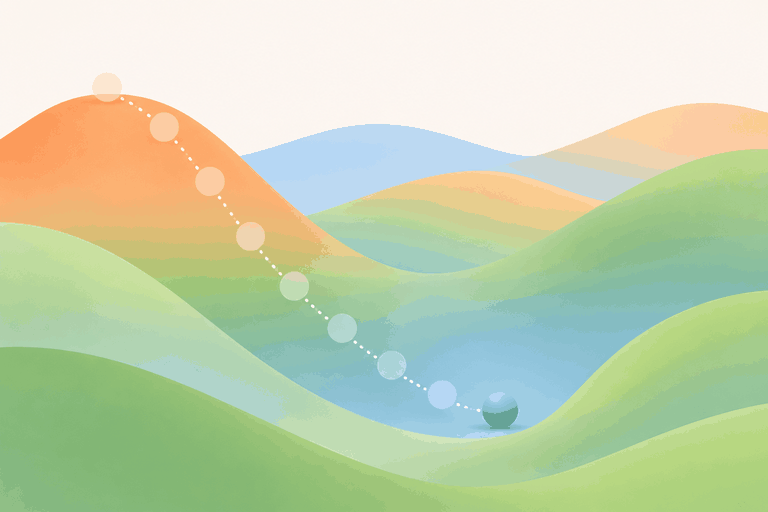
*(Ilustración generada con gpt-image-2.)*

La pelota baja por la pendiente. El gradiente apunta hacia donde más sube la
loss (pérdida). Gradient descent (descenso por gradiente) da un paso en la
dirección contraria.

En la unidad 6 y en la red que entrenamos a mano en la clase 1, cada paso usaba
todos los ejemplos de train (entrenamiento). Si $\ell_k$ es la loss del ejemplo
$k$, la loss promedio es $L(\theta)=\frac{1}{n}\sum_{k=1}^n\ell_k$. El paso es
$\theta\leftarrow\theta-\eta\,\nabla_\theta L(\theta)$, donde $\theta$ reúne los
pesos y sesgos y $\eta$ es el learning rate (tasa de aprendizaje).

Aquí barajamos los ejemplos al inicio de cada epoch y los dividimos en batches
(lotes). Para un batch $\mathcal B$, promediamos su loss,
$L_{\mathcal B}(\theta)=\frac{1}{\lvert\mathcal B\rvert}
\sum_{k\in\mathcal B}\ell_k$. El paso queda
$\theta\leftarrow\theta-\eta\,\nabla_\theta L_{\mathcal B}(\theta)$.
Llamamos $B$ al tamaño de batch elegido.

- Con $B=n$, cada paso usa todo el subconjunto de train. Es full-batch gradient descent (descenso con el lote completo).
- Con $B=1$, cada paso usa un ejemplo. Es stochastic gradient descent (descenso estocástico por gradiente, o SGD en sentido estricto).
- Con $1<B<n$, cada paso usa un mini-batch (lote de varios ejemplos).

PyTorch usa el mismo optimizer (optimizador), `SGD`, en los tres casos.
Una epoch (pasada completa por train) tiene
$\lceil n/B\rceil$ actualizaciones de $\theta$. Un batch chico da más pasos por
epoch y su gradiente suele variar más de un paso a otro. Un batch grande usa
más ejemplos en cada paso y estima con mayor precisión el gradiente completo.

**El experimento.** Todas las corridas usan los mismos 4096 ejemplos de train:
un subconjunto fijo de MNIST con casi la misma cantidad de cada dígito, para
que el experimento quepa en clase. La red es la de siempre, 784→128→10 con ReLU
(unidad lineal rectificada), con los mismos pesos iniciales y la misma secuencia
de barajado. El optimizer es SGD sin momentum (momento) con $\eta=0.03$.
Medimos sobre todo el conjunto de validation (validación), los 10 000 ejemplos.

- Full-batch, $B=4096$: 80 epochs, es decir, 80 pasos.
- $B=1$: una sola epoch, que ya son 4096 pasos.
- $B\in\{8, 32, 128, 1024\}$: cinco epochs cada uno.

En modo `RAPIDO` (sin GPU) todo esto se recorta a unos pocos pasos: sirve para
comprobar que el código corre, no para comparar.

La primera tabla muestra los tamaños de batch y el presupuesto previsto de
cada corrida. El learning rate se mantiene fijo para estudiar el efecto de
cambiar el batch. El orden de las curvas puede cambiar con otro learning rate.
En la sección 8 veremos por qué conviene ajustar ambos juntos.

**Apuesta.** Escribe tus dos respuestas antes de ejecutar.

1. Tras una epoch, ¿qué corrida esperas que tenga menor loss de validation, la de un ejemplo por batch o la de full-batch?
2. Con el mismo número de pasos al inicio del entrenamiento, ¿cuál esperas que tenga menor loss?

Abre la respuesta plegada después de mirar la gráfica y la tabla.

In [ ]:
import math
import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

# Los mismos ejemplos de train para todas las corridas: solo cambia el batch.
IDX_S07 = subconjunto(512 if RAPIDO else 4096)   # estratificados y fijos
N_S07 = len(IDX_S07)                             # n: ejemplos de train
COMPLETO_S07 = 4096                      # la etiqueta del full-batch en los IDs
TAMANOS_S07 = [COMPLETO_S07, 1, 8, 32, 128, 1024]


def plan_s07(B):
    """Epochs y frecuencia de evaluación para un tamaño de batch B."""
    B = min(B, N_S07)                    # B = n es gradient descent full-batch
    por_epoch = math.ceil(N_S07 / B)     # actualizaciones de θ en una epoch
    if B == N_S07:
        epochs = 8 if RAPIDO else 80     # un paso por epoch: ~80 pasos
    elif B == 1:
        epochs = 1                       # n pasos ya son muchísimos
    else:
        epochs = 5
    # Evaluar a menudo: cada 8 pasos como máximo, para que TODAS las corridas
    # tengan puntos medidos dentro de los primeros 20 pasos (el presupuesto
    # común en pasos), y siempre al final de cada epoch. Evaluar no cuenta
    # en el reloj: `entrenar` para el cronómetro mientras mide.
    cada = 1 if por_epoch < 8 else min(8, por_epoch // 4)
    return B, por_epoch, epochs, cada


filas = []
for tam in TAMANOS_S07:
    B, por_epoch, epochs, cada = plan_s07(tam)
    filas.append({"ID": f"s07-b{tam}", "batch": B, "pasos por epoch": por_epoch,
                  "epochs": epochs, "pasos totales": por_epoch * epochs,
                  "ejemplos vistos": B * por_epoch * epochs,
                  "evaluar cada (pasos)": cada})
display(pd.DataFrame(filas).set_index("ID"))

In [ ]:
# Una corrida por tamaño de batch. Todo lo demás es idéntico: los mismos
# pesos iniciales (semilla_init) y el mismo orden de barajar (semilla_orden).
for tam in TAMANOS_S07:
    B, por_epoch, epochs, cada = plan_s07(tam)
    cfg = Config(id=f"s07-b{tam}", seccion=7,
                 capas=[784, 128, 10], activacion="relu",
                 optimizer="sgd", lr=0.03,          # SGD sin momentum
                 batch=B, epochs=epochs, eval_cada_pasos=cada,
                 idx_train=IDX_S07, datos="4k-limpio",
                 semilla_init=SEMILLA, semilla_orden=SEMILLA)
    entrenar(cfg)       # imprime una línea por corrida y la guarda en CORRIDAS

CORRIDAS_S07 = {tam: CORRIDAS[f"s07-b{tam}"] for tam in TAMANOS_S07}

La tabla de arriba muestra cuántos pasos caben en una epoch. Todas las
corridas ven los mismos ejemplos en una pasada. Las de batch chico
actualizan los parámetros más veces. A igual número de pasos, las de batch
grande procesan más ejemplos.

La figura pone las mismas corridas en cuatro paneles. El eje horizontal
cuenta epochs, actualizaciones, ejemplos procesados o segundos de
entrenamiento. El conteo de ejemplos incluye cada visita durante el
entrenamiento y aproxima el trabajo de calcular los gradientes. Una
fracción de epoch indica qué parte de la pasada se ha completado.

El eje vertical muestra la loss de validation y tiene la misma escala en los
cuatro paneles. En la paleta viridis, el batch más chico es oscuro y los más
grandes son claros. La línea negra discontinua es full-batch. La línea
horizontal gris del primer panel marca $\log 10\approx 2.30$, la loss de
asignar la misma probabilidad a cada dígito. El eje vertical se corta en 3:
con este learning rate, batch 1 puede dar saltos bruscos y algunos picos
pueden salirse por arriba.

El eje horizontal es logarítmico para abarcar presupuestos muy distintos. La
evaluación inicial se omite porque sus contadores están en cero y el 0 no cabe
en una escala logarítmica. Cada corrida se evalúa al menos cada 8 pasos; las
que tienen pocas evaluaciones llevan un círculo en cada una, y las que tienen
cientos se dibujan solo como línea. La línea vertical gris marca el
presupuesto máximo al que llegaron **todas** las corridas, y el tramo
sombreado es lo que queda a su izquierda. El código imprime ese límite para
cada eje. Fuera del tramo gris, una curva ya no tiene contra quién
compararse. Dentro de él, no todas las corridas tienen puntos medidos en
todas partes: full-batch, por ejemplo, mide por primera vez al terminar su
primera epoch. Por eso cada panel marca con una estrella ★ la última
medición de cada corrida dentro del presupuesto común. **Compara las
estrellas**: en epochs y en ejemplos vistos caen todas al final de la
primera epoch; en pasos, alguna puede caer un poco antes del límite porque
esa corrida evalúa cada 8 pasos.

In [ ]:
# Un color por tamaño de batch (del más chico, oscuro, al más grande, claro);
# full-batch en negro y punteado. Graficamos solo la loss de validation.
PALETA_S07 = plt.cm.viridis(np.linspace(0.0, 0.85, len(TAMANOS_S07) - 1))
ESTILO_S07 = {COMPLETO_S07: dict(color="black", ls="--", label="full-batch")}
for color, tam in zip(PALETA_S07, TAMANOS_S07[1:]):
    ESTILO_S07[tam] = dict(color=color, ls="-", label=f"batch {tam}")


def eje_x_s07(h, eje):
    """La columna del historial que va en x; «epochs» puede ser fraccionaria."""
    return h["ejemplos"] / N_S07 if eje == "epochs" else h[eje]


def al_presupuesto_s07(h, eje, tope):
    """La última evaluación con x <= tope: lo que la corrida midió a ese
    presupuesto (o un poco antes, si no evaluó justo en tope)."""
    return h.loc[eje_x_s07(h, eje) <= tope * (1 + 1e-9)].iloc[-1]


EJES_S07 = {"epochs": "epochs (pasadas por los ejemplos de train)",
            "pasos": "pasos (actualizaciones de θ)",
            "ejemplos": "ejemplos vistos",
            "segundos": "segundos de entrenamiento"}
PRESUPUESTO_S07 = {}

fig, ejes = plt.subplots(2, 2, figsize=(12, 8.5), sharey=True)
for ax, (eje, etiqueta) in zip(ejes.flat, EJES_S07.items()):
    for tam, corrida in CORRIDAS_S07.items():
        h = corrida.historial
        x, y = eje_x_s07(h, eje), h["loss_validation"]
        ok = (x > 0) & np.isfinite(y)           # el 0 no cabe en escala log
        marca = "o" if ok.sum() <= 100 else None   # muchos puntos: solo línea
        ax.plot(x[ok], y[ok], marker=marca, ms=3, lw=1.4, **ESTILO_S07[tam])
    # El presupuesto común: hasta dónde llegaron TODAS las corridas.
    tope = min(eje_x_s07(c.historial, eje).max() for c in CORRIDAS_S07.values())
    PRESUPUESTO_S07[eje] = tope
    ax.axvline(tope, color="gray", ls=":", lw=1.5)
    for tam, corrida in CORRIDAS_S07.items():   # ★ = el punto comparable
        f = al_presupuesto_s07(corrida.historial, eje, tope)
        fx = f["ejemplos"] / N_S07 if eje == "epochs" else f[eje]
        if fx > 0:
            ax.plot(fx, f["loss_validation"], marker="*", ms=13, ls="none",
                    mec="black", color=ESTILO_S07[tam]["color"])
    ax.axvspan(ax.get_xlim()[0], tope, color="gray", alpha=0.08)
    ax.set_xscale("log")
    ax.set_ylim(0, 3)          # los picos de batch 1 pueden salirse por arriba
    ax.set_xlabel(etiqueta + " (escala log)")
    ax.set_title(f"contra {eje}: ★ = medido en el presupuesto común")
for ax in ejes[:, 0]:
    ax.set_ylabel("loss de validation")
ejes[0, 0].axhline(math.log(10), color="gray", lw=1)   # adivinar uniforme
ejes[0, 0].legend(fontsize=9)
fig.suptitle("La misma familia de corridas contra cuatro ejes distintos")
fig.tight_layout()
plt.show()
for eje, tope in PRESUPUESTO_S07.items():
    print(f"presupuesto común en {eje}: {tope:,.4g}")

Elige el eje según el recurso que quieras igualar.

- **Epochs o ejemplos vistos.** Con los mismos ejemplos procesados, un batch chico puede bajar más la loss porque actualiza los parámetros más veces.
- **Pasos.** Un batch grande puede bajar más la loss con las mismas actualizaciones, porque cada gradiente promedia más ejemplos. Cada paso requiere más cómputo.
- **Segundos.** Una GPU procesa varios ejemplos en paralelo. Un batch de un solo ejemplo puede aprovechar poco ese paralelismo y pagar muchas veces el costo de lanzar cada paso desde Python. Full-batch puede dar muy pocos pasos en el mismo tiempo. Un tamaño intermedio puede rendir mejor. El orden puede cambiar en CPU o con otra GPU. El reloj de la gráfica mide el entrenamiento y deja fuera el tiempo dedicado a evaluar las métricas.

La siguiente tabla muestra los presupuestos consumidos y las métricas de
validation. Usa «loss val tras 1 epoch» para comparar a igual cantidad de
datos procesados: todas vieron cada ejemplo exactamente una vez. Si una
corrida no completó esa epoch (pasa en modo `RAPIDO`), la columna dice
«sin completar». Las columnas de loss y accuracy
(proporción de aciertos) «al final» describen el punto donde terminó cada
corrida, con sus propios presupuestos: no se comparan entre filas. Decir
«full-batch terminó mejor que batch 1» sin decir que hizo 80 epochs contra
una es una comparación tramposa. Acompaña cualquier comparación con el
presupuesto al que corresponde.

In [ ]:
# «tras 1 epoch»: todas vieron los mismos n ejemplos, una vez cada uno.
filas = []
for tam, corrida in CORRIDAS_S07.items():
    h, final = corrida.historial, corrida.historial.iloc[-1]
    una_epoch = al_presupuesto_s07(h, "ejemplos", N_S07)
    completa = final["ejemplos"] >= N_S07     # con RAPIDO puede no llegar
    filas.append({
        "batch": "full-batch" if tam == COMPLETO_S07 else tam,
        "epochs": round(final["ejemplos"] / N_S07, 2),
        "pasos": int(final["pasos"]),
        "ejemplos": int(final["ejemplos"]),
        "segundos": round(final["segundos"], 2),
        "loss val tras 1 epoch": (round(una_epoch["loss_validation"], 3)
                                  if completa else "sin completar"),
        "loss val al final": round(final["loss_validation"], 3),
        "acc val al final": round(final["acc_validation"], 3),
    })
TABLA_S07 = pd.DataFrame(filas).set_index("batch")
display(TABLA_S07)
if RAPIDO:
    print("Modo RAPIDO: las corridas se cortaron a unos pocos pasos y con "
          f"n = {N_S07} el batch 1024 ya es full-batch; esta tabla solo prueba "
          "que el código corre, no compara nada.")

<details><summary>Respuesta</summary>

**Tras una epoch.** Se espera que el batch de un ejemplo vaya por delante de
full-batch. Con la misma pasada por train, actualiza los parámetros una vez
por ejemplo. Full-batch actualiza una vez por pasada. Comprueba la apuesta en
la tabla si ambas corridas completaron la primera epoch.

**A igual número de pasos.** Una expectativa razonable es que full-batch
avance más al principio. Cada paso usa el gradiente completo, mientras que
uno basado en un ejemplo puede fluctuar mucho con el learning rate elegido.
Míralo en el panel de pasos, dentro del tramo gris. Si el orden sale
distinto al esperado, ese resultado también responde la pregunta: dice cómo
se comportan estos batches con el learning rate de esta corrida.

</details>

¿Por qué varía el gradiente de un batch chico? Con $\theta$ fijo, el gradiente
$g_{\mathcal B}=\nabla_\theta L_{\mathcal B}(\theta)$ promedia los gradientes
de los ejemplos del batch. Si tomamos batches al azar, ese promedio es un
estimador insesgado del gradiente completo
$g_{\text{completo}}=\nabla_\theta L(\theta)$.
Al cambiar de batch, el estimador fluctúa. Medimos ese ruido como
$\mathbb E\,\lVert g_{\mathcal B}-g_{\text{completo}}\rVert^2$, la distancia
al cuadrado al gradiente completo, promediada sobre el muestreo de batches.

En la unidad 9 vimos la misma idea con un promedio muestral. Si las
observaciones son independientes y tienen varianza $\sigma^2$, la varianza
del promedio es $\sigma^2/B$. Su error estándar baja como $1/\sqrt B$. Por
eso esperamos que el ruido, que aquí es una **distancia al cuadrado**,
baje aproximadamente como $1/B$. En cada batch muestreamos sin reemplazo
entre los $n$ ejemplos. Eso multiplica el ruido esperado por
$(n-B)/(n-1)$. Con $B=n$, el batch contiene todo el conjunto y el ruido
es cero.

El código mantiene fijos los pesos. Calcula el gradiente completo con
backpropagation (retropropagación) y lo compara con el de 32 batches al azar por cada
$B\in\{1, 8, 32, 128, 1024\}$ (8 en modo `RAPIDO`). Repite la medición con la
red recién inicializada y con la red de `s07-b128` al final de sus cinco
epochs. La tabla reporta el ruido
promedio y su cociente con $\lVert g_{\text{completo}}\rVert^2$, que llamamos
la señal. Un cociente mayor que uno indica que, en promedio, la distancia
al cuadrado al gradiente completo supera la magnitud al cuadrado de ese
gradiente.

Ambos ejes de la gráfica están en escala logarítmica. Una ley $1/B$ se ve como
una recta de pendiente $-1$. Las líneas grises discontinuas son referencias
$1/B$ ajustadas a la escala de los datos de cada red. Las punteadas incorporan
la corrección por muestreo sin reemplazo. Las barras muestran el error
estándar de la media de las distancias medidas para cada tamaño.

In [ ]:
# El ruido del gradiente con los pesos CONGELADOS: nada se entrena aquí.
X_S07, Y_S07 = (t[IDX_S07.to(t.device)] for t in DATOS["estandar"]["train"])
PERDIDA_S07 = nn.CrossEntropyLoss()       # promedio sobre el batch


def gradiente_s07(modelo, X, y):
    """∇L_𝓑(θ) de todas las capas, aplanado en un solo vector."""
    modelo.zero_grad(set_to_none=True)
    PERDIDA_S07(modelo(X), y).backward()
    return torch.cat([p.grad.reshape(-1) for p in modelo.parameters()])


def ruido_s07(modelo, tamanos, repeticiones=32, semilla=SEMILLA):
    """Promedio de ‖g_𝓑 − g_completo‖² sobre `repeticiones` batches por B."""
    modelo.eval()
    g_completo = gradiente_s07(modelo, X_S07, Y_S07)   # el de gradient descent
    azar = torch.Generator().manual_seed(semilla)
    filas = []
    for B in tamanos:
        d2 = []
        for _ in range(repeticiones):
            lote = torch.randperm(len(Y_S07), generator=azar)[:B]
            lote = lote.to(X_S07.device)                # sin reemplazo
            g_B = gradiente_s07(modelo, X_S07[lote], Y_S07[lote])
            d2.append(((g_B - g_completo) ** 2).sum().item())
        filas.append({"B": B, "ruido": float(np.mean(d2)),
                      "error estándar": float(np.std(d2) / math.sqrt(len(d2)))})
    modelo.zero_grad(set_to_none=True)
    return pd.DataFrame(filas), float((g_completo ** 2).sum())


TAMANOS_RUIDO_S07 = [B for B in (1, 8, 32, 128, 1024) if B < N_S07]
REPETICIONES_S07 = 8 if RAPIDO else 32

torch.manual_seed(SEMILLA)                 # la misma red recién inicializada
red_inicial = construir_red([784, 128, 10], "relu").to(DEVICE)
red_entrenada = cargar(CORRIDAS["s07-b128"], "ultima")   # tras sus 5 epochs
RUIDO_S07 = {}
for nombre, red in [("recién inicializada", red_inicial),
                    ("entrenada (s07-b128)", red_entrenada)]:
    tabla, senal = ruido_s07(red, TAMANOS_RUIDO_S07, REPETICIONES_S07)
    tabla["ruido / ‖g_completo‖²"] = tabla["ruido"] / senal
    RUIDO_S07[nombre] = tabla
    print(f"{nombre}: ‖g_completo‖² = {senal:.4g}")
    display(tabla.set_index("B").round(4))
del red_inicial, red_entrenada

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 5))
B = np.array(TAMANOS_RUIDO_S07, dtype=float)
for (nombre, tabla), marca in zip(RUIDO_S07.items(), ["o", "s"]):
    ax.errorbar(tabla["B"], tabla["ruido"], yerr=tabla["error estándar"],
                marker=marca, capsize=3, lw=1.8, label=nombre)
    # La recta 1/B anclada en la mediana de B·ruido: en log-log, pendiente −1.
    c = float(np.median(tabla["B"] * tabla["ruido"]))
    ax.plot(B, c / B, color="gray", ls="--", lw=1)
    # Con muestreo SIN reemplazo de n ejemplos el ruido cae un poco más:
    # se multiplica por (n − B)/(n − 1), que ya pesa en B = 1024.
    ax.plot(B, c / B * (N_S07 - B) / (N_S07 - 1), color="gray", ls=":", lw=1)
ax.plot([], [], color="gray", ls="--", label="referencia ∝ 1/B")
ax.plot([], [], color="gray", ls=":", label="1/B × (n − B)/(n − 1)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("tamaño del batch B (escala log)")
ax.set_ylabel(r"$\mathbb{E}\,\|g_{\mathcal{B}} - g_{\mathrm{completo}}\|^2$"
              "  (escala log)")
ax.set_title(f"Ruido del gradiente: promedio de {REPETICIONES_S07} batches por B")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

**Qué viste**

- **El avance depende del presupuesto.** Compara las estrellas ★ de cada panel: busca si los batches chicos avanzan más por ejemplo o por epoch, si los grandes avanzan más por paso y si un tamaño intermedio rinde mejor por segundo en GPU. Algunas diferencias pueden ser pequeñas, y el orden por segundos depende de la máquina.
- **El ruido baja al promediar más ejemplos.** Busca una caída cercana a $1/B$ y fíjate si se acentúa al aumentar la fracción del conjunto que entra en cada batch.
- **La señal también puede cambiar al entrenar.** Compara las dos normas al cuadrado que imprime el código. Si el gradiente completo se hace pequeño, el cociente ruido/señal puede subir, incluso cuando el ruido absoluto baja. Cerca de un mínimo, el ruido de los batches chicos puede dominar el gradiente que queremos estimar. Puede que aquí no se vea. En la sección 14 volveremos a medir gradientes, esta vez por capa.

El tamaño del batch afecta la memoria, los pasos que das por epoch, el
ruido de cada actualización y el tiempo de cómputo. En el resto del notebook
usaremos mini-batches por omisión. El siguiente paso es ver cómo el
learning rate cambia el efecto de cada actualización.

## 08 · El learning rate

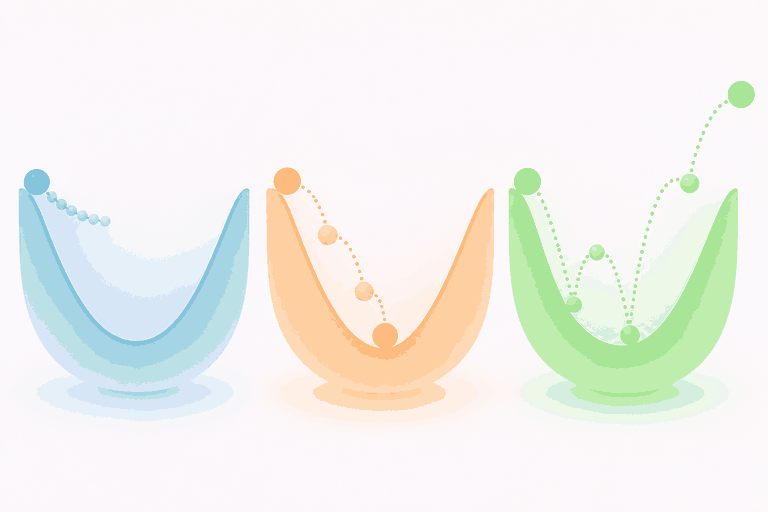
*(Ilustración generada con gpt-image-2.)*

En la clase 1 actualizaste los pesos y sesgos con gradient descent (descenso
por gradiente). La regla era $\theta \leftarrow \theta - \eta\,\nabla L(\theta)$.
El negativo del gradiente indica hacia dónde bajar. El learning rate (tasa
de aprendizaje) $\eta$ multiplica ese vector y controla el tamaño del paso.
Hace el papel de $\alpha$ en la unidad 6.

Mira las tres pelotas, cada una en su valle. A la izquierda, con pasos
pequeños, la pelota apenas avanza. En el centro, con pasos intermedios,
llega al fondo. A la derecha, con pasos grandes, rebota entre las paredes
y sale del valle.

Primero veremos cuándo un paso produce avance lento, descenso rápido,
oscilaciones o divergencia en una cuadrática sin datos. Después buscaremos
esos patrones al entrenar en MNIST con SGD y Adam.

Partimos de $(1,1)$ y queremos llegar al mínimo $(0,0)$ de
$f(x,y)=\tfrac12(x^2+100y^2)$. La curvatura, medida por la segunda derivada,
es $1$ en $x$ y $100$ en $y$. Por eso el valle es largo en $x$ y angosto en $y$.
Las curvas de nivel unen puntos con el mismo valor de $f$ y forman elipses
alargadas en $x$.

El gradiente es $\nabla f(x,y)=(x,100y)$. Cada paso multiplica $x$ por
$1-\eta$ y $y$ por $1-100\eta$. Como ambas coordenadas empiezan fuera de
cero, las dos tienden a cero si y solo si ambos factores tienen valor
absoluto menor que $1$. La dirección más empinada impone el límite de
estabilidad $0<\eta<2/100=0.02$. En ese intervalo, el factor $1-\eta$
queda cerca de $1$, así que el avance en $x$ es lento.

- Con $\eta=0.001$, los factores son $0.999$ en $x$ y $0.9$ en $y$.
  La trayectoria baja hacia el fondo del valle y apenas avanza en $x$.
- Con $\eta=0.01$, el factor en $y$ es $0$. Esa coordenada llega a cero
  en un paso y después $x$ se reduce por un factor de $0.99$ en cada paso.
- Con $\eta=0.018$, el factor en $y$ es $-0.8$. La trayectoria cambia de
  lado en cada paso y el zigzag se va apagando.
- Con $\eta=0.025$, el factor en $y$ es $-1.5$. Cada salto cruza el valle
  y queda más lejos del centro. La trayectoria diverge.

El código imprime los factores y dibuja un panel por $\eta$, con los mismos
ejes. El cuadro negro marca el inicio y la estrella roja, el mínimo. Los
puntos azules marcan los pasos sobre las curvas de nivel grises.

In [ ]:
# f(x, y) = ½ (x² + 100 y²): curvatura 1 en la dirección x, 100 en la y.
# Su gradiente es ∇f = (x, 100 y). Un paso de gradient descent con η:
#     x ← x − η·x     = (1 − η)·x
#     y ← y − η·100·y = (1 − 100η)·y
# Cada dirección se multiplica por un factor fijo en cada paso.
def f_cuadratica(x, y):
    return 0.5 * (x ** 2 + 100 * y ** 2)


def descenso_cuadratica(eta, pasos=100, inicio=(1.0, 1.0)):
    """Los puntos (x, y) que visita gradient descent: arreglo [pasos+1, 2]."""
    puntos = [np.array(inicio, dtype=float)]
    for _ in range(pasos):
        x, y = puntos[-1]
        gradiente = np.array([x, 100 * y])            # ∇f en el punto actual
        puntos.append(puntos[-1] - eta * gradiente)   # el paso: θ ← θ − η ∇f
    return np.array(puntos)


ETAS_2D = [0.001, 0.01, 0.018, 0.025]
NOMBRE_2D = {0.001: "muy bajo", 0.01: "bueno",
             0.018: "alto: oscila", 0.025: "demasiado alto: diverge"}
TRAYECTORIAS = {eta: descenso_cuadratica(eta) for eta in ETAS_2D}

# Los factores por paso son cifras analíticas (no dependen de semillas):
# una dirección converge si y solo si |factor| < 1.
for eta in ETAS_2D:
    fx, fy = 1 - eta, 1 - 100 * eta
    veredicto = "converge" if abs(fx) < 1 and abs(fy) < 1 else "DIVERGE"
    print(f"η = {eta:<6}  factor en x = {fx:+.3f}  factor en y = {fy:+.3f}"
          f"  → {veredicto}")
print(f"Límite de estabilidad: |1 − 100η| < 1  ⇔  0 < η < 2/100 = {2 / 100}")

# Curvas de nivel de f y la trayectoria encima, un panel por η, mismos ejes.
xs, ys = np.meshgrid(np.linspace(-0.3, 1.3, 400), np.linspace(-2.5, 2.5, 400))
niveles = np.logspace(-2, 2.5, 14)
fig, ejes = plt.subplots(1, 4, figsize=(17, 4.4), sharex=True, sharey=True)
for ax, eta in zip(ejes, ETAS_2D):
    ax.contour(xs, ys, f_cuadratica(xs, ys), levels=niveles,
               colors="0.65", linewidths=0.8)
    tr = TRAYECTORIAS[eta]
    fuera = np.nonzero(np.abs(tr[:, 1]) > 2.5)[0]
    if len(fuera):                    # se sale del dibujo: hasta ahí la vemos
        tr = tr[:fuera[0] + 1]
        ax.text(0.5, 0.06, f"en el paso {fuera[0]} sale de la gráfica",
                transform=ax.transAxes, ha="center", color="crimson")
    ax.plot(tr[:, 0], tr[:, 1], "-o", color=COLORES["train"], ms=2.5, lw=1)
    ax.plot(1, 1, "ks", ms=7, label="inicio (1, 1)")
    ax.plot(0, 0, "r*", ms=13, label="mínimo (0, 0)")
    ax.set_xlim(-0.3, 1.3)
    ax.set_ylim(-2.5, 2.5)
    ax.set_title(f"η = {eta}: {NOMBRE_2D[eta]}")
    ax.set_xlabel("x (curvatura 1)")
ejes[0].set_ylabel("y (curvatura 100)")
ejes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Gradient descent sobre f(x, y) = ½(x² + 100 y²), 100 pasos")
plt.tight_layout()
plt.show()

Ahora mira el valor de $f$ en cada paso. El eje vertical está en escala
logarítmica. Si $f$ se multiplica por el mismo factor en cada paso, la curva
se ve como una recta. Baja si el factor es menor que $1$ y sube si es mayor.
La corrida que diverge acaba por salirse por arriba.

Fíjate en cuál termina más abajo. Con $\eta=0.018$, la trayectoria oscila
en $y$ y logra una $f$ final menor que con $\eta=0.01$. Una vez que el
zigzag se apaga, domina la dirección plana. Ahí el factor $0.982$
reduce $x$ más rápido que $0.99$.

El learning rate fijo que minimiza el mayor de los dos factores en valor
absoluto es $\eta=2/101\approx0.0198$. En ese punto ambos factores tienen la
misma magnitud y signos opuestos. El valor queda cerca del límite de
estabilidad. Al final, el código imprime $x$, $y$ y $f$ para cada trayectoria.

In [ ]:
# El valor de f en cada paso, en escala log: una recta que baja es una
# convergencia geométrica (el mismo factor en cada paso).
COLORES_ETA_2D = dict(zip(ETAS_2D, plt.cm.viridis(np.linspace(0, 0.85, 4))))
fig, ax = plt.subplots(figsize=(8, 4.5))
for eta in ETAS_2D:
    tr = TRAYECTORIAS[eta]
    ax.plot(f_cuadratica(tr[:, 0], tr[:, 1]), color=COLORES_ETA_2D[eta],
            lw=2, label=f"η = {eta} ({NOMBRE_2D[eta]})")
ax.set_yscale("log")
ax.set_ylim(1e-3, 1e4)                    # la que diverge se sale por arriba
ax.set_xlabel("paso")
ax.set_ylabel("f(x, y)  (escala log)")
ax.set_title("El valor de f paso a paso, para cada learning rate")
ax.legend()
plt.tight_layout()
plt.show()

for eta in ETAS_2D:
    x, y = TRAYECTORIAS[eta][-1]
    print(f"η = {eta:<6}  tras 100 pasos: x = {x:+.3e}  y = {y:+.3e}"
          f"  f = {f_cuadratica(x, y):.3e}")

Pasamos a clasificar los dígitos de MNIST con una red de una capa oculta
con ReLU. Cerca de un mínimo, la loss (pérdida) de una red puede aproximarse
con una cuadrática. Sus direcciones pueden tener curvaturas muy distintas,
como en el valle que acabamos de ver.

Haremos un barrido de $\eta$ con cada optimizer (optimizador). Todas las
corridas arrancan con los mismos pesos y sesgos y recorren los batches en
el mismo orden. El tamaño del batch también se mantiene fijo. Con SGD
(stochastic gradient descent), el paso sigue el gradiente del batch
multiplicado por $-\eta$. Adam ajusta el paso de cada parámetro según sus
gradientes recientes. Por eso la escala de $\eta$ puede ser distinta. La
sección 9 vuelve a Adam con más detalle.

En cada corrida medimos la loss sobre train y validation al inicio y luego
a intervalos. Todas las tasas tienen el mismo presupuesto de pasos, que
se reduce en modo `RAPIDO`. Este tramo corto nos permite comparar el arranque.

Si la loss de un batch llega a infinito o a `NaN` (*Not a Number*), la
función `entrenar` detiene esa corrida y registra el primer paso no finito.
El barrido sigue con las demás tasas.

En una red con ReLU y cross-entropy, un $\eta$ demasiado grande no siempre
produce `NaN`. A menudo la loss da saltos y luego se atasca cerca de
$\log 10$ o más arriba: la red deja de aprender sin que ningún número se
desborde. Por eso el barrido de SGD termina con $\eta=1000$, un valor
absurdo a propósito, para ver un `NaN` de verdad y comprobar que el
notebook no truena. Puede que ninguna corrida de Adam diverja.

**Apuesta.** Antes de ejecutar, mira las tasas en `BARRIDO_LR` y escribe
cuál dará la menor loss final de validation con SGD y cuál con Adam.
¿Esperas que gane la misma tasa en ambos? ¿Cuáles crees que divergirán?

Abre «Respuesta» después de ver la gráfica de la «U».

In [ ]:
# La misma red 784 → 128 → 10 (ReLU) y los mismos pesos iniciales
# (semilla_init = 0) para todas: lo ÚNICO que cambia es η (y el optimizer).
# Cada corrida da ~300 pasos de batch 128 (menos de una epoch) y evalúa
# train y validation completos cada 25 pasos.
PASOS_LR = 30 if RAPIDO else 300
EVAL_LR = 5 if RAPIDO else 25
# El último valor de SGD (1000) es absurdo a propósito: con ReLU y
# cross-entropy, un η grande suele «matar» la red sin producir NaN; con 1000
# los números se desbordan y vemos cómo entrenar() atrapa el NaN sin tronar.
BARRIDO_LR = {
    "sgd": [1e-4, 1e-3, 1e-2, 3e-2, 1e-1, 0.5, 1.0, 5.0, 1000.0],
    "adam": [1e-5, 1e-4, 1e-3, 1e-2, 1e-1],
}
CORRIDAS_LR = {"sgd": [], "adam": []}

for opt, etas in BARRIDO_LR.items():
    for eta in etas:
        cfg = Config(id=f"s08-{opt}-{eta:g}", seccion=8,
                     capas=[784, 128, 10], optimizer=opt, lr=eta, batch=128,
                     epochs=10, max_pasos=PASOS_LR, eval_cada_pasos=EVAL_LR)
        # entrenar imprime una línea por corrida. Si la loss deja de ser
        # finita, NO truena: marca divergio, anota el paso y se detiene.
        CORRIDAS_LR[opt].append(entrenar(cfg))

Cada figura reúne las corridas de un optimizer. Los paneles van de menor
a mayor $\eta$ y comparten los ejes. El horizontal cuenta las actualizaciones
y el vertical muestra la loss de cross-entropy (entropía cruzada). Azul es
train y naranja es validation. La línea punteada marca $\log 10$, la loss
de asignar la misma probabilidad a cada dígito.

Con una tasa baja, la loss puede quedarse cerca de la línea punteada.
Busca tasas que la hagan bajar pronto y compáralas con las que bajan a
saltos o rebotan. Los valores que quedan por encima del panel son peores
que la referencia uniforme; cuando eso pasa, el panel escribe en rojo el
máximo que alcanzó. Si una corrida se detuvo por divergencia,
el panel marca en rojo el primer paso con loss no finita. Las curvas
solo muestran evaluaciones finitas.

En un tramo tan corto, train y validation pueden seguirse de cerca. Mira
qué tan pronto bajan y qué tan estable es el descenso. Si empiezan a
separarse, fíjate en cuál sigue bajando.

In [ ]:
# Una gráfica por η: loss de train y de validation contra pasos.
# Mismos ejes en todas; la línea punteada es log 10 ≈ 2.30, la loss de
# adivinar uniforme entre 10 dígitos.
TECHO_LR = 3.5            # lo que pasa de aquí ya es «peor que adivinar»


NOMBRE_OPT = {"sgd": "SGD", "adam": "Adam"}


def panel_lr(ax, c):
    """Las curvas de una corrida del barrido; si divergió, lo dice encima."""
    nombre = NOMBRE_OPT[c.config.optimizer]
    curvas([c], x="pasos", metrica="loss", conjuntos=("train", "validation"),
           ax=ax, titulo=f"{nombre}, η = {c.config.lr:g}")
    if ax.get_legend():
        ax.get_legend().remove()          # una sola leyenda por figura, abajo
    ax.axhline(math.log(10), color="0.4", ls=":", lw=1)
    ax.set_ylim(0, TECHO_LR)
    ax.set_xlim(0, PASOS_LR)
    v = c.historial[["loss_train", "loss_validation"]].to_numpy(dtype=float)
    v = v[np.isfinite(v)]
    if len(v) and v.max() > TECHO_LR:     # avisa lo que se sale por arriba
        ax.text(0.98, 0.04, f"máx. {v.max():.3g}: sale del eje",
                transform=ax.transAxes, ha="right", va="bottom", color="crimson")
    if c.divergio:
        ax.text(0.5, 0.5, f"DIVERGIÓ\nprimer paso no finito: {c.paso_no_finito}",
                transform=ax.transAxes, ha="center", va="center",
                color="crimson", fontsize=11, fontweight="bold")


for opt, columnas in (("sgd", 3), ("adam", 5)):
    lista = CORRIDAS_LR[opt]
    filas = math.ceil(len(lista) / columnas)
    fig, ejes = plt.subplots(filas, columnas, figsize=(4 * columnas, 3.3 * filas),
                             squeeze=False)
    for ax, c in zip(ejes.flat, lista):
        panel_lr(ax, c)
    for ax in list(ejes.flat)[len(lista):]:
        ax.set_visible(False)
    fig.suptitle(f"{NOMBRE_OPT[opt]}: loss contra pasos, de η pequeño a η grande")
    fig.legend(handles=[plt.Line2D([], [], color=COLORES["train"], label="train"),
                        plt.Line2D([], [], color=COLORES["validation"],
                                   label="validation"),
                        plt.Line2D([], [], color="0.4", ls=":",
                                   label="log 10 ≈ 2.30 (adivinar)")],
               loc="lower center", ncol=3, bbox_to_anchor=(0.5, 0.0))
    plt.tight_layout(rect=(0, 0.05, 1, 1))
    plt.show()

Cada marca corresponde a una corrida. El eje horizontal muestra $\eta$
en escala logarítmica. Dos saltos del mismo tamaño en ese eje multiplican
$\eta$ por el mismo factor. El eje vertical muestra la loss de validation
al final de la corrida.

Los círculos morados son de SGD y los cuadrados cafés, de Adam. Una
$\times$ arriba marca una corrida que divergió o terminó con una loss de
validation no finita. Si un valor finito rebasa el rango elegido para la
loss, su marca queda en el techo como un triángulo hueco, con el valor
escrito al lado. La tabla trae todos los valores.

Busca una «U». A la izquierda, los pasos pequeños pueden dejar la loss
alta. En medio, algunas tasas pueden bajarla más. A la derecha pueden
aparecer valores altos o un salto directo a $\times$. También puede haber
un fondo plano con varias tasas casi empatadas.

El código imprime la tasa con menor loss final de validation para cada
optimizer que tenga corridas válidas. La tabla muestra la loss final de
train y validation y la accuracy (proporción de aciertos) de validation.
También indica si cada corrida divergió y el primer paso no finito cuando
se detectó.

In [ ]:
# La «U»: loss de validation al final de los pasos contra η (escala log).
# Una × arriba = la corrida divergió (su loss ya no es un número);
# un triángulo hueco arriba = loss finita, pero más alta que el techo.
ESTILO_OPT = {"sgd": ("#9467bd", "o", "SGD"), "adam": ("#8c564b", "s", "Adam")}
filas_tabla = []
fig, ax = plt.subplots(figsize=(9, 4.8))
for opt, lista in CORRIDAS_LR.items():
    color, marca, nombre = ESTILO_OPT[opt]
    etas_ok, finales = [], []
    for c in lista:
        ultima = c.historial.iloc[-1]
        final = float(ultima["loss_validation"])
        roto = c.divergio or not math.isfinite(final)
        filas_tabla.append({
            "optimizer": nombre, "η": c.config.lr,
            "loss train final": float(ultima["loss_train"]),
            "loss validation final": final,
            "acc validation final": float(ultima["acc_validation"]),
            "divergió": c.divergio, "primer paso no finito": c.paso_no_finito,
            "loss final no finita": not math.isfinite(final)})
        if roto:
            ax.plot(c.config.lr, TECHO_LR, "x", color=color, ms=12, mew=3)
        else:
            etas_ok.append(c.config.lr)
            finales.append(min(final, TECHO_LR))  # fuera de escala → al techo
            if final > TECHO_LR:
                ax.plot(c.config.lr, TECHO_LR, "^", color=color, ms=12,
                        mfc="none", mew=2)
                ax.annotate(f"{final:.3g}", (c.config.lr, TECHO_LR), color=color,
                            textcoords="offset points", xytext=(8, -14))
    ax.plot(etas_ok, finales, "-", marker=marca, color=color, lw=2, ms=7,
            label=f"{nombre} (× = divergió, △ = fuera de escala)")
ax.axhline(math.log(10), color="0.4", ls=":", lw=1,
           label="log 10 ≈ 2.30: adivinar uniforme")
ax.set_xscale("log")
ax.set_ylim(0, TECHO_LR + 0.2)
ax.set_xlabel("learning rate η (escala log)")
ax.set_ylabel(f"loss de validation tras {PASOS_LR} pasos")
ax.set_title("Loss de validation según el learning rate")
ax.legend()
plt.tight_layout()
plt.show()

TABLA_LR = pd.DataFrame(filas_tabla)
# El ganador de cada optimizer se elige con validation (nunca con test).
validas = ~TABLA_LR["divergió"] & ~TABLA_LR["loss final no finita"]
for nombre, grupo in TABLA_LR[validas].groupby("optimizer"):
    mejor = grupo.loc[grupo["loss validation final"].idxmin()]
    print(f"Mejor η para {nombre} (por loss de validation): {mejor['η']:g}")
display(TABLA_LR.round({"loss train final": 4, "loss validation final": 4,
                        "acc validation final": 4}))

<details><summary>Respuesta</summary>

Compara tu apuesta con el ganador que imprimió el código para cada
optimizer. Mira en la tabla si alguna otra tasa quedó cerca.

En este barrido cabe esperar que la tasa útil de SGD sea mayor que la de
Adam. En SGD, un gradiente pequeño da un paso pequeño para el mismo
$\eta$. Adam divide el promedio reciente del gradiente de cada parámetro
por una estimación de su escala. Así, un mismo $\eta$ puede dar tamaños
de paso distintos con los dos optimizers. Si cambias de optimizer, vuelve
a comparar tasas con validation.

Con SGD, $\eta=1000$ está puesto para divergir. Las tasas grandes que
quedan antes, como $\eta=5$, pueden terminar con una loss finita: mira en
su panel si la loss dio saltos y se quedó alta en lugar de bajar.

</details>

- **Paso muy pequeño.** La loss puede quedarse cerca de $\log 10$.
  En la cuadrática, el factor de la dirección plana queda casi en $1$.
- **Paso que funciona bien.** La loss baja pronto y de forma sostenida.
- **Paso grande.** En MNIST puedes ver rebotes en la loss. En la cuadrática,
  un factor negativo hace que la coordenada cambie de signo en cada paso.
- **Divergencia.** En la cuadrática, $|1-100\eta|>1$ hace crecer $|y|$.
  En MNIST, el código detiene la corrida si detecta infinito o `NaN`
  en la loss de un batch. Antes de llegar ahí puede haber una zona donde
  la loss salta y se atasca alta sin volverse `NaN`.

En la sección 7 vimos que un batch más grande da un gradiente menos
ruidoso. Eso puede permitir un learning rate mayor. Si cambias el batch,
vuelve a revisar $\eta$.

El learning rate es un hiperparámetro. Como en la unidad 9, elígelo
con validation y reserva test para reportar el resultado al final.

## 9 · Optimizers

Un *optimizer* (optimizador) convierte el gradiente de un mini-batch (lote
pequeño) en un cambio de los parámetros $\theta$. En la clase 1 hiciste
*gradient descent* (descenso de gradiente) a mano. En PyTorch,
`torch.optim.SGD` aplica esa misma regla al llamar a `opt.step()` en el
loop de la sección 3.

Justo antes del paso $t$, los parámetros son $\theta_t$. El gradiente del
mini-batch $\mathcal B_t$ es
$\mathbf g_t = \nabla_\theta L_{\mathcal B_t}(\theta_t)$.
La letra $g^{(l)}$ sigue nombrando la activación de la capa $l$.
El *learning rate* (tasa de aprendizaje) es $\eta$.

**SGD** (*stochastic gradient descent*, descenso de gradiente estocástico)
usa el gradiente del mini-batch actual. Multiplica ese gradiente por $\eta$
y da un paso en el sentido opuesto.

$$
\theta_{t+1} = \theta_t - \eta\,\mathbf g_t.
$$

**SGD con momentum** (inercia) acumula gradientes. El acumulador
$\mathbf m_0$ empieza en cero y $\beta$ indica cuánto se conserva del
acumulador anterior. Si los gradientes apuntan en la misma dirección,
se refuerzan. Si alternan de signo, la suma puede amortiguar el zigzag.

$$
\mathbf m_t = \beta\,\mathbf m_{t-1} + \mathbf g_t,
\qquad
\theta_{t+1} = \theta_t - \eta\,\mathbf m_t.
$$

**Adam** lleva dos promedios por parámetro. El primero, $\mathbf m_t$,
promedia los gradientes recientes. El segundo, $\mathbf v_t$, promedia sus
cuadrados. Los factores $\beta_1$ y $\beta_2$ controlan cuánto pesa el
historial en cada promedio.

$$
\begin{aligned}
\mathbf m_t &= \beta_1\mathbf m_{t-1} + (1-\beta_1)\mathbf g_t,\\
\mathbf v_t &= \beta_2\mathbf v_{t-1} + (1-\beta_2)\mathbf g_t^2,\\
\widehat{\mathbf m}_t &= \frac{\mathbf m_t}{1-\beta_1^t},
&
\widehat{\mathbf v}_t &= \frac{\mathbf v_t}{1-\beta_2^t},\\
\theta_{t+1} &= \theta_t -
\eta\,\frac{\widehat{\mathbf m}_t}{\sqrt{\widehat{\mathbf v}_t}+\varepsilon}.
\end{aligned}
$$

Ambos promedios arrancan en cero. En los primeros pasos, parte del
peso de cada promedio todavía corresponde a ese cero. Dividir entre
$1-\beta_1^t$ y $1-\beta_2^t$ corrige ese sesgo. En el primer paso queda
$\widehat{\mathbf m}_1=\mathbf g_1$ y
$\widehat{\mathbf v}_1=\mathbf g_1^2$. El cuadrado, la raíz y la división de
la actualización se calculan componente a componente.
$\varepsilon$ es una constante pequeña que evita dividir entre cero.

Al dividir por la escala reciente de cada componente del gradiente, Adam
adapta el tamaño del paso a cada parámetro. En el primer paso, si la
magnitud de la componente supera ampliamente a $\varepsilon$, el cambio
en ese parámetro tiene magnitud cercana a $\eta$. El mismo $\eta$ puede
dar pasos de tamaños muy distintos en Adam y en SGD.

**AdamW** usa la actualización de Adam y aplica por separado el *weight
decay* (encogimiento de los pesos). Verás cómo funciona después de la
primera comparación.

Las cuatro corridas usan la arquitectura de la línea base, los mismos
parámetros iniciales, el mismo orden de batches y el mismo presupuesto de
epochs (vueltas por los datos de train). SGD y SGD con momentum comparten
el learning rate. Adam y AdamW también. En esta comparación, el decay
se activa solo en AdamW. La celda de código muestra los valores.

**Apuesta.** Con el mismo presupuesto de epochs, ¿qué configuración
terminará con la menor loss de validation? ¿Esperas que SGD sin momentum
quede atrás o que alcance a las demás? Escribe tu predicción antes de
ejecutar la siguiente celda.

Las gráficas que siguen muestran también test en cada epoch. Mirar test
en cada epoch está mal: test se usa una sola vez, al final, para
reportar. Aquí aparece solo de manera didáctica, para aprender a leer
las curvas. Todas las decisiones se toman con validation.

In [ ]:
# Cuatro configuraciones sobre la misma red 784→128→10, con los mismos pesos
# iniciales (semilla_init) y el mismo orden de batches (semilla_orden).
# Cambia la regla con la que cada paso mueve θ, y con ella su η: SGD y
# momentum usan 0.03, Adam y AdamW 1e-3. Solo AdamW lleva weight decay.
OPTIMIZERS_S09 = [
    # (ID,             optimizer,  η,    weight_decay)
    ("s09-sgd",        "sgd",      0.03, 0.0),
    ("s09-momentum",   "momentum", 0.03, 0.0),    # β = 0.9, ver la ecuación
    ("s09-adam",       "adam",     1e-3, 0.0),
    ("s09-adamw",      "adamw",    1e-3, 0.01),   # decay desacoplado, solo pesos
]

corridas_s09 = []
for id_, opt, lr, wd in OPTIMIZERS_S09:
    cfg = Config(id=id_, seccion=9, capas=[784, 128, 10], optimizer=opt,
                 lr=lr, weight_decay=wd, epochs=5, batch=128,
                 semilla_init=SEMILLA, semilla_orden=SEMILLA)
    corrida = entrenar(cfg)
    corridas_s09.append(corrida)
    ultima = corrida.historial.iloc[-1]
    print(f"{id_:14s} η = {lr:<6g} weight_decay = {wd:<5g} "
          f"loss validation final = {ultima['loss_validation']:.4f}   "
          f"accuracy validation final = {ultima['acc_validation']:.4f}")

In [ ]:
# Small multiples: un panel por optimizer, mismos ejes, para comparar de un
# vistazo. Colores = conjunto (train, validation, test); un panel = una corrida.
fig = rejilla(corridas_s09, x="epoch", metrica="loss", columnas=4)
fig.suptitle("Loss por epoch con cuatro configuraciones (red 784→128→10)")
plt.show()

# Las cuatro curvas de validation en un solo eje: aquí sí se ve quién baja
# más rápido. Color = validation (como en todo el notebook); el estilo de
# línea y el marcador distinguen la corrida, para que dos curvas encimadas
# (Adam y AdamW) se sigan viendo.
TRAZOS_S09 = [("-", "o"), ("--", "s"), (":", "^"), ("-.", "D")]


def por_corrida(corridas, columna, ax, titulo, etiqueta_y, color, log=False):
    """Una línea por corrida con la columna `columna` de su historial."""
    for c, (estilo, marca) in zip(corridas, TRAZOS_S09):
        h = c.historial
        ok = np.isfinite(h[columna].to_numpy(dtype=float))
        ax.plot(h["epoch"][ok], h[columna][ok], estilo, marker=marca, ms=4,
                color=color, label=c.id)
    if log:
        ax.set_yscale("log")
    ax.set_title(titulo)
    ax.set_xlabel("epoch")
    ax.set_ylabel(etiqueta_y)
    ax.legend(fontsize=8)


fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
por_corrida(corridas_s09, "loss_validation", ejes[0],
            "Loss de validation (escala log)", "loss (cross-entropy)",
            COLORES["validation"], log=True)
por_corrida(corridas_s09, "acc_validation", ejes[1], "Accuracy de validation",
            "accuracy", COLORES["validation"])
plt.tight_layout()
plt.show()

In [ ]:
# La tabla maestra, solo con las filas de esta comparación. La «mejor epoch»
# se elige con la loss de validation; test solo se reporta.
ids_comparacion = [id_ for id_, *_ in OPTIMIZERS_S09]
tabla_s09 = tabla_maestra([9])
display(tabla_s09[tabla_s09["id"].isin(ids_comparacion)])

<details><summary>Respuesta</summary>

SGD sin momentum suele bajar más despacio al inicio. Con momentum o con
Adam, la loss puede bajar más rápido. Adam y AdamW pueden quedar casi
encimados, porque el encogimiento directo de AdamW es pequeño en esta
corrida. El orden entre momentum y Adam puede variar con la semilla.
Un empate también es un resultado. El orden depende de la configuración
completa, incluido el learning rate.

La primera figura usa un panel por corrida con los mismos ejes. Cada
conjunto (train, validation y test) tiene su color. En la segunda figura
todas las curvas son de validation, así que comparten su color; el estilo
de línea y el marcador identifican cada corrida. La loss de validation
está a la izquierda, en escala logarítmica, y la accuracy de validation,
a la derecha.

Para resolver tu apuesta, compara el último punto de las curvas de loss
de validation y los valores finales que imprime la primera celda. La
tabla maestra responde otra pregunta. Para cada corrida, reporta las
métricas de la epoch con menor loss de validation.

</details>

### Weight decay: Adam + L2 contra AdamW

En la unidad 9, $\mu$ era el multiplicador del lagrangeano. En la clase 1
lo usaste para penalizar pesos grandes, como en ridge. La penalización
L2 es $\mu\Omega(\theta)$, donde
$\Omega(\theta)=\sum_{l=1}^{L}\lVert\mathbf W^{(l)}\rVert_F^2$.
Es decir, sumas los cuadrados de todos los pesos. El lagrangeano es
$\mathcal L(\theta,\mu)=L(\theta)+\mu(\Omega(\theta)-d)$, donde $d$ es
la cota sobre esa suma.

Para una matriz de pesos $\mathbf W^{(l)}$, la penalización añade
$2\mu\mathbf W^{(l)}$ a su gradiente. De ahí sale
`weight_decay = 2μ` para el caso acoplado en PyTorch. Al entrenar aquí,
el decay se aplica a los pesos y los sesgos se actualizan solo con el
gradiente de los datos.

Veamos el paso para una matriz de pesos. Escribe $\mathbf W_t$ para sus
valores antes del paso y $\mathbf G_t$ para el gradiente de la loss del
mini-batch con respecto a esa matriz. Con SGD sin momentum, sumar la
penalización al gradiente da la misma actualización que multiplicar los
pesos por $1-2\eta\mu$ y luego restar $\eta\mathbf G_t$.

**Adam + L2** (decay acoplado) usa `torch.optim.Adam` con
`weight_decay`. Suma la penalización al gradiente de los datos antes de
actualizar los dos promedios de Adam.

$$
\mathbf G_t \leftarrow \mathbf G_t + 2\mu\mathbf W_t.
$$

El término L2 influye tanto en el numerador como en el denominador
del paso de Adam. Su efecto depende de los gradientes y del historial
de cada peso.

**AdamW** (decay desacoplado) usa `torch.optim.AdamW`. El factor
$1-2\eta\mu$ encoge todos los pesos en la misma proporción. Luego se
resta $\mathbf D_t$, el paso de Adam calculado con el gradiente de los
datos.

$$
\mathbf W_{t+1} = (1-2\eta\mu)\mathbf W_t - \mathbf D_t.
$$

**Un paso a mano.** Empieza con $(w_1,w_2)=(1,2)$, con gradiente de los
datos y momentos en cero. Usa $\eta=0.1$ y
$\texttt{weight\_decay}=0.1=2\mu$, así que $\mu=0.05$.

- **Adam + L2.** Entra $\mathbf g_1=(0.1,0.2)$. En el primer paso,
  $\widehat{\mathbf m}_1=\mathbf g_1$ y
  $\sqrt{\widehat{\mathbf v}_1}=(0.1,0.2)$. Al dividir cada componente
  por su magnitud más $\varepsilon$, ambas dan casi uno. Adam resta
  cerca de $0.1$ a cada peso. El resultado es aproximadamente $(0.9,1.9)$.
- **AdamW.** El paso de Adam es cero porque los gradientes y momentos
  son cero. El decay multiplica los pesos por $1-0.1\cdot 0.1=0.99$.
  El resultado es $(0.99,1.98)$.

El código aplica las ecuaciones y verifica el resultado contra
`torch.optim.Adam` y `torch.optim.AdamW`.

In [ ]:
# Un paso de Adam escrito a mano, con las mismas ecuaciones del texto.
# desacoplado=False es Adam + L2 (el decay entra al gradiente);
# desacoplado=True es AdamW (el decay encoge los pesos aparte).
ETA_S09, WD_S09 = 0.1, 0.1                   # η y weight_decay (= 2μ)
B1, B2, EPS = 0.9, 0.999, 1e-8               # los valores por defecto de PyTorch


def paso_adam(w, g_datos, m, v, t, desacoplado, eta=ETA_S09, wd=WD_S09):
    """Un paso de Adam (t empieza en 1). Devuelve los nuevos w, m, v."""
    if desacoplado:
        w = w * (1 - eta * wd)               # AdamW: encoge θ aparte...
        g = g_datos                          # ...y el gradiente no lo sabe
    else:
        g = g_datos + wd * w                 # Adam + L2: ∇(μΣθ²) = 2μθ = wd·θ
    m = B1 * m + (1 - B1) * g                # promedio de gradientes
    v = B2 * v + (1 - B2) * g ** 2           # promedio de gradientes al cuadrado
    m_gorro = m / (1 - B1 ** t)              # corrección de sesgo
    v_gorro = v / (1 - B2 ** t)
    w = w - eta * m_gorro / (v_gorro.sqrt() + EPS)
    return w, m, v

In [ ]:
w0 = torch.tensor([1.0, 2.0], dtype=torch.float64)   # pesos (1, 2)
cero = torch.zeros_like(w0)                          # gradiente de datos = 0
w_l2, *_ = paso_adam(w0, cero, cero, cero, t=1, desacoplado=False)
w_dw, *_ = paso_adam(w0, cero, cero, cero, t=1, desacoplado=True)


def paso_torch(clase, pasos=1):
    """Lo mismo con el optimizer de PyTorch; devuelve la trayectoria de w."""
    w = w0.clone().requires_grad_(True)
    opt = clase([w], lr=ETA_S09, weight_decay=WD_S09, betas=(B1, B2), eps=EPS)
    trayectoria = [w.detach().clone()]
    for _ in range(pasos):
        w.grad = torch.zeros_like(w)         # gradiente de datos cero, a mano
        opt.step()                           # (zero_grad() lo dejaría en None)
        trayectoria.append(w.detach().clone())
    return torch.stack(trayectoria)


torch_l2 = paso_torch(torch.optim.Adam)[1]
torch_dw = paso_torch(torch.optim.AdamW)[1]
assert torch.allclose(w_l2, torch_l2, rtol=0, atol=1e-12), (w_l2, torch_l2)
assert torch.allclose(w_dw, torch_dw, rtol=0, atol=1e-12), (w_dw, torch_dw)

paso_tabla = pd.DataFrame({
    "peso": ["w₁", "w₂"],
    "antes": w0.numpy(),
    "Adam + L2 (a mano)": w_l2.numpy(), "Adam + L2 (torch)": torch_l2.numpy(),
    "AdamW (a mano)": w_dw.numpy(), "AdamW (torch)": torch_dw.numpy(),
    "cambio Adam + L2": (w_l2 - w0).numpy(),
    "cambio AdamW": (w_dw - w0).numpy(),
}).set_index("peso")
display(paso_tabla.round(6))
print("cambio relativo Adam + L2:", ((w_l2 - w0) / w0).numpy().round(4))
print("cambio relativo AdamW:    ", ((w_dw - w0) / w0).numpy().round(4))
print("La cuenta a mano coincide con torch.optim.Adam y torch.optim.AdamW.")

In [ ]:
# Diez pasos con el gradiente de datos en cero: solo actúa el decay.
# Adam + L2 resta casi lo mismo a los dos pesos en cada paso (Adam normaliza
# el gradiente 2μθ y lo deja de tamaño ≈ 1); AdamW los multiplica por
# (1 − η·wd), así que w₂/w₁ se queda en 2.
PASOS_S09 = 10
tray_l2 = paso_torch(torch.optim.Adam, PASOS_S09).numpy()
tray_dw = paso_torch(torch.optim.AdamW, PASOS_S09).numpy()

fig, ejes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, tray, nombre in [(ejes[0], tray_l2, "Adam + L2 (torch.optim.Adam)"),
                         (ejes[1], tray_dw, "AdamW (torch.optim.AdamW)")]:
    ax.plot(tray[:, 0], "o-", color="0.2", label="w₁ (empieza en 1)")
    ax.plot(tray[:, 1], "s--", color="0.5", label="w₂ (empieza en 2)")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(nombre)
    ax.set_xlabel("paso")
    ax.legend()
ejes[0].set_ylabel("valor del peso")
fig.suptitle(f"Solo el decay: gradiente de datos cero, η = {ETA_S09}, "
             f"weight_decay = {WD_S09}")
plt.tight_layout()
plt.show()
print("w₂/w₁ tras 5 pasos, Adam + L2:", round(tray_l2[5, 1] / tray_l2[5, 0], 3))
print("w₂/w₁ tras 5 pasos, AdamW:    ", round(tray_dw[5, 1] / tray_dw[5, 0], 3))

En la tabla, Adam + L2 resta casi $0.1$ a cada peso. Es alrededor del
$10\%$ de $w_1$ y del $5\%$ de $w_2$. AdamW resta $0.01$ y $0.02$,
respectivamente. Cada peso pierde el $1\%$ de su valor con AdamW.

En la gráfica, sigue los dos pesos a lo largo de los pasos. Con
Adam + L2, las curvas bajan casi en paralelo. El peso más chico se
acerca primero a cero y el cociente $w_2/w_1$ aumenta. Con AdamW, los
dos pesos se multiplican por el mismo factor en cada paso, así que su
cociente se mantiene en $2$. El código imprime el cociente para ambas
reglas.

En este ejemplo, AdamW conserva el encogimiento proporcional que
dedujiste para SGD con L2 en la clase 1. Durante el entrenamiento, el
gradiente de los datos también mueve los pesos. Con Adam + L2, además,
ese gradiente se mezcla con el de la penalización en los dos promedios.

Ahora usamos una red con una capa oculta más ancha en MNIST. Las tres
corridas parten de los mismos parámetros y comparten learning rate,
orden de batches y presupuesto de epochs. Adam + L2 y AdamW reciben el
mismo valor de `weight_decay`. Adam sin decay sirve de control.

A la izquierda verás la norma de los pesos por epoch, desde los pesos
iniciales. Es la raíz de la suma de cuadrados de todos los pesos. A la
derecha verás la loss de validation, en escala logarítmica. Cada corrida
conserva su estilo de línea y su marcador en los dos paneles. La tabla también da la accuracy final de validation.
Las diferencias en validation pueden ser imperceptibles, sobre todo entre
AdamW y el control; puede que aquí no cambie nada, y eso también es una
respuesta. Empieza por
comparar cómo cambia la norma de los pesos.

**Apuesta.** ¿Cuál de las tres corridas terminará con la norma más chica?

In [ ]:
# Adam + L2 contra AdamW en MNIST, con el mismo η y el mismo weight_decay, y
# Adam sin decay como control. Red más ancha (784→256→10) y 8 epochs para que
# a los pesos les dé tiempo de crecer o de encogerse.
DECAY_S09 = [
    # (ID,             optimizer,  weight_decay)
    ("s09-adam-l2",  "adam_l2", 0.01),   # decay acoplado: entra al gradiente
    ("s09-adamw-wd", "adamw",   0.01),   # decay desacoplado: encoge aparte
    ("s09-adam-sin", "adam",    0.0),    # control: sin decay
]
corridas_decay = []
for id_, opt, wd in DECAY_S09:
    cfg = Config(id=id_, seccion=9, capas=[784, 256, 10], optimizer=opt,
                 lr=1e-3, weight_decay=wd, epochs=8, batch=128,
                 semilla_init=SEMILLA, semilla_orden=SEMILLA)
    corridas_decay.append(entrenar(cfg))

resumen = pd.DataFrame([{
    "id": c.id,
    "norma de los pesos al inicio": c.historial["norma_pesos"].iloc[0],
    "norma de los pesos al final": c.historial["norma_pesos"].iloc[-1],
    "loss validation final": c.historial["loss_validation"].iloc[-1],
    "accuracy validation final": c.historial["acc_validation"].iloc[-1],
    "mejor epoch (validation)": c.mejor_epoch,
} for c in corridas_decay]).set_index("id")
display(resumen.round(4))

In [ ]:
# Izquierda: la norma de los pesos por epoch (lo que el decay sí cambia).
# Derecha: la loss de validation (lo que puede no cambiar casi nada).
# Cada corrida conserva su estilo de línea y su marcador en los dos paneles.
# La norma no es train ni validation: va en gris; la loss, en el color de
# validation y en escala log, para que la epoch 0 no aplaste el resto.
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
por_corrida(corridas_decay, "norma_pesos", ejes[0],
            "Norma de los pesos por epoch", "norma de los pesos (sin sesgos)",
            "0.3")
por_corrida(corridas_decay, "loss_validation", ejes[1],
            "Loss de validation (escala log)", "loss (cross-entropy)",
            COLORES["validation"], log=True)
plt.tight_layout()
plt.show()

### Qué viste

En la primera comparación, fíjate en qué curva baja más rápido al
principio y en cuáles terminan cerca. Eso te permite distinguir un
avance inicial más rápido de una diferencia que dura hasta el final
del presupuesto.

En la comparación de decay, sigue primero la norma de los pesos. Sin
decay puede crecer a lo largo del entrenamiento. AdamW puede quedar
cerca del control porque $1-2\eta\mu$ está muy cerca de uno en cada
paso. Adam + L2 suele frenar mucho más el crecimiento. En pesos cuyo gradiente
de los datos es pequeño, el término L2 puede dominar el gradiente que
Adam usa para actualizar sus promedios. Lee el orden de las normas en
la gráfica y confirma el valor final en la tabla. Un mismo valor de
`weight_decay` puede producir efectos de distinta magnitud.

Después mira la loss de validation. Si las curvas casi coinciden a
pesar de que las normas se separan, el decay cambió el tamaño de los
pesos con poco efecto visible en la loss de validation. Si, en cambio,
la curva de Adam + L2 queda por encima de las otras dos, es la otra cara
de lo mismo: con Adam + L2, ese valor de `weight_decay` regulariza con
mucha más fuerza que con AdamW. En la unidad 9,
$\mu$ controlaba cuánto penalizabas la capacidad del modelo. Aquí, con
Adam, la forma de aplicar ese control cambia cómo se mueven los pesos.

## 10 · Early stopping

¿Hasta cuándo conviene entrenar? Vamos a usar una red grande y pocos
ejemplos de train (entrenamiento) para hacer visible el **overfitting**
(sobreajuste): 2000 ejemplos de train, dos capas ocultas de 256 neuronas,
Adam con learning rate $10^{-3}$, batch 64 y 80 epochs, sin parar antes.
La celda dibuja la red e imprime cuántos parámetros tiene por ejemplo de
train.

Al 20 % de las etiquetas de train le asignamos al azar otra clase, con
una semilla fija. Imagina un dígito tres al que le ponemos la etiqueta «siete». El
cambio no sigue ningún patrón en los píxeles. Es una forma de introducir
el **ruido irreducible** de la unidad 9. Una red con suficiente capacidad
puede memorizar qué etiqueta falsa recibió una imagen concreta.
Validation (validación) y test (prueba) conservan las etiquetas verdaderas.
En MNIST, con etiquetas limpias, el overfitting puede ser difícil de ver.
El ruido deliberado hace más fácil observarlo.

Con **early stopping** (parada temprana) miramos la loss (pérdida) de
validation al final de cada epoch (pasada por train). Cada vez que baja
del mínimo anterior, guardamos un **checkpoint** (punto de guardado)
con los parámetros de la red. La **paciencia** fija cuántas evaluaciones
seguidas podemos pasar sin mejorar antes de detenernos. Al final
restauramos el checkpoint con la menor loss de validation.

En la unidad 9 elegías el grado $N$ del polinomio con validation. Aquí
eliges cuántas epochs entrenar. Cada pasada le da a la red más oportunidad
de ajustar detalles de train. **Elegir la epoch es elegir capacidad**:
la duración del entrenamiento es otro hiperparámetro que elegimos con
validation, nunca con test.

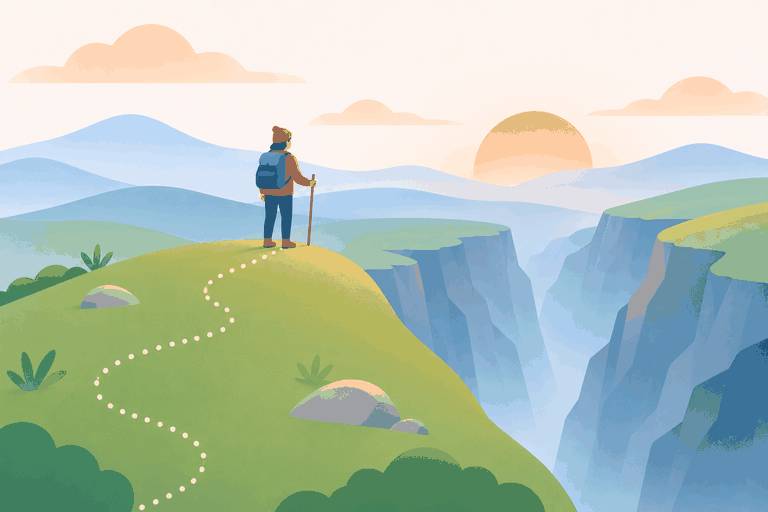
*(Ilustración generada con gpt-image-2.)*

In [ ]:
# El caso que sobreajusta: pocos datos, etiquetas con ruido y una red grande.
CFG_S10 = Config(id="s10-control", seccion=10, capas=[784, 256, 256, 10],
                 activacion="relu", optimizer="adam", lr=1e-3, batch=64,
                 epochs=80, idx_train=subconjunto(2000), ruido_etiquetas=0.2,
                 datos="2k-ruido20")

# Cuántos parámetros tiene la red: W^(l) tiene d_l · d_(l-1) entradas y
# b^(l) tiene d_l; la suma es θ.
anchos = CFG_S10.capas
n_parametros = sum(anchos[l] * anchos[l - 1] + anchos[l]
                   for l in range(1, len(anchos)))
print(f"red {anchos}: {n_parametros:,} parámetros")
print(f"ejemplos de train: {len(CFG_S10.idx_train):,}"
      f"  ({CFG_S10.ruido_etiquetas:.0%} con la etiqueta cambiada)")
print(f"parámetros por ejemplo de train: "
      f"{n_parametros / len(CFG_S10.idx_train):,.0f}")
dibujar_red(anchos, titulo="La red de §10: dos ocultas de 256")
plt.show()

**Apuesta.** Escribe tus respuestas antes de correr el entrenamiento.

- ¿Esperas que la loss de train baje en cada epoch?
- ¿La loss de validation seguirá bajando o llegará a un mínimo y luego subirá?
- Al final, entre los ejemplos con etiqueta cambiada, ¿en cuántos esperas que
  la red prediga la etiqueta falsa que vio durante train?

<details><summary>Respuesta</summary>

Esperamos que la loss de train baje mucho, con posibles repuntes entre
epochs. Al principio, la red aprende trazos que sirven para reconocer
dígitos nuevos y la loss de validation baja. Más adelante, esperamos que
la red repita muchas de las etiquetas falsas de train y que la loss de
validation suba.

Como vimos en §6, la accuracy (proporción de aciertos) de validation puede
cambiar poco aunque suba su loss. Si la red se equivoca en las mismas
imágenes pero con más confianza, la accuracy queda igual y la loss aumenta.
La intensidad de estas tendencias puede variar entre corridas.

</details>

In [ ]:
# 80 epochs SIN paciencia: queremos ver todo lo que pasa después del mejor
# momento. entrenar guarda dos checkpoints: el de la mejor epoch por loss de
# validation y el de la última.
corrida_s10 = entrenar(CFG_S10)
h10 = corrida_s10.historial
print(f"epochs corridas: {int(h10['epoch'].max())}")
print(f"mejor epoch por loss de validation: {corrida_s10.mejor_epoch:g}")

Primero entrenamos hasta completar el presupuesto de epochs. La celda
siguiente simula la parada sobre ese historial. Solo lee la loss de
validation, desde la evaluación de la red recién inicializada. Cuenta las
evaluaciones consecutivas sin un nuevo mínimo. Si aparece un nuevo mínimo,
reinicia el contador. Un empate cuenta como una evaluación sin mejora.

La primera vez que el contador alcanza la paciencia, esa es la epoch en la
que se habría detenido la corrida. Si el historial se acaba antes, la
simulación lo dice: la corrida no habría parado. Los pasos con mini-batches (lotes pequeños)
pueden hacer oscilar la loss de validation. La paciencia da margen para
que una subida aislada sea seguida por una mejora.

Si se activa la parada, la mejor epoch **hasta ese momento** quedó atrás.
Ese es el checkpoint que se restaura al usar early stopping. Casi siempre
coincide con el mínimo de toda la corrida; si validation volviera a
mejorar después de la parada, no coincidirían, y la celda lo avisa.

In [ ]:
def epoch_de_parada(historial, paciencia=6):
    """Dónde habría parado early stopping, simulado sobre un historial.

    Recorre las evaluaciones en orden y cuenta cuántas seguidas van sin
    mejorar el mínimo de la loss de validation (un empate no mejora). La
    primera vez que el contador llega a `paciencia`, ésa es la epoch de
    parada. Devuelve (epoch de parada, mejor epoch hasta ese momento); si el
    contador nunca llega, (None, mejor epoch). Solo lee validation.
    """
    mejor, mejor_epoch, sin_mejora = float("inf"), None, 0
    for _, fila in historial.iterrows():
        if fila["loss_validation"] < mejor:
            mejor, mejor_epoch, sin_mejora = fila["loss_validation"], fila["epoch"], 0
        else:
            sin_mejora += 1
            if sin_mejora == paciencia:
                return fila["epoch"], mejor_epoch
    return None, mejor_epoch


PACIENCIA = 6
parada_simulada, mejor_al_parar = epoch_de_parada(h10, PACIENCIA)
ultima_epoch = h10["epoch"].max()
print(f"mínimo de la loss de validation en las {ultima_epoch:g} epochs: "
      f"epoch {corrida_s10.mejor_epoch:g}")
if parada_simulada is None:
    print(f"paciencia {PACIENCIA}: nunca se agotó; la corrida no habría parado")
else:
    print(f"paciencia {PACIENCIA}: habría parado en la epoch {parada_simulada:g} "
          f"y restaurado la epoch {mejor_al_parar:g}")
    print(f"epochs ahorradas: {ultima_epoch - parada_simulada:g} de {ultima_epoch:g}")
    if mejor_al_parar != corrida_s10.mejor_epoch:
        print("ojo: después de la parada validation volvió a mejorar; early "
              "stopping se habría quedado con un mínimo anterior")

In [ ]:
def marcar_parada(ax, mejor, parada, ultima):
    """Línea en la mejor epoch, línea en la parada y sombra de lo ahorrado."""
    ax.axvline(mejor, color="black", ls="--", lw=1.2,
               label=f"mínimo de la loss de validation ({mejor:g})")
    if parada is not None:
        ax.axvline(parada, color="crimson", ls=":", lw=1.5,
                   label=f"paciencia {PACIENCIA} para aquí ({parada:g})")
        ax.axvspan(parada, ultima, color="crimson", alpha=0.08,
                   label="epochs que early stopping se ahorra")


fig, (ax_l, ax_a) = plt.subplots(1, 2, figsize=(13, 4.5))
# Solo train y validation: las curvas sirven para elegir, y test no elige.
curvas([corrida_s10], x="epoch", metrica="loss",
       conjuntos=("train", "validation"), ax=ax_l, titulo="Loss por epoch")
curvas([corrida_s10], x="epoch", metrica="accuracy",
       conjuntos=("train", "validation"), ax=ax_a,
       titulo="Accuracy por epoch (train contra las etiquetas alteradas)")
for ax in (ax_l, ax_a):
    marcar_parada(ax, corrida_s10.mejor_epoch, parada_simulada, ultima_epoch)
    ax.legend(fontsize=8)
fig.suptitle("§10 · 2000 ejemplos, 20 % de etiquetas alteradas, sin paciencia")
plt.tight_layout()
plt.show()

El panel de la izquierda muestra la loss y el de la derecha la accuracy.
Los dos muestran train y validation. La línea negra discontinua marca el
mínimo de la loss de validation en la corrida completa. Si la simulación
encontró una parada, la línea roja punteada la marca y la sombra indica
las epochs posteriores que se habrían ahorrado.

Busca el tramo donde la loss de train sigue bajando mientras la de
validation se estanca o sube. Es el mismo patrón de overfitting que
buscabas al variar el grado del polinomio. Aquí el eje horizontal cuenta
epochs. La accuracy de train se mide con las etiquetas que vio la red.
Si es muy alta, la red también está acertando etiquetas falsas.

La tabla y las barras comparan el mejor checkpoint y el último de la
corrida completa. Para cada uno, mira estas fracciones:

- Entre las etiquetas limpias, cuántas veces se predice la clase verdadera.
- Entre las etiquetas cambiadas, cuántas veces se repite la etiqueta falsa.
- En ese mismo grupo, cuántas veces se predice la clase verdadera.

Compara en especial la barra de las etiquetas falsas. Si crece del mejor
checkpoint al último, la red terminó memorizando más ruido.

In [ ]:
# Los 2000 ejemplos tal como los vio la red: datos_de_entrenamiento (de la
# caja) aplica el subconjunto y altera las etiquetas con la misma semilla que
# usó entrenar. Las etiquetas verdaderas siguen en DATOS.
X10, y10_ruido = datos_de_entrenamiento(CFG_S10)
X_tr, y_tr = DATOS[CFG_S10.escala]["train"]
idx10 = CFG_S10.idx_train.to(DEVICE)
idx10 = idx10[idx10 < len(X_tr)]            # igual que la caja (RAPIDO)
y10_limpia = y_tr[idx10]
alterada = y10_ruido != y10_limpia          # máscara: dónde se cambió
print(f"etiquetas alteradas: {int(alterada.sum())} de {len(y10_ruido)}")


@torch.no_grad()
def predecir(modelo, X):
    """La clase con el logit más grande (cargar ya deja la red en eval())."""
    return modelo(X).argmax(dim=1)


filas = []
for cual in ("mejor", "ultima"):
    pred = predecir(cargar(corrida_s10, cual), X10)
    filas.append({
        "checkpoint": cual,
        "limpias: acierta la verdadera":
            (pred[~alterada] == y10_limpia[~alterada]).float().mean().item(),
        "alteradas: repite la etiqueta falsa":
            (pred[alterada] == y10_ruido[alterada]).float().mean().item(),
        "alteradas: acierta la verdadera":
            (pred[alterada] == y10_limpia[alterada]).float().mean().item(),
    })
memoria = pd.DataFrame(filas).set_index("checkpoint")
display(memoria.round(3))

ax = memoria.T.plot.bar(figsize=(9, 4), rot=0, color=["#555555", "crimson"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("fracción de los ejemplos de train")
ax.set_title("¿Cuánto ruido memorizó la red? Mejor epoch vs última")
ax.legend(title="checkpoint")
plt.tight_layout()
plt.show()

`entrenar` guardó en CPU los checkpoints de la mejor epoch por loss de
validation y de la última epoch. `cargar` coloca los parámetros elegidos
en una red en `DEVICE` y activa el modo de evaluación con `eval()`.

La tabla vuelve a calcular loss y accuracy para los dos checkpoints.
Mide train en el subconjunto con las etiquetas usadas al entrenar.
Mide validation y test completos con las etiquetas verdaderas. Compara
estas métricas con las de las epochs correspondientes del historial.

En un proyecto, eliges el checkpoint con validation y usas test una sola
vez al final para reportar el resultado del modelo elegido. Como en §6,
el notebook registra test en cada epoch con fines didácticos. Aquí la
tabla muestra test para el mejor checkpoint y el último, para ver qué
puede costar seguir entrenando. La elección depende solo de validation.

Busca si el último checkpoint consigue una loss menor en train y una
mayor en validation y test. La accuracy puede moverse poco si el cambio
principal está en la confianza de las predicciones.

In [ ]:
# Restauramos los dos checkpoints y medimos cada uno desde cero con medir y
# evaluar de la caja. Train se mide sobre lo que la red vio: los 2000
# ejemplos con sus etiquetas alteradas. Validation y test, completos y limpios.
filas = []
for cual, epoch in (("mejor", corrida_s10.mejor_epoch), ("ultima", ultima_epoch)):
    modelo = cargar(corrida_s10, cual)
    l_tr, a_tr = medir(modelo, X10, y10_ruido)          # medir es de la caja
    l_va, a_va = evaluar(modelo, CFG_S10.escala, "validation")
    l_te, a_te = evaluar(modelo, CFG_S10.escala, "test")   # la única vez
    filas.append({"checkpoint": cual, "epoch": epoch,
                  "loss train": l_tr, "acc train": a_tr,
                  "loss validation": l_va, "acc validation": a_va,
                  "loss test": l_te, "acc test": a_te})
tabla_s10 = pd.DataFrame(filas).set_index("checkpoint")
display(tabla_s10.round(3))

Ahora repetimos el entrenamiento con la misma configuración y con
paciencia activada (`paciencia=6`). `entrenar` aplica la regla durante la corrida y
conserva el mejor checkpoint que encuentra. Si se agota la paciencia,
se ahorra el trabajo de las epochs restantes.

Las semillas fijan los pesos iniciales y el orden de los batches (lotes).
Esperamos que la parada real coincida con la simulada. Pequeñas
diferencias numéricas en GPU pueden moverla. La celda imprime ambos
resultados. La tabla pone el checkpoint que entrega early stopping junto
a los dos del control: debería parecerse al mejor del control y no al
último. La gráfica superpone las curvas de loss de validation; la línea
roja marca dónde se detuvo la corrida con paciencia. La tabla maestra
muestra las dos corridas.

In [ ]:
# La misma Config, ahora con paciencia real: entrenar para sola.
CFG_S10_P = Config(id="s10-paciencia", seccion=10, capas=[784, 256, 256, 10],
                   activacion="relu", optimizer="adam", lr=1e-3, batch=64,
                   epochs=80, idx_train=subconjunto(2000), ruido_etiquetas=0.2,
                   paciencia=PACIENCIA, datos="2k-ruido20")
corrida_s10_p = entrenar(CFG_S10_P)
hp = corrida_s10_p.historial
fin_p = hp["epoch"].max()
paro = bool(hp["parada_temprana"].iloc[-1])   # ¿se agotó la paciencia?
if paro:
    print(f"paciencia {PACIENCIA}: se detuvo sola en la epoch {fin_p:g}")
else:
    print(f"paciencia {PACIENCIA}: no se agotó; corrió todo el presupuesto "
          f"({fin_p:g} epochs)")
sim = "no para" if parada_simulada is None else f"epoch {parada_simulada:g}"
print(f"la simulación sobre s10-control decía: {sim}")
print(f"checkpoint que entrega: epoch {corrida_s10_p.mejor_epoch:g}")

# El modelo que de verdad entrega early stopping, junto a los del control.
modelo_p = cargar(corrida_s10_p, "mejor")
l_va, a_va = evaluar(modelo_p, CFG_S10.escala, "validation")
l_te, a_te = evaluar(modelo_p, CFG_S10.escala, "test")
fila_p = pd.DataFrame([{"epoch": corrida_s10_p.mejor_epoch,
                        "loss validation": l_va, "acc validation": a_va,
                        "loss test": l_te, "acc test": a_te}],
                      index=pd.Index(["con paciencia"], name="checkpoint"))
display(pd.concat([tabla_s10.drop(columns=["loss train", "acc train"]),
                   fila_p]).round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
curvas([corrida_s10, corrida_s10_p], x="epoch", metrica="loss",
       conjuntos=("validation",), ax=ax,
       titulo=f"Loss de validation: sin paciencia vs con paciencia {PACIENCIA}")
if paro:
    ax.axvline(fin_p, color="crimson", ls=":", lw=1.5, label="aquí se detuvo")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
display(tabla_maestra([10]))

**Qué viste.** Una red grande puede seguir mejorando en train mientras
empeora en validation. Si al final repite más etiquetas falsas de train,
la comparación de checkpoints muestra cuánto ruido llegó a memorizar.

Early stopping usa validation para elegir hasta dónde ajustar la red.
La paciencia da margen a las oscilaciones y el checkpoint recupera el
mejor estado alcanzado. Test queda para reportar al final.

En §9, weight decay (decaimiento de pesos) limita el ajuste al favorecer
pesos pequeños. Aquí lo limitamos con la duración del entrenamiento.
En §15 usaremos `s10-control` para ver si dropout (desactivación aleatoria
de neuronas) también reduce la memorización.

## 11 · El tamaño de la red

¿Qué pasa con la accuracy (proporción de aciertos) de validation si hacemos la red más ancha o más profunda? En la unidad 9, aumentar el grado $N$ de un polinomio le daba más capacidad para ajustar los datos. Aquí cambiamos el ancho $d_l$, que es el número de neuronas de la capa $l$, y la profundidad, que aquí cuenta las capas ocultas. En cada red, todas las capas ocultas tienen el mismo ancho $d$. La arquitectura es $[784,d,\ldots,d,10]$.

Como en la red 2–3–2–1 de la clase pasada, la capa $l$ tiene $d_l d_{l-1}$ pesos en $\mathbf W^{(l)}$ y $d_l$ sesgos en $\mathbf b^{(l)}$. En total hay $\sum_{l=1}^{L}(d_{l-1}+1)d_l$ parámetros, incluida la salida. Por ejemplo, $[784,2,10]$ tiene $785\cdot 2+3\cdot 10=1600$ parámetros. La primera celda muestra el conteo de toda la rejilla y lo comprueba con PyTorch para una de las redes.

Cruzamos los anchos 2, 16, 64, 256 y 1024 con 1, 2, 4 y 8 capas ocultas. Todas las redes usan el mismo subconjunto fijo de train, con el mismo número de imágenes de cada dígito, y se evalúan sobre toda validation. Todas usan ReLU, el optimizer Adam con learning rate $\eta=10^{-3}$, batch de 128 y cinco epochs. El subconjunto es de 20 000 imágenes de train, menos que las 50 000 disponibles, para que las 20 redes quepan en el tiempo de la clase.

Con la inicialización He, los pesos de la capa $l$ se sortean con varianza $2/d_{l-1}$. Para ReLU, esa escala ayuda a que la señal conserve su magnitud al inicio, algo especialmente importante cuando atraviesa varias capas.

Comparamos el rendimiento al final del mismo presupuesto de epochs. Con más entrenamiento, las redes podrían rendir de otra manera. El modo rápido recorta los datos y el entrenamiento.

In [ ]:
# (time, numpy, pandas, torch, nn y plt ya vienen del arranque, §1)
T0_S11 = time.perf_counter()          # reloj de toda la sección

ANCHOS = [2, 16, 64, 256, 1024]       # d_l: neuronas por capa oculta
PROFUNDIDADES = [1, 2, 4, 8]          # número de capas ocultas
if RAPIDO:                            # prueba en CPU: rejilla chica de 3 × 3
    ANCHOS, PROFUNDIDADES = [2, 16, 64], [1, 2, 4]


def capas_s11(ancho, prof):
    """[784, ancho, ..., ancho, 10] con `prof` capas ocultas iguales."""
    return [784] + [ancho] * prof + [10]


def contar_parametros(capas):
    """Cada capa l tiene una matriz W de d_l × d_{l-1} y d_l sesgos."""
    return sum((d_ant + 1) * d for d_ant, d in zip(capas[:-1], capas[1:]))


IDX_20K = subconjunto(20000)          # los mismos 20k ejemplos para las 20 redes


def config_s11(ancho, prof):
    """Una celda de la rejilla: todo igual salvo la forma de la red."""
    return Config(
        id=f"s11-a{ancho}-p{prof}", seccion=11,
        capas=capas_s11(ancho, prof), activacion="relu", init="he",
        optimizer="adam", lr=1e-3, batch=128, epochs=5,
        escala="estandar", idx_train=IDX_20K, datos="20k-limpio",
    )


# Conteo exacto, antes de entrenar nada: filas = profundidad, columnas = ancho
conteo = pd.DataFrame(
    [[contar_parametros(capas_s11(a, p)) for a in ANCHOS] for p in PROFUNDIDADES],
    index=pd.Index(PROFUNDIDADES, name="capas ocultas"),
    columns=pd.Index(ANCHOS, name="ancho"),
)
# comprobación: el conteo a mano coincide con el de PyTorch
red = construir_red(capas_s11(64, 2), init="he")
assert contar_parametros(capas_s11(64, 2)) == sum(t.numel() for t in red.parameters())
del red
print("Parámetros de cada red de la rejilla:")
display(conteo)

Escribe tu apuesta antes de ejecutar la celda siguiente.

1. ¿Qué combinación de ancho y profundidad tendrá la menor accuracy de validation?
2. ¿Subirá siempre la accuracy de validation al pasar de ancho 256 a 1024 o de 4 a 8 capas?
3. ¿Tendrá la red más grande, de ancho 1024 y 8 capas ocultas, la mayor brecha entre train y validation?

La celda entrena las 20 redes de la rejilla y puede tardar unos minutos en la T4.

In [ ]:
# 20 redes, de la más angosta y somera a la más ancha y profunda.
# entrenar() imprime una línea por red; las gráficas leen la ÚLTIMA epoch.
REJILLA = {}                          # (ancho, prof) -> Corrida
for prof in PROFUNDIDADES:
    for ancho in ANCHOS:
        REJILLA[(ancho, prof)] = entrenar(config_s11(ancho, prof))

Cada fila corresponde a una profundidad y cada columna a un ancho. Cada casilla muestra el último valor registrado para esa red.

- **Izquierda.** El color más claro indica mayor accuracy de validation. Empieza por la columna de ancho 2. Luego recorre una fila de izquierda a derecha y busca dónde empiezan a parecerse los colores.
- **Derecha.** La brecha se calcula restando la accuracy de validation a la de train. En rojo, la red acierta más en los ejemplos que usó para entrenar. En azul, acierta más en validation. El blanco indica una brecha cercana a cero.

Como en la unidad 9, una brecha positiva grande puede ser señal de overfitting (sobreajuste). Compara si la brecha crece con el ancho o la profundidad. Con un entrenamiento corto, puede ser pequeña en toda la rejilla.

In [ ]:
def matriz_s11(columna):
    """Matriz profundidad × ancho con el valor final (tras 5 epochs)."""
    M = np.full((len(PROFUNDIDADES), len(ANCHOS)), np.nan)
    for i, p in enumerate(PROFUNDIDADES):
        for j, a in enumerate(ANCHOS):
            h = REJILLA[(a, p)].historial
            M[i, j] = h[columna].iloc[-1]
    return M


def mapa_de_calor(M, ax, titulo, cmap, vmin, vmax, formato):
    im = ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(ANCHOS)), [str(a) for a in ANCHOS])
    ax.set_yticks(range(len(PROFUNDIDADES)), [str(p) for p in PROFUNDIDADES])
    ax.set_xlabel("ancho (neuronas por capa oculta)")
    ax.set_ylabel("profundidad (capas ocultas)")
    ax.set_title(titulo)
    ax.grid(False)
    for i in range(M.shape[0]):           # anota cada celda con su valor
        for j in range(M.shape[1]):
            v = M[i, j]
            texto = "—" if not np.isfinite(v) else format(v, formato)
            r, g, b, _ = im.cmap(im.norm(v)) if np.isfinite(v) else (1, 1, 1, 1)
            claro = 0.299 * r + 0.587 * g + 0.114 * b > 0.5   # fondo claro?
            ax.text(j, i, texto, ha="center", va="center", fontsize=9,
                    color="black" if claro else "white")
    plt.colorbar(im, ax=ax, shrink=0.8)


ACC_VAL = matriz_s11("acc_validation")
BRECHA = matriz_s11("acc_train") - ACC_VAL      # brecha train − validation
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
mapa_de_calor(ACC_VAL, ax1, "Accuracy de validation tras 5 epochs",
              "viridis", np.nanmin(ACC_VAL), np.nanmax(ACC_VAL), ".3f")
m = max(np.nanmax(np.abs(BRECHA)), 1e-3)        # escala simétrica alrededor de 0
mapa_de_calor(BRECHA, ax2, "Brecha de accuracy: train − validation",
              "RdBu_r", -m, m, "+.3f")
fig.suptitle("La rejilla ancho × profundidad (Adam 1e-3, init He, "
             + ("RAPIDO: datos y pasos recortados)" if RAPIDO
                else "20k de train, 5 epochs)"))
fig.tight_layout()
plt.show()

<details><summary>Respuesta</summary>

1. Busca las accuracies más bajas en la columna de ancho 2. La red de 8 capas puede tener más dificultades. Si una ReLU queda en cero para casi todos los ejemplos, por esa neurona tampoco pasa el gradiente para esos ejemplos. En una red estrecha, eso deja pocas rutas para la señal y el gradiente.
2. Es común que, a partir de cierto tamaño, añadir neuronas o capas cambie poco la accuracy de validation. Comprueba si aparece esa meseta. Con una sola corrida por red, otra semilla podría invertir el orden entre casillas cercanas.
3. La brecha puede crecer con el tamaño, aunque también puede seguir pequeña con este presupuesto. Con más epochs podría aumentar.

</details>

Cada punto es una red. Su altura indica la accuracy de validation y el número junto al punto indica el ancho. Cada línea reúne las redes con la misma profundidad. El eje horizontal usa escala logarítmica. Entre marcas consecutivas de potencias de diez, el conteo se multiplica por diez. Así se ven juntos conteos de miles y de millones de parámetros.

Busca si la accuracy sube al salir del ancho 2 y en qué tramo se aplana. Una línea casi horizontal indica que añadir muchos parámetros apenas cambió el resultado con este presupuesto. Compara también puntos de distintas líneas que queden cerca en el eje horizontal. Su altura muestra cómo rindieron redes de forma distinta con conteos parecidos.

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
colores_prof = plt.cm.viridis(np.linspace(0, 0.85, len(PROFUNDIDADES)))
for color, p in zip(colores_prof, PROFUNDIDADES):
    xs = [REJILLA[(a, p)].parametros for a in ANCHOS]
    ys = [REJILLA[(a, p)].historial["acc_validation"].iloc[-1] for a in ANCHOS]
    ax.plot(xs, ys, "o-", color=color, label=f"{p} capa(s) oculta(s)")
    for a, x, y in zip(ANCHOS, xs, ys):  # rotula cada punto con su ancho
        ax.annotate(f"{a}", (x, y), textcoords="offset points",
                    xytext=(4, -10), fontsize=8, color=color)
ax.set_xscale("log")
ax.set_xlabel("número de parámetros (escala log)")
ax.set_ylabel("accuracy de validation tras 5 epochs")
ax.set_title("¿Cuándo deja de servir agrandar la red?  (número = ancho)")
ax.legend(title="profundidad")
plt.show()

Una accuracy baja admite dos explicaciones. La red puede tener poca capacidad para representar lo que distingue a los dígitos. También puede ser difícil ajustar sus pesos con el presupuesto disponible. En una red profunda y estrecha, el gradiente tiene que atravesar muchas capas y una ReLU en cero puede cortarle el paso. El mapa reúne ambos efectos. En las secciones 13 y 14 miraremos el gradiente por capa para entender mejor la parte de optimización.

Los dibujos muestran cuatro redes de la rejilla. Sus pares de ancho y profundidad son $(2,1)$, $(64,2)$, $(1024,1)$ y $(64,8)$. Cada columna de nodos es una capa. Los puntos suspensivos indican que solo se dibujaron algunas neuronas. Debajo aparece el tamaño real de la capa. El título da el conteo de parámetros y la accuracy de validation. Ubica en la gráfica anterior la red más ancha y la de ocho capas. Compara sus conteos y sus accuracies.

In [ ]:
medio = ANCHOS[len(ANCHOS) // 2]      # 64 en la rejilla completa
EJEMPLOS = [(ANCHOS[0], PROFUNDIDADES[0], "la más chica"),       # [784, 2, 10]
            (medio, PROFUNDIDADES[1], "una mediana"),           # 64 × 2
            (ANCHOS[-1], PROFUNDIDADES[0], "la más ancha"),     # 1024 × 1
            (medio, PROFUNDIDADES[-1], "la más profunda")]      # 64 × 8
anchos_fig = [len(capas_s11(a, p)) for a, p, _ in EJEMPLOS]   # columnas de nodos
fig, axes = plt.subplots(1, 4, figsize=(18, 4.4),
                         gridspec_kw={"width_ratios": anchos_fig})
for ax, (a, p, nombre) in zip(axes, EJEMPLOS):
    c = REJILLA[(a, p)]
    val = c.historial["acc_validation"].iloc[-1]
    dibujar_red(capas_s11(a, p), ax=ax,
                titulo=f"{nombre}: {c.parametros:,} parámetros\n"
                       f"accuracy de validation {val:.3f}")
plt.show()

En $[784,2,10]$, toda la información de una imagen de 784 píxeles pasa por dos neuronas antes de que la salida decida entre los diez dígitos. Sus dos activaciones forman las coordenadas de un punto. Podemos dibujar un punto por cada imagen de validation y colorearlo por su dígito verdadero.

Reutilizamos esa red de la rejilla y entrenamos $[784,256,2,10]$ con los mismos datos y el mismo presupuesto. La capa de 256 neuronas puede aprender rasgos de la imagen antes de comprimirla en el cuello.

Cada fila muestra una red. A la izquierda están las dos preactivaciones $\mathbf z$, calculadas con los pesos y sesgos del cuello. A la derecha están las activaciones $\mathbf a=\operatorname{ReLU}(\mathbf z)$, los dos valores que recibe la capa de salida. La ReLU convierte los valores negativos en cero. Por eso pueden acumularse puntos en los ejes o en el origen. Si una neurona queda en cero para casi todas las imágenes, la salida depende casi siempre de la otra. La celda imprime la fracción de validation con cada neurona en cero y con ambas en cero, y cuántas imágenes de cada dígito caen en el origen. Los puntos se dibujan en orden aleatorio para que ningún dígito tape siempre a los demás; aun así, en el origen los puntos se enciman y esa cuenta dice qué hay debajo.

In [ ]:
# La red de ancho 2 y una capa oculta ya está en la rejilla: [784, 2, 10].
if "s11-a2-p1" not in CORRIDAS:      # por si se saltó la celda de la rejilla
    entrenar(config_s11(2, 1))
# Una segunda: primero 256 neuronas, luego el cuello de 2: [784, 256, 2, 10]
cfg = config_s11(2, 1)
cfg.id, cfg.capas = "s11-cuello-256", [784, 256, 2, 10]
entrenar(cfg)
CUELLOS = [CORRIDAS["s11-a2-p1"], CORRIDAS["s11-cuello-256"]]
for c in CUELLOS:
    print(f"{c.id:>15} {c.config.capas}  val "
          f"{c.historial['acc_validation'].iloc[-1]:.3f}")

In [ ]:
@torch.no_grad()
def activaciones_cuello(modelo, X):
    """Pasa X capa por capa y se detiene tras la activación que sigue a la
    capa lineal de 2 neuronas. Devuelve z (antes de la ReLU) y a (después)."""
    h, z = X, None
    for capa in modelo:
        if z is not None and isinstance(capa, nn.Linear):
            break                     # la siguiente lineal ya es la salida
        h = capa(h)
        if isinstance(capa, nn.Linear) and capa.out_features == 2:
            z = h                     # z: la combinación lineal del cuello
    return z.cpu().numpy(), h.cpu().numpy()


Xv, yv = DATOS["estandar"]["validation"]
digitos = yv.cpu().numpy()
orden = np.random.default_rng(SEMILLA).permutation(len(digitos))
# leyenda a mano: un punto de cada color
muestras = [plt.Line2D([], [], ls="", marker="o", color=plt.cm.tab10(d),
                       label=str(d)) for d in range(10)]
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for fila, c in zip(axes, CUELLOS):
    z, a = activaciones_cuello(cargar(c, "ultima"), Xv)
    for ax, M, que in [(fila[0], z, "z, antes de la ReLU"),
                       (fila[1], a, "a = ReLU(z), lo que ve la capa siguiente")]:
        # orden al azar: si dibujáramos dígito por dígito, el 9 taparía al 0
        ax.scatter(M[orden, 0], M[orden, 1], s=3, alpha=0.4,
                   c=plt.cm.tab10(digitos[orden]))
        ax.set_xlabel("neurona 1 del cuello")
        ax.set_ylabel("neurona 2 del cuello")
        ax.set_title(f"{c.config.capas}: {que}", fontsize=10)
    fila[1].legend(handles=muestras, title="dígito", fontsize=8, loc="best")
    ceros = (a == 0)
    print(f"{c.id}: neurona 1 en cero {ceros[:, 0].mean():.1%}, "
          f"neurona 2 en cero {ceros[:, 1].mean():.1%}, "
          f"las dos en cero {ceros.all(axis=1).mean():.1%} de validation")
    en_origen = np.bincount(digitos[ceros.all(axis=1)], minlength=10)
    print("   imágenes en el origen (0, 0), por dígito:", en_origen.tolist())
fig.suptitle("Validation vista por las dos neuronas del cuello (color = dígito)")
fig.tight_layout()
plt.show()

Si los colores ocupan regiones separadas, la salida tiene más información para distinguir esos dígitos. Si dos imágenes de dígitos distintos llegan al mismo punto en $\mathbf a$, reciben la misma predicción. Donde los colores se mezclan, distinguirlos puede ser más difícil.

Compara los paneles de $\mathbf z$ y $\mathbf a$. Dos puntos separados por un valor negativo pueden acabar en el mismo lugar cuando la ReLU pone ese valor en cero. Mira si la capa de 256 neuronas ayuda a separar los colores después de la ReLU. También puede haber acumulación en los ejes. Usa las fracciones de ceros para comprobar cuánto ocurre. Si casi todas las imágenes caen en el origen, la capa de salida recibe lo mismo para todas y la accuracy se queda cerca del 10 % del azar. Además, una ReLU en cero no deja pasar gradiente, así que esa red ya no puede salir de ahí: es una falla de optimización, no solo de capacidad.

El cuello ayuda a interpretar la columna de ancho 2 del mapa. En esas redes, cada capa oculta debe transmitir lo que sabe sobre la imagen en solo dos valores. La sección 12 pone un cuello similar entre dos capas anchas.

In [ ]:
filas = []
# las 20 de la rejilla (ordenadas por profundidad y ancho) y el cuello de 256
ordenadas = sorted(REJILLA, key=lambda k: (k[1], k[0]))
for c in [REJILLA[k] for k in ordenadas] + [CORRIDAS["s11-cuello-256"]]:
    final = c.historial.iloc[-1]                 # tras las 5 epochs
    filas.append({"id": c.id, "capas ocultas": c.config.capas[1:-1],
                  "parametros": c.parametros,
                  "acc train": final["acc_train"],
                  "acc validation": final["acc_validation"],
                  "brecha": final["acc_train"] - final["acc_validation"],
                  "segundos": final["segundos"], "divergio": c.divergio})
RESUMEN_S11 = pd.DataFrame(filas).set_index("id").round(4)
display(RESUMEN_S11)
print(f"Tiempo total de la sección 11: {time.perf_counter() - T0_S11:.0f} s")

Vuelve a tu apuesta. ¿En qué tramo ayudó agrandar la red? ¿Observaste algún tramo casi horizontal, donde agrandar ya no cambió la accuracy de validation? ¿Creció también la brecha con train? Con una sola semilla por arquitectura, toma las diferencias pequeñas como resultados de esta corrida. El cuello muestra qué información llega a la salida. La rejilla por sí sola deja abierta la pregunta de si una accuracy baja se debe a la capacidad o a la optimización.

La tabla reúne los parámetros, las accuracies finales de train y validation, la brecha y los segundos de entrenamiento. También indica si una corrida divergió. Son 21 filas: las 20 de la rejilla y la red $[784,256,2,10]$ del cuello. Debajo de la tabla se imprime el tiempo total de la sección.

En la sección 12 cambiaremos la forma de la red con un número de parámetros parecido.

## 12 · La forma de la red

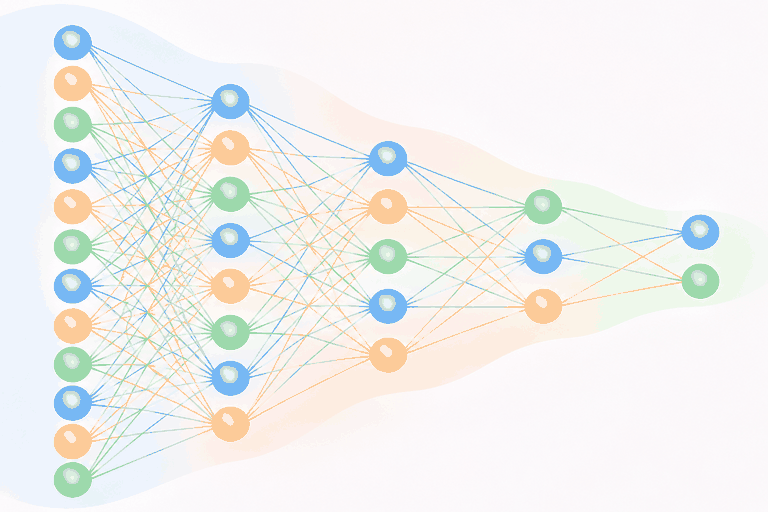
*(Ilustración generada con gpt-image-2.)*

En la sección 11 variamos el ancho y la profundidad para cambiar el tamaño de la red. Ahora damos a cada red casi el mismo presupuesto, alrededor de 102 mil parámetros. ¿Qué cambia si los repartimos de otra manera entre las capas? La ilustración muestra un embudo que se estrecha capa a capa.

Cada lista empieza con los 784 píxeles de entrada y termina con las 10 salidas, una por dígito. Los números intermedios son los anchos de las capas ocultas.

- **Embudo** `[784, 124, 32, 10]`
- **Embudo invertido** `[784, 96, 248, 10]`
- **Cuello de 2** `[784, 128, 2, 128, 10]`
- **Rectangular** `[784, 112, 112, 10]`
- **Una capa oculta** `[784, 128, 10]`

Como en la red que hicimos a mano, si la capa $l$ tiene ancho $d_l$, su matriz $\mathbf W^{(l)}$ tiene $d_l$ filas (neuronas de destino) y $d_{l-1}$ columnas (entradas de la capa). El vector $\mathbf b^{(l)}$ añade un sesgo por neurona. Al sumar pesos y sesgos de todas las capas obtenemos $\sum_{l=1}^{L} d_l\,(d_{l-1}+1)$ parámetros.

Por ejemplo, la red con una sola capa oculta tiene $128\cdot785 + 10\cdot129 = 100\,480 + 1\,290 = 101\,770$ parámetros. El código imprime los cinco conteos, término por término, y comprueba que coincidan con los de PyTorch. Luego dibuja las cinco redes. En el dibujo de arriba, una capa ancha se abrevia con «⋮» y su ancho real va debajo. Por eso abajo va también la silueta a escala de las capas ocultas y la salida: ahí se ven el embudo, el embudo invertido y el cuello. Fíjate en la primera capa oculta. Cada neurona recibe los 784 píxeles, así que esa capa concentra la mayor parte de los parámetros en las cinco redes.

En la unidad 9 variamos la capacidad del modelo con el grado del polinomio o con la penalización asociada a $\mu$ en el lagrangeano. Aquí veremos cómo dos redes con casi el mismo número de parámetros pueden tener distinta capacidad según dónde los coloquemos.

In [ ]:
# Las cinco formas. Cada lista incluye la entrada (784) y la salida (10).
FORMAS_S12 = {
    "s12-embudo": ("embudo", [784, 124, 32, 10]),
    "s12-invertido": ("embudo invertido", [784, 96, 248, 10]),
    "s12-cuello": ("cuello de 2", [784, 128, 2, 128, 10]),
    "s12-rectangular": ("rectangular", [784, 112, 112, 10]),
    "s12-una-capa": ("una capa", [784, 128, 10]),
}


def contar_parametros(capas):
    """Σ_l d_l·(d_{l-1} + 1): pesos de W^(l) más sesgos de b^(l), capa por capa."""
    return sum(capas[l] * (capas[l - 1] + 1) for l in range(1, len(capas)))


for id_corrida, (nombre, capas) in FORMAS_S12.items():
    # La fórmula, término por término, para que se vea de dónde sale el total
    terminos = " + ".join(f"{capas[l]}·({capas[l - 1]}+1)"
                          for l in range(1, len(capas)))
    total = contar_parametros(capas)
    # Comprobación: PyTorch cuenta lo mismo que la fórmula
    red = construir_red(capas, init="he")
    assert total == sum(p.numel() for p in red.parameters()), nombre
    print(f"{nombre:>17}  {str(capas):<24} {total:>7,} parámetros")
    print(f"{'':>17}  = {terminos}")
del red

In [ ]:
# Arriba, dibujar_red: columnas de nodos; una capa ancha se abrevia con «⋮»
# y su ancho real va debajo. Abajo, la silueta A ESCALA de las capas ocultas
# y la salida (la entrada de 784 se omite porque aplastaría a las demás):
# ahí sí se ven el embudo, el embudo invertido y el cuello.
fig, ejes = plt.subplots(2, 5, figsize=(20, 7),
                         gridspec_kw={"height_ratios": [3, 2]})
ancho_max = max(max(c[1:]) for _, c in FORMAS_S12.values())
for k, (nombre, capas) in enumerate(FORMAS_S12.values()):
    dibujar_red(capas, ax=ejes[0, k],
                titulo=f"{nombre}\n{contar_parametros(capas):,} parámetros")
    ax = ejes[1, k]
    anchos = capas[1:]                             # ocultas + salida
    etiquetas = [f"oculta {l}" for l in range(1, len(anchos))] + ["salida"]
    # Barra centrada en 0: su alto total es el ancho de la capa
    ax.bar(range(len(anchos)), anchos, bottom=[-d / 2 for d in anchos],
           color=COLORES["train"], alpha=0.6, edgecolor="black")
    for j, d in enumerate(anchos):
        ax.text(j, d / 2 + 6, str(d), ha="center", va="bottom", fontsize=9)
    ax.set_xticks(range(len(anchos)))
    ax.set_xticklabels(etiquetas, fontsize=8)
    ax.set_ylim(-ancho_max / 2 - 10, ancho_max / 2 + 35)
    ax.set_yticks([])
    ax.set_title("silueta a escala (neuronas por capa)", fontsize=9)
fig.suptitle("Cinco formas con casi el mismo número de parámetros", fontsize=14)
fig.tight_layout()
plt.show()

**Apuesta.** Antes de entrenar, escribe qué forma crees que tendrá la mayor *accuracy* (proporción de aciertos) de validation y cuál tendrá la menor. Justifica tu apuesta en una frase.

En la red con cuello, las capas posteriores reciben solo dos números para distinguir qué dígito había en la imagen. ¿Qué información necesitarían conservar esos números?

Las cinco redes usan Adam con el mismo learning rate $\eta$, el mismo tamaño de batch y el mismo número de epochs. Todas usan ReLU en las capas ocultas e inicialización de He, que ajusta la escala de los pesos iniciales al ancho de entrada de cada capa. También fijamos las semillas de inicialización y del orden de los batches.

Usamos el mismo subconjunto estratificado de train que en la sección 11. Así mantenemos representados todos los dígitos. Evaluamos con validation y test completos. Al mantener la receta de entrenamiento fija, podemos estudiar el efecto de la forma con un presupuesto casi constante.

Otra semilla podría cambiar el orden entre formas con resultados parecidos. Es posible que varias rindan casi igual. Con estas corridas podemos describir las diferencias que veamos.

Por cada corrida, `entrenar` imprime una línea con sus parámetros, sus pasos, su mejor epoch y su accuracy de validation en esa mejor epoch, que es la de menor loss de validation, no necesariamente la última. También imprime cuánto tardó. La tabla maestra registra las cinco corridas con los IDs `s12-embudo`, `s12-invertido`, `s12-cuello`, `s12-rectangular` y `s12-una-capa`.

In [ ]:
# Las cinco con exactamente la misma receta: lo único que cambia es la forma.
IDX_S12 = subconjunto(20000)    # el mismo subconjunto estratificado de §11

for id_corrida, (nombre, capas) in FORMAS_S12.items():
    # entrenar imprime una línea por corrida: parámetros, pasos, mejor epoch,
    # accuracy de validation en esa epoch y segundos
    entrenar(Config(
        id=id_corrida, seccion=12,
        capas=capas, activacion="relu", init="he",
        optimizer="adam", lr=1e-3, batch=128, epochs=8,
        idx_train=IDX_S12, datos="20k-limpio",
        semilla_init=SEMILLA, semilla_orden=SEMILLA,   # mismas semillas para todas
    ))

CORRIDAS_S12 = [CORRIDAS[i] for i in FORMAS_S12]

Hay una rejilla de *loss* (pérdida) y otra de accuracy. Cada panel corresponde a una forma. Dentro de cada rejilla, todos los paneles comparten la escala vertical. Puedes comparar alturas para la misma epoch. Azul es train, naranja es validation y verde es test.

Primero compara las curvas naranjas. ¿Quedan cerca las cuatro formas sin cuello? Luego mira el cuello de 2. Busca si tiene mayor loss y menor accuracy también en train. Un ajuste pobre desde train es una señal de *underfitting* (subajuste), como cuando un polinomio de grado bajo tenía demasiado sesgo en la unidad 9. Dentro de cada panel, fíjate también en cuánto se separan las curvas de train y validation.

Mirar test en cada epoch está mal. Test se usa una sola vez, al final, para reportar. Aquí lo graficamos solo para aprender a leer las curvas. Para elegir la mejor epoch y comparar modelos usamos validation.

In [ ]:
# Small multiples: un panel por forma, el mismo eje y en todos para poder
# comparar alturas a simple vista. Test aparece solo de manera didáctica.
for metrica, nombre_metrica in [("loss", "Loss"), ("accuracy", "Accuracy")]:
    fig = rejilla(CORRIDAS_S12, x="epoch", metrica=metrica, columnas=5,
                  misma_y=True)
    for ax, (nombre, capas) in zip(fig.axes, FORMAS_S12.values()):
        ax.set_title(f"{nombre}\nocultas {capas[1:-1]}", fontsize=10)
    # La leyenda común solo nombra el conjunto: el color es lo que importa
    for leyenda in fig.legends:
        leyenda.remove()
    fig.legend(handles=[plt.Line2D([], [], color=COLORES[c], marker="o", label=c)
                        for c in ("train", "validation", "test")],
               loc="upper right", fontsize=9)
    fig.suptitle(f"{nombre_metrica} por epoch de las cinco formas "
                 "(mismo eje y en los cinco paneles)", fontsize=13)
    fig.tight_layout(rect=(0, 0, 0.93, 1))
    plt.show()

In [ ]:
# Resumen en la mejor epoch de cada corrida, elegida por la loss de
# validation (nunca por test). La tabla maestra ya trae accuracy de train y
# de validation en esa epoch, y la brecha = acc_train − acc_validation.
TABLA_S12 = tabla_maestra([12]).set_index("id").loc[list(FORMAS_S12)]
RESUMEN_S12 = pd.DataFrame({
    "forma": [FORMAS_S12[i][0] for i in TABLA_S12.index],
    "ocultas": [str(FORMAS_S12[i][1][1:-1]) for i in TABLA_S12.index],
    "parametros": TABLA_S12["parametros"].to_numpy(),
    "mejor_epoch": TABLA_S12["mejor_epoch"].to_numpy(),
    "acc_validation_%": 100 * TABLA_S12["acc_validation"].to_numpy(),
    "brecha_pp": 100 * TABLA_S12["brecha"].to_numpy(),   # puntos porcentuales
})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
x = range(len(RESUMEN_S12))
b1 = ax1.bar(x, RESUMEN_S12["acc_validation_%"], color=COLORES["validation"])
ax1.bar_label(b1, fmt="%.2f")
ax1.set_ylim(0, 105)                 # empieza en cero: no exagera diferencias
ax1.set_ylabel("accuracy de validation (%)")
ax1.set_title("Accuracy de validation en la mejor epoch")
b2 = ax2.bar(x, RESUMEN_S12["brecha_pp"], color="#7f7f7f")
ax2.bar_label(b2, fmt="%.2f")
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_ylabel("train − validation (puntos porcentuales)")
ax2.set_title("Brecha de accuracy en la mejor epoch")
for ax in (ax1, ax2):
    ax.set_xticks(list(x))
    ax.set_xticklabels(RESUMEN_S12["forma"], rotation=15)
    ax.set_xlabel("forma de la red")
fig.tight_layout()
plt.show()

In [ ]:
# Los mismos números en una tabla (accuracy en %, brecha en puntos
# porcentuales), y debajo las filas de §12 de la tabla maestra completa.
print(RESUMEN_S12.round(2).to_string(index=False))
print()
print(TABLA_S12.reset_index().round(4).to_string(index=False))

<details><summary>Respuesta</summary>

Esperamos que el embudo, el embudo invertido, la red rectangular y la de una sola capa oculta queden cerca en validation. El orden entre ellas puede cambiar con la semilla. Esperamos que la red con cuello tenga más dificultades tanto en train como en validation.

Cada imagen debe pasar por las dos activaciones del cuello. ReLU puede llevar una o ambas a cero. Si dos imágenes de dígitos distintos quedan representadas por el mismo par de números, todas las capas siguientes reciben la misma entrada y producen la misma predicción. Recuerda la gráfica de la sección 11. Allí cada punto representaba una imagen mediante dos activaciones. Busca las zonas donde se mezclan los colores de distintos dígitos.

Un matiz: el cuello no solo es angosto, también es más profundo, con tres capas ocultas en vez de una o dos. Si queda abajo, parte puede deberse a que es más difícil de optimizar, no solo a la información que se pierde; estas curvas solas no separan las dos causas. Si el cuello quedó cerca de las demás formas en tu corrida, registra esa observación. La gráfica muestra cuánto se distinguieron con esta receta y esta semilla.

</details>

Para leer las barras, ubica primero la epoch que se eligió con validation en cada corrida. La barra naranja muestra la accuracy de validation en esa epoch y su escala empieza en cero. La barra gris muestra la brecha de accuracy en la misma epoch, train menos validation, en puntos porcentuales. Los valores aparecen en las etiquetas y en la tabla.

Compara con tu apuesta. ¿Quedaron cerca las barras de accuracy y de brecha de las cuatro formas sin cuello? Si el cuello quedó abajo tanto en train como en validation, el patrón apunta a underfitting. Una brecha pequeña también puede darse cuando ambos conjuntos tienen pocos aciertos.

Para estos MLP en MNIST, la accuracy de validation y la brecha pueden variar poco entre las formas sin cuello. Compara esas diferencias con las que viste al cambiar el tamaño de la red o la receta de entrenamiento. Un cuello estrecho puede dificultar el ajuste aunque el presupuesto total sea parecido: el número de parámetros no lo dice todo, importa también por dónde tiene que pasar la información. Si dos formas quedaron casi empatadas, habría que repetir con varias semillas para saber si la diferencia se sostiene.

## 13 · Activaciones

En la red 2–3–2–1 de la clase 1, cada capa oculta hacía dos operaciones.
Primero calculaba la preactivación
$\mathbf z^{(l)}=\mathbf W^{(l)}\mathbf a^{(l-1)}+\mathbf b^{(l)}$.
Luego aplicaba $g^{(l)}$ a cada componente para obtener
$\mathbf a^{(l)}=g^{(l)}(\mathbf z^{(l)})$. Sin esas funciones no lineales,
toda la red se reduciría a una sola transformación afín.

- **ReLU**, la de las capas ocultas de la clase 1, es $g(z)=\max(0,z)$.
- **Sigmoide**, la de la regresión logística de la unidad 9, es
  $\sigma(z)=1/(1+e^{-z})$.
- **tanh** es $g(z)=\tanh(z)=(e^z-e^{-z})/(e^z+e^{-z})$.
- **GELU** es $g(z)=z\,\Phi(z)$, donde $\Phi$ es la función de distribución
  acumulada de la normal estándar. Se parece a una ReLU suave.

Las cuatro redes reciben los 784 píxeles, tienen seis capas ocultas de 128
neuronas y entregan diez logits. Empiezan con los mismos pesos, inicializados
con matrices ortogonales, y sesgos en cero. Cambia la activación de las capas
ocultas. Usaremos esta arquitectura también en §14 y §15.

Primero mira las funciones y sus derivadas. Después compara los gradientes y
las activaciones al inicio. Al final, compara cómo arrancan las curvas de
entrenamiento.

In [ ]:
# Las cuatro activaciones g(z) y sus derivadas g'(z). Las derivadas NO las
# escribimos a mano: se las pedimos a autograd, el mismo mecanismo que hace
# backpropagation en todo el notebook.
import math
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch import nn
import matplotlib.pyplot as plt

ACTIVACIONES_S13 = ["relu", "sigmoide", "tanh", "gelu"]
FUNCIONES_S13 = {"relu": F.relu, "sigmoide": torch.sigmoid,
                 "tanh": torch.tanh, "gelu": F.gelu}
# Un color por activación (no usamos azul/naranja/verde: son train/val/test).
COLOR_ACT_S13 = {"relu": "#d62728", "sigmoide": "#9467bd",
                 "tanh": "#8c564b", "gelu": "#e377c2"}

z = torch.linspace(-6, 6, 1201, requires_grad=True)
fig, ejes = plt.subplots(2, 4, figsize=(15, 6), sharex=True)
for col, nombre in enumerate(ACTIVACIONES_S13):
    g = FUNCIONES_S13[nombre](z)
    (derivada,) = torch.autograd.grad(g.sum(), z)  # g'(z) en cada punto
    zz, gg, dd = z.detach().numpy(), g.detach().numpy(), derivada.numpy()
    color = COLOR_ACT_S13[nombre]
    ejes[0, col].plot(zz, gg, color=color, lw=2)
    ejes[0, col].set_title(f"{nombre}: g(z)")
    ejes[1, col].plot(zz, dd, color=color, lw=2)
    ejes[1, col].set_title(f"{nombre}: g'(z)   (máx ≈ {dd.max():.3f})")
    ejes[1, col].set_xlabel("preactivación z")
    ejes[1, col].set_ylim(-0.15, 1.25)
    for fila in range(2):
        ejes[fila, col].axhline(0, color="gray", lw=0.8)
        ejes[fila, col].axvline(0, color="gray", lw=0.8)
# La cota analítica de la sigmoide: σ'(z) = σ(z)(1 − σ(z)) ≤ 1/4, en z = 0.
ejes[1, 1].axhline(0.25, color="black", ls="--", lw=1, label="¼")
ejes[1, 1].legend(loc="upper right")
ejes[0, 0].set_ylabel("g(z)")
ejes[1, 0].set_ylabel("g'(z)")
fig.suptitle("Las cuatro activaciones (arriba) y sus derivadas (abajo)")
plt.tight_layout()
plt.show()

for nombre in ACTIVACIONES_S13:
    zg = torch.linspace(-6, 6, 1201, requires_grad=True)
    (d,) = torch.autograd.grad(FUNCIONES_S13[nombre](zg).sum(), zg)
    print(f"{nombre:9s} máx g'(z) en [-6, 6] = {d.max().item():.4f}")
print("sigmoide: cota analítica ¼ =", 0.25)

Cada columna muestra una activación. Arriba está $g(z)$ y abajo, su pendiente
$g'(z)$. PyTorch calcula las pendientes con autograd, el mismo mecanismo que
usa para backpropagation. El código imprime el máximo que encuentra entre los
puntos graficados.

- **Sigmoide.** Si $p=\sigma(z)$, entonces $\sigma'(z)=p(1-p)$. El producto
  alcanza su máximo en $p=\tfrac12$, cuando $z=0$. Vale $\tfrac14$, el nivel de
  la línea punteada. Lejos de cero la curva se aplana y la pendiente se acerca
  a cero. A esto le llamamos saturación.
- **tanh.** También se satura lejos de cero. Su curva es simétrica respecto
  al origen. La pendiente $1-\tanh^2(z)$ llega a $1$ en $z=0$.
- **ReLU.** La pendiente vale $0$ si $z<0$ y $1$ si $z>0$. PyTorch toma
  $g'(0)=0$. Una neurona activa, con $z>0$, deja pasar el gradiente con su
  pendiente de $1$.
- **GELU.** Su pendiente cambia suavemente. En parte del lado negativo es
  un poco menor que cero. En parte del lado positivo supera $1$.

Recuerda la regla de la cadena de la clase 1. Para una observación,
$\mathbf{δ}^{(l)}=\nabla_{\mathbf z^{(l)}}\ell$ es el error que llega a la
preactivación de la capa $l$. En una capa oculta se calcula así.

$$
\mathbf{δ}^{(l)}
=\bigl((\mathbf W^{(l+1)})^\top\mathbf{δ}^{(l+1)}\bigr)
\odot g^{(l)\prime}(\mathbf z^{(l)}).
$$

Primero la matriz transpuesta lleva la señal a la capa anterior. Después
$\odot$ multiplica cada componente por la pendiente de su activación. Con la
sigmoide, este segundo paso deja como máximo una cuarta parte de la norma de
la señal que entregó la matriz.

Al inicio, las matrices de esta red tienen filas ortonormales, incluso
las rectangulares. Así, la transpuesta de cada una conserva la norma del
vector que recibe. La norma espectral $\lVert\mathbf W^{(l)}\rVert_2$ mide
cuánto puede amplificar un vector la matriz o su transpuesta. El código
imprime esas normas y las usa al calcular la cota.

Al pasar hacia atrás por seis capas ocultas con sigmoide, la cota al inicio
es $\lVert\mathbf{δ}^{(1)}\rVert_2\le(\tfrac14)^6
\lVert\mathbf{δ}^{(7)}\rVert_2$, con normas espectrales unitarias. La
atenuación puede ser mayor si las pendientes están por debajo de
$\tfrac14$. Esto es *vanishing gradient* (desvanecimiento del gradiente).
ReLU y tanh también pueden atenuar la señal, aunque su pendiente máxima de
$1$ permite que pase entera en algunas componentes.

El gradiente de los pesos también incluye la activación que entra a la capa.
Para una observación,
$\nabla_{\mathbf W^{(l)}}\ell=\mathbf{δ}^{(l)}(\mathbf a^{(l-1)})^\top$.
Con un mismo learning rate $\eta$, un gradiente de pesos pequeño produce
un cambio pequeño en esos pesos.

Escribe tus dos apuestas antes de seguir.

1. Antes del primer paso, ¿qué activación dará el menor gradiente de los pesos
   en la capa 1, la más cercana a la entrada?
2. Al terminar el presupuesto de pasos, ¿qué activación tendrá la mayor loss
   de validation?

Abre la respuesta plegada después de ver las gráficas y la tabla.

In [ ]:
# Cuatro redes iguales salvo la activación: 784 → 6 × 128 → 10, pesos
# ortogonales y sesgos en cero. Con la misma semilla, los pesos iniciales
# son los mismos en las cuatro: así la única diferencia es g.
REDES_INICIALES_S13 = {}
for nombre in ACTIVACIONES_S13:
    cfg = config_profunda(nombre)
    torch.manual_seed(cfg.semilla_init)
    REDES_INICIALES_S13[nombre] = construir_red(
        cfg.capas, activacion=cfg.activacion, init=cfg.init).to(DEVICE)

CAPAS_S13 = config_profunda("relu").capas
print("capas:", CAPAS_S13)
print(REDES_INICIALES_S13["sigmoide"])


def lineales(red):
    """Las capas nn.Linear de la red, en orden: W^(1), …, W^(L)."""
    return [m for m in red.modules() if isinstance(m, nn.Linear)]


ref = lineales(REDES_INICIALES_S13["relu"])
for nombre in ACTIVACIONES_S13[1:]:
    otras = lineales(REDES_INICIALES_S13[nombre])
    iguales = all(torch.equal(a.weight, b.weight) for a, b in zip(ref, otras))
    print(f"¿pesos iniciales de {nombre} == los de relu? {iguales}")
print("sesgos iniciales en cero:",
      all(bool((m.bias == 0).all()) for m in ref))
# Norma espectral de cada W: con init ortogonal de ganancia 1 vale 1. Las
# filas son ortonormales, así que W transpuesta (la que usa backpropagation)
# conserva la norma de cualquier vector; W en sí nunca estira.
print("‖W^(l)‖₂ por capa:",
      [round(torch.linalg.matrix_norm(m.weight.detach(), ord=2).item(), 3)
       for m in ref])

dibujar_red(CAPAS_S13, titulo="La red profunda de §13–§15: 6 ocultas de 128")
plt.show()

Tomamos un batch fijo de train y pasamos las mismas imágenes por las cuatro
redes. En el forward, `retain_grad()` le pide a PyTorch que conserve el
gradiente de cada preactivación. Calculamos la cross-entropy promedio del
batch, $L_{\mathcal B}$, y llamamos una vez a `backward()` por red. Los pesos
siguen en sus valores iniciales.

En el notebook 01, cada observación era una columna. En PyTorch es una fila.
En una capa oculta, `z.grad` tiene una fila por imagen y una columna por
neurona. Cada fila contiene el $\mathbf{δ}^{(l)}_k$ de esa imagen,
multiplicado por $1/\lvert\mathcal B\rvert$ porque la loss es un promedio.

Medimos dos normas por capa.

- $\lVert\nabla_{\mathbf W^{(l)}}L_{\mathcal B}\rVert_F$ resume el tamaño del
  gradiente que usaría el optimizer para actualizar los pesos.
- La norma de Frobenius de `z.grad` mide el tamaño de la señal que pasa
  hacia atrás en todo el batch.

La tabla muestra la primera norma. Las filas son las capas, de la 1 junto a
la entrada a la 7 de salida. Las columnas son las cuatro activaciones.

In [ ]:
# Un batch FIJO de train (las mismas imágenes para las cuatro redes).
X_tr, y_tr = DATOS[config_profunda("relu").escala]["train"]
gen = torch.Generator().manual_seed(SEMILLA)
N_BATCH_S13 = 128 if RAPIDO else 512
idx = torch.randperm(len(y_tr), generator=gen)[:N_BATCH_S13].to(DEVICE)
xb, yb = X_tr[idx], y_tr[idx]


def recorrer(red, x):
    """Forward capa por capa. Guarda cada preactivación z^(l) (salida de una
    Linear) y cada activación a^(l) = g(z^(l)) (salida de la no linealidad)."""
    zs, activaciones = [], []
    for modulo in red:
        x = modulo(x)
        if isinstance(modulo, nn.Linear):
            if x.requires_grad:        # (dentro de no_grad no hay gradiente)
                x.retain_grad()        # queremos δ^(l) = ∂L/∂z^(l) al final
            zs.append(x)
        elif not isinstance(modulo, (nn.Dropout, nn.BatchNorm1d, nn.Identity)):
            activaciones.append(x)
    return x, zs, activaciones


filas = []
for nombre, red in REDES_INICIALES_S13.items():
    red.eval()                          # sin dropout ni BN: no cambia nada
    red.zero_grad()
    logits, zs, _ = recorrer(red, xb)
    perdida = nn.functional.cross_entropy(logits, yb)
    perdida.backward()                  # backpropagation: la regla de la cadena
    for l, (lin, z_l) in enumerate(zip(lineales(red), zs), start=1):
        filas.append({"activacion": nombre, "capa": l,
                      "norma_grad_W": lin.weight.grad.norm().item(),
                      "norma_delta": z_l.grad.norm().item()})
    red.zero_grad()                     # no dejamos gradientes colgados
DIAG_S13 = pd.DataFrame(filas)
tabla = DIAG_S13.pivot(index="capa", columns="activacion",
                       values="norma_grad_W")[ACTIVACIONES_S13]
print("‖∇_W^(l) L‖ antes del primer paso (filas = capa l, "
      "columnas = activación):")
display(tabla.map(lambda v: f"{v:.2e}"))

In [ ]:
# Barras agrupadas: una por capa, una serie por activación, eje y en log.
n_capas = DIAG_S13["capa"].max()
ancho = 0.2
fig, (ax_w, ax_d) = plt.subplots(1, 2, figsize=(15, 4.8))
for k, nombre in enumerate(ACTIVACIONES_S13):
    d = DIAG_S13[DIAG_S13["activacion"] == nombre]
    pos = d["capa"] + (k - 1.5) * ancho
    ax_w.bar(pos, d["norma_grad_W"], ancho, color=COLOR_ACT_S13[nombre],
             label=nombre)
    ax_d.bar(pos, d["norma_delta"], ancho, color=COLOR_ACT_S13[nombre],
             label=nombre)

# La cota de la sigmoide sobre δ: cada capa oculta multiplica por ≤ ¼ y por
# ‖W‖₂ (≈ 1 con init ortogonal). Se parte del δ real de la salida.
sig = DIAG_S13[DIAG_S13["activacion"] == "sigmoide"].set_index("capa")
normas_W = [torch.linalg.matrix_norm(m.weight.detach(), ord=2).item()
            for m in lineales(REDES_INICIALES_S13["sigmoide"])]
cota = {n_capas: sig.loc[n_capas, "norma_delta"]}
for l in range(n_capas - 1, 0, -1):
    cota[l] = cota[l + 1] * normas_W[l] * 0.25   # normas_W[l] es W^(l+1)
capas_cota = sorted(cota)
ax_d.plot(capas_cota, [cota[l] for l in capas_cota], "k--", marker="o",
          label="cota sigmoide: × ¼ por capa")

for ax, titulo in [(ax_w, "‖∇ de W^(l)‖ al inicio"),
                   (ax_d, "‖δ^(l)‖ = ‖∂L/∂z^(l)‖ al inicio")]:
    ax.set_yscale("log")
    ax.set_xticks(range(1, n_capas + 1))
    ax.set_xlabel("capa l   (1 = junto a la entrada, "
                  f"{n_capas} = la de salida)")
    ax.set_ylabel("norma (escala log)")
    ax.set_title(titulo)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

for nombre in ACTIVACIONES_S13:
    d = DIAG_S13[DIAG_S13["activacion"] == nombre].set_index("capa")
    r = d.loc[1, "norma_delta"] / d.loc[n_capas, "norma_delta"]
    print(f"{nombre:9s} ‖δ^(1)‖ / ‖δ^({n_capas})‖ = {r:.2e}")
print(f"cota analítica de la sigmoide: (¼)^6 = {0.25 ** 6:.2e} "
      f"(× ∏‖W‖₂ = {math.prod(normas_W[1:]):.3f})")

En cada panel, sigue las barras de un mismo color de derecha a izquierda,
de la salida a la entrada. La escala vertical es logarítmica. Bajar una
potencia de diez significa dividir la norma entre diez.

En el panel derecho, la línea negra discontinua parte del error medido a
la salida de la red con sigmoide. Por cada capa hacia la entrada, multiplica
por $\tfrac14$ y por la norma espectral de la matriz transpuesta. Las barras
moradas quedan en esa cota o por debajo, salvo redondeo. Busca una caída más
pronunciada para la sigmoide. El código imprime, para cada activación, la
razón entre las normas del error en la capa 1 y en la salida. Compara la
razón de la sigmoide con $(\tfrac14)^6$. La cota también vale para las
normas del batch.

El panel izquierdo muestra los gradientes de los pesos. Ahí también
intervienen las activaciones de la capa anterior. Usa el panel derecho para
comprobar la cota.

In [ ]:
# Las activaciones a^(l) de cada capa oculta, con la red recién creada y el
# mismo batch fijo. Filas = activación, columnas = capa oculta l = 1…6.
with torch.no_grad():
    salidas = {n: recorrer(r, xb)[2] for n, r in REDES_INICIALES_S13.items()}
n_ocultas = len(salidas["relu"])
fig, ejes = plt.subplots(len(ACTIVACIONES_S13), n_ocultas,
                         figsize=(2.4 * n_ocultas, 8), sharex="row")
for i, nombre in enumerate(ACTIVACIONES_S13):
    for l, a in enumerate(salidas[nombre], start=1):
        ax = ejes[i, l - 1]
        valores = a.flatten().cpu().numpy()
        ax.hist(valores, bins=40, color=COLOR_ACT_S13[nombre])
        ax.set_yticks([])
        ax.tick_params(labelsize=7)
        if i == 0:
            ax.set_title(f"capa oculta {l}", fontsize=9)
        if l == 1:
            ax.set_ylabel(nombre, fontsize=10)
        ax.text(0.97, 0.9, f"desv {valores.std():.2f}", fontsize=7,
                ha="right", transform=ax.transAxes)
fig.suptitle("Histogramas de a^(l) = g(z^(l)) con la red inicial "
             "(un batch fijo de train)")
fig.supxlabel("valor de la activación")
plt.tight_layout()
plt.show()
del salidas

Cada fila usa una función de activación. Cada columna corresponde a una
capa oculta. Un histograma reúne los valores de todas las neuronas de esa
capa para el mismo batch de train, antes del primer paso. Compara la
desviación estándar impresa de izquierda a derecha para ver si la
dispersión se reduce o se mantiene.

- **Sigmoide.** Busca salidas positivas agrupadas cerca de $\tfrac12$.
  Allí la pendiente está cerca de su máximo y aun así vale a lo sumo
  $\tfrac14$.
- **tanh.** Mira si las salidas se agrupan alrededor de cero y cómo cambia
  su dispersión.
- **ReLU.** Busca el pico en cero. Ahí caen las neuronas apagadas, que
  tienen pendiente cero.
- **GELU.** Busca también valores negativos pequeños. La transición
  alrededor de cero es suave.

Las preactivaciones determinan en qué tramo de $g$ cae cada neurona y cuánta
señal deja pasar su pendiente. En §15 veremos *batch normalization*
(normalización por batch), que usa estadísticas del batch para centrar y
reescalar preactivaciones durante el entrenamiento.

Ahora entrenamos las cuatro redes con `config_profunda`. Usamos SGD sin
momentum, con el mismo learning rate, el mismo orden de batches y el mismo
presupuesto de pasos. En modo normal, el presupuesto cubre poco más de una
epoch. La pregunta es cuál empieza a aprender en ese tramo. El código
imprime cuántos pasos completó cada corrida y guarda la norma del gradiente
de cada capa en cada paso; la usamos después de las curvas.

Los paneles de `s13-relu`, `s13-sigmoide`, `s13-tanh` y `s13-gelu`
comparten ejes. El eje horizontal cuenta pasos de SGD. Al inicio y conforme
avanza el entrenamiento, el código evalúa train, validation y test sobre
todos los ejemplos cargados de cada conjunto. La línea punteada marca
$\log 10$ en la gráfica de loss, el valor de asignar probabilidad uniforme
a los diez dígitos. En accuracy, marca el $10\,\%$ esperado al adivinar
al azar.

Mirar test en cada evaluación está mal. En un proyecto, test se usa una
sola vez, al final. Aquí lo mostramos solo para aprender a leer las curvas.
Todas las comparaciones de desempeño para decidir usan validation.

Puede que una red se quede cerca de la referencia del azar durante toda
la corrida. También puede que ReLU, tanh y GELU queden cerca entre sí. Para
la segunda apuesta, consulta la columna de loss de validation final.

In [ ]:
# Las cuatro redes, ~500 pasos de SGD (η = 0.03, sin momentum) con batches
# de 128. Evaluamos train/validation/test completos cada 50 pasos.
CORRIDAS_S13 = {}
for nombre in ACTIVACIONES_S13:
    cfg = config_profunda(nombre, id=f"s13-{nombre}", seccion=13,
                          max_pasos=500, eval_cada_pasos=50,
                          medir_por_paso=True)
    CORRIDAS_S13[nombre] = entrenar(cfg)
    print(f"{cfg.id}: {CORRIDAS_S13[nombre].historial['pasos'].max()} pasos,"
          f" divergió = {CORRIDAS_S13[nombre].divergio}")

In [ ]:
# Mismos ejes en los cuatro paneles. Recuerda: mirar test en cada
# evaluación está mal; aquí es solo didáctico y nada se elige con test.
lista_s13 = [CORRIDAS_S13[n] for n in ACTIVACIONES_S13]
for metrica in ["loss", "accuracy"]:
    fig = rejilla(lista_s13, x="pasos", metrica=metrica, columnas=4)
    for ax in fig.axes:
        if metrica == "loss":   # referencia: adivinar uniforme, log 10
            ax.axhline(math.log(10), color="gray", ls=":", lw=1)
        else:                   # referencia: azar, 10 %
            ax.axhline(0.10, color="gray", ls=":", lw=1)
    referencia = "log 10" if metrica == "loss" else "azar, 10 %"
    fig.suptitle(f"§13 · {metrica} contra pasos, por activación "
                 f"(línea punteada = {referencia})")
    plt.tight_layout()
    plt.show()

In [ ]:
# Resumen: lo que pasó tras ~500 pasos y el gradiente de la capa 1 al inicio.
resumen = []
for nombre in ACTIVACIONES_S13:
    c = CORRIDAS_S13[nombre]
    ultima = c.historial.iloc[-1]
    d = DIAG_S13[(DIAG_S13["activacion"] == nombre)].set_index("capa")
    resumen.append({
        "activacion": nombre,
        "loss_validation final": round(float(ultima["loss_validation"]), 4),
        "acc_validation final": round(float(ultima["acc_validation"]), 4),
        "‖∇W^(1)‖ inicial": f"{d.loc[1, 'norma_grad_W']:.2e}",
        "‖δ^(1)‖/‖δ^(7)‖ inicial":
            f"{d.loc[1, 'norma_delta'] / d.loc[n_capas, 'norma_delta']:.2e}",
        "divergió": c.divergio})
display(pd.DataFrame(resumen).set_index("activacion"))
display(tabla_maestra([13]))

In [ ]:
# medir_por_paso=True guardó ‖∇W^(l)‖ en cada paso. Miramos la capa 1 (junto
# a la entrada) y la 7 (la de salida): ¿la diferencia del inicio se mantiene?
capa_salida = len(CAPAS_S13) - 1
fig, ejes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, capa in zip(ejes, [1, capa_salida]):
    for nombre in ACTIVACIONES_S13:
        pp = CORRIDAS_S13[nombre].por_paso
        if pp is None:
            continue
        d = pp[(pp["capa"] == capa) & np.isfinite(pp["norma_grad"])]
        d = d[d["norma_grad"] > 0]                 # la escala log no admite 0
        ax.plot(d["paso"], d["norma_grad"], color=COLOR_ACT_S13[nombre],
                lw=1, label=nombre)
    ax.set_yscale("log")
    ax.set_xlabel("paso de SGD")
    ax.set_title(f"‖∇ de W^({capa})‖ durante el entrenamiento")
    ax.legend(fontsize=8)
ejes[0].set_ylabel("norma (escala log)")
plt.tight_layout()
plt.show()

Las barras de antes eran una foto de la red recién creada. Estas curvas
siguen la norma del gradiente de los pesos en cada paso del entrenamiento:
a la izquierda la capa 1, junto a la entrada; a la derecha la de salida.
El eje vertical es logarítmico y los dos paneles comparten escala.

Compara la distancia vertical entre la sigmoide y las demás en el panel
izquierdo con la del panel derecho. Si en la capa 1 la curva de la sigmoide
sigue muy por debajo de las otras mientras en la salida están cerca, la
atenuación no fue un accidente del primer paso: se mantiene mientras se
entrena. Las curvas son ruidosas porque cada paso usa un batch distinto;
fíjate en el nivel, no en cada pico. §14 estudia este gradiente por capa
con más detalle.

<details><summary>Respuesta</summary>

1. **Al inicio, esperamos que sea la sigmoide.** Las seis pendientes
   limitan la señal que llega a la primera capa. Con las normas iniciales
   unitarias, el error de esa capa mide como máximo $(\tfrac14)^6$ veces
   el de salida. Comprueba la apuesta sobre los pesos en la primera fila
   de la tabla de gradientes.
2. **Al final, también esperamos que sea la sigmoide.** Si sus primeras
   capas reciben gradientes pequeños, cambian poco con el mismo learning
   rate. La respuesta observada está en la columna de loss de validation
   final. Si el orden difiere de tu apuesta, usa el que muestra la tabla.
   La cota se aplica al error inicial por capa.

</details>

La pendiente de la sigmoide alcanza como máximo $\tfrac14$, incluso cerca
del centro de su curva. En los histogramas, ese tramo corresponde a
activaciones cercanas a $\tfrac12$. Al retroceder por las capas, las
pendientes se multiplican con los pesos transpuestos. El panel del error
muestra cuánta señal logra llegar a la primera capa al inicio.

En las curvas, fíjate en qué redes se alejan de la referencia del azar y
cuáles tardan más. Si la sigmoide se queda cerca de esa línea, relaciona ese
arranque lento con el tamaño de sus gradientes iniciales. Las curvas
también permiten ver si varias activaciones arrancan a un ritmo parecido.

ReLU y GELU son opciones habituales en capas ocultas profundas. La sigmoide
sigue sirviendo en regresión logística binaria para convertir un logit en
probabilidad. En §14 seguiremos el gradiente por capa durante el
entrenamiento, con sigmoide, ReLU y ReLU con batch normalization. En §15
veremos cómo batch normalization cambia la escala de las señales.

## 14 · El gradiente por capa (avanzado)

Esta sección es opcional en una primera lectura. Puedes seguir con la §15.

Durante el entrenamiento, **batch normalization** (normalización por batch) usa la media y la desviación estándar del batch para dejar la preactivación de cada neurona oculta con media cero y varianza cercana a uno. Después aplica una escala y un desplazamiento aprendidos por neurona. Todo esto ocurre antes de la activación. En la §15 veremos cómo funciona.

Partimos de la misma arquitectura profunda de la §13, con inicialización ortogonal, sesgos iniciales en cero y el mismo learning rate $\eta$ para SGD. Comparamos sigmoide, ReLU y ReLU con batch normalization. Una cuarta corrida, sigmoide con Adam, aparece solo al final, en el cambio relativo de los pesos. ¿Cuánto gradiente recibe cada capa? ¿Qué pasa con el gradiente conforme baja la loss? ¿Cuánto cambian los pesos en cada paso respecto a su tamaño?

Retoma el cálculo de backpropagation de la clase 1. Sin batch normalization, para pasar el error a la capa anterior usamos $\mathbf{δ}^{(l)} = \bigl((\mathbf W^{(l+1)})^\top \mathbf{δ}^{(l+1)}\bigr)\odot g^{(l)\prime}(\mathbf z^{(l)})$. La matriz de pesos mezcla los errores de la capa siguiente y $\odot$ aplica la derivada de la activación componente a componente. Con la sigmoide, esa derivada vale a lo sumo $1/4$. El efecto se acumula capa tras capa.

En un paso de SGD usamos la loss promedio $L_{\mathcal B}$ del mini-batch $\mathcal B$. El gradiente $\nabla_{\mathbf W^{(l)}}L_{\mathcal B}$ tiene la misma forma que la matriz de pesos $\mathbf W^{(l)}$: $d_l$ filas para las neuronas de destino y $d_{l-1}$ columnas para las de origen.

Para resumir el gradiente de la capa usamos su norma de Frobenius. Elevamos al cuadrado cada entrada, sumamos y sacamos la raíz: $\lVert\nabla_{\mathbf W^{(l)}}L_{\mathcal B}\rVert_F = \sqrt{\sum_{i,j}\bigl(\partial L_{\mathcal B}/\partial w^{(l)}_{ij}\bigr)^2}$. Es un solo número que mide la magnitud del gradiente de los pesos de la capa.

Con `medir_por_paso=True`, `entrenar` guarda en `corrida.por_paso` el paso, la capa, la norma del gradiente y el cambio relativo de los pesos. Medir en cada paso añade trabajo al entrenamiento. La primera capa está junto a la entrada. La última produce los logits que usa la loss.

La primera celda entrena las cuatro corridas y muestra sus filas en la tabla maestra. La segunda grafica la loss de train y validation contra el número de actualizaciones. Mira cuánto baja la loss antes de comparar los gradientes. La línea punteada marca $\log 10$, la cross-entropy de asignar la misma probabilidad a cada dígito.

In [ ]:
# Tres redes profundas (6 ocultas de 128, SGD 0.03, init ortogonal, sesgos 0)
# que solo difieren en la activación y en batch normalization, y una cuarta,
# sigmoide con Adam, que solo se usa en la última gráfica (‖ΔW‖/‖W‖).
# medir_por_paso=True: en cada paso, entrenar guarda por capa la norma del
# gradiente y el cociente ‖ΔW‖/‖W‖ en corrida.por_paso.
PASOS_S14 = 600                    # ~1.5 epochs de 50k con batch 128
VARIANTES_S14 = {                  # ID → (activación, cambios a config_profunda)
    "s14-sigmoide": ("sigmoide", {}),
    "s14-relu": ("relu", {}),
    "s14-relu-bn": ("relu", {"batch_norm": True}),
    "s14-sigmoide-adam": ("sigmoide", {"optimizer": "adam", "lr": 1e-3}),
}
for id_, (act, cambios) in VARIANTES_S14.items():
    entrenar(config_profunda(
        act, id=id_, seccion=14, **cambios,
        epochs=2, max_pasos=PASOS_S14,       # se corta en el paso 600
        eval_cada_pasos=100,                 # un punto de las curvas cada 100 pasos
        medir_por_paso=True))
C14_TODAS = [CORRIDAS[i] for i in VARIANTES_S14]
C14 = C14_TODAS[:3]                          # las tres de SGD
display(tabla_maestra([14]))

In [ ]:
# Primero el contexto: ¿cuál aprendió algo en estos pasos?
# Solo train y validation; las decisiones nunca miran test.
fig, ejes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for corrida, ax in zip(C14_TODAS, ejes):
    curvas([corrida], x="pasos", metrica="loss",
           conjuntos=("train", "validation"), ax=ax, titulo=corrida.id)
    ax.axhline(np.log(10), color="gray", ls=":", lw=1)   # adivinar uniforme
ejes[0].set_ylabel("loss (cross-entropy)")
fig.suptitle("Loss contra pasos; la línea punteada es log 10 ≈ 2.30")
fig.tight_layout()
plt.show()

**Apuesta.** En la red con sigmoide, ¿en qué capa esperas ver el gradiente más chico: en la primera, junto a la entrada, o en la última, junto a la salida? ¿Qué esperas con ReLU?

Escribe tu predicción y una razón antes de abrir la respuesta y correr la gráfica.

<details><summary>Respuesta</summary>

Con sigmoide esperamos un gradiente mucho más chico en la primera capa. Al retroceder por cada capa oculta, la derivada de la sigmoide aporta un factor de a lo sumo $1/4$. Aplicar esa reducción varias veces puede dejar un gradiente diminuto cerca de la entrada. A esto se le llama *vanishing gradient* (desvanecimiento del gradiente).

Con ReLU la derivada vale $0$ o $1$. Las componentes que pasan por una ReLU activa conservan su escala en ese paso. La inicialización ortogonal también ayuda a conservar la escala al multiplicar por las matrices de pesos. Esperamos normas más parejas con ReLU, tanto con batch normalization como sin ella. Comprueba en la gráfica si ocurre.

</details>

Cada panel corresponde a una de las tres corridas con SGD. El eje horizontal cuenta las actualizaciones. Los tres paneles comparten un eje vertical logarítmico. Una separación de una potencia de diez equivale a un factor de diez.

Cada color identifica una capa. La primera es la más oscura y la de salida, la más clara. La línea tenue muestra los valores de cada paso. Pueden saltar al cambiar de mini-batch. La línea gruesa muestra una media móvil centrada, calculada sobre el logaritmo y convertida de vuelta a la escala original. La figura usa los valores positivos y finitos.

Primero compara la primera capa con la de salida dentro de cada panel. Si la primera queda varios órdenes de magnitud por debajo, el gradiente se ha atenuado al retroceder por la red. Luego sigue las líneas hacia la derecha y compara su evolución entre corridas. Para leer los valores, usa la tabla de medianas de todo el entrenamiento. Las filas son capas y las columnas son corridas.

In [ ]:
def suavizar(valores, ventana):
    """Media móvil centrada del logaritmo: en escala log es la que no se
    deja jalar por un solo pico."""
    s = pd.Series(np.log10(valores))
    return 10 ** s.rolling(ventana, center=True, min_periods=1).mean().to_numpy()


def dibujar_por_capa(corrida, columna, ax):
    """Una línea por capa: la serie cruda tenue y la suavizada encima."""
    pp = corrida.por_paso
    pp = pp[np.isfinite(pp[columna]) & (pp[columna] > 0)]
    capas = list(dict.fromkeys(pp["capa"]))           # en el orden de la red
    tonos = plt.cm.viridis(np.linspace(0, 0.9, len(capas)))
    ventana = max(1, min(25, pp["paso"].nunique() // 10))
    for capa, tono in zip(capas, tonos):
        una = pp[pp["capa"] == capa].sort_values("paso")
        ax.plot(una["paso"], una[columna], color=tono, alpha=0.15, lw=0.8)
        ax.plot(una["paso"], suavizar(una[columna].to_numpy(), ventana),
                color=tono, lw=1.8, label=f"capa {capa}"
                + (" (salida)" if capa == capas[-1] else ""))
    ax.set_yscale("log")
    ax.set_xlabel("paso (actualización)")
    ax.set_title(corrida.id)


fig, ejes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for corrida, ax in zip(C14, ejes):
    dibujar_por_capa(corrida, "norma_grad", ax)
ejes[0].set_ylabel("‖gradiente de la capa‖ (escala log)")
ejes[-1].legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.suptitle("Norma del gradiente de cada capa en cada paso "
             "(tenue: crudo; grueso: media móvil)")
fig.tight_layout()
plt.show()

# Resumen numérico: mediana de la norma por capa en todo el entrenamiento.
resumen = pd.DataFrame({
    c.id: c.por_paso.groupby("capa", sort=False)["norma_grad"].median()
    for c in C14})
resumen.index = [f"capa {i}" for i in resumen.index]   # 7 = salida
print("Mediana de ‖gradiente‖ por capa (filas: capa; columnas: corrida)")
display(resumen.apply(lambda col: col.map("{:.2e}".format)))

Con sigmoide, busca si las primeras capas quedan muy por debajo de la salida y si la loss se mantiene cerca de la referencia uniforme. Con el mismo $\eta$, un gradiente chico produce un cambio chico en los pesos en cada paso de SGD.

Con ReLU, busca capas más parejas y una caída más clara de la loss. Con batch normalization, busca si las normas quedan mucho más juntas que con la sigmoide. El orden puede cambiar: puede que las primeras capas reciban incluso más gradiente que la salida. Al reescalar las preactivaciones, batch normalization cambia la escala de los gradientes durante backpropagation.

Las dos variantes con ReLU pueden verse muy parecidas. Con inicialización ortogonal y la profundidad de este experimento, ReLU puede funcionar bien por sí sola. En la §15 probaremos un learning rate mayor. Fíjate también si alguna norma sube al principio mientras la loss baja. Es común: al inicio la red predice casi lo mismo para todo, y cuando empieza a separar los dígitos el gradiente crece. La norma puede subir y bajar durante el entrenamiento.

Cuando baja la loss, ¿el gradiente se acerca a cero? En los ejemplos de gradient descent de la unidad 9 y la clase 1 calculábamos el gradiente de la loss completa. En un mínimo interior donde la loss es diferenciable, ese gradiente vale cero. Aquí SGD calcula un gradiente con cada mini-batch.

Para los mismos parámetros $\theta$ podemos calcular el gradiente completo $\mathbf g_{\text{completo}}=\nabla_\theta L(\theta)$ sobre todo train y el gradiente $\mathbf g_{\mathcal B}=\nabla_\theta L_{\mathcal B}(\theta)$ sobre un mini-batch. Ambos son vectores que juntan las derivadas respecto a todos los pesos y sesgos. Como en la §7, con pesos fijos y batches tomados al azar de train, el gradiente de mini-batch coincide en promedio con el completo. Su diferencia en un batch particular es el ruido del gradiente.

Volvemos a entrenar la red de `s14-relu` con la misma configuración y los mismos pesos iniciales. El loop de esta celda puede recorrer los batches en otro orden. Guarda copias de los parámetros al inicio, a la mitad y al final. En cada copia congelamos los parámetros y calculamos el gradiente de todo el conjunto de train usado en la corrida y los de una colección de mini-batches. Reutilizamos los mismos mini-batches en los tres momentos. Usamos ReLU sin batch normalization porque, con ella, el gradiente aportado por cada ejemplo depende de qué otros ejemplos están en el batch.

La función `gradiente` limpia `.grad` al empezar. Para cada bloque, suma las pérdidas y divide entre $n$, el número total de ejemplos del conjunto que se está midiendo. Cada llamada a `backward()` acumula su aporte en `.grad`. La suma da el gradiente de la loss promedio y permite calcularlo por bloques.

In [ ]:
# Misma configuración que s14-relu (sin BN), pero con un loop propio visible
# para guardar una copia de los pesos al inicio, a la mitad y al final.
import copy
import torch.nn.functional as F
cfg14 = CORRIDAS["s14-relu"].config
X14, y14 = DATOS[cfg14.escala]["train"]   # todo train (con RAPIDO ya viene recortado)
pasos14 = 30 if RAPIDO else PASOS_S14     # con RAPIDO, como el tope de entrenar
momentos14 = {"inicio": 0, "mitad": pasos14 // 2, "fin": pasos14}

torch.manual_seed(cfg14.semilla_init)        # mismos pesos iniciales cada vez
red14 = construir_red(cfg14.capas, cfg14.activacion, init=cfg14.init).to(DEVICE)
opt14 = torch.optim.SGD(red14.parameters(), lr=cfg14.lr)
gen14 = torch.Generator().manual_seed(cfg14.semilla_orden)
pesos14, paso, orden = {}, 0, torch.empty(0, dtype=torch.long)
while True:
    for nombre, p in momentos14.items():     # ¿toca guardar una copia?
        if p == paso:
            pesos14[nombre] = copy.deepcopy(red14.state_dict())
    if paso == pasos14:
        break
    if len(orden) == 0:                      # se acabó la epoch: nuevo orden
        orden = torch.randperm(len(y14), generator=gen14)
    lote, orden = orden[:cfg14.batch].to(DEVICE), orden[cfg14.batch:]
    red14.train()
    opt14.zero_grad()
    F.cross_entropy(red14(X14[lote]), y14[lote]).backward()
    opt14.step()
    paso += 1
print({m: f"paso {p}" for m, p in momentos14.items()}, "de", pasos14,
      "| ejemplos de train:", len(y14))

In [ ]:
def gradiente(red, X, y, bloque=8192):
    """∇ de la loss promedio sobre (X, y), como un solo vector.
    Va por bloques: .grad acumula, y dividir cada suma entre n hace que la
    suma de los bloques sea exactamente el gradiente del promedio."""
    red.zero_grad(set_to_none=True)
    n, perdida = len(y), 0.0
    for i in range(0, n, bloque):
        l = F.cross_entropy(red(X[i:i + bloque]), y[i:i + bloque],
                            reduction="sum") / n
        l.backward()
        perdida += l.item()
    g = torch.cat([p.grad.flatten() for p in red.parameters()])
    return g.detach().clone(), perdida


N_LOTES14, TAM_LOTE14 = 32, 128
filas14, normas_lote14 = [], {}
for nombre, estado in pesos14.items():
    red14.load_state_dict(estado)            # la red congelada en ese momento
    g_todo, loss_todo = gradiente(red14, X14, y14)
    gen = torch.Generator().manual_seed(1)   # los mismos 32 lotes en cada momento
    normas, ruido = [], []
    for _ in range(N_LOTES14):
        lote = torch.randperm(len(y14), generator=gen)[:TAM_LOTE14].to(DEVICE)
        g_lote, _ = gradiente(red14, X14[lote], y14[lote])
        normas.append(g_lote.norm().item())
        ruido.append((g_lote - g_todo).norm().item())   # lo que no es señal
    normas_lote14[nombre] = np.array(normas)
    filas14.append({"momento": nombre, "paso": momentos14[nombre],
                    "loss_train": loss_todo, "‖g_completo‖": g_todo.norm().item(),
                    "mediana ‖g_B‖": np.median(normas),
                    "mediana ‖g_B − g‖": np.median(ruido)})
grad14 = pd.DataFrame(filas14).set_index("momento")
display(grad14.apply(lambda col: col.map("{:.3g}".format)))

In [ ]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2),
                             gridspec_kw={"width_ratios": [1.6, 1]})
pos = np.arange(len(grad14))
a1.boxplot([normas_lote14[m] for m in grad14.index], positions=pos, widths=0.5,
           patch_artist=True, boxprops={"facecolor": "#dddddd"},
           medianprops={"color": "black"})
a1.scatter(pos, grad14["‖g_completo‖"], marker="D", s=60, zorder=3,
           color=COLORES["train"], label="‖g_completo‖ (todo train)")
a1.scatter(pos, grad14["mediana ‖g_B − g‖"], marker="x", s=60, zorder=3,
           color="black", label="mediana ‖g_B − g_completo‖ (ruido)")
a1.plot([], [], "s", color="#dddddd", label=f"‖g_B‖, {N_LOTES14} mini-batches")
etiquetas = [f"{m}\n(paso {p})" for m, p in zip(grad14.index, grad14["paso"])]
a1.set_xticks(pos, etiquetas)
a1.set_yscale("log")
a1.set_ylabel("norma del gradiente (escala log)")
a1.set_title(f"Red congelada: g_completo ({len(y14):,} de train) vs mini-batch")
a1.legend(fontsize=8)
a2.plot(pos, grad14["loss_train"], "o-", color=COLORES["train"])
a2.set_xticks(pos, etiquetas)
a2.set_ylabel("loss de train (todo train)")
a2.set_title("La loss en esos mismos pesos")
fig.tight_layout()
plt.show()

En el panel izquierdo, el eje vertical está en escala logarítmica. En cada momento, el rombo azul marca $\lVert\mathbf g_{\text{completo}}\rVert$ y la cruz negra marca la mediana de $\lVert\mathbf g_{\mathcal B}-\mathbf g_{\text{completo}}\rVert$, nuestra medida del ruido. La caja gris abarca la mitad central de las normas $\lVert\mathbf g_{\mathcal B}\rVert$. La raya marca su mediana. Los valores más alejados de la caja aparecen como puntos fuera de los bigotes.

A la derecha está la loss de train para los mismos parámetros congelados. La tabla reúne esa loss, la norma del gradiente completo y las medianas de las normas del gradiente de mini-batch y del ruido.

No esperes que las normas bajen desde el inicio. Al principio la loss está cerca de $\log 10$ y la red apenas empieza a moverse; cuando aprende rápido, el gradiente puede crecer. Lo que suele verse es que los dos gradientes suben primero y bajan después, mientras la loss baja todo el tiempo. Compara la mitad con el final: ahí los dos bajan. Si el rombo queda por debajo de la caja y la cruz queda cerca de ella, la variación entre mini-batches domina el gradiente típico de un mini-batch. Con un learning rate fijo, SGD puede seguir dando pasos apreciables aun cuando el gradiente completo sea pequeño.

Ninguno de los dos tiene garantizado llegar a cero. El de mini-batch, además, queda dominado por el ruido: aunque la señal $\mathbf g_{\text{completo}}$ se haga chica, el ruido entre batches puede seguir ahí, y por eso $\lVert\mathbf g_{\mathcal B}\rVert$ no llega a cero. Una red puede pasar por zonas planas de la loss. Con cross-entropy también puede seguir bajando la loss al dar más probabilidad a las clases correctas, aun con un gradiente pequeño. Para decidir cuándo parar con *early stopping*, seguimos la loss de validation, como en la §10.

Ahora mide cuánto cambian los pesos de la capa $l$ en el paso $t$ en proporción a su tamaño. El cociente es $\lVert\mathbf W^{(l)}_{t+1}-\mathbf W^{(l)}_t\rVert_F / \lVert\mathbf W^{(l)}_t\rVert_F$. Está en la columna `cociente_actualizacion` de `corrida.por_paso`.

Con el SGD sin momentum de estas corridas, la diferencia de pesos es $-\eta\,\nabla_{\mathbf W^{(l)}}L_{\mathcal B}$, calculada antes de actualizar. Así, el numerador es la norma del gradiente multiplicada por $\eta$. Adam usa promedios de gradientes pasados y reescala la actualización de cada parámetro. En ese caso, medir la diferencia real de pesos captura el paso que dio el optimizer. Por eso la figura trae un cuarto panel: la misma red con sigmoide, entrenada con Adam ($\eta = 10^{-3}$). Su gradiente se desvanece igual que con SGD, pero Adam divide el paso de cada peso entre la escala típica de su propio gradiente.

Un cociente pequeño indica que los pesos cambian poco en ese paso. Uno grande indica un cambio fuerte respecto al tamaño de los pesos y puede acompañar un entrenamiento inestable. La línea gris discontinua en $10^{-3}$ marca una milésima. Es una regla práctica de la comunidad para orientarte, no una ley: no decide nada por sí sola.

Lee la figura como la de normas. Los cuatro paneles comparten la escala logarítmica. Cada capa tiene su serie tenue por paso y su media móvil gruesa.

In [ ]:
# Mismo dibujo que la norma, ahora con ‖W_{t+1} − W_t‖ / ‖W_t‖ por capa.
# El cuarto panel es la sigmoide con Adam: mismo gradiente que se desvanece,
# pero Adam divide cada paso entre la escala típica del gradiente de cada peso.
fig, ejes = plt.subplots(1, 4, figsize=(16, 4.2), sharey=True)
for corrida, ax in zip(C14_TODAS, ejes):
    dibujar_por_capa(corrida, "cociente_actualizacion", ax)
    ax.axhline(1e-3, color="gray", ls="--", lw=1, alpha=0.5)   # heurística
ejes[0].set_ylabel("‖ΔW‖ / ‖W‖ (escala log)")
ejes[-1].legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.suptitle("Cuánto cambia cada capa en cada paso, relativo a su tamaño "
             "(gris: la regla práctica 1e-3)")
fig.tight_layout()
plt.show()

Vuelve a comparar las primeras capas con la de salida. Con sigmoide, espera que las primeras cambien órdenes de magnitud menos que la salida, aun con el mismo learning rate. Con las dos variantes de ReLU, busca cambios relativos más parejos y mira si también se acercan a la referencia gris. En el panel de Adam, compara las primeras capas con las del panel de sigmoide con SGD: si quedan mucho más cerca de la salida, Adam está compensando el gradiente diminuto. Que se muevan no garantiza que la red aprenda: revisa su loss en la gráfica de curvas.

Relaciona esa figura con las anteriores. La gráfica de normas muestra dónde se atenúa el gradiente. El cociente muestra cuánto se mueven los pesos. Los parámetros congelados permiten ver cuánto se desvía el gradiente de mini-batch del completo a medida que baja la loss. Si tus gráficas muestran otra tendencia, describe lo que ves y apóyate en la tabla correspondiente.

## 15 · Batch normalization y dropout

**Batch normalization** (normalización por batch, o BN) ajusta el centro y la escala de lo que entra a cada ReLU. Puede facilitar la optimización y permitir un *learning rate* (tasa de aprendizaje) mayor. **Dropout** (apagado aleatorio) regulariza la red al apagar activaciones durante el entrenamiento.

Las dos capas cambian de comportamiento entre `train()` (modo de entrenamiento) y `eval()` (modo de evaluación). La función `entrenar` calcula las métricas en `eval()`, incluso las de train.

Primero compara las preactivaciones al inicializar y las curvas con y sin BN. Luego compara el control de la §10 con una red que usa dropout. En ambos casos verás qué pasa al predecir la misma imagen en los dos modos.

En la §5 restaste la media de train a los píxeles y dividiste entre su desviación estándar. Batch normalization aplica esa idea dentro de la red. Durante el entrenamiento, cada neurona usa las preactivaciones del batch actual.

Para la neurona $i$ de la capa $l$, escribe $z^{(l)}_{k,i}$ para su preactivación en la observación $k$ del batch $\mathcal B$. Omitimos el índice de capa en los parámetros y estadísticas de BN.

- Calcula la media $\mu_{\mathcal B,i}=\frac{1}{|\mathcal B|}\sum_{k\in\mathcal B}z^{(l)}_{k,i}$ y la varianza $\sigma^2_{\mathcal B,i}=\frac{1}{|\mathcal B|}\sum_{k\in\mathcal B}(z^{(l)}_{k,i}-\mu_{\mathcal B,i})^2$.
- Estandariza con $\widetilde z^{(l)}_{k,i}=\frac{z^{(l)}_{k,i}-\mu_{\mathcal B,i}}{\sqrt{\sigma^2_{\mathcal B,i}+\varepsilon}}$. El $\varepsilon>0$ evita dividir entre cero.
- Envía $\gamma_i\widetilde z^{(l)}_{k,i}+\beta_i$ a la ReLU. La escala $\gamma_i$ empieza en $1$ y el desplazamiento $\beta_i$ empieza en $0$. Ambos se ajustan con *backpropagation*, igual que los pesos.

$\mu_{\mathcal B,i}$ es una media del batch. El $\mu$ del lagrangeano de la unidad 9 regula la capacidad. Aquí $\beta_i$ es el desplazamiento de BN. En la unidad 9, $\beta$ nombraba los coeficientes de la regresión.

En la red de la clase 1, la capa lineal entrega $\mathbf z^{(l)}_k=\mathbf W^{(l)}\mathbf a^{(l-1)}_k+\mathbf b^{(l)}$. Al insertar BN, queda $\mathbf a^{(l)}_k=\operatorname{ReLU}(\operatorname{BN}(\mathbf z^{(l)}_k))$. Como el sesgo de cada neurona es igual para todo el batch, se cancela al restar la media. El desplazamiento $\beta_i$ permite volver a ajustar el centro.

Busca el orden `Linear` → `BatchNorm1d` → `ReLU` en los módulos impresos. Cada BN agrega $2d_l$ parámetros aprendidos y guarda dos vectores de estadísticas que se actualizan con los batches.

In [ ]:
# Dónde va batch normalization: entre la capa lineal y la ReLU.
# Construimos la red de §13 (seis ocultas de 128) con y sin BN e imprimimos
# sus primeras capas para ver el orden de los módulos.
import copy
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import pandas as pd

BASE_PROFUNDA = config_profunda("relu", id="s15-muestra", seccion=15)
print("capas:", BASE_PROFUNDA.capas)

for con_bn in (False, True):
    red_muestra = construir_red(BASE_PROFUNDA.capas, "relu",
                                batch_norm=con_bn, init=BASE_PROFUNDA.init)
    print(f"\n--- batch_norm={con_bn}: los primeros 6 módulos de "
          f"{len(red_muestra)} ---")
    for i, modulo in enumerate(list(red_muestra)[:6]):
        print(f"  [{i}] {modulo}")

# γ (weight) y β (bias) de la primera BN: empiezan en 1 y en 0,
# así que al inicializar BN solo estandariza; luego γ y β se aprenden.
bn = next(m for m in red_muestra if isinstance(m, nn.BatchNorm1d))
print("\nγ inicial (primeros 5):", bn.weight.data[:5].tolist())
print("β inicial (primeros 5):", bn.bias.data[:5].tolist())
print("parámetros por capa de BN: 2 ×", bn.num_features,
      "(γ y β por neurona)")

Antes de actualizar los pesos, pasa el mismo batch de imágenes de train por dos redes con los mismos pesos iniciales ortogonales. La comparación se hace en `train()` para que BN use la media y la varianza de ese batch.

Un *hook* es una función que PyTorch llama al ejecutar un módulo. Aquí se llama justo antes de cada ReLU. El hook lee su entrada y calcula una media y una desviación estándar por capa, sobre todas las imágenes y neuronas del batch. Al terminar se retiran los hooks.

ReLU pone en cero los valores negativos. Al repetir esa operación capa tras capa, la escala puede cambiar. Como viste en las §§13–14, la profundidad también puede hacer que los gradientes se encojan o crezcan. Antes de correr la celda, predice dónde quedarán las barras con BN.

In [ ]:
# Pre-activación z = lo que entra a cada ReLU, medida al inicializar,
# antes de cualquier paso de gradient descent. Un hook (gancho) es una
# función que PyTorch llama cada vez que un módulo recibe su entrada.
def preactivaciones(con_bn, n=1024):
    torch.manual_seed(BASE_PROFUNDA.semilla_init)    # mismos pesos iniciales
    red = construir_red(BASE_PROFUNDA.capas, "relu", batch_norm=con_bn,
                        init=BASE_PROFUNDA.init).to(DEVICE)
    red.train()          # como en el entrenamiento: BN usa las del batch
    medidas = []

    def gancho(modulo, entrada):
        z = entrada[0]                               # [n, 128]
        medidas.append((z.mean().item(), z.std().item()))

    relus = [m for m in red if isinstance(m, nn.ReLU)]
    ganchos = [m.register_forward_pre_hook(gancho) for m in relus]
    X = DATOS["estandar"]["train"][0][:n]
    with torch.no_grad():
        red(X)
    for g in ganchos:
        g.remove()                                   # no dejar ganchos vivos
    return pd.DataFrame(medidas, columns=["media", "desviacion"],
                        index=pd.RangeIndex(1, len(medidas) + 1, name="capa"))


PRE = {"sin BN": preactivaciones(False), "con BN": preactivaciones(True)}
display(pd.concat(PRE, axis=1).round(3))

COLOR_BN = {"sin BN": "#7f7f7f", "con BN": "#9467bd"}
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8), dpi=100)
for ax, col, nombre in zip(ejes, ["media", "desviacion"],
                           ["Media de z", "Desviación estándar de z"]):
    for k, (etiqueta, df) in enumerate(PRE.items()):
        ax.bar(df.index + (k - 0.5) * 0.38, df[col], width=0.38,
               color=COLOR_BN[etiqueta], label=etiqueta)
    ax.set_xlabel("capa oculta")
    ax.set_ylabel(nombre.lower())
    ax.set_title(f"{nombre} al inicializar, por capa")
    ax.set_xticks(PRE["sin BN"].index)
    ax.legend()
ejes[0].axhline(0, color="black", lw=0.8)
ejes[1].axhline(1, color="black", lw=0.8, ls="--")
fig.tight_layout()
plt.show()

A la izquierda está la media de lo que entra a cada ReLU. La línea horizontal marca cero. A la derecha está la desviación estándar, con una línea discontinua en uno. El gris identifica la red sin BN y el morado la red con BN. La tabla impresa da los valores de las barras.

Con BN, las barras deberían quedar cerca de esas referencias por cómo se inicializan $\gamma_i$ y $\beta_i$. Sin BN, fíjate si la escala se va reduciendo con la profundidad y cuánto se aparta la media de cero. La dirección del cambio puede variar por capa. Estas barras son una foto al inicializar. Al aprender $\gamma_i$ y $\beta_i$, la red puede ajustar tanto el centro como la escala.

Entrena la red profunda de la §13 con ReLU y SGD sin momentum. Cruza dos *learning rates* con dos versiones de la red, con y sin BN. Las corridas parten de los mismos pesos en las capas lineales y usan el mismo orden de batches.

**Apuesta.** ¿En qué corrida bajará más rápido la *loss*? ¿Cuál podría divergir? Como en la §8, si la loss de un batch se vuelve no finita, `entrenar` registra el paso y detiene la corrida.

In [ ]:
# Cuatro corridas: {sin BN, con BN} × {η = 0.03, η = 0.3}.
# Todo lo demás igual: red de §13 con ReLU, SGD sin momentum, batch 128,
# mismos pesos iniciales (semilla_init) y mismo orden de batches.
# Una corrida que diverge no truena: entrenar la marca y la detiene.
CORRIDAS_BN = {}
for lr, sufijo in [(0.03, "003"), (0.3, "03")]:
    for con_bn in (False, True):
        ident = f"s15-{'bn' if con_bn else 'sin-bn'}-{sufijo}"
        cfg = config_profunda("relu", id=ident, seccion=15, lr=lr,
                              batch_norm=con_bn, batch=128, epochs=5,
                              max_pasos=None, eval_cada_pasos=50)
        CORRIDAS_BN[ident] = entrenar(cfg)

for ident, c in CORRIDAS_BN.items():
    estado = (f"DIVERGIÓ en el paso {c.paso_no_finito}" if c.divergio
              else "terminó")
    print(f"{ident:14s} η={c.config.lr:<5} {estado}")

In [ ]:
# Small multiples: filas = learning rate, columnas = sin/con BN; mismos ejes.
orden = ["s15-sin-bn-003", "s15-bn-003", "s15-sin-bn-03", "s15-bn-03"]
fig = rejilla([CORRIDAS_BN[i] for i in orden], x="pasos", metrica="loss",
              columnas=2, misma_y=True)
for ax, i in zip(fig.axes, orden):       # el título dice si divergió
    c = CORRIDAS_BN[i]
    aviso = f" · DIVERGIÓ (paso {c.paso_no_finito})" if c.divergio else ""
    ax.set_title(f"{i} · η = {c.config.lr}{aviso}",
                 color="crimson" if c.divergio else "black")
fig.suptitle("Loss contra pasos: sin BN (izquierda) y con BN (derecha);\n"
             "η = 0.03 arriba, η = 0.3 abajo", y=1.02)
plt.show()

tabla = tabla_maestra([15])
display(tabla[tabla["id"].isin(orden)].set_index("id").loc[orden])

Compara primero dentro de cada fila. Arriba está el *learning rate* menor y abajo el mayor. La columna izquierda es sin BN y la derecha con BN. El eje horizontal cuenta actualizaciones y los paneles comparten la escala vertical. Los colores distinguen train, validation y test.

Con el paso menor, mira si la loss baja más rápido con BN. Con el paso mayor, busca si alguna curva oscila o se corta con el aviso «DIVERGIÓ». La corrida sin BN también puede terminar. En ese caso, compara la velocidad de descenso y cuánto oscila cada curva. La tabla maestra indica si hubo divergencia y muestra la loss y la accuracy de validation en el punto con menor loss de validation.

Al recalcular las estadísticas en cada batch, BN reduce los cambios de escala que llegan a la ReLU cuando se actualizan las capas anteriores. Eso puede facilitar el uso de un paso mayor.

Mirar test en cada evaluación está mal. Test se usa una sola vez, al final. Aquí se muestra solo para aprender a leer las curvas. La elección del mejor punto de cada corrida usa únicamente validation.

<details><summary>Respuesta</summary>

Con BN, esperarías que la loss bajara más rápido y que el paso grande fuera más estable. Revisa si ocurrió en las dos filas. Si la corrida sin BN con el paso grande dice «terminó», usa la curva para ver si hubo oscilaciones o un descenso más lento. Si ambas curvas son parecidas, esa también es una respuesta.

Vuelve a la «U» del *learning rate* de la §8. Con BN, la zona de pasos que funcionan bien puede desplazarse hacia valores mayores de $\eta$. La rejilla compara los dos pasos ensayados.

</details>

En `train()`, BN normaliza con la media y la varianza del batch. También actualiza los *running averages* (promedios corridos) de esas estadísticas. Si $r$ es el valor guardado, $v$ la estimación del batch y $m$ el `momentum` de BN, el nuevo valor es $(1-m)r+mv$. Para el promedio corrido de la varianza, PyTorch calcula esa estimación con divisor $|\mathcal B|-1$. En `eval()`, la capa usa los valores guardados.

Al predecir, puede llegarte una sola imagen. Como en la unidad 9, una vez ajustado el modelo, la salida depende solo de la entrada $\mathbf x$. Usar estadísticas guardadas cumple el mismo papel que usar la media y la desviación de train en la §5.

La siguiente celda carga el mejor checkpoint de la corrida con BN y el paso menor. Imprime algunas medias y varianzas guardadas de la primera BN. Después compara los *logits* de la misma imagen sola y acompañada por dos grupos distintos. En `eval()`, espera diferencias cercanas a cero por redondeo. En `train()`, las estadísticas cambian con las imágenes que la acompañan y pueden cambiar sus logits. Para una imagen sola, `BatchNorm1d` en modo de entrenamiento exige más de una observación y lanza un error.

In [ ]:
# La misma imagen, sola y acompañada de dos batches distintos.
# En eval() BN usa sus promedios corridos: la salida no depende del batch.
# En train() usa la media y varianza del batch: la salida sí depende.
red_bn = cargar(CORRIDAS_BN["s15-bn-003"])          # en eval()
primera_bn = next(m for m in red_bn if isinstance(m, nn.BatchNorm1d))
print("promedios corridos de la 1.ª BN (primeras 3 neuronas):")
print("  media   :", primera_bn.running_mean[:3].tolist())
print("  varianza:", primera_bn.running_var[:3].tolist())

Xv = DATOS["estandar"]["validation"][0]
x0 = Xv[:1]                                          # una sola imagen [1, 784]
lote_a = torch.cat([x0, Xv[1:64]])                   # x0 + 63 imágenes
lote_b = torch.cat([x0, Xv[64:127]])                 # x0 + otras 63

with torch.no_grad():
    sola = red_bn(x0)[0]
    en_a, en_b = red_bn(lote_a)[0], red_bn(lote_b)[0]
    print("\neval(): diferencia máxima entre los logits de x0")
    print(f"  sola vs lote A: {(sola - en_a).abs().max().item():.2e}")
    print(f"  lote A vs lote B: {(en_a - en_b).abs().max().item():.2e}")

    red_tr = copy.deepcopy(red_bn).train()           # copia: no tocar la original
    en_a, en_b = red_tr(lote_a)[0], red_tr(lote_b)[0]
    print("train(): diferencia máxima entre los logits de x0")
    print(f"  lote A vs lote B: {(en_a - en_b).abs().max().item():.2e}")
    try:
        red_tr(x0)
    except ValueError as error:                       # batch de 1: no hay varianza
        print("  sola, en train():", str(error).split(",")[0])

En `train()`, **dropout** pone en cero cada activación oculta con probabilidad $p$. El sorteo es independiente para cada activación y se repite en cada pasada. Las activaciones que quedan se multiplican por $1/(1-p)$. Si $a$ es el valor original y $\widetilde a$ el valor con dropout, su promedio sobre los sorteos es $\mathbb E[\widetilde a]=(1-p)\frac{a}{1-p}=a$. En `eval()` pasan todas las activaciones con su valor original.

Con dropout, apoyarse siempre en la misma combinación de neuronas se vuelve más difícil. Eso puede reducir la varianza, en el sentido del balance sesgo-varianza de la unidad 9. Ridge, con el $\mu$ del lagrangeano, y *weight decay* (§9) también limitan la capacidad efectiva del modelo.

La celda aplica `nn.Dropout` a un vector de unos. En `train()` aparecen ceros y unos multiplicados por el factor que imprime el código. Con un vector más largo, el promedio se acerca a uno. En `eval()` salen puros unos. Al final, fíjate dónde va `Dropout` en la red de la §10. Aparece después de cada ReLU oculta.

In [ ]:
# Dropout sobre un vector de unos, con p = 0.4.
# train(): cada componente se apaga (0) con probabilidad p, y las que
# sobreviven se multiplican por 1/(1 − p) para que el promedio no cambie.
# eval(): dropout no hace nada.
torch.manual_seed(SEMILLA)
capa = nn.Dropout(p=0.4)
unos = torch.ones(10)
print(f"1/(1 − p) = {1 / (1 - 0.4):.4f}")
capa.train()
for vez in range(3):
    print(f"train(), vez {vez + 1}:", capa(unos).numpy().round(3))
grande = capa(torch.ones(100_000))
print(f"train(), promedio sobre 100 000 unos: {grande.mean().item():.4f}")
capa.eval()
print("eval():          ", capa(unos).numpy().round(3))

# Dónde queda dropout en la red: después de cada ReLU oculta.
print(construir_red([784, 256, 256, 10], "relu", dropout=0.4))

In [ ]:
# Control sin dropout = la corrida de §10 (2000 ejemplos, 20 % de etiquetas
# cambiadas, validation limpia). Con dropout: la MISMA configuración,
# solo dropout = 0.4. Las dos se evalúan en eval(), sin dropout.
import dataclasses
BASE_CONTROL = dict(capas=[784, 256, 256, 10], activacion="relu",
                    optimizer="adam", lr=1e-3, batch=64, epochs=80,
                    idx_train=subconjunto(2000), ruido_etiquetas=0.2,
                    datos="2k-ruido20")
if "s10-control" in CORRIDAS:
    control = CORRIDAS["s10-control"]
    print("Uso la corrida s10-control que entrenó la sección 10.")
else:
    print("No encontré s10-control (¿no corriste la sección 10?): "
          "la entreno aquí con la misma configuración de §10.")
    control = entrenar(Config(id="s10-control", seccion=10, **BASE_CONTROL))

# replace copia la Config del control y cambia solo lo que se indica.
con_dropout = entrenar(dataclasses.replace(control.config, id="s15-dropout",
                                           seccion=15, dropout=0.4))

In [ ]:
# Lado a lado, con el mismo eje y: arriba loss, abajo accuracy.
fig, ejes = plt.subplots(2, 2, figsize=(12, 7.5), dpi=100,
                         sharey="row", sharex=True)
for col, (c, nombre) in enumerate([(control, "control, sin dropout"),
                                   (con_dropout, "dropout p = 0.4")]):
    curvas([c], x="epoch", metrica="loss", ax=ejes[0, col],
           titulo=f"Loss · {nombre}")
    curvas([c], x="epoch", metrica="accuracy", ax=ejes[1, col],
           titulo=f"Accuracy · {nombre}")
fig.suptitle("2000 ejemplos con 20 % de etiquetas cambiadas "
             "(validation y test limpios)")
fig.tight_layout()
plt.show()

In [ ]:
# Brecha por epoch. Con loss: validation − train (crece si memoriza).
# Con accuracy: train − validation. Ojo: la accuracy de train se mide
# contra las etiquetas alteradas, así que puede quedar por debajo de
# validation (brecha negativa) mientras la red no memoriza el ruido.
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8), dpi=100)
for c, nombre, estilo in [(control, "control", "-"),
                          (con_dropout, "dropout 0.4", "--")]:
    h = c.historial
    ejes[0].plot(h["epoch"], h["loss_validation"] - h["loss_train"],
                 ls=estilo, color="black", label=nombre)
    ejes[1].plot(h["epoch"], h["acc_train"] - h["acc_validation"],
                 ls=estilo, color="black", label=nombre)
ejes[0].set_title("Brecha de loss: validation − train")
ejes[1].set_title("Brecha de accuracy: train − validation")
for ax in ejes:
    ax.axhline(0, color="gray", lw=0.8)
    ax.set_xlabel("epoch")
    ax.legend()
ejes[0].set_ylabel("loss")
ejes[1].set_ylabel("accuracy")
fig.tight_layout()
plt.show()

# Resumen en la última epoch. «repite_falsa»: de los ejemplos de train con
# etiqueta alterada, qué fracción predice la red con la etiqueta FALSA
# (memorizar el ruido). La mejor epoch por validation está en la tabla maestra.
filas = []
for c in (control, con_dropout):
    X_tr, y_ruido = datos_de_entrenamiento(c.config)   # etiquetas alteradas
    sin_ruido = dataclasses.replace(c.config, ruido_etiquetas=0.0)
    y_limpia = datos_de_entrenamiento(sin_ruido)[1]     # las mismas, limpias
    alterada = y_ruido != y_limpia
    with torch.no_grad():
        pred = cargar(c, "ultima")(X_tr).argmax(1)
    u = c.historial.iloc[-1]
    filas.append({"id": c.id, "mejor_epoch": c.mejor_epoch,
                  "ultima_epoch": u["epoch"],
                  "acc_train_ultima": u["acc_train"],
                  "acc_val_ultima": u["acc_validation"],
                  "loss_val_ultima": u["loss_validation"],
                  "brecha_acc_ultima": u["acc_train"] - u["acc_validation"],
                  "repite_falsa": (pred[alterada] == y_ruido[alterada])
                  .float().mean().item()})
display(pd.DataFrame(filas).set_index("id").round(4))
tabla = tabla_maestra([10, 15])
display(tabla[tabla["id"].isin(["s10-control", "s15-dropout"])])

La comparación retoma el control de la §10. Había pocos ejemplos y parte de las etiquetas de train estaban cambiadas. Las etiquetas de validation y test están limpias. Si el control falta, la celda lo vuelve a entrenar y lo avisa. La otra corrida agrega dropout a la misma configuración. Las dos se miden en `eval()`, con la red completa.

En la primera figura, el control está a la izquierda y dropout a la derecha. Arriba está la loss y abajo la accuracy. Los paneles de cada fila comparten la escala vertical. Cada color corresponde a train, validation o test.

En el control, busca si la loss de validation toca un mínimo y luego sube mientras la de train sigue bajando. Ese patrón de *overfitting* (sobreajuste) aparece cuando la red empieza a memorizar incluso las etiquetas cambiadas. Con dropout, espera que la loss de train baje más despacio y que la de validation suba menos o más tarde. Como en la §6, la accuracy puede cambiar poco aunque la loss suba. Basta con que la red gane confianza en sus errores.

Mirar test en cada epoch está mal. Test se usa una sola vez, al final. Aquí se muestra solo para aprender a leer las curvas. La mejor epoch se elige por la menor loss de validation.

En la segunda figura, la línea continua es el control y la discontinua es dropout. A la izquierda se grafica la loss de validation menos la de train. A la derecha, la accuracy de train menos la de validation. La brecha de accuracy puede empezar en negativo porque train se mide contra las etiquetas alteradas. Puede crecer cuando la red empieza a memorizarlas. Comprueba si las brechas crecen más despacio con dropout. La diferencia puede ser pequeña, incluso si cambia la forma de las curvas.

La primera tabla resume la última epoch, incluida la brecha de accuracy. La columna `repite_falsa` mira solo los ejemplos de train con etiqueta alterada y cuenta qué fracción predice la red con la etiqueta **falsa**, como en la §10. Una brecha menor también podría salir de una red que solo aprende más despacio; esta columna dice si de verdad memorizó menos ruido. La tabla maestra muestra las métricas de la mejor epoch por loss de validation. Una brecha más pequeña al final y una accuracy de validation más alta en el checkpoint elegido pueden aparecer por separado.

En la celda siguiente se carga el último checkpoint de la red con dropout y se repite la misma imagen. Compara la probabilidad que la red asigna al dígito real y la clase que predice en cada modo.

In [ ]:
# La misma imagen, cinco veces, por la red entrenada con dropout.
red_do = cargar(con_dropout, "ultima")              # cargar la deja en eval()
x0 = DATOS["estandar"]["validation"][0][:1]
y0 = DATOS["estandar"]["validation"][1][0].item()
torch.manual_seed(SEMILLA)
with torch.no_grad():
    for modo in ("train", "eval"):
        red_do.train(modo == "train")
        print(f"{modo}(): probabilidad de la clase real ({y0}) y predicción")
        for vez in range(5):
            p = torch.softmax(red_do(x0)[0], dim=0)
            print(f"  vez {vez + 1}: p = {p[y0].item():.4f}, "
                  f"predice {p.argmax().item()}")
red_do.eval()

### Qué viste

- **Batch normalization.** Al inicializar, centra y ajusta la escala de lo que entra a cada ReLU. Puede ayudar a usar un paso mayor. En `eval()`, las estadísticas guardadas hacen que la salida sea independiente de las otras imágenes del batch.
- **Dropout.** En `train()`, apaga y reescala activaciones al azar. Por eso la probabilidad de la clase real puede variar al repetir la misma imagen. En `eval()`, la salida se repite. En el experimento con etiquetas alteradas, una brecha que crece más despacio es una señal del efecto regularizador.
- **Al evaluar o predecir**, usa `model.eval()`. Así BN usa las estadísticas guardadas y dropout deja pasar todas las activaciones.

## 16 · Análisis del error

Hasta aquí comparamos corridas por sus curvas de *loss* (pérdida) y *accuracy*
(proporción de aciertos). Ahora abrimos una sola corrida. Queremos saber qué
dígitos confunde, cuánta confianza tiene cuando falla y si esa confianza
corresponde a la frecuencia con que acierta.

Buscamos en `CORRIDAS` las corridas de §4 a §15 hechas con `construir_red`,
con al menos una capa oculta (la regresión logística de §4 no es un MLP), que
terminaron sin divergir y usaron todo el conjunto de *train* disponible, con etiquetas
originales (`50k-limpio`). Como en la unidad 9, para comparar el efecto de una
configuración conviene mantener fijos los datos de train. Las corridas sobre
subconjuntos o con etiquetas alteradas, como las de §10, responden a otras
preguntas. Si saltaste secciones y faltan candidatos, la celda anuncia y
entrena la línea base `s04-oculta`.

La elección tiene dos pasos. Para cada corrida, la caja guardó el *checkpoint*
(copia del estado del modelo) de la *epoch* con menor loss de *validation*.
Entre esos checkpoints gana el de mayor accuracy de validation. Lo
restauramos con `cargar(…, "mejor")`, igual que al recuperar el mejor estado
en *early stopping* (§10). Validation decide la elección completa.

Usamos validation para explorar los errores y reservamos el diagnóstico en
*test* para el reporte final. Las secciones 17 y 18 recuperan la corrida
ganadora de `CORRIDAS["s16-elegido"]`. Su ID original queda en `ELEGIDO_ID`.

In [ ]:
# 1) Candidatos comparables: mismos datos (50k de train, etiquetas limpias),
#    un MLP de construir_red (modelo is None) con al menos una capa oculta
#    (la regresión logística [784, 10] no es un MLP), de §4–§15, sin divergir.
def acc_val_en_mejor_epoch(c):
    """Accuracy de validation en la epoch que eligió la propia corrida."""
    h = c.historial
    fila = h[h["epoch"] == c.mejor_epoch]
    if len(fila) == 0:            # por si la epoch no tiene fila exacta
        return float("nan")
    return float(fila["acc_validation"].iloc[-1])


candidatos = {
    clave: c for clave, c in CORRIDAS.items()
    if clave != "s16-elegido"                  # no nos elegimos a nosotros mismos
    and c.config.datos == "50k-limpio"
    and c.config.modelo is None
    and len(c.config.capas) > 2                # al menos una capa oculta
    and c.config.seccion <= 15
    and c.config.idx_train is None and c.config.ruido_etiquetas == 0.0
    and not c.divergio
}

if not candidatos:
    # Saltaste secciones: entrenamos la línea base de §4 y lo decimos.
    print("No hay corridas comparables en CORRIDAS: entreno la línea base "
          "s04-oculta (784→128→10, ReLU, Adam 1e-3, 8 epochs).")
    base = entrenar(Config(id="s04-oculta", seccion=4, capas=[784, 128, 10],
                           activacion="relu", optimizer="adam", lr=1e-3,
                           epochs=8))
    candidatos = {base.id: base}

# 2) Tabla de candidatos ordenada SOLO por validation (ninguna columna de test).
filas = [{"id": clave, "seccion": c.config.seccion,
          "capas": str(c.config.capas), "optimizer": c.config.optimizer,
          "mejor_epoch": c.mejor_epoch,
          "acc_validation": acc_val_en_mejor_epoch(c)}
         for clave, c in candidatos.items()]
ranking = (pd.DataFrame(filas)
           .sort_values("acc_validation", ascending=False, na_position="last")
           .reset_index(drop=True))
display(ranking.head(10))

# 3) El ganador: la primera fila. Se publica para §17 y §18.
ELEGIDO_ID = ranking.loc[0, "id"]
ELEGIDO = candidatos[ELEGIDO_ID]
CORRIDAS["s16-elegido"] = ELEGIDO       # el mismo objeto, con otro nombre
print(f"Elegido por validation: {ELEGIDO_ID}  (capas {ELEGIDO.config.capas}, "
      f"epoch {ELEGIDO.mejor_epoch}, "
      f"acc_validation {ranking.loc[0, 'acc_validation']:.4f})")

In [ ]:
# Restauramos el checkpoint de la MEJOR epoch (no el de la última) y sacamos
# las probabilidades de cada clase para todo un conjunto.
modelo_16 = cargar(ELEGIDO, "mejor")     # en DEVICE y en modo eval()


@torch.no_grad()
def probabilidades(modelo, escala, conjunto, bloque=4096):
    """Devuelve (P [n,10], y [n]) en CPU como numpy. P = softmax(logits)."""
    X, y = DATOS[escala][conjunto]
    partes = []
    for i in range(0, len(X), bloque):
        logits = modelo(X[i:i + bloque])          # [b, 10]
        partes.append(torch.softmax(logits, dim=1).cpu())
    return torch.cat(partes).numpy(), y.cpu().numpy()


ESCALA_16 = ELEGIDO.config.escala        # la misma escala con la que se entrenó
P_val, y_val = probabilidades(modelo_16, ESCALA_16, "validation")
pred_val = P_val.argmax(axis=1)          # la clase predicha: el argmax
conf_val = P_val.max(axis=1)             # su «confianza»: la probabilidad mayor
acierto_val = pred_val == y_val
print(f"validation: {len(y_val)} imágenes, accuracy {acierto_val.mean():.4f}, "
      f"errores {(~acierto_val).sum()}")

**Apuesta.** Escribe dos pares de dígitos que esperas ver entre las
confusiones más frecuentes. Anótalos en el orden real → predicho. Piensa en
los trazos que se parecen cuando alguien escribe a mano.

¿Esperas una matriz simétrica? Por ejemplo, ¿crees que confundir un 4 con un
9 será igual de frecuente que confundir un 9 con un 4?

La **matriz de confusión** de la unidad 9 tenía dos filas y dos columnas para
contar VP, FP, FN y VN. Aquí hay una fila y una columna por dígito. En ambas
gráficas, las **filas son la clase real** $i$ y las **columnas son la clase
predicha** $j$. La entrada $C_{ij}$ cuenta las imágenes de la clase $i$
que el modelo clasificó como $j$.

La predicción es el `argmax`, el dígito con mayor probabilidad anunciada.
En la unidad 9, la regla binaria aplicaba un umbral a la probabilidad de la
clase positiva. Aquí cada imagen toma la etiqueta de su probabilidad mayor.

- **Izquierda.** La diagonal cuenta los aciertos. Busca los errores fuera
  de la diagonal, incluso en celdas claras. La suma de una fila da el número
  de imágenes de ese dígito. La celda imprime la suma de toda la matriz,
  que es el tamaño de validation.
- **Derecha.** Dividimos cada fila entre su suma y la mostramos en
  porcentaje, con un decimal. Ahora cada fila suma $100\,\%$.
  En la fila del 4 puedes leer qué fracción de los 4 reales terminó en cada
  columna. Esto permite comparar fracciones entre dígitos con distinto
  número de ejemplos. En la diagonal queda el **recall**
  (sensibilidad) de cada dígito, en porcentaje.

In [ ]:
DIGITOS = np.arange(10)


def matriz_confusion(y, pred, k=10):
    """C[i, j] = cuántas imágenes de clase real i se predijeron como j."""
    C = np.zeros((k, k), dtype=int)
    np.add.at(C, (y, pred), 1)
    return C


def dibujar_confusion(C, ax, titulo, normalizar=False):
    """Mapa de calor rotulado: filas = clase real, columnas = clase predicha."""
    # Normalizada: en % de la fila, con un decimal (0.3 % no se vuelve 0.00).
    M = 100 * C / C.sum(axis=1, keepdims=True) if normalizar else C
    ax.imshow(M, cmap="Blues", vmin=0, vmax=M.max())
    for i in range(10):
        for j in range(10):
            txt = f"{M[i, j]:.1f}" if normalizar else f"{M[i, j]}"
            color = "white" if M[i, j] > 0.6 * M.max() else "black"
            ax.text(j, i, txt, ha="center", va="center", fontsize=7, color=color)
    ax.set_xticks(DIGITOS)
    ax.set_yticks(DIGITOS)
    ax.set_xlabel("clase predicha (columna j)")
    ax.set_ylabel("clase real (fila i)")
    ax.set_title(titulo)
    ax.grid(False)


C_val = matriz_confusion(y_val, pred_val)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.5))
dibujar_confusion(C_val, a1, f"Validation · conteos ({ELEGIDO_ID})")
dibujar_confusion(C_val, a2, "Validation · % de cada fila (clase real)",
                  normalizar=True)
fig.tight_layout()
plt.show()
print("suma de la matriz de validation:", C_val.sum())

<details><summary>Respuesta</summary>

Compara tu apuesta con la tabla de los pares más confundidos, debajo de las
métricas por dígito. El orden sigue el número de casos. La tabla también
indica qué porcentaje de la clase real representa cada par.

En MNIST suelen confundirse dígitos con trazos parecidos, como 4 y 9 o 3 y 5.
Tu corrida puede mostrar otros pares. Compara las celdas $C_{4,9}$ y
$C_{9,4}$ para revisar tu apuesta sobre la simetría. Cada dirección cuenta
un error distinto y es común que sus frecuencias difieran.

</details>

En el recuadro de la unidad 9 sobre la matriz de confusión, **precision**
(precisión) es $\mathrm{VP}/(\mathrm{VP}+\mathrm{FP})$ y recall es
$\mathrm{VP}/(\mathrm{VP}+\mathrm{FN})$. Para usar las mismas definiciones
con diez clases, tomamos un dígito $j$ como positivo y al resto como
negativo.

- La **precision** de $j$ es $C_{jj}/\sum_i C_{ij}$. De todo lo que el modelo
  puso en la **columna** $j$, ¿qué fracción era realmente $j$? Una
  precision baja indica que a esa columna llegan muchos ejemplos de otros
  dígitos.
- El **recall** de $j$ es $C_{jj}/\sum_i C_{ji}$. De todos los ejemplos de la
  **fila** $j$, ¿qué fracción encontró el modelo? Un recall bajo indica
  que muchos ejemplos de ese dígito acabaron en otras columnas.

**F1** combina las dos métricas con la media armónica
$F_1=2\,\frac{\mathrm{precision}\cdot\mathrm{recall}}{\mathrm{precision}+\mathrm{recall}}$.
Basta que una de las dos sea baja para que baje F1. La columna `soporte`
cuenta los ejemplos reales de cada dígito.

Mira el punto de partida del eje vertical antes de comparar las barras.
La gráfica recorta el eje cuando los valores lo permiten. El recorte
agranda diferencias pequeñas. Busca si los dígitos con menor precision
son también los de menor recall.

In [ ]:
def metricas_por_clase(C):
    """precision, recall y F1 de cada dígito, uno contra el resto."""
    vp = np.diag(C)                         # verdaderos positivos
    predichos = C.sum(axis=0)               # columna: todo lo que dije «es j»
    reales = C.sum(axis=1)                  # fila: todo lo que de verdad es j
    precision = vp / np.maximum(predichos, 1)
    recall = vp / np.maximum(reales, 1)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    return pd.DataFrame({"digito": DIGITOS, "soporte": reales,
                         "precision": precision, "recall": recall, "F1": f1})


metricas_val = metricas_por_clase(C_val)
display(metricas_val.round(4))
peor = metricas_val.loc[metricas_val["F1"].idxmin()]
print(f"dígito con menor F1 en validation: {int(peor['digito'])} "
      f"(precision {peor['precision']:.3f}, recall {peor['recall']:.3f})")

fig, ax = plt.subplots(figsize=(10, 3.8))
ancho = 0.4
ax.bar(DIGITOS - ancho / 2, metricas_val["precision"], ancho,
       label="precision", color=COLORES["validation"])
ax.bar(DIGITOS + ancho / 2, metricas_val["recall"], ancho,
       label="recall", color="#9467bd")
piso = max(0.0, min(metricas_val["precision"].min(),
                    metricas_val["recall"].min()) - 0.03)
ax.set_ylim(piso, 1.0)                  # eje recortado: las diferencias son chicas
ax.set_xticks(DIGITOS)
ax.set_xlabel("dígito")
ax.set_ylabel("valor (eje recortado)")
ax.set_title(f"Precision y recall por dígito · validation ({ELEGIDO_ID})")
ax.legend()
plt.show()

In [ ]:
# Los pares (real → predicho) fuera de la diagonal, de más a menos casos.
pares = [(i, j, C_val[i, j]) for i in range(10) for j in range(10) if i != j]
pares = pd.DataFrame(pares, columns=["real", "predicho", "casos"])
pares["% de la clase real"] = 100 * pares["casos"] / C_val.sum(axis=1)[pares["real"]]
top_pares = (pares.sort_values("casos", ascending=False)
             .head(10).reset_index(drop=True))
display(top_pares.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
etiquetas = [f"{r} → {p}" for r, p in zip(top_pares["real"], top_pares["predicho"])]
ax.barh(etiquetas[::-1], top_pares["casos"][::-1], color=COLORES["validation"])
ax.set_xlabel("imágenes de validation")
ax.set_ylabel("clase real → clase predicha")
ax.set_title("Los diez pares más confundidos · validation")
plt.show()

La *softmax* da una probabilidad anunciada $\widehat p_j(x)$ por dígito para
la imagen $x$. Las diez probabilidades suman $1$. Llamamos **confianza** a
la mayor, $\max_j \widehat p_j(x)$, que corresponde a la clase predicha.
En §18 veremos cómo se calcula la softmax.

La galería muestra hasta dieciséis errores de validation, de mayor a menor
confianza. Cada imagen lleva su clase real, su predicción y su
confianza. Busca trazos poco habituales o imágenes cuya etiqueta tú también
dudarías en asignar. Es una forma de pensar en el ruido irreducible de la
unidad 9. En una imagen ambigua, los píxeles pueden aportar información
insuficiente para recuperar la etiqueta.

Un error con confianza cercana a $1$ deja muy poca probabilidad para el
dígito real. La *cross-entropy* penaliza mucho ese caso. Así puede subir la
loss de validation con la misma accuracy, como vimos en §6.

In [ ]:
# Imágenes de validation en [0, 1] para dibujarlas (DATOS["01"] = píxel / 255).
IMAGENES_VAL = DATOS["01"]["validation"][0].reshape(-1, 28, 28).cpu().numpy()

errores = np.flatnonzero(~acierto_val)
# Los errores ordenados por confianza, de mayor a menor.
mas_confiados = errores[np.argsort(-conf_val[errores])][:16]

fig, ejes = plt.subplots(4, 4, figsize=(8.5, 9.5))
for ax in ejes.ravel():
    ax.axis("off")
for ax, k in zip(ejes.ravel(), mas_confiados):
    ax.imshow(IMAGENES_VAL[k], cmap="gray_r")
    ax.set_title(f"real {y_val[k]} · predicho {pred_val[k]}\n"
                 f"confianza {conf_val[k]:.3f}", fontsize=9)
fig.suptitle(f"Los {len(mas_confiados)} errores más confiados · validation",
             fontsize=13)
fig.tight_layout()
plt.show()

El histograma de validation muestra la confianza de los aciertos en gris y
la de los errores en rojo. Cada grupo se dibuja como **densidad** y sus
barras tienen área total $1$. Así puedes comparar la forma de los dos
grupos aunque tengan tamaños distintos. La leyenda da los conteos y la
celda imprime las medianas.

Como hay diez probabilidades que suman $1$, la mayor vale al menos $1/10$.
Ahí empieza el primer intervalo del histograma.

Busca si los aciertos se concentran cerca de $1$ y si los errores están
más dispersos. Fíjate también dónde se solapan las barras. La galería
muestra por qué una confianza alta puede acompañar a un error.

In [ ]:
COLOR_ACIERTO, COLOR_ERROR = "#7f7f7f", "#d62728"
cortes_conf = np.linspace(0.1, 1.0, 37)      # la confianza nunca baja de 1/10

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(conf_val[acierto_val], bins=cortes_conf, density=True, alpha=0.6,
        color=COLOR_ACIERTO, label=f"aciertos (n = {acierto_val.sum()})")
ax.hist(conf_val[~acierto_val], bins=cortes_conf, density=True, alpha=0.6,
        color=COLOR_ERROR, label=f"errores (n = {(~acierto_val).sum()})")
ax.set_xlabel("confianza = probabilidad de la clase predicha")
ax.set_ylabel("densidad (cada grupo integra 1)")
ax.set_title("¿Qué tan seguro estaba cuando acertó y cuando falló? · validation")
ax.legend()
plt.show()

print(f"confianza mediana en aciertos: {np.median(conf_val[acierto_val]):.3f}")
print(f"confianza mediana en errores:  {np.median(conf_val[~acierto_val]):.3f}")

En la unidad 9, una regla binaria está **calibrada** si cada probabilidad
anunciada coincide con la frecuencia del evento entre los casos que
reciben ese anuncio. Si anuncia $0.8$, el evento debería ocurrir ocho de
cada diez veces en ese grupo. La **curva de confiabilidad** compara la
probabilidad promedio anunciada con la frecuencia observada.

Aquí el evento es **acertar la clase predicha**. Juntamos las imágenes de
todos los dígitos y las agrupamos por su confianza, la probabilidad de su
clase predicha (*top label*). En la unidad 9 los grupos tenían el mismo
número de casos. Aquí usamos diez intervalos de igual ancho en $[0,1]$,
así que sus tamaños pueden variar.

- **Arriba.** Cada intervalo con casos da un punto. El eje horizontal
  muestra la confianza promedio y el vertical, la fracción de aciertos.
  La diagonal discontinua marca la calibración perfecta. Debajo de ella,
  el modelo anuncia más confianza de la que respaldan sus aciertos.
  Encima de ella, acierta más de lo que anuncia.
- **Abajo.** Las barras dan el número de casos por intervalo en escala
  logarítmica. Ese mismo conteo aparece como `n=` junto a cada punto y
  también en la tabla. Con pocos casos, una sola imagen cambia mucho la
  fracción de aciertos. Empieza por los intervalos con más casos, que
  suelen quedar hacia la derecha.

El checkpoint elegido puede quedar cerca de la diagonal o mostrar
sobreconfianza. Usa la figura para decidir qué ves en esta corrida. La
unidad 9 muestra cómo ajustar una recalibración con datos de validation
y comprobarla en una reserva aparte. Esta celda mide la confiabilidad en
validation.

In [ ]:
# 10 intervalos de igual ancho sobre la confianza; en cada uno comparamos lo que
# el modelo ANUNCIA (confianza promedio) con lo que OCURRE (fracción de aciertos).
bordes = np.linspace(0, 1, 11)
grupo = np.clip(np.digitize(conf_val, bordes) - 1, 0, 9)
filas = []
for b in range(10):
    dentro = grupo == b
    hay = dentro.any()                  # un intervalo puede quedar vacío
    cierre = "]" if b == 9 else ")"     # el último incluye la confianza 1.0
    filas.append({"intervalo": f"[{bordes[b]:.1f}, {bordes[b + 1]:.1f}{cierre}",
                  "casos": int(dentro.sum()),
                  "confianza_media": conf_val[dentro].mean() if hay else np.nan,
                  "accuracy": acierto_val[dentro].mean() if hay else np.nan})
calibracion = pd.DataFrame(filas)
display(calibracion.round(4))

fig, (a1, a2) = plt.subplots(2, 1, figsize=(6.5, 8), sharex=True,
                             gridspec_kw={"height_ratios": [3, 1]})
a1.plot([0, 1], [0, 1], "--", color="gray", label="calibración perfecta")
ok = calibracion["casos"] > 0
a1.plot(calibracion.loc[ok, "confianza_media"], calibracion.loc[ok, "accuracy"],
        "o-", color=COLORES["validation"], label="modelo elegido")
for _, f in calibracion[ok].iterrows():
    a1.annotate(f"n={f['casos']}", (f["confianza_media"], f["accuracy"]),
                textcoords="offset points", xytext=(-14, 7), fontsize=8)
a1.set_ylabel("accuracy observada en el intervalo")
a1.set_title("Diagrama de calibración · validation")
a1.legend(loc="upper left")
a2.bar(bordes[:-1] + 0.05, calibracion["casos"], width=0.09,
       color=COLORES["validation"])
a2.set_yscale("log")                    # casi todo cae en el último intervalo
a2.set_xlabel("confianza anunciada")
a2.set_ylabel("casos (log)")
a2.set_xlim(0, 1)
fig.tight_layout()
plt.show()

Con el modelo ya elegido, esta celda obtiene sus predicciones en test una
vez para el reporte final. Mirar test en cada epoch es un error de
protocolo. Las curvas de secciones anteriores lo mostraron como recurso
didáctico para aprender a leerlas. Si esta sección tuvo que entrenar la
línea base de respaldo, `entrenar` también evaluó test en cada epoch, con el
mismo fin didáctico. Las decisiones se tomaron con validation.

La celda imprime la accuracy de validation y la de test. También muestra
las matrices de confusión de test, en conteos y normalizada por fila, y la
tabla de precision, recall y F1 por dígito. Las filas siguen siendo la
clase real y las columnas, la clase predicha. La suma de los conteos es el
número de imágenes de test y aparece impresa.

Las dos accuracies pueden quedar cerca. La de validation puede ser
optimista porque la usamos para elegir entre varias corridas, como en la
unidad 9. Mantén fijo el modelo sea cual sea el resultado. Si eligieras
otra corrida con ese resultado, test pasaría a ser otra validation.

In [ ]:
# UNA sola vez, al final, y sin cambiar nada de lo elegido: reportar en test.
P_test, y_test = probabilidades(modelo_16, ESCALA_16, "test")
pred_test = P_test.argmax(axis=1)
C_test = matriz_confusion(y_test, pred_test)
print(f"accuracy en validation (con la que elegimos): {acierto_val.mean():.4f}")
print(f"accuracy en test (reporte, una vez):          "
      f"{(pred_test == y_test).mean():.4f}")
print("suma de la matriz de confusión de test:", C_test.sum())

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.5))
dibujar_confusion(C_test, a1, f"Test · conteos ({ELEGIDO_ID})")
dibujar_confusion(C_test, a2, "Test · % de cada fila (clase real)",
                  normalizar=True)
fig.tight_layout()
plt.show()
display(metricas_por_clase(C_test).round(4))

La tabla maestra reúne las corridas hasta esta sección en bloques según
la columna `datos`. Lee las comparaciones dentro de cada bloque. Dentro de
un bloque, las filas van ordenadas por presupuesto: `pasos_total` y
`ejemplos_total` dicen cuántas actualizaciones hizo y cuántos ejemplos vio
cada corrida en todo su entrenamiento. Compara con más cuidado corridas
con presupuestos muy distintos.

La tabla indica el número de parámetros y la mejor epoch por loss de
validation. Para esa epoch muestra loss y accuracy de train, validation
y test, y la brecha de accuracy entre train y validation. También
registra la duración y si la corrida divergió. Las columnas de test
quedan como registro didáctico. Validation guio las decisiones.

`CORRIDAS["s16-elegido"]` es la misma corrida ganadora con otro nombre, así
que la tabla la muestra una sola vez, con su ID original (`ELEGIDO_ID`).

In [ ]:
# La tabla maestra hasta esta sección, un bloque por tipo de datos:
# solo se comparan entre sí las corridas que vieron los mismos datos.
tabla_16 = tabla_maestra(list(range(1, 17)))
# CORRIDAS["s16-elegido"] es la MISMA corrida que ganó: aparecería dos veces
# con su ID original. Dejamos una sola fila por ID.
tabla_16 = tabla_16.drop_duplicates("id").reset_index(drop=True)
# El presupuesto total de cada corrida: pasos y ejemplos de su última fila.
por_id = {c.id: c for c in CORRIDAS.values()}
tabla_16["pasos_total"] = [por_id[i].historial["pasos"].iloc[-1]
                           for i in tabla_16["id"]]
tabla_16["ejemplos_total"] = [por_id[i].historial["ejemplos"].iloc[-1]
                              for i in tabla_16["id"]]
for datos, bloque in tabla_16.groupby("datos", sort=False):
    print(f"\n=== datos: {datos} · {len(bloque)} corridas ===")
    display(bloque.sort_values(["pasos_total", "seccion"]).reset_index(drop=True))

**Qué viste**

- La diagonal muestra de un vistazo los aciertos. Fuera de ella puedes
  ver si los errores se concentran en unos cuantos pares con trazos
  parecidos. Lee cada par en su dirección, de real a predicho.
- Precision y recall muestran qué le pasa a cada dígito. Una accuracy
  global alta puede ocultar un dígito difícil de encontrar o uno que el
  modelo predice de más.
- La galería y el histograma permiten ver si hay errores de confianza
  alta. La curva de confiabilidad te dice si la confianza media
  corresponde a la fracción de aciertos. Lee primero los puntos con más casos.
- Exploraste en validation y reservaste la evaluación detallada de test
  para reportar el desempeño del modelo ya elegido.

En §17 veremos si una red convolucional entrenada con los mismos datos
cambia la matriz de confusión. En §18 abriremos la softmax para ver de dónde
salen las probabilidades y la confianza.

## 17 · Una red convolucional, breve

Hasta aquí usamos MLP (*multilayer perceptrons*, redes de capas densas). Un MLP recibe cada dígito como una lista de $784$ píxeles. Si aplicas la misma permutación a todas las imágenes, basta con reordenar las columnas de la primera matriz de pesos para representar la misma función. Para el MLP, la vecindad entre píxeles queda por aprender.

Una CNN (*convolutional neural network*, red convolucional) aprovecha esa vecindad con dos ideas.

- **Localidad.** En la primera convolución, cada valor de salida depende de una ventana de $3\times3$ píxeles vecinos.
- **Pesos compartidos.** Los mismos pesos recorren toda la imagen. Un filtro puede responder al mismo trazo arriba, abajo o en medio.

En la regresión logística de §4, cada fila de $\mathbf W$ era una plantilla del tamaño de la imagen para un dígito. Aquí un filtro es una plantilla pequeña que se aplica en cada posición.

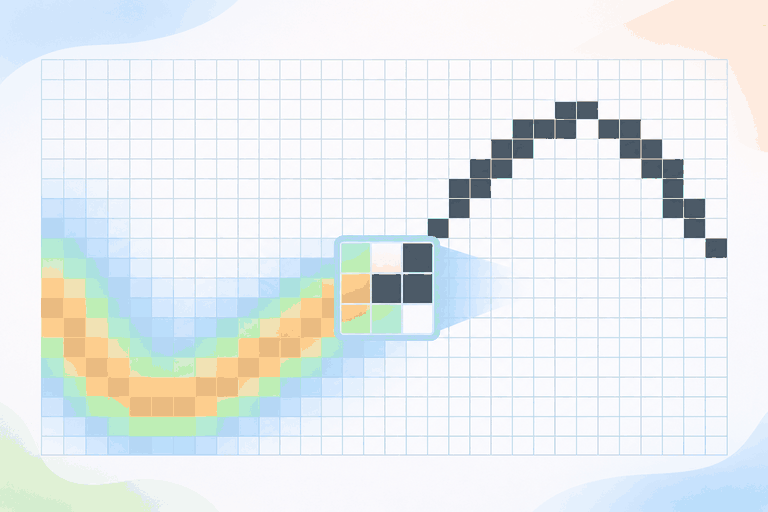
*(Ilustración generada con gpt-image-2.)*

Primero aplicaremos un filtro hecho a mano a un dígito de validation. Verás la entrada, el filtro y su mapa de salida. Después entrenaremos una CNN para mirar qué filtros aprende y medir su accuracy frente al MLP elegido en §16.

In [ ]:
# Un filtro 3×3 hecho a mano, para ver qué hace una convolución ANTES de
# entrenar nada. Este filtro resta la columna izquierda de la ventana a la
# derecha: responde a bordes verticales (más tinta a la derecha de la ventana
# da positivo; más tinta a la izquierda, negativo).
import torch.nn.functional as F

X_val01, y_val = DATOS["01"]["validation"]        # píxeles en [0, 1]
k_digito = int((y_val == 4).nonzero()[0])          # el primer 4 de validation
digito = X_val01[k_digito].detach().cpu().view(28, 28)
filtro = torch.tensor([[-1.0, 0.0, 1.0],
                       [-1.0, 0.0, 1.0],
                       [-1.0, 0.0, 1.0]])          # filas = u, columnas = v

# La convolución de PyTorch: entrada [B, canales, 28, 28], filtro
# [salidas, entradas, 3, 3]. padding=1 agrega un marco de ceros para que la
# salida también sea de 28×28.
mapa = F.conv2d(digito.view(1, 1, 28, 28), filtro.view(1, 1, 3, 3),
                padding=1)[0, 0]                   # [28, 28]

# Dos centros de ventana (renglón, columna), MISMOS 9 pesos: el máximo y el
# mínimo del mapa, buscando el mínimo a ≥ 5 píxeles para no encimar ventanas.
r0, c0 = divmod(int(mapa.argmax()), 28)
rr, cc = torch.meshgrid(torch.arange(28), torch.arange(28), indexing="ij")
lejos = (rr - r0).abs() + (cc - c0).abs() >= 5
posiciones = [(r0, c0), divmod(int(torch.where(lejos, mapa, 9.0).argmin()), 28)]
colores_pos = ["#d62728", "#9467bd"]
fig, (ax_x, ax_w, ax_z) = plt.subplots(
    1, 3, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 0.55, 1]})
ax_x.imshow(digito, cmap="gray_r", vmin=0, vmax=1)
lim = float(mapa.abs().max())
ax_z.imshow(mapa, cmap="RdBu_r", vmin=-lim, vmax=lim)
for k, ((r, c), col) in enumerate(zip(posiciones, colores_pos)):
    ventana = digito[r - 1:r + 2, c - 1:c + 2]     # los 9 píxeles que lee
    valor = float((ventana * filtro).sum())        # suma de productos
    print(f"centro ({r:2d}, {c:2d}): Σ ventana·filtro = {valor:+.3f} "
          f"= mapa[{r}, {c}] = {float(mapa[r, c]):+.3f}")
    ax_x.add_patch(plt.Rectangle((c - 1.5, r - 1.5), 3, 3, fill=False,
                                 edgecolor=col, lw=2.5))
    ax_z.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False,
                                 edgecolor=col, lw=2.5))
    ax_z.annotate(f"{valor:+.2f}", (c, r), xytext=(2 + 13 * k, 26),  # rótulo abajo
                  color=col, fontsize=11, fontweight="bold",
                  arrowprops={"arrowstyle": "->", "color": col})
ax_w.imshow(filtro, cmap="RdBu_r", vmin=-1.5, vmax=1.5)
for u in range(3):
    for v in range(3):
        ax_w.text(v, u, f"{filtro[u, v]:+.0f}", ha="center", va="center",
                  fontsize=14)
ax_w.set(xticks=range(3), yticks=range(3), xlabel="columna v del filtro",
         ylabel="renglón u del filtro", title="El filtro: 9 pesos $w_{uv}$")
for ax, t in ((ax_x, f"Entrada: un {int(y_val[k_digito])} de validation"),
              (ax_z, "Salida: mapa de 28×28")):
    ax.set(title=t, xlabel="columna del píxel", ylabel="renglón del píxel")
for ax in (ax_x, ax_w, ax_z):
    ax.grid(False)
fig.suptitle("Una convolución: la MISMA ventana de 3×3 pesos recorre la imagen")
plt.tight_layout()
plt.show()

A la izquierda está el $4$ de validation con dos ventanas marcadas. En el centro están los pesos $w_{uv}$ del filtro, con el renglón $u$ y la columna $v$ rotulados. La columna izquierda vale $-1$, la central vale $0$ y la derecha vale $+1$. A la derecha está el mapa de salida. Los recuadros rojo y morado marcan el máximo y el mínimo, respectivamente. Cada color enlaza la ventana con la posición que le corresponde en la salida. El código imprime la suma de productos junto al valor del mapa para comprobar que coinciden.

Para calcular la salida en el renglón $r$ y la columna $c$, multiplica cada píxel de la ventana por su peso y suma los productos.

$z_{rc}=\sum_{u=-1}^{1}\sum_{v=-1}^{1} w_{uv}\,x_{r+u,c+v}+b$

Es la misma operación de una neurona de §4, aplicada a nueve píxeles vecinos y con los mismos pesos en todos los centros $(r,c)$. En este ejemplo, $b=0$. En la fórmula, $u$ y $v$ son desplazamientos desde el centro. La figura numera los renglones y las columnas del filtro de $0$ a $2$. Con `padding=1`, PyTorch añade un marco de ceros de un píxel. Así el mapa conserva el tamaño de la entrada, $28\times28$.

El filtro suma la tinta de la columna derecha y le resta la de la izquierda. En la entrada, la tinta toma valores cercanos a $1$ y se dibuja oscura. Si hay más tinta a la derecha de la ventana, la salida es positiva y aparece en rojo. Si hay más a la izquierda, la salida es negativa y aparece en azul. Por eso el filtro resalta bordes verticales. Cuando ambas columnas suman casi lo mismo, la salida queda cerca de cero y aparece blanca.

En términos matemáticos, la operación de `conv2d` es una *cross-correlation* (correlación cruzada). PyTorch aplica el filtro tal como está escrito. En la CNN, los pesos y los sesgos de cada filtro se aprenden con backpropagation, igual que los de la red de la clase 1.

In [ ]:
# La CNN de esta sección. Los DATOS del notebook son planos, [B, 784]; la
# primera capa los vuelve a doblar como imagen [B, 1, 28, 28] (un canal:
# gris). Desde ahí: dos bloques conv 3×3 → ReLU → max-pooling 2×2, y al
# final una capa lineal, la misma de siempre, hacia los 10 logits.
def construir_cnn():
    return nn.Sequential(
        nn.Unflatten(1, (1, 28, 28)),                 # [B,784] → [B,1,28,28]
        nn.Conv2d(1, 16, kernel_size=3, padding=1),   # 16 filtros de 1×3×3
        nn.ReLU(),
        nn.MaxPool2d(2),                              # 28×28 → 14×14
        nn.Conv2d(16, 32, kernel_size=3, padding=1),  # 32 filtros de 16×3×3
        nn.ReLU(),
        nn.MaxPool2d(2),                              # 14×14 → 7×7
        nn.Flatten(),                                 # [B,32,7,7] → [B,1568]
        nn.Linear(32 * 7 * 7, 10),                    # → logits [B,10]
    )


# Pasamos un batch de 2 imágenes y anotamos la forma que sale de cada capa.
cnn_muestra = construir_cnn()
h = DATOS["estandar"]["validation"][0][:2].detach().cpu()
filas = [{"capa": "entrada", "forma de salida": str(list(h.shape)),
          "parámetros": 0}]
for capa in cnn_muestra:
    h = capa(h)
    filas.append({"capa": type(capa).__name__,
                  "forma de salida": str(list(h.shape)),
                  "parámetros": sum(p.numel() for p in capa.parameters())})
tabla_cnn = pd.DataFrame(filas)
display(tabla_cnn)
print("parámetros de la CNN:", int(tabla_cnn["parámetros"].sum()))

# Dibujo de la arquitectura: un bloque por capa, con su forma (sin el batch).
fig, ax = plt.subplots(figsize=(15, 3.2))
tonos = {"Conv2d": "#aec7e8", "ReLU": "#ffbb78", "MaxPool2d": "#98df8a",
         "Linear": "#c5b0d5"}
for i, fila in tabla_cnn.iterrows():
    forma = fila["forma de salida"].strip("[]").split(", ")[1:]
    ax.add_patch(plt.Rectangle((i * 1.6, 0), 1.3, 1, lw=1.5, edgecolor="k",
                               facecolor=tonos.get(fila["capa"], "#eeeeee")))
    ax.text(i * 1.6 + 0.65, 0.68, fila["capa"], ha="center", fontsize=9,
            fontweight="bold")
    ax.text(i * 1.6 + 0.65, 0.32, "×".join(forma), ha="center", fontsize=9)
    if i:
        ax.annotate("", (i * 1.6, 0.5), (i * 1.6 - 0.3, 0.5),
                    arrowprops={"arrowstyle": "->"})
ax.set_xlim(-0.2, len(tabla_cnn) * 1.6)
ax.set_ylim(-0.2, 1.2)
ax.axis("off")
ax.set_title("La CNN: forma de cada capa (canales × alto × ancho, sin el batch)")
plt.show()
del cnn_muestra, h

Lee el dibujo de izquierda a derecha. En los bloques de imagen y de mapas, la forma indica canales, alto y ancho. La tabla sigue el mismo recorrido e incluye la dimensión del batch de prueba.

1. **`Unflatten`.** Recupera la cuadrícula de $28\times28$ a partir de los $784$ píxeles de cada imagen. La imagen tiene un canal de entrada porque está en escala de grises.
2. **Primera convolución.** Aplica $16$ filtros de $3\times3$ y produce un mapa por filtro. Esos mapas son los $16$ canales de salida. Cada filtro tiene nueve pesos y un sesgo compartido por todas las posiciones. En total son $16(9+1)=160$ parámetros.
3. **ReLU y max-pooling.** ReLU pone en cero los valores negativos. Luego, *max-pooling* (agrupación por máximo) divide cada mapa en cuadros de $2\times2$ y se queda con el máximo de cada cuadro. El mapa pasa de $28\times28$ a $14\times14$. Si la respuesta más alta se desplaza dentro del mismo cuadro, el máximo puede quedar igual.
4. **Segunda convolución, ReLU y max-pooling.** Cada uno de los $32$ filtros combina una ventana de $3\times3$ de los $16$ canales. Tiene $16\cdot3\cdot3$ pesos y un sesgo, para un total de $32(16\cdot3\cdot3+1)=4\,640$ parámetros en la capa. Después de ReLU y max-pooling, quedan $32$ mapas de $7\times7$.
5. **`Flatten` y `Linear`.** `Flatten` reúne los mapas en una lista de $32\cdot7\cdot7=1\,568$ rasgos. Sobre ellos, la capa densa calcula un logit por dígito, como en §4. Tiene $10(1\,568+1)=15\,690$ parámetros. La loss sigue siendo `CrossEntropyLoss`.

Las dos convoluciones y la capa densa suman $20\,490$ parámetros. La tabla desglosa el conteo por capa. ReLU, max-pooling y los cambios de forma tienen cero parámetros.

**Apuesta.** Esta CNN usa cerca de una quinta parte de los parámetros de la línea base con una capa oculta de $128$ unidades. El MLP elegido en §16 puede tener otro tamaño. Con el mismo conjunto de train y el mismo tamaño de batch, ¿esperas que la CNN gane, empate o pierda en accuracy de validation? ¿Qué red tendrá la mayor brecha entre train y validation hacia el final?

La CNN toma del MLP la escala de entrada, el tamaño de batch y el número de epochs configuradas. También copia el tope de pasos y la frecuencia de evaluación, si están configurados. La CNN usa Adam sin weight decay, con el learning rate que fija el código.

Si saltaste §16, el código busca el MLP disponible con mayor accuracy de validation entre las corridas con los datos completos de train y etiquetas limpias. Si no encuentra uno, avisa y entrena la línea base `s04-oculta`.

Al final de la sección puedes abrir la respuesta y contrastar tu apuesta con las cifras de tu corrida.

In [ ]:
# El MLP contra el que comparamos: el que §16 eligió por VALIDATION.
# Si saltaste §16, repetimos su regla aquí (nunca se mira test para elegir).
if "s16-elegido" in CORRIDAS:
    corrida_mlp = CORRIDAS["s16-elegido"]
    print("MLP elegido en §16:", corrida_mlp.id)
else:
    def acc_val_mejor(c):
        h = c.historial
        return float(h[h["epoch"] == c.mejor_epoch].iloc[-1]["acc_validation"])

    candidatos = [c for c in CORRIDAS.values()
                  if c.config.datos == "50k-limpio" and c.config.modelo is None
                  and c.config.idx_train is None and not c.divergio
                  and c.config.ruido_etiquetas == 0.0]
    if candidatos:
        corrida_mlp = max(candidatos, key=acc_val_mejor)
        print("AVISO: no existe s16-elegido; uso el mejor MLP por validation:",
              corrida_mlp.id)
    else:
        print("AVISO: no hay ningún MLP entrenado con los 50k; entreno la "
              "línea base s04-oculta (8 epochs).")
        corrida_mlp = entrenar(Config(id="s04-oculta", seccion=4,
                                      capas=[784, 128, 10], activacion="relu",
                                      optimizer="adam", lr=1e-3, epochs=8))
cfg_mlp = corrida_mlp.config
print("capas:", cfg_mlp.capas, "· optimizer:", cfg_mlp.optimizer,
      "· η:", cfg_mlp.lr, "· weight_decay:", cfg_mlp.weight_decay)
print("epochs:", cfg_mlp.epochs, "· tope de pasos:", cfg_mlp.max_pasos,
      "· batch:", cfg_mlp.batch, "· escala:", cfg_mlp.escala,
      "· parámetros:", corrida_mlp.parametros)

In [ ]:
# La CNN, con los mismos datos que el MLP: los 50 000 de train, la misma
# escala de entrada, el mismo batch y las mismas epochs (y el mismo tope de
# pasos y frecuencia de evaluación, si el MLP los tenía). El optimizer es
# Adam con η = 1e-3 y sin weight decay: si el MLP elegido usó otro, la tabla
# de abajo lo muestra, y la comparación es entre ESTAS dos corridas.
cfg_cnn = Config(id="s17-cnn", seccion=17, modelo=construir_cnn,
                 optimizer="adam", lr=1e-3, datos="50k-limpio",
                 epochs=cfg_mlp.epochs, max_pasos=cfg_mlp.max_pasos,
                 eval_cada_pasos=cfg_mlp.eval_cada_pasos,
                 batch=cfg_mlp.batch, escala=cfg_mlp.escala)
corrida_cnn = entrenar(cfg_cnn)
print("epochs:", cfg_cnn.epochs, "· batch:", cfg_cnn.batch,
      "· escala:", cfg_cnn.escala, "· parámetros:", corrida_cnn.parametros)

In [ ]:
# Las dos redes lado a lado: MISMO eje y en cada renglón para poder comparar.
pareja = [("MLP elegido", corrida_mlp), ("CNN", corrida_cnn)]
fig, ejes = plt.subplots(2, 2, figsize=(13, 8), sharey="row")
for j, (nombre, c) in enumerate(pareja):
    curvas([c], metrica="loss", ax=ejes[0, j], titulo=f"{nombre}: loss")
    curvas([c], metrica="accuracy", ax=ejes[1, j],
           titulo=f"{nombre}: accuracy")
plt.tight_layout()
plt.show()


# Tabla: parámetros y métricas en la mejor epoch POR VALIDATION de cada una.
def resumen(nombre, c):
    h = c.historial
    fila = h[h["epoch"] == c.mejor_epoch].iloc[-1]
    return {"red": nombre, "id": c.id, "optimizer": c.config.optimizer,
            "η": c.config.lr, "weight_decay": c.config.weight_decay,
            "parámetros": c.parametros,
            "mejor epoch (validation)": c.mejor_epoch,
            "loss validation": float(fila["loss_validation"]),
            "accuracy validation": float(fila["acc_validation"]),
            "errores en validation": round((1 - fila["acc_validation"])
                                           * len(DATOS["01"]["validation"][1])),
            "segundos": float(h["segundos"].iloc[-1])}


tabla_17 = pd.DataFrame([resumen(n, c) for n, c in pareja]).set_index("red")
display(tabla_17.round(4))
dif = (tabla_17.loc["CNN", "accuracy validation"]
       - tabla_17.loc["MLP elegido", "accuracy validation"])
print(f"CNN − MLP en accuracy de validation: {100 * dif:+.2f} puntos")
print(f"la CNN usa {corrida_cnn.parametros / corrida_mlp.parametros:.2f} "
      "veces los parámetros del MLP")

Arriba está la loss y abajo la accuracy. A la izquierda está el MLP elegido y a la derecha la CNN. Los dos paneles de cada fila comparten la escala vertical. Train va en azul, validation en naranja y test en verde.

**Mirar test en cada epoch está mal.** En un proyecto real, test se usa una sola vez, al final, para reportar. Aquí se grafica solo para aprender a leer las curvas. Las decisiones se toman con validation.

Compara la caída inicial de la loss de validation. Luego mira la brecha entre train y validation hacia el final. Si la loss de train sigue bajando mientras la de validation empieza a subir, tienes una señal de overfitting. Como en la unidad 9, restringir la familia de modelos puede reducir la varianza. Allí podías hacerlo con una penalización controlada por $\mu$. Aquí la arquitectura restringe las conexiones y comparte los pesos.

Para cada red, la tabla usa la epoch de menor loss de validation. En esa epoch reporta la loss, la accuracy y los errores de validation. También muestra el número de parámetros y el tiempo total de entrenamiento. Revisa el optimizer, el learning rate $\eta$ y el weight decay de cada corrida. Si difieren, la comparación recoge también esas diferencias de entrenamiento. Debajo aparecen la diferencia de accuracy en puntos porcentuales y el cociente entre los números de parámetros.

La comparación usa una sola semilla. Una diferencia pequeña podría cambiar con otra. Una CNN puede tardar más por epoch que un MLP pequeño. Usa el tiempo de la tabla para ver qué ocurrió en tu corrida.

In [ ]:
# ¿Qué aprendió la primera capa? Sus 16 filtros de 3×3, y lo que cada uno
# produce sobre el mismo dígito de validation de la figura del principio.
cnn = cargar(corrida_cnn, "mejor")                # en DEVICE, modo eval()
conv1 = cnn[1]                                    # Conv2d(1, 16, 3)
W1 = conv1.weight.detach().cpu()[:, 0]            # [16, 3, 3]
lim = float(W1.abs().max())
fig, ejes = plt.subplots(2, 8, figsize=(14, 4))
for f, ax in enumerate(ejes.flat):
    im = ax.imshow(W1[f], cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_title(f"filtro {f}")
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    ax.grid(False)
for ax in ejes[1]:
    ax.set_xlabel("columna v")
for ax in ejes[:, 0]:
    ax.set_ylabel("renglón u")
fig.colorbar(im, ax=ejes, shrink=0.8).set_label("peso (rojo +, azul −)")
fig.suptitle("Los 16 filtros aprendidos de la primera capa (3×3 cada uno)")
plt.show()

# Mapas de activación: la salida de conv1 + ReLU (capas 0–2 del Sequential).
x = DATOS[cfg_cnn.escala]["validation"][0][k_digito:k_digito + 1]
with torch.no_grad():
    mapas = cnn[:3](x)[0].cpu()                   # [16, 28, 28]
fig, ejes = plt.subplots(2, 9, figsize=(16, 4.2))
ejes[0, 0].imshow(digito, cmap="gray_r")
ejes[0, 0].set_title("entrada")
ejes[1, 0].axis("off")
for f in range(16):
    ax = ejes.flat[f + 1 if f < 8 else f + 2]
    ax.imshow(mapas[f], cmap="magma")
    ax.set_title(f"mapa {f}")
for ax in ejes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
fig.suptitle("Mapas de activación de la primera capa (después de la ReLU) "
             "para el mismo dígito; cada mapa con su propia escala")
plt.show()
del cnn, conv1, W1, mapas                         # liberamos la CNN restaurada

La primera figura muestra los $16$ filtros de la primera capa en el checkpoint de menor loss de validation. Los ejes indican el renglón $u$ y la columna $v$. Todos los filtros usan la misma escala de color. Rojo indica un peso positivo, azul uno negativo y blanco un peso cercano a cero.

Busca una columna roja junto a una azul. Ese patrón puede responder a un borde vertical, como el filtro hecho a mano. Otros filtros pueden responder a bordes horizontales o diagonales. Algunos pueden verse como manchas y ser difíciles de interpretar. Los pesos se ajustaron para clasificar dígitos.

La segunda figura muestra los *activation maps* (mapas de activación) para el mismo $4$. Cada mapa de $28\times28$ es la respuesta de un filtro después de ReLU, antes de max-pooling. Los tonos claros marcan valores mayores dentro de ese mapa. Como cada mapa tiene su propia escala, compara dónde aparece la respuesta y qué forma dibuja. Si todos los valores de un mapa son cero, ReLU apagó todas las respuestas del filtro a ese dígito.

Fíjate si algún mapa resalta un borde o una parte del trazo. La imagen de referencia se muestra con píxeles entre $0$ y $1$. La CNN recibe el mismo dígito en la escala con la que entrenó. Si esa escala es la estandarizada, el fondo tiene un valor distinto de cero y también puede activar un filtro. Tras max-pooling, la segunda convolución combina la información de todos esos canales.

In [ ]:
# Matrices de confusión en VALIDATION, una junto a otra.
# Filas = clase real, columnas = clase predicha. La diagonal (aciertos) va
# en gris para que el color lo lleven los ERRORES, con la misma escala.
def predecir(corrida):
    modelo = cargar(corrida, "mejor")
    X, y = DATOS[corrida.config.escala]["validation"]
    with torch.no_grad():
        p = torch.cat([modelo(X[i:i + 1000]).argmax(1)
                       for i in range(0, len(X), 1000)])
    return y.cpu(), p.cpu()


def confusion(y, p):
    return torch.bincount(y * 10 + p, minlength=100).view(10, 10).numpy()


M = {n: confusion(*predecir(c)) for n, c in pareja}
fuera = {n: mat - np.diag(np.diag(mat)) for n, mat in M.items()}
tope = max(f.max() for f in fuera.values())
fig, ejes = plt.subplots(1, 2, figsize=(14, 6.4))
for ax, (n, matriz) in zip(ejes, M.items()):
    errores = np.where(np.eye(10, dtype=bool), np.nan, matriz)
    im = ax.imshow(errores, cmap="Reds", vmin=0, vmax=tope)
    for i in range(10):
        for j in range(10):
            ax.text(j, i, matriz[i, j], ha="center", va="center", fontsize=8,
                    color="dimgray" if i == j else "black")
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))
    ax.set_xlabel("clase predicha (columna)")
    ax.set_ylabel("clase real (fila)")
    ax.set_title(f"{n}: {int(fuera[n].sum())} errores de {int(matriz.sum())}")
    ax.grid(False)
fig.colorbar(im, ax=ejes, shrink=0.8).set_label("conteo fuera de la diagonal")
fig.suptitle("Matrices de confusión en validation: MLP elegido vs CNN")
plt.show()

# Errores por clase real: ¿en qué dígitos cambia algo?
por_clase = pd.DataFrame({n: f.sum(axis=1) for n, f in fuera.items()})
por_clase.index.name = "clase real"
por_clase["CNN − MLP"] = por_clase["CNN"] - por_clase["MLP elegido"]
display(por_clase.T)

Las dos matrices de confusión se calculan en validation con el mejor checkpoint de cada red. A la izquierda está el MLP y a la derecha la CNN. **Las filas son las clases reales y las columnas son las clases predichas.** Cada casilla muestra un conteo. Los aciertos se leen en gris en la diagonal. El rojo destaca los errores y usa la misma escala en ambas matrices.

Compara los totales de error en los títulos. Luego elige una casilla roja y busca la misma fila y columna en la otra matriz. Por ejemplo, la fila del $4$ y la columna del $9$ cuentan los cuatros predichos como nueves. Revisa también la confusión en sentido inverso. Fíjate si la CNN reduce los errores en los mismos pares o si disminuyen en unos y aumentan en otros. En la tabla por clase real, una diferencia CNN $-$ MLP negativa indica que la CNN se equivocó menos en ese dígito.

La CNN incorpora una suposición sobre los datos. Los píxeles cercanos forman rasgos y un mismo rasgo puede servir en distintos lugares. Si esa suposición encaja, restringir la arquitectura puede reducir la varianza sin aumentar mucho el sesgo. Medimos el resultado en validation con una sola semilla. En §19, la CNN aparecerá en la tabla maestra con las demás corridas.

<details><summary>Respuesta</summary>

La respuesta sale de tu corrida. En la tabla de curvas, una diferencia de accuracy positiva favorece a la CNN y una negativa favorece al MLP. Para la segunda parte de la apuesta, compara la distancia entre train y validation en los paneles de accuracy hacia el final. Las matrices muestran qué confusiones cambiaron.

En MNIST es razonable esperar que esta CNN iguale o supere la accuracy del MLP y que su brecha sea menor. Con una sola semilla, pocas epochs y un MLP fuerte, la diferencia puede ser pequeña o favorecer al MLP. La proporción impresa te dice cuánto cambia el número de parámetros frente al MLP que se usó.

El conteo de parámetros dice cuántos valores se ajustan. La arquitectura determina cómo se combinan. Al compartir los pesos, la CNN puede reaprovechar en toda la imagen un rasgo que aprendió a reconocer en una ventana.

</details>

## 18 · Softmax y la loss

Hasta aquí entrenamos con `CrossEntropyLoss`. ¿Qué recibe esa función y qué
mide la loss (pérdida)? Empecemos con la salida de la red para un solo dígito.

La última capa lineal entrega diez **logits** (puntajes), uno por cada clase
$c=0,\dots,9$. Con la notación de la clase 1, son las preactivaciones de la
última capa, $\mathbf z = \mathbf W^{(L)}\mathbf a^{(L-1)}+\mathbf b^{(L)}$.
La red entrega ese vector directamente, sin aplicar una activación final.
Los logits pueden ser negativos y su suma puede tomar cualquier valor.

**Softmax** convierte esos puntajes en probabilidades. Eleva $e$ a cada
logit y divide cada resultado entre la suma de todos.

$$\widehat y_c = \frac{e^{z_c}}{\sum_{j=0}^{9} e^{z_j}}.$$

En aritmética exacta, cada probabilidad queda entre 0 y 1, sin incluir los
extremos, y todas suman 1. La exponencial conserva el orden y el denominador
es común a todas las clases. Sumar la misma constante a todos los logits
multiplica el numerador y el denominador por el mismo factor, así que las
probabilidades quedan iguales.

Es el mismo softmax de la regresión logística multiclase de la unidad 9.
En §4 vimos esa regresión como una red sin capas ocultas. Las capas ocultas
cambian cómo se calculan los logits. La fórmula que los convierte en
probabilidades sigue siendo la misma.

Cargamos el checkpoint de la mejor epoch del modelo elegido en §16 por
validation (validación). Si esa corrida falta, usamos la línea base de §4 y
la entrenamos si hace falta. La celda indica qué modelo usó y comprueba con
un `assert` que sus capas no incluyen `nn.Softmax`. Veremos los logits de
un dígito real, cómo la temperatura modifica sus probabilidades y cómo
calcular la loss de forma estable. Al final, el dibujo ubica cada paso.

In [ ]:
# El modelo de esta sección: el que §16 eligió por validation. Si corriste
# esta sección sin §16, usamos la línea base de §4 (y la entrenamos si falta).
import torch.nn.functional as F

if "s16-elegido" in CORRIDAS:
    corrida_18 = CORRIDAS["s16-elegido"]
    print("Usamos el modelo elegido en §16:", corrida_18.id)
elif "s04-oculta" in CORRIDAS:
    corrida_18 = CORRIDAS["s04-oculta"]
    print("No hay s16-elegido (no corriste §16): usamos la línea base "
          "s04-oculta, que ya estaba entrenada.")
else:
    print("No hay s16-elegido ni s04-oculta: entrenamos ahora la línea base "
          "de §4 (784→128→10, ReLU, Adam 1e-3, 8 epochs).")
    corrida_18 = entrenar(Config(id="s04-oculta", seccion=4,
                                 capas=[784, 128, 10], activacion="relu",
                                 optimizer="adam", lr=1e-3, epochs=8))

escala_18 = corrida_18.config.escala
modelo_18 = cargar(corrida_18, "mejor")      # el checkpoint de la mejor epoch
print(modelo_18)

# Ninguna capa del modelo es softmax: la red termina en 10 LOGITS.
# El softmax vive dentro de CrossEntropyLoss (lo vemos en esta sección).
assert not any(isinstance(m, nn.Softmax) for m in modelo_18.modules())

In [ ]:
# Logits de TODO validation (sin gradiente, por bloques de 2048).
X_val, y_val = DATOS[escala_18]["validation"]
with torch.no_grad():
    logits_val = torch.cat([modelo_18(X_val[i:i + 2048])
                            for i in range(0, len(X_val), 2048)])
prob_val = torch.softmax(logits_val, dim=1)      # [n, 10]; cada fila suma 1
confianza, prediccion = prob_val.max(dim=1)

# Un dígito con algo de duda: bien clasificado, pero con 0.5 < max ŷ_c < 0.9,
# para que se vea más de una barra. Si no hay ninguno, el acierto (o, si no
# hay aciertos, el ejemplo) con la confianza más baja.
acierto = prediccion == y_val
dudosos = torch.nonzero(acierto & (confianza > 0.5) & (confianza < 0.9))
if len(dudosos):
    k_18 = int(dudosos[0, 0])
elif acierto.any():
    k_18 = int(torch.where(acierto, confianza, 2.0).argmin())
else:
    k_18 = int(confianza.argmin())
z = logits_val[k_18].cpu()                       # z_0 … z_9
y_gorro = prob_val[k_18].cpu()                   # ŷ_0 … ŷ_9
y_k = int(y_val[k_18])
colores_k = ["#9e9e9e"] * 10
colores_k[y_k] = COLORES["validation"]           # la clase verdadera

fig, (ax_img, ax_z, ax_p) = plt.subplots(
    1, 3, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1, 2, 2]})
ax_img.imshow(DATOS["01"]["validation"][0][k_18].reshape(28, 28).cpu(),
              cmap="gray_r")
ax_img.set_title(f"validation #{k_18}: etiqueta y = {y_k}")
ax_img.axis("off")
ax_z.bar(range(10), z, color=colores_k)
ax_z.axhline(0, color="black", lw=0.8)
ax_z.set_title("Logits $z_c$ (lo que sale de la red)")
ax_z.set_ylabel("logit $z_c$")
barras = ax_p.bar(range(10), y_gorro, color=colores_k)
ax_p.set_ylim(0, 1)
ax_p.set_title(r"Probabilidades $\widehat y_c$ = softmax(z)")
ax_p.set_ylabel(r"probabilidad $\widehat y_c$")
ax_p.legend([barras[y_k]], [f"clase verdadera y = {y_k}"])
for ax in (ax_z, ax_p):
    ax.set_xticks(range(10))
    ax.set_xlabel("clase c (dígito)")
plt.tight_layout()
plt.show()

# La cuenta, clase por clase (e^z en float64 para no desbordar).
e_z = torch.exp(z.double())
display(pd.DataFrame({"clase c": range(10), "logit z_c": z.numpy(),
                      "e^{z_c}": e_z.numpy(),
                      "ŷ_c = e^{z_c} / Σ e^{z_j}": (e_z / e_z.sum()).numpy()})
        .round(4))
print(f"Σ ŷ_c = {float(y_gorro.sum()):.6f}   ·   argmax z = {int(z.argmax())}"
      f"   ·   argmax ŷ = {int(y_gorro.argmax())}")

A la izquierda está el dígito de validation. En el centro están sus logits.
La línea negra marca el cero. A la derecha están las probabilidades del
softmax. En ambos paneles de barras, el naranja señala la clase verdadera $y$.

El código busca el primer acierto con una probabilidad máxima mayor que
$0.5$ y menor que $0.9$. Así podemos ver un caso en que el modelo acierta
con algo de duda. Si no encuentra un ejemplo así, muestra el acierto con
la confianza más baja.

Compara las barras más altas. Ambas corresponden a la misma clase. Una
diferencia de pocos puntos entre logits puede producir una gran diferencia
entre probabilidades, porque su cociente es $e^{z_c-z_j}$ para las clases
$c$ y $j$. Hasta un logit negativo aporta una cantidad positiva en la
fórmula.

La tabla muestra la cuenta para cada clase. Sigue $z_c$, luego $e^{z_c}$ y
por último $\widehat y_c$, que es la altura de la barra de la derecha.
Debajo se imprimen la suma de las probabilidades y los dos `argmax`
(índices del máximo). Para predecir la clase basta con el `argmax` de
los logits.

La **temperatura** $T>0$ divide todos los logits entre el mismo número antes
de aplicar softmax. Con $T=1$ recuperamos las probabilidades del modelo
tal cual.

$$\widehat y_c(T)=\frac{e^{z_c/T}}{\sum_{j=0}^{9}e^{z_j/T}}.$$

La confianza es la probabilidad más alta. Como vimos en la unidad 9, un
modelo puede acertar mucho y aun así estar mal calibrado. Por ejemplo,
puede acertar con menos frecuencia de la que su confianza sugiere. La
temperatura se puede usar para ajustar esa confianza. En modelos de
lenguaje también se usa para ajustar las probabilidades al muestrear.

**Apuesta antes de correr.** Para el mismo dígito y
$T\in\{0.5,1,2,5\}$, ¿cambia la clase predicha? ¿Qué le pasa a la barra
más alta al subir o bajar $T$? ¿Cambia la loss de ese ejemplo,
$-\log\widehat y_y(T)$? Si aplicaras la misma $T$ a todo validation,
¿cambiaría la accuracy (proporción de aciertos)?

Los cuatro paneles comparten eje vertical. La tabla muestra para cada $T$
el `argmax`, la confianza, la probabilidad de la clase verdadera y la
loss del dígito.

In [ ]:
# Temperatura: softmax(z / T). Dividir TODOS los logits entre el mismo T > 0
# no cambia su orden, así que el argmax no cambia; la confianza sí.
TEMPERATURAS = [0.5, 1, 2, 5]
fig, ejes = plt.subplots(1, len(TEMPERATURAS), figsize=(15, 3.6), sharey=True)
filas = []
for T, ax in zip(TEMPERATURAS, ejes):
    p_T = torch.softmax(z / T, dim=0)
    ax.bar(range(10), p_T, color=colores_k)
    ax.set_title(f"T = {T}" + ("  (el modelo tal cual)" if T == 1 else ""))
    ax.set_xticks(range(10))
    ax.set_xlabel("clase c")
    filas.append({"T": T, "argmax": int(p_T.argmax()),
                  "max ŷ_c": float(p_T.max()),
                  f"ŷ_y (y = {y_k})": float(p_T[y_k]),
                  "loss −log ŷ_y":                 # estable: log_softmax
                  float(-torch.log_softmax(z / T, dim=0)[y_k])})
ejes[0].set_ylim(0, 1)
ejes[0].set_ylabel(r"probabilidad $\widehat y_c$")
fig.suptitle(f"El mismo dígito (validation #{k_18}) con softmax(z / T)")
plt.tight_layout()
plt.show()

tabla_T = pd.DataFrame(filas)
display(tabla_T.round(4))
assert tabla_T["argmax"].nunique() == 1          # el argmax no se movió
print("El argmax es el mismo en las", len(TEMPERATURAS), "temperaturas:",
      int(tabla_T["argmax"].iloc[0]))

<details><summary>Respuesta</summary>

- **Clase predicha.** Dividir entre $T>0$ conserva el orden de los logits.
  El `assert` comprueba que el `argmax` del dígito se mantiene.
- **Confianza.** Bajar $T$ ensancha las diferencias entre logits. La barra
  más alta crece. Cuando $T\to 0$, la probabilidad se concentra en la clase
  ganadora o se reparte entre las clases empatadas en el máximo. Subir $T$
  reduce las diferencias y baja la barra más alta. Cuando $T\to\infty$,
  cada clase se acerca a $1/10$.
- **Loss del dígito.** Depende de la barra naranja. Si la clase verdadera
  tiene el logit más alto, al bajar $T$ su probabilidad sube y su loss baja.
  Si el modelo no acertara ningún ejemplo de validation, el respaldo sería
  un error; entonces lee el cambio directamente en la columna
  $\widehat y_y$ de la tabla. Una
  probabilidad menor para la clase verdadera implica una loss mayor.
- **Accuracy de validation.** En aritmética exacta, cada predicción se
  conserva, así que la accuracy queda igual. La loss promedio sí puede
  cambiar. En §6 vimos cómo los errores más confiados pueden elevar la
  loss de validation con la misma accuracy.

Ajustar $T$ en validation para calibrar el modelo se llama *temperature
scaling*. Aquí solo probamos temperaturas fijas en este dígito.

</details>

La **cross-entropy** (entropía cruzada) de un ejemplo con etiqueta entera
$y$ es $\ell=-\log\widehat y_y$. Tomamos la probabilidad asignada a la clase
verdadera y le aplicamos el logaritmo natural, $\ln$ en la unidad 9, con
signo menos. Con $\widehat y_y=1$ la loss vale cero. Cuando $\widehat y_y$
se acerca a cero, la loss crece sin límite. Si das la misma probabilidad
a los diez dígitos, la loss es $\log 10\approx 2.30$, la referencia de §6.

Es la pérdida logarítmica de la regresión logística de la unidad 9. Para
$n$ observaciones independientes, la verosimilitud de las etiquetas
observadas es el producto $\prod_{k=1}^{n}\widehat y_{k,y_k}$. El logaritmo
del producto es una suma. Al cambiarle el signo y dividir entre $n$ queda

$$L(\theta) = \frac{1}{n}\sum_{k=1}^{n} -\log\widehat y_{k,y_k}.$$

Aquí la cross-entropy es la **negative log-likelihood** (menos
log-verosimilitud) por ejemplo, promediada sobre el conjunto. Minimizarla
equivale a maximizar la verosimilitud.

En PyTorch, `nn.CrossEntropyLoss()(logits, y)` da lo mismo que
`nn.NLLLoss()(torch.log_softmax(logits, dim=1), y)`. Las dos llamadas usan
etiquetas enteras del 0 al 9. `log_softmax` calcula las
log-probabilidades por fila. `NLLLoss` recibe esos logaritmos, toma el
de cada clase verdadera, cambia su signo y promedia. `CrossEntropyLoss`
recibe los logits y combina ambos pasos.

La celda compara primero la cuenta del dígito con `F.cross_entropy`.
Después muestra cuatro cálculos de la loss de validation. Compara
el promedio explícito de las pérdidas por ejemplo con
`CrossEntropyLoss`, `NLLLoss` sobre `log_softmax` y `evaluar` de la
caja. Un `assert` verifica que los cuatro coincidan dentro de una
tolerancia.

In [ ]:
# 1) Un dígito, a mano: la loss es −log de la probabilidad de la clase y.
a_mano = -torch.log(y_gorro[y_k])               # (sin cuidar la estabilidad)
por_pytorch = F.cross_entropy(z.unsqueeze(0), torch.tensor([y_k]))
print(f"dígito #{k_18}:  −log ŷ_y a mano = {float(a_mano):.6f}"
      f"   ·   CrossEntropyLoss = {float(por_pytorch):.6f}")

# 2) Todo validation: la loss de cada ejemplo, ℓ_k = −log ŷ_{k, y_k} ...
log_p_val = torch.log_softmax(logits_val, dim=1)
filas_k = torch.arange(len(y_val), device=y_val.device)
perdida_k = -log_p_val[filas_k, y_val]           # [n], una por ejemplo

# ... y su promedio, calculado de cuatro maneras.
maneras = {
    "promedio de −log ŷ_y (a mano)": perdida_k.mean(),
    "CrossEntropyLoss(logits)": nn.CrossEntropyLoss()(logits_val, y_val),
    "NLLLoss(log_softmax(logits))": nn.NLLLoss()(log_p_val, y_val),
    "evaluar(...) de la caja": evaluar(modelo_18, escala_18, "validation")[0],
}
display(pd.DataFrame({"manera": list(maneras),
                      "loss de validation": [float(v) for v in
                                             maneras.values()]}).round(6))
valores = [float(v) for v in maneras.values()]
assert max(valores) - min(valores) < 1e-3        # la misma cantidad

# 3) Dos gráficas: la curva −log p, y cómo se reparte ℓ_k en validation.
fig, (ax_c, ax_h) = plt.subplots(1, 2, figsize=(13, 4))
p = torch.linspace(0.001, 1, 500)
ax_c.plot(p, -torch.log(p), color="black", lw=2, label=r"$-\log \widehat y_y$")
ax_c.scatter([0.1], [math.log(10)], color="gray", zorder=3,
             label=r"adivinar uniforme: $\log 10 \approx 2.30$")
ax_c.scatter([float(y_gorro[y_k])], [float(a_mano)], zorder=3, s=60,
             color=COLORES["validation"], label=f"el dígito #{k_18}")
ax_c.set_xlabel(r"probabilidad de la clase verdadera $\widehat y_y$")
ax_c.set_ylabel("loss de ese ejemplo")
ax_c.set_title("Cross-entropy de un ejemplo: $-\\log \\widehat y_y$")
ax_c.legend()
ax_h.hist(perdida_k.cpu().numpy(), bins=60, color=COLORES["validation"])
ax_h.set_yscale("log")
ax_h.axvline(valores[1], color="black", ls="--", label="promedio (la loss)")
ax_h.axvline(math.log(10), color="gray", ls=":", label=r"$\log 10$")
ax_h.set_xlabel(r"loss de cada ejemplo $\ell_k$")
ax_h.set_ylabel("número de ejemplos (escala log)")
ax_h.set_title("Validation: la loss de cada uno de sus ejemplos")
ax_h.legend()
plt.tight_layout()
plt.show()

La tabla comprueba cómo se calcula la loss de las curvas. En cada conjunto
se promedia $-\log\widehat y_y$ sobre sus ejemplos.

En la gráfica izquierda, el eje horizontal es la probabilidad de la clase
verdadera y el vertical es su loss. El punto gris marca la referencia
uniforme $\log 10$. El naranja es el dígito que acabamos de ver. Cerca de 1,
aumentar la probabilidad ahorra poca loss. Cerca de 0, una probabilidad
todavía menor cuesta mucho.

A la derecha, cada barra cuenta ejemplos de validation en un intervalo de
loss. El eje vertical está en escala logarítmica. Busca una concentración
de ejemplos con poca loss y fíjate si aparece una cola de ejemplos con
loss alta. La línea discontinua marca el promedio y la punteada marca
$\log 10$. Los errores confiados que viste en §16 pueden contribuir mucho
al promedio. Si se vuelven más confiados, la loss puede subir aunque la
cantidad de aciertos siga igual, como en §6.

¿Por qué conviene juntar softmax y el logaritmo en el cálculo de la loss?
El notebook entrena en `float32`, un formato con un rango limitado.
El menor positivo normal es aproximadamente $1.2\times10^{-38}$. Incluso
el menor positivo representable, contando los subnormales, es de apenas
$1.4\times10^{-45}$. Un valor tan pequeño como $e^{-1000}$ se redondea a
cero. Eso es *underflow*. En el otro extremo, $e^{89}$ supera el máximo
representable y produce `inf`. Eso es *overflow*.

Probemos con dos clases, logits $\mathbf z=(0,-1000)$ y etiqueta verdadera
$y=1$. La clase verdadera recibe una probabilidad diminuta. Su
log-probabilidad exacta es $-1000-\log(1+e^{-1000})\approx-1000$.
La loss es enorme y finita, aproximadamente $1000$.

La tabla pone el valor de referencia al lado de cada resultado en
`float32`. La primera fila muestra la log-probabilidad de la clase 1 con
`softmax(z).log()`. Las otras tres muestran la loss calculada con
`NLLLoss(softmax(z).log())`, `NLLLoss(log_softmax(z))` y
`CrossEntropyLoss(z)`. **Antes de correr, predice qué filas darán un
resultado finito.**

In [ ]:
# Un caso extremo en float32 (el tipo con el que entrena todo el notebook):
# una observación, dos clases, logits z = [0, −1000] y clase verdadera 1.
z_ext = torch.tensor([[0.0, -1000.0]], dtype=torch.float32)
y_ext = torch.tensor([1])
print("e^{-1000} en float32 =", torch.exp(torch.tensor(-1000.0)).item(),
      "  (el positivo normal más chico de float32 es",
      f"{torch.finfo(torch.float32).tiny:.1e}; e^{{-1000}} ≈ 1e-435)")

p_ingenua = torch.softmax(z_ext, dim=1)          # [[1., 0.]]
log_p_ingenua = p_ingenua.log()                  # [[0., -inf]]
maneras_ext = [
    ("softmax(z).log(), clase 1", log_p_ingenua[0, 1], "−1000"),
    ("NLLLoss(softmax(z).log())", nn.NLLLoss()(log_p_ingenua, y_ext), "1000"),
    ("NLLLoss(log_softmax(z))",
     nn.NLLLoss()(torch.log_softmax(z_ext, dim=1), y_ext), "1000"),
    ("CrossEntropyLoss(z)", nn.CrossEntropyLoss()(z_ext, y_ext), "1000"),
]
display(pd.DataFrame({"manera": [m for m, _, _ in maneras_ext],
                      "resultado en float32": [float(v) for _, v, _ in
                                               maneras_ext],
                      "valor exacto (redondeado)": [e for _, _, e in
                                                    maneras_ext]}))

In [ ]:
# El truco log-sum-exp, a mano. Con m = max_j z_j:
#   log ŷ_c = z_c − log Σ_j e^{z_j} = z_c − m − log Σ_j e^{z_j − m}
# Ahora el exponente más grande es e^0 = 1: nada desborda, y la suma
# vale al menos 1, así que su log nunca es −inf.
def log_softmax_a_mano(z):
    m = z.max(dim=1, keepdim=True).values                  # [n, 1]
    return z - m - torch.log(torch.exp(z - m).sum(dim=1, keepdim=True))


def softmax_ingenuo(z):                                    # sin restar m
    e = torch.exp(z)
    return e / e.sum(dim=1, keepdim=True)


# Dos logits peligrosos: uno muy negativo (underflow: e^z se vuelve 0)
# y uno muy positivo (overflow: e^z se vuelve inf, e inf / inf = nan).
for z_prueba in ([[0.0, -1000.0]], [[1000.0, 0.0]]):
    zt = torch.tensor(z_prueba)
    print(f"z = {z_prueba[0]}")
    print("   log(softmax ingenuo):", softmax_ingenuo(zt).log().tolist()[0])
    print("   log-sum-exp a mano:  ", log_softmax_a_mano(zt).tolist()[0])
    print("   torch.log_softmax:   ", torch.log_softmax(zt, dim=1).tolist()[0])

# Y en los logits reales de validation, el truco da lo mismo que PyTorch.
assert torch.allclose(log_softmax_a_mano(logits_val), log_p_val, atol=1e-5)
print("\nEn los", len(logits_val), "logits de validation, log-sum-exp a mano "
      "= torch.log_softmax")

En la tabla, `softmax(z)` produjo $(1,0)$ por *underflow*. Tomar el
logaritmo de la probabilidad de la clase 1 dio $-\infty$. Al cambiarle el
signo, `NLLLoss` devolvió $+\infty$. Un solo ejemplo así puede volver
infinita la loss del batch y producir gradientes `NaN`. Los cálculos
con `log_softmax` y `CrossEntropyLoss` devolvieron $1000$.

El truco **log-sum-exp** usa que desplazar todos los logits por la misma
constante deja el softmax igual. Toma $m=\max_j z_j$ y escribe

$$\log\widehat y_c
= z_c-\log\sum_j e^{z_j}
= z_c-m-\log\sum_j e^{z_j-m}.$$

Ahora la exponencial más grande es $e^0=1$. Las demás pueden redondearse
a cero, pero la suma siempre vale al menos 1. Para $(0,-1000)$, esa suma
se redondea a 1 en `float32`. Su logaritmo es cero y el término $z_1-m$
da directamente $-1000$.

La segunda celda contrasta el cálculo directo con el estable en ambos
extremos. Con $(1000,0)$, el softmax ingenuo intenta dividir
$\infty/\infty$ y aparece `nan`. La versión a mano con log-sum-exp y
`torch.log_softmax` dan resultados finitos para ambos pares. Un `assert`
verifica que las dos versiones estables coincidan, dentro de la tolerancia,
en los logits de todo validation.

Para obtener log-probabilidades, usa `log_softmax`. Para calcular la
cross-entropy, pasa los logits directamente a `CrossEntropyLoss`.

El dibujo reúne la arquitectura del modelo cargado y el cálculo de softmax
para el mismo dígito. A la izquierda, `dibujar_red` muestra las capas del
MLP. A la derecha, sigue los diez logits hasta sus diez probabilidades.
La barra naranja vuelve a marcar la clase verdadera.

La última capa lineal del `nn.Sequential` entrega los diez logits.
Durante el entrenamiento, `CrossEntropyLoss` calcula log-softmax de
forma estable y aplica la negative log-likelihood. Para predecir la clase
basta el `argmax` de los logits. Aplica softmax explícitamente cuando
quieras ver probabilidades, como en el análisis de confianza y calibración
de §16.

In [ ]:
# La red completa del modelo elegido y, a la derecha, el paso que la red no
# hace pero la loss sí: softmax de los 10 logits del dígito de arriba.
fig, (ax_red, ax_sm) = plt.subplots(
    1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [3, 2]})
if corrida_18.config.modelo is None:
    dibujar_red(corrida_18.config.capas, ax=ax_red,
                titulo=f"El modelo elegido ({corrida_18.id}): "
                       f"{corrida_18.config.capas}")
else:                                           # una CNN no se dibuja así
    ax_red.text(0.5, 0.5, f"{corrida_18.id}: no es un MLP", ha="center")
    ax_red.axis("off")

filas_y = np.arange(10)[::-1]                    # clase 0 arriba
for c, fila in zip(range(10), filas_y):
    ax_sm.text(0.0, fila, f"$z_{c}$ = {float(z[c]):6.2f}", va="center",
               ha="right", fontsize=9, family="monospace")
    ax_sm.text(3.0, fila, rf"$\widehat y_{c}$", va="center", ha="right")
ax_sm.barh(filas_y, 1.6 * y_gorro.numpy(), left=3.15, height=0.6,
           color=colores_k)
for c, fila in zip(range(10), filas_y):                  # el valor de ŷ_c
    ax_sm.text(3.2 + 1.6 * float(y_gorro[c]), fila, f"{float(y_gorro[c]):.2f}",
               va="center", fontsize=8)
ax_sm.add_patch(plt.Rectangle((0.6, 1.5), 1.6, 6, fill=False, lw=1.5))
ax_sm.text(1.4, 5.6, "softmax", ha="center", va="center", fontsize=13)
ax_sm.text(1.4, 3.9, r"$\frac{e^{z_c}}{\sum_j e^{z_j}}$", ha="center",
           va="center", fontsize=20)
for x0, x1 in ((0.1, 0.55), (2.25, 2.7)):
    ax_sm.annotate("", xy=(x1, 4.5), xytext=(x0, 4.5),
                   arrowprops=dict(arrowstyle="->", lw=1.5))
ax_sm.set_xlim(-1.6, 5.4)
ax_sm.set_ylim(-0.8, 9.8)
ax_sm.axis("off")
ax_sm.set_title(f"10 logits → softmax → 10 probabilidades (#{k_18}, y = {y_k})")
plt.tight_layout()
plt.show()

print("En el código, la red termina en los logits; softmax y −log ŷ_y van")
print("juntos dentro de CrossEntropyLoss (con log-sum-exp).")

**Qué viste**

- La red entrega logits. Softmax conserva su orden y los convierte en
  probabilidades que suman 1.
- La temperatura cambia la confianza y puede cambiar la loss. Conserva el
  `argmax` de cada ejemplo y, por tanto, la accuracy.
- La cross-entropy de un ejemplo es $-\log\widehat y_y$. Su promedio es la
  loss de las curvas del notebook.
- Con etiquetas enteras, ese promedio es la negative log-likelihood por
  ejemplo, como en la regresión logística de la unidad 9.
- En `float32`, hacer softmax y luego tomar el logaritmo puede producir
  infinitos o `NaN`. Log-sum-exp permite calcular directamente las
  log-probabilidades de forma estable.

Negative log-likelihood y cross-entropy son la misma cantidad; la
diferencia está en cómo se calcula. Por eso los modelos del notebook
terminan en logits y el entrenamiento los entrega directamente a
`CrossEntropyLoss`, que hace log-softmax y la negative log-likelihood en un
solo paso estable.

## 19 · Cierre

En la unidad 9 comparamos modelos con el error de validation. Aquí hacemos lo mismo con todas las corridas registradas, desde la demo de la caja hasta la CNN de §17. La tabla maestra y la figura ayudan a ver qué cambios movieron el error y cuáles dieron resultados parecidos. El cierre solo resume lo que hay en `CORRIDAS`. Si saltaste secciones, verás solo las corridas registradas. Si el registro está vacío, la celda te avisa.

In [ ]:
# La tabla maestra de la caja (s03): una fila por corrida, con sus números
# en la MEJOR epoch por validation (test no participó en elegirla).
# brecha = acc train − acc validation: cuánto va train por delante.
import numpy as np
import pandas as pd

# §16 guarda el MLP elegido también como CORRIDAS["s16-elegido"]: es el
# MISMO objeto con otro nombre, así que su fila saldría dos veces con su ID
# original. Dejamos una fila por ID.
resumen = tabla_maestra()
if not resumen.empty:
    resumen = resumen.drop_duplicates("id").reset_index(drop=True)
if resumen.empty:
    print("CORRIDAS está vacío: no corriste ninguna sección con experimentos.")
    print("Ejecuta el notebook completo (Entorno de ejecución → Ejecutar todo)")
    print("y vuelve aquí; esta sección solo resume lo que ya se entrenó.")
    resumen = pd.DataFrame(columns=["id", "seccion", "datos", "parametros",
                                    "mejor_epoch", "acc_train",
                                    "acc_validation", "acc_test", "brecha",
                                    "segundos", "divergio"])
else:
    # Orden: los grupos de datos en el orden en que aparecen en el notebook
    # y, dentro de cada grupo, de mejor a peor accuracy de VALIDATION.
    # Nunca se ordena ni se elige con test.
    resumen["divergio"] = resumen["divergio"].astype(bool)
    resumen["_orden"] = resumen.groupby("datos")["seccion"].transform("min")
    resumen = (resumen.sort_values(["_orden", "datos", "acc_validation"],
                                   ascending=[True, True, False])
               .drop(columns="_orden").reset_index(drop=True))
    print(f"{len(resumen)} corridas en {resumen['datos'].nunique()} grupos "
          f"de datos y {resumen['seccion'].nunique()} secciones.")
    print("Corridas por grupo de datos:")
    print(resumen.groupby("datos", sort=False).size().to_string())
    print("Divergieron:", int(resumen["divergio"].sum()))


def presupuesto(ident):
    """El presupuesto PEDIDO en la Config: pasos si los topa, si no epochs."""
    cfg = CORRIDAS[ident].config
    return f"{cfg.max_pasos} pasos" if cfg.max_pasos else f"{cfg.epochs} epochs"


resumen["presupuesto"] = [presupuesto(i) for i in resumen["id"]]
resumen["pasos"] = [int(CORRIDAS[i].historial["pasos"].iloc[-1])
                    for i in resumen["id"]]        # pasos dados de verdad
# Un color por sección, el mismo en la figura y en el recuadro final.
secciones = sorted(resumen["seccion"].unique())
paleta = plt.cm.tab20b(np.linspace(0, 1, max(len(secciones), 2)))
color_de = {s: paleta[i] for i, s in enumerate(secciones)}

La tabla se divide por `datos`. Compara filas dentro del mismo grupo. Hay corridas con todo train limpio, con subconjuntos y con etiquetas alteradas. Al alterar etiquetas, la red recibe ejemplos con respuestas incorrectas. Ese ruido recuerda al ruido irreducible de la unidad 9 y cambia las condiciones del ajuste.

- `parametros` cuenta los pesos y sesgos entrenables. `presupuesto` es lo que pidió la `Config` (epochs, o un tope de pasos) y `pasos` las actualizaciones que dio de verdad. `mejor_epoch` indica dónde fue menor la loss de validation en esa corrida.
- Las columnas `loss_` y `acc_` muestran la loss y la accuracy de train, validation y test en esa epoch. Dentro de cada grupo, la tabla ordena las filas de mayor a menor `acc_validation`. Test aparece solo para reportar.
- `brecha` es la accuracy de train menos la de validation. `segundos` mide el tiempo acumulado al final de la corrida. `divergio` indica si apareció una loss no finita durante el entrenamiento.

Incluso dentro del mismo grupo, el presupuesto de entrenamiento puede variar. Por ejemplo, cambiar el tamaño del batch en §7 cambia cuántas actualizaciones caben en una epoch. Lee el orden de la tabla junto con las columnas `presupuesto` y `pasos`.

In [ ]:
# La tabla maestra completa, partida por grupo de datos. Solo se comparan
# filas DENTRO de un grupo: con 2000 ejemplos y 20 % de etiquetas
# cambiadas (§10) la accuracy no se puede poner junto a la de 50 000
# limpios. Dentro de cada grupo, el orden lo da validation.
columnas_tabla = ["id", "seccion", "parametros", "presupuesto", "pasos",
                  "mejor_epoch", "loss_train", "loss_validation", "loss_test",
                  "acc_train", "acc_validation", "acc_test", "brecha",
                  "segundos", "divergio"]
if resumen.empty:
    print("Sin corridas: no hay tabla maestra que mostrar.")
for datos_grupo, grupo in resumen.groupby("datos", sort=False):
    print(f"\n=== datos: {datos_grupo} · {len(grupo)} corridas, "
          "ordenadas por accuracy de validation ===")
    display(grupo[columnas_tabla].set_index("id").round(4))

Cada grupo de datos ocupa una fila de paneles. A la izquierda, cada barra horizontal muestra la accuracy de validation en la mejor epoch de una corrida. La accuracy más alta queda arriba. El color indica la sección de origen, según la leyenda. Las corridas que divergieron llevan un rayado en esa barra y la marca «✕ divergió» junto al nombre.

El eje de accuracy puede empezar por encima de cero. El título indica el inicio del eje. Un eje recortado hace más visibles las diferencias pequeñas y puede hacer que parezcan grandes. Para medirlas, lee los valores junto a las barras. Si una accuracy cae por debajo del inicio del eje, el valor lleva la marca «fuera del eje».

A la derecha está la brecha de cada corrida, $a_{\text{train}} - a_{\text{validation}}$, donde $a$ es la accuracy en esa misma epoch. Una brecha positiva indica que la red acierta más en train y puede señalar overfitting. Cerca de cero, esta medida da poca señal de overfitting. Con etiquetas alteradas, la brecha puede ser negativa. Ahí train se evalúa con las etiquetas alteradas y validation con etiquetas limpias.

In [ ]:
# Una fila de paneles por grupo de datos. Izquierda: accuracy de
# validation en la mejor epoch, una barra por corrida, coloreada por la
# sección que la produjo. Derecha: la brecha train − validation de esa
# misma corrida. Las corridas que divergieron llevan «✕ divergió».
if resumen.empty:
    print("Sin corridas: no hay figura resumen.")
else:
    grupos = list(resumen.groupby("datos", sort=False))
    alturas = [max(len(g), 2) for _, g in grupos]
    alto = 0.32 * sum(alturas) + 1.6 * len(grupos) + 1.0   # +1 in: leyenda
    fig, ejes = plt.subplots(
        len(grupos), 2, figsize=(13, alto),
        gridspec_kw={"height_ratios": alturas, "width_ratios": [3, 2]},
        squeeze=False)
    # Todas las brechas con la misma escala, para compararlas entre grupos.
    lim_br = (min(0.0, resumen["brecha"].min()) - 0.01,
              max(0.0, resumen["brecha"].max()) + 0.01)
    for (datos_grupo, g), (ax_acc, ax_br) in zip(grupos, ejes):
        g = g.iloc[::-1]                       # la mejor queda arriba
        y = np.arange(len(g))
        colores = [color_de[s] for s in g["seccion"]]
        etiquetas = [f"{i}  ✕ divergió" if d else i
                     for i, d in zip(g["id"], g["divergio"])]
        barras = ax_acc.barh(y, g["acc_validation"], color=colores)
        for barra, d in zip(barras, g["divergio"]):
            barra.set_hatch("//" if d else "")      # rayada = divergió
        ax_br.barh(y, g["brecha"], color=colores, alpha=0.6)
        ax_br.axvline(0, color="black", lw=0.8)
        ax_br.set_xlim(*lim_br)
        # Eje de accuracy recortado: si arranca en 0, 0.97 y 0.98 se ven
        # iguales. El piso sale de las corridas que NO divergieron.
        sanas = g.loc[~g["divergio"], "acc_validation"]
        piso = max(0.0, (sanas.min() if len(sanas) else 0.0) - 0.05)
        for yi, v in zip(y, g["acc_validation"]):
            fuera = "  ◀ fuera del eje" if v < piso else ""
            ax_acc.text(max(v, piso) + 0.002, yi, f"{v:.3f}{fuera}",
                        va="center", fontsize=7)
        ax_acc.set_yticks(y, etiquetas, fontsize=8)
        ax_br.set_yticks(y, [""] * len(y))
        ax_acc.set_title(f"datos: {datos_grupo} · accuracy de validation "
                         f"(eje desde {piso:.2f})", fontsize=10)
        ax_acc.set_xlim(piso, 1.0)
        ax_br.set_title("brecha: acc train − acc validation", fontsize=10)
    ejes[-1, 0].set_xlabel("accuracy de validation en la mejor epoch")
    ejes[-1, 1].set_xlabel("brecha (positivo = train va adelante)")
    manijas = [plt.Rectangle((0, 0), 1, 1, color=color_de[s])
               for s in secciones]
    fig.legend(manijas, [f"§{s}" for s in secciones], title="sección",
               loc="upper center", ncol=min(len(secciones), 10),
               bbox_to_anchor=(0.5, 1.0), fontsize=8)
    fig.tight_layout(rect=(0, 0, 1, 1 - 1.0 / alto))   # 1 in libre arriba
    plt.show()

**Qué mirar.** ¿Se amontonan las barras cerca del tope? Una vez que el entrenamiento funciona, varios cambios pueden dar casi la misma accuracy. Entre las barras de abajo, busca corridas con un learning rate que dejó el ajuste estancado o redes con un cuello muy angosto. Las redes con activaciones que saturan también pueden quedar abajo si tuvieron pocos pasos para aprender. Ubica la CNN de §17 y compárala con los MLP de su mismo grupo de datos.

En el grupo con etiquetas alteradas, busca una brecha más visible. Puede variar con la semilla y con el presupuesto de entrenamiento, igual que las posiciones en la figura. Diferencias pequeñas pueden deberse al azar de una corrida.

**Qué movió de verdad el error y qué no movió nada.** Una comparación junta corridas de la misma sección, con los mismos datos y el mismo presupuesto pedido. Entre las que terminaron sin divergir, la gráfica calcula el rango de accuracy de validation, $a_{\max} - a_{\min}$, la mayor accuracy menos la menor. Se agregan dos comparaciones que cruzan secciones, si ambas corridas existen: dropout de §15 contra su control de §10, y la CNN de §17 contra el MLP elegido en §16. Las barras se ordenan de menor a mayor rango. Si hubo divergencias, la anotación «(+… divergieron)» cuenta las corridas cuyo entrenamiento se interrumpió por una loss no finita.

Un rango pequeño indica que los valores probados dieron errores parecidos. Uno grande indica que el error varió más entre las corridas. El rango depende de los valores probados y del presupuesto. Solo aparece una barra cuando hay al menos dos corridas comparables. Si todas menos una divergieron, la barra queda en cero y la anotación lo dice.

In [ ]:
# «Qué movió de verdad el error»: cuánto varió la accuracy de validation
# entre corridas COMPARABLES: misma sección, mismos datos y mismo
# presupuesto pedido. Rango = máx − mín entre las que no divergieron.
# Rango chico = esa perilla casi no movió nada; grande = sí importa.
# Medida tosca: depende de qué valores se probaron en cada sección.
filas_var = []
for (sec, dat, pres), g in resumen.groupby(["seccion", "datos", "presupuesto"]):
    sanas, n_div = g[~g["divergio"]], int(g["divergio"].sum())
    if len(g) < 2:                       # con una sola corrida no hay rango
        continue
    acc = sanas["acc_validation"]
    filas_var.append({"comparacion": f"§{sec} · {dat} · {pres}", "seccion": sec,
                      "corridas": len(g), "divergieron": n_div,
                      "rango": acc.max() - acc.min() if len(acc) > 1 else 0.0})
# Dos comparaciones que cruzan secciones, si ambas corridas existen:
# dropout (§15) contra su control (§10), y la CNN contra el MLP elegido.
elegido = CORRIDAS["s16-elegido"].id if "s16-elegido" in CORRIDAS else None
for nombre, a, b in [("§15 · dropout vs su control de §10", "s15-dropout",
                      "s10-control"),
                     ("§17 · CNN vs MLP elegido en §16", "s17-cnn", elegido)]:
    par = resumen[resumen["id"].isin([a, b])]
    if len(par) == 2 and not par["divergio"].any():
        acc = par["acc_validation"]
        filas_var.append({"comparacion": nombre, "seccion": par["seccion"].max(),
                          "corridas": 2, "divergieron": 0,
                          "rango": acc.max() - acc.min()})
variacion = pd.DataFrame(filas_var)

if variacion.empty:
    print("No hay ninguna sección con dos o más corridas comparables:")
    print("corre las secciones 4 a 17 para llenar este recuadro.")
else:
    variacion = variacion.sort_values("rango").reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(11, 0.45 * len(variacion) + 1.5))
    ax.barh(variacion["comparacion"], variacion["rango"],
            color=[color_de[s] for s in variacion["seccion"]])
    for yi, (r, n_div) in enumerate(zip(variacion["rango"],
                                        variacion["divergieron"])):
        extra = f"  (+{n_div} divergieron)" if n_div else ""
        ax.text(r, yi, f" {r:.3f}{extra}", va="center", fontsize=8)
    ax.set_xlabel("rango de accuracy de validation entre corridas "
                  "comparables (máx − mín)")
    ax.set_title("Qué movió de verdad el error y qué no movió nada")
    ax.set_xlim(0, variacion["rango"].max() * 1.35 + 1e-3)
    plt.tight_layout()
    plt.show()
    display(variacion.round(4))

**Qué viste.** Estas son tendencias para buscar. Pueden aparecer solo algunas en tu ejecución.

- Dar con un learning rate que permita avanzar suele cambiar más el error que cambiar de optimizer o retocar la forma de la red. Normalizar la entrada cambia qué learning rate funciona (§5).
- Cuando la red ya tiene capacidad suficiente, añadir parámetros puede aportar poco (§11). Con tamaños similares, varias formas pueden empatar. Un cuello muy angosto sí puede dificultar la tarea (§12).
- En redes profundas, activaciones que saturan, como la sigmoide, pueden dejar gradientes pequeños y hacer lento el aprendizaje. Batch normalization puede facilitar el entrenamiento de una red profunda (§13–15).
- Con etiquetas alteradas, busca el overfitting en las curvas. La loss de train puede seguir bajando mientras la de validation sube. Early stopping conserva el checkpoint elegido con la loss de validation (§10).
- La CNN usa la estructura espacial de la imagen. Su ventaja, si aparece, se ve al compararla con los MLP del mismo grupo (§17).

Muchas decisiones de diseño pueden acabar en empate. Eso también es un resultado.

**Cómo separar train, validation y test.**

1. **Train** ajusta los pesos y sesgos.
2. **Validation** guía todas las decisiones de selección. Usa su loss para elegir la mejor epoch y aplicar early stopping. Usa validation también para comparar learning rates, optimizers, tamaños y formas de red, y para elegir el modelo final. En este notebook, `mejor_epoch` se elige por loss de validation. La selección de `s16-elegido` y el orden de la tabla usan accuracy de validation.
3. **Test** se mira una sola vez, al final, con el modelo ya elegido. Sirve para reportar una estimación del error en datos nuevos.

Aquí mostramos test en cada epoch solo para aprender a leer las tres curvas. Ninguna decisión del notebook usó test. En un proyecto real, mirar test en cada epoch está mal. Si consultas test repetidamente y eliges lo que mejor se ve, conviertes test en otra validation. Como vimos con el conjunto de prueba en la unidad 9, su error puede quedar sesgado a la baja.

La última celda imprime el ID de cada corrida, una vez, y al final cuántos experimentos distintos hay. `s16-elegido` no cuenta aparte: §16 guarda el MLP elegido con un segundo nombre, que apunta a la misma corrida. La celda lista ese alias por separado.

In [ ]:
# La lista de todos los experimentos que quedaron registrados, en el orden
# de la tabla maestra (un ID por corrida). CORRIDAS guarda además el alias
# "s16-elegido" (la MISMA corrida con otro nombre), así que se cuentan
# objetos distintos, no llaves. La última línea la busca la prueba.
for ident in resumen["id"]:
    print(ident)
alias = sorted(set(CORRIDAS) - set(resumen["id"]))
if alias:
    print("alias en CORRIDAS (no cuentan aparte):", ", ".join(alias))
try:
    experimentos_unicos                     # lo define la caja (s03)
except NameError:                           # respaldo si la caja es vieja
    def experimentos_unicos():
        return len({id(c) for c in CORRIDAS.values()})
print(f"EXPERIMENTOS COMPLETOS: {experimentos_unicos()}")